In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_hdf("metr-la.h5")
print("Dataset shape:", df.shape)
display(df.head())


Saving metr-la.h5 to metr-la (1).h5
Dataset shape: (34272, 207)


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000


In [ ]:

import numpy as np
import pandas as pd

# Dataset already loaded as df
print("Dataset Shape:", df.shape)

# Check actual missing values
missing_values = df.isna().sum().sum()

# Check zero readings
zero_values = (df == 0).sum().sum()

# Total observations
total_values = df.size

print("\nDATA QUALITY REPORT")
print("-------------------------")
print("Total observations:", total_values)
print("Missing (NaN) values:", missing_values)
print("Zero readings:", zero_values)

print(
    "Zero percentage:",
    round((zero_values / total_values) * 100, 2),
    "%"
)

# Check rows where every sensor is zero
all_zero_rows = (df == 0).all(axis=1).sum()

print("All-zero timestamps:", all_zero_rows)

# Show statistics for the first sensor
sensor_id = df.columns[0]

print("\nFirst sensor:", sensor_id)
print(df[sensor_id].describe())


Dataset Shape: (34272, 207)

DATA QUALITY REPORT
-------------------------
Total observations: 7094304
Missing (NaN) values: 0
Zero readings: 575302
Zero percentage: 8.11 %
All-zero timestamps: 2148

First sensor: 773869
count    34272.000000
mean        54.631359
std         22.619199
min          0.000000
25%         60.364583
50%         64.888889
75%         66.875000
max         70.000000
Name: 773869, dtype: float64


In [ ]:

import numpy as np
import pandas as pd

# Preserve the original dataset
raw_df = df.copy().astype("float32")

# METR-LA convention: zero readings are treated as missing
valid_mask = raw_df.notna() & (raw_df != 0)

# Chronological split
n = len(raw_df)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_raw = raw_df.iloc[:train_end].copy()
val_raw = raw_df.iloc[train_end:val_end].copy()
test_raw = raw_df.iloc[val_end:].copy()

print("Training:", train_raw.shape)
print("Validation:", val_raw.shape)
print("Testing:", test_raw.shape)

# Replace zeros with missing values
missing_df = raw_df.mask(~valid_mask)

# Fill gaps of at most 6 consecutive time steps (30 min)
# using only previous available observations.
clean_df = missing_df.ffill(limit=6)

# Calculate fallback values from training period only
train_medians = missing_df.iloc[:train_end].median()
global_median = missing_df.iloc[:train_end].stack().median()
train_medians = train_medians.fillna(global_median)

# Fill remaining long gaps with training-set sensor medians
clean_df = clean_df.fillna(train_medians)

print("\nCleaned dataset:", clean_df.shape)
print("Remaining missing values:", clean_df.isna().sum().sum())

# Preserve mask for evaluation later
print("Originally valid readings:", valid_mask.sum().sum())


Training: (23990, 207)
Validation: (3427, 207)
Testing: (6855, 207)

Cleaned dataset: (34272, 207)
Remaining missing values: 0
Originally valid readings: 6519002


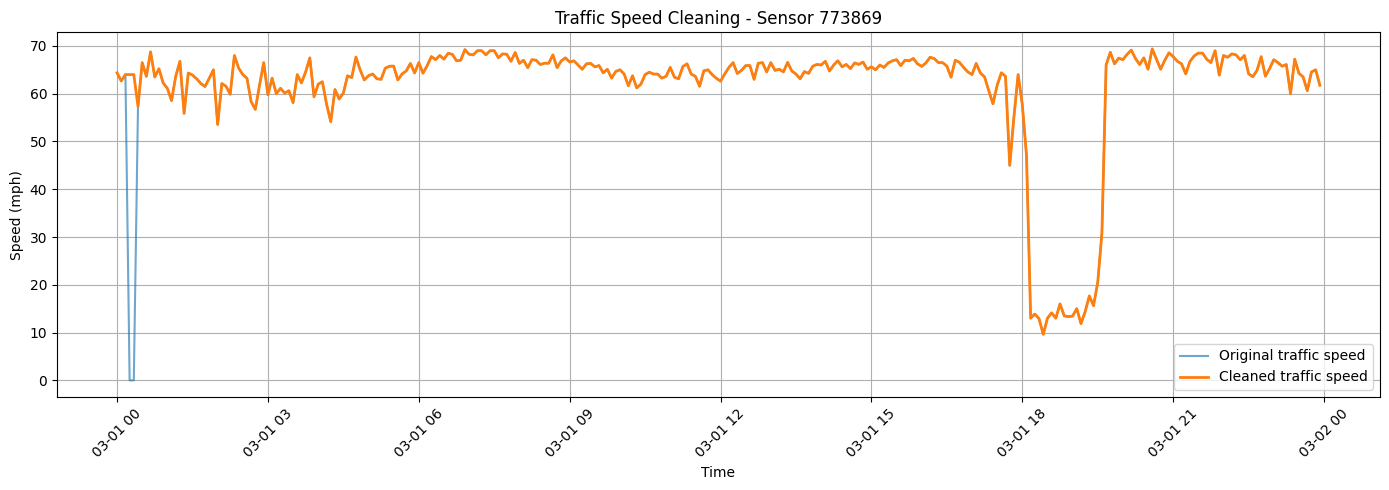

In [ ]:

import matplotlib.pyplot as plt

sensor_id = raw_df.columns[0]

plt.figure(figsize=(14, 5))

plt.plot(
    raw_df.index[:288],
    raw_df[sensor_id].iloc[:288],
    label="Original traffic speed",
    alpha=0.65
)

plt.plot(
    clean_df.index[:288],
    clean_df[sensor_id].iloc[:288],
    label="Cleaned traffic speed",
    linewidth=2
)

plt.title(f"Traffic Speed Cleaning - Sensor {sensor_id}")
plt.xlabel("Time")
plt.ylabel("Speed (mph)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [ ]:

import numpy as np
import pandas as pd

# Select first sensor
sensor_id = clean_df.columns[0]

# Use its cleaned traffic speeds
sensor_df = pd.DataFrame({
    "speed": clean_df[sensor_id]
})

# Previous 12 observations
for lag in range(12):
    sensor_df[f"lag_{lag}"] = (
        sensor_df["speed"].shift(lag)
    )

# Rolling statistics: past/current readings only
for window in [3, 6, 12]:
    sensor_df[f"rolling_mean_{window}"] = (
        sensor_df["speed"]
        .rolling(window)
        .mean()
    )

    sensor_df[f"rolling_std_{window}"] = (
        sensor_df["speed"]
        .rolling(window)
        .std()
    )

# Speed trend
sensor_df["trend_3"] = (
    sensor_df["speed"] -
    sensor_df["speed"].shift(3)
)

# Cyclic time features
hour = (
    sensor_df.index.hour +
    sensor_df.index.minute / 60
)

sensor_df["hour_sin"] = np.sin(
    2 * np.pi * hour / 24
)

sensor_df["hour_cos"] = np.cos(
    2 * np.pi * hour / 24
)

day = sensor_df.index.dayofweek

sensor_df["day_sin"] = np.sin(
    2 * np.pi * day / 7
)

sensor_df["day_cos"] = np.cos(
    2 * np.pi * day / 7
)

sensor_df["weekend"] = (day >= 5).astype(int)

# Prediction targets:
# 3 steps = 15 min
# 6 steps = 30 min
# 12 steps = 60 min
for horizon in [3, 6, 12]:
    sensor_df[f"target_{horizon}"] = (
        sensor_df["speed"].shift(-horizon)
    )

# Preserve whether future target was genuinely observed
for horizon in [3, 6, 12]:
    sensor_df[f"valid_target_{horizon}"] = (
        valid_mask[sensor_id]
        .shift(-horizon)
        .fillna(False)
        .astype(bool)
    )

# Remove edge rows without a full history/targets
sensor_df = sensor_df.dropna().copy()

print("Selected Sensor:", sensor_id)
print("Feature Dataset Shape:", sensor_df.shape)

display(sensor_df.head())


Selected Sensor: 773869
Feature Dataset Shape: (34249, 31)


/tmp/ipykernel_1076/3054406601.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1076/3054406601.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1076/3054406601.py:78: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,speed,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,...,hour_cos,day_sin,day_cos,weekend,target_3,target_6,target_12,valid_target_3,valid_target_6,valid_target_12
2012-03-01 00:55:00,62.250000,62.250000,65.222221,63.500000,68.750000,63.625000,66.500000,57.333332,64.000000,64.000000,...,0.971342,0.433884,-0.900969,0,63.625000,64.333336,65.000000,True,True,True
2012-03-01 01:00:00,61.125000,61.125000,62.250000,65.222221,63.500000,68.750000,63.625000,66.500000,57.333332,64.000000,...,0.965926,0.433884,-0.900969,0,66.777779,63.888889,53.555557,True,True,True
2012-03-01 01:05:00,58.555557,58.555557,61.125000,62.250000,65.222221,63.500000,68.750000,63.625000,66.500000,57.333332,...,0.960050,0.433884,-0.900969,0,55.875000,63.125000,62.125000,True,True,True
2012-03-01 01:10:00,63.625000,63.625000,58.555557,61.125000,62.250000,65.222221,63.500000,68.750000,63.625000,66.500000,...,0.953717,0.433884,-0.900969,0,64.333336,62.125000,61.555557,True,True,True
2012-03-01 01:15:00,66.777779,66.777779,63.625000,58.555557,61.125000,62.250000,65.222221,63.500000,68.750000,63.625000,...,0.946930,0.433884,-0.900969,0,63.888889,61.500000,59.875000,True,True,True


In [ ]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict 15 minutes into the future
horizon = 3

target_col = f"target_{horizon}"
valid_col = f"valid_target_{horizon}"

# Exclude targets, masks, and duplicate current speed column
feature_cols = [
    col for col in sensor_df.columns
    if col not in (
        "speed",
        "target_3", "target_6", "target_12",
        "valid_target_3",
        "valid_target_6",
        "valid_target_12"
    )
]

# Original chronological boundaries
train_boundary = raw_df.index[train_end]
val_boundary = raw_df.index[val_end]

# Future timestamp for each sample
target_times = sensor_df.index + pd.Timedelta(
    minutes=5 * horizon
)

# Keep originally valid targets only
valid_targets = sensor_df[valid_col].astype(bool)

train_mask = (
    (target_times < train_boundary)
    & valid_targets
)

val_mask = (
    (target_times >= train_boundary)
    & (target_times < val_boundary)
    & valid_targets
)

test_mask = (
    (target_times >= val_boundary)
    & valid_targets
)

X_train = sensor_df.loc[train_mask, feature_cols]
y_train = sensor_df.loc[train_mask, target_col]

X_val = sensor_df.loc[val_mask, feature_cols]
y_val = sensor_df.loc[val_mask, target_col]

X_test = sensor_df.loc[test_mask, feature_cols]
y_test = sensor_df.loc[test_mask, target_col]

print("Number of features:", len(feature_cols))
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nAny missing feature values:")
print(X_train.isna().sum().sum())


Number of features: 24
Training samples: 22098
Validation samples: 2131
Testing samples: 6179

Any missing feature values:
0


In [ ]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import time

# Build XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

training_time = time.time() - start_time

print("XGBoost training completed!")
print(f"Training time: {training_time:.2f} seconds")

# Predict using validation data
val_predictions = xgb_model.predict(X_val)

# Evaluate
val_mae = mean_absolute_error(y_val, val_predictions)
val_rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

print("\nVALIDATION RESULTS")
print("------------------------")
print(f"MAE: {val_mae:.4f} mph")
print(f"RMSE: {val_rmse:.4f} mph")


XGBoost training completed!
Training time: 1.65 seconds

VALIDATION RESULTS
------------------------
MAE: 2.5943 mph
RMSE: 5.6092 mph


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# XGBoost validation predictions from previous cell
xgb_predictions = xgb_model.predict(X_val)

# Persistence baseline:
# Future speed = current observed/input speed
baseline_predictions = sensor_df.loc[
    X_val.index, "lag_0"
].to_numpy()

def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Exclude zero actual values from percentage errors
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    nonzero = np.abs(y_true) > 1e-6
    mape = np.mean(
        np.abs(
            (y_true[nonzero] - y_pred[nonzero])
            / y_true[nonzero]
        )
    ) * 100

    return mae, rmse, mape

baseline_mae, baseline_rmse, baseline_mape = evaluate(
    y_val.to_numpy(),
    baseline_predictions
)

xgb_mae, xgb_rmse, xgb_mape = evaluate(
    y_val.to_numpy(),
    xgb_predictions
)

results = pd.DataFrame({
    "Model": ["Persistence Baseline", "XGBoost"],
    "MAE (mph)": [baseline_mae, xgb_mae],
    "RMSE (mph)": [baseline_rmse, xgb_rmse],
    "MAPE (%)": [baseline_mape, xgb_mape]
})

display(results.round(4))

improvement = (
    (baseline_mae - xgb_mae) / baseline_mae
) * 100

print(f"XGBoost MAE improvement over baseline: {improvement:.2f}%")


,Model,MAE (mph),RMSE (mph),MAPE (%)
0,Persistence Baseline,2.8372,6.3342,7.0890
1,XGBoost,2.5943,5.6092,7.4913


XGBoost MAE improvement over baseline: 8.56%


In [ ]:

import numpy as np
import torch

# Keep the same 15-minute prediction horizon
horizon = 3

# Chronological order: oldest reading first
lag_columns = [
    f"lag_{i}" for i in range(11, -1, -1)
]

# Use exactly the same samples as XGBoost
X_lstm_train = sensor_df.loc[
    X_train.index, lag_columns
].to_numpy(dtype=np.float32)

X_lstm_val = sensor_df.loc[
    X_val.index, lag_columns
].to_numpy(dtype=np.float32)

X_lstm_test = sensor_df.loc[
    X_test.index, lag_columns
].to_numpy(dtype=np.float32)

# Normalize using training statistics only
train_mean = X_lstm_train.mean()
train_std = X_lstm_train.std() + 1e-6

X_lstm_train = (X_lstm_train - train_mean) / train_std
X_lstm_val = (X_lstm_val - train_mean) / train_std
X_lstm_test = (X_lstm_test - train_mean) / train_std

# LSTM shape: (samples, 12 time steps, 1 feature)
X_lstm_train = X_lstm_train.reshape(-1, 12, 1)
X_lstm_val = X_lstm_val.reshape(-1, 12, 1)
X_lstm_test = X_lstm_test.reshape(-1, 12, 1)

# Normalize targets for stable neural network training
y_mean = y_train.mean()
y_std = y_train.std() + 1e-6

y_lstm_train = (
    (y_train.to_numpy(dtype=np.float32) - y_mean) / y_std
)

y_lstm_val = (
    (y_val.to_numpy(dtype=np.float32) - y_mean) / y_std
)

y_lstm_test = (
    (y_test.to_numpy(dtype=np.float32) - y_mean) / y_std
)

print("LSTM Training Shape:", X_lstm_train.shape)
print("LSTM Validation Shape:", X_lstm_val.shape)
print("LSTM Testing Shape:", X_lstm_test.shape)

print("Training Target Shape:", y_lstm_train.shape)

print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")


LSTM Training Shape: (22098, 12, 1)
LSTM Validation Shape: (2131, 12, 1)
LSTM Testing Shape: (6179, 12, 1)
Training Target Shape: (22098,)
Device: CPU


In [ ]:

import torch
import torch.nn as nn

# Define LSTM model
class TrafficLSTM(nn.Module):

    def __init__(self, input_size=1, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_out, (hidden, cell) = self.lstm(x)

        # Last time step representation
        last_hidden = lstm_out[:, -1, :]

        # Predict normalized future speed
        prediction = self.fc(last_hidden)

        return prediction.squeeze(-1)


# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create model
lstm_model = TrafficLSTM().to(device)

print(lstm_model)

# Count trainable parameters
total_params = sum(
    p.numel()
    for p in lstm_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)
print("Device:", device)


TrafficLSTM(
  (lstm): LSTM(1, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Trainable parameters: 17217
Device: cpu


In [ ]:

from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import copy
import time

torch.manual_seed(42)

# Convert arrays to tensors
train_dataset = TensorDataset(
    torch.tensor(X_lstm_train, dtype=torch.float32),
    torch.tensor(y_lstm_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_lstm_val, dtype=torch.float32),
    torch.tensor(y_lstm_val, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

epochs = 20
patience = 5

best_val_loss = float("inf")
best_state = None
wait = 0

train_losses = []
val_losses = []

start_time = time.time()

for epoch in range(epochs):

    # Training
    lstm_model.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = lstm_model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += (
            loss.item() * len(X_batch)
        )

    avg_train_loss = total_train_loss / len(train_dataset)

    # Validation
    lstm_model.eval()
    total_val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = lstm_model(X_batch)

            loss = criterion(predictions, y_batch)

            total_val_loss += (
                loss.item() * len(X_batch)
            )

    avg_val_loss = total_val_loss / len(val_dataset)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )

    # Early stopping
    if avg_val_loss < best_val_loss - 1e-5:

        best_val_loss = avg_val_loss
        best_state = copy.deepcopy(
            lstm_model.state_dict()
        )
        wait = 0

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore best model
lstm_model.load_state_dict(best_state)

print(
    "\nTraining completed in",
    round(time.time() - start_time, 2),
    "seconds"
)


Epoch 01/20 | Train Loss: 0.5609 | Val Loss: 0.3729
Epoch 02/20 | Train Loss: 0.3168 | Val Loss: 0.3137
Epoch 03/20 | Train Loss: 0.2965 | Val Loss: 0.2913
Epoch 04/20 | Train Loss: 0.2866 | Val Loss: 0.2973
Epoch 05/20 | Train Loss: 0.2849 | Val Loss: 0.3085
Epoch 06/20 | Train Loss: 0.2817 | Val Loss: 0.3027
Epoch 07/20 | Train Loss: 0.2788 | Val Loss: 0.2761
Epoch 08/20 | Train Loss: 0.2777 | Val Loss: 0.2721
Epoch 09/20 | Train Loss: 0.2793 | Val Loss: 0.2802
Epoch 10/20 | Train Loss: 0.2755 | Val Loss: 0.2673
Epoch 11/20 | Train Loss: 0.2755 | Val Loss: 0.2687
Epoch 12/20 | Train Loss: 0.2756 | Val Loss: 0.2782
Epoch 13/20 | Train Loss: 0.2738 | Val Loss: 0.2697
Epoch 14/20 | Train Loss: 0.2751 | Val Loss: 0.2640
Epoch 15/20 | Train Loss: 0.2735 | Val Loss: 0.2662
Epoch 16/20 | Train Loss: 0.2732 | Val Loss: 0.2628
Epoch 17/20 | Train Loss: 0.2733 | Val Loss: 0.2718
Epoch 18/20 | Train Loss: 0.2717 | Val Loss: 0.2676
Epoch 19/20 | Train Loss: 0.2707 | Val Loss: 0.2577
Epoch 20/20 

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

lstm_model.eval()

with torch.no_grad():

    val_tensor = torch.tensor(
        X_lstm_val,
        dtype=torch.float32
    ).to(device)

    normalized_preds = (
        lstm_model(val_tensor)
        .cpu()
        .numpy()
    )

# Convert normalized output back to mph
lstm_predictions = (
    normalized_preds * y_std + y_mean
)

lstm_mae = mean_absolute_error(
    y_val, lstm_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(y_val, lstm_predictions)
)

_, _, lstm_mape = evaluate(
    y_val.to_numpy(),
    lstm_predictions
)

print("LSTM VALIDATION RESULTS")
print("-----------------------")
print(f"MAE: {lstm_mae:.4f} mph")
print(f"RMSE: {lstm_rmse:.4f} mph")
print(f"MAPE: {lstm_mape:.4f}%")

comparison = pd.DataFrame({
    "Model": [
        "Persistence",
        "XGBoost",
        "LSTM"
    ],
    "MAE": [
        baseline_mae,
        xgb_mae,
        lstm_mae
    ],
    "RMSE": [
        baseline_rmse,
        xgb_rmse,
        lstm_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        xgb_mape,
        lstm_mape
    ]
})

display(comparison.round(4))


LSTM VALIDATION RESULTS
-----------------------
MAE: 2.7552 mph
RMSE: 5.9298 mph
MAPE: 8.0280%


,Model,MAE,RMSE,MAPE (%)
0,Persistence,2.8372,6.3342,7.0890
1,XGBoost,2.5943,5.6092,7.4913
2,LSTM,2.7552,5.9298,8.0280


In [ ]:

from sklearn.base import clone
import numpy as np

# Expanding-window folds
n_train = len(X_train)

# Leave approximately 40% for initial training history
initial_train = int(n_train * 0.40)

# Remaining data divided into 3 forward-validation blocks
fold_edges = np.linspace(
    initial_train,
    n_train,
    4,
    dtype=int
)

# Unavailable OOF predictions remain NaN
oof_xgb = np.full(n_train, np.nan, dtype=np.float32)

base_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

for fold in range(3):

    train_stop = fold_edges[fold]
    pred_stop = fold_edges[fold + 1]

    fold_model = clone(base_xgb)

    fold_model.fit(
        X_train.iloc[:train_stop],
        y_train.iloc[:train_stop]
    )

    fold_preds = fold_model.predict(
        X_train.iloc[train_stop:pred_stop]
    )

    oof_xgb[train_stop:pred_stop] = fold_preds

    print(
        f"Fold {fold+1}: "
        f"trained on {train_stop} samples, "
        f"predicted {pred_stop-train_stop} samples"
    )

oof_mask = np.isfinite(oof_xgb)

print("\nOOF predictions created:", oof_mask.sum())
print("Total training samples:", n_train)


Fold 1: trained on 8839 samples, predicted 4419 samples
Fold 2: trained on 13258 samples, predicted 4420 samples
Fold 3: trained on 17678 samples, predicted 4420 samples

OOF predictions created: 13259
Total training samples: 22098


In [ ]:

from sklearn.base import clone
import numpy as np

# 15-minute forecast = 3 five-minute steps
horizon = 3

# Account for overlapping history and future targets
gap = 12 + horizon

n_train = len(X_train)
initial_train = int(n_train * 0.40)

fold_edges = np.linspace(
    initial_train, n_train, 4, dtype=int
)

oof_xgb = np.full(
    n_train, np.nan, dtype=np.float32
)

for fold in range(3):
    pred_start = fold_edges[fold]
    pred_end = fold_edges[fold + 1]
    train_stop = pred_start - gap

    fold_model = clone(base_xgb)

    fold_model.fit(
        X_train.iloc[:train_stop],
        y_train.iloc[:train_stop]
    )

    oof_xgb[pred_start:pred_end] = (
        fold_model.predict(
            X_train.iloc[pred_start:pred_end]
        )
    )

    print(
        f"Fold {fold+1}: "
        f"trained on {train_stop} samples, "
        f"predicted {pred_end-pred_start}"
    )

oof_mask = np.isfinite(oof_xgb)

print("Valid OOF predictions:", oof_mask.sum())


Fold 1: trained on 8824 samples, predicted 4419
Fold 2: trained on 13243 samples, predicted 4420
Fold 3: trained on 17663 samples, predicted 4420
Valid OOF predictions: 13259


In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

oof_lstm_features = np.full(
    (n_train, 64),
    np.nan,
    dtype=np.float32
)

# Feature extractor based on the trained LSTM architecture
def extract_hidden(model, X, batch_size=512):
    model.eval()
    collected = []

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            batch = torch.tensor(
                X[start:start+batch_size],
                dtype=torch.float32,
                device=device
            )

            lstm_output, _ = model.lstm(batch)

            hidden = lstm_output[:, -1, :]

            collected.append(
                hidden.cpu().numpy()
            )

    return np.concatenate(collected, axis=0)


for fold in range(3):
    pred_start = fold_edges[fold]
    pred_end = fold_edges[fold + 1]
    train_stop = pred_start - gap

    # Separate fold model
    fold_lstm = TrafficLSTM().to(device)

    optimizer = torch.optim.Adam(
        fold_lstm.parameters(),
        lr=0.001
    )

    criterion = nn.MSELoss()

    fold_dataset = TensorDataset(
        torch.tensor(
            X_lstm_train[:train_stop],
            dtype=torch.float32
        ),
        torch.tensor(
            y_lstm_train[:train_stop],
            dtype=torch.float32
        )
    )

    fold_loader = DataLoader(
        fold_dataset,
        batch_size=256,
        shuffle=True
    )

    # Initial fixed-length training
    for epoch in range(15):
        fold_lstm.train()

        for xb, yb in fold_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = fold_lstm(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

    # Extract OOF hidden representations
    features = extract_hidden(
        fold_lstm,
        X_lstm_train[pred_start:pred_end]
    )

    oof_lstm_features[
        pred_start:pred_end
    ] = features

    print(
        f"Fold {fold+1} completed: "
        f"{len(features)} hidden vectors generated"
    )

print(
    "\nOOF LSTM feature matrix:",
    oof_lstm_features[oof_mask].shape
)


Fold 1 completed: 4419 hidden vectors generated
Fold 2 completed: 4420 hidden vectors generated
Fold 3 completed: 4420 hidden vectors generated

OOF LSTM feature matrix: (13259, 64)


In [ ]:

import numpy as np
import torch

# Align XGBoost and LSTM OOF predictions
fusion_mask = (
    np.isfinite(oof_xgb)
    & np.isfinite(oof_lstm_features).all(axis=1)
)

# Normalize XGBoost output using the training target scale
xgb_oof_scaled = (
    (oof_xgb[fusion_mask] - y_mean) / y_std
).reshape(-1, 1)

# Combine XGBoost + LSTM
X_fusion_train = np.concatenate(
    [
        oof_lstm_features[fusion_mask],
        xgb_oof_scaled
    ],
    axis=1
).astype(np.float32)

# The targets are the corresponding normalized speeds
y_fusion_train = (
    y_lstm_train[fusion_mask]
).astype(np.float32)

print("Fusion training input:", X_fusion_train.shape)
print("Fusion training targets:", y_fusion_train.shape)

assert X_fusion_train.shape[1] == 65
assert np.isfinite(X_fusion_train).all()


Fusion training input: (13259, 65)
Fusion training targets: (13259,)


In [ ]:

import torch.nn as nn

class HybridFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


fusion_model = HybridFusion().to(device)

print(fusion_model)

print(
    "Trainable parameters:",
    sum(p.numel() for p in fusion_model.parameters())
)


HybridFusion(
  (network): Sequential(
    (0): Linear(in_features=65, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 2145


In [ ]:

# XGBoost validation predictions
xgb_val_scaled = (
    (xgb_model.predict(X_val) - y_mean) / y_std
).reshape(-1, 1)

# LSTM validation hidden representations
lstm_val_hidden = extract_hidden(
    lstm_model,
    X_lstm_val
)

X_fusion_val = np.concatenate(
    [lstm_val_hidden, xgb_val_scaled],
    axis=1
).astype(np.float32)

y_fusion_val = y_lstm_val.astype(np.float32)

print("Fusion validation input:", X_fusion_val.shape)
print("Fusion validation targets:", y_fusion_val.shape)


Fusion validation input: (2131, 65)
Fusion validation targets: (2131,)


In [ ]:

from torch.utils.data import TensorDataset, DataLoader
import copy

torch.manual_seed(42)

fusion_train_dataset = TensorDataset(
    torch.tensor(X_fusion_train),
    torch.tensor(y_fusion_train)
)

fusion_loader = DataLoader(
    fusion_train_dataset,
    batch_size=256,
    shuffle=True
)

X_val_tensor = torch.tensor(
    X_fusion_val,
    dtype=torch.float32,
    device=device
)

y_val_tensor = torch.tensor(
    y_fusion_val,
    dtype=torch.float32,
    device=device
)

optimizer = torch.optim.Adam(
    fusion_model.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

best_val_loss = float("inf")
best_fusion_state = None
patience = 8
wait = 0

for epoch in range(50):

    fusion_model.train()
    train_loss = 0

    for xb, yb in fusion_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = fusion_model(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(xb)

    train_loss /= len(fusion_train_dataset)

    fusion_model.eval()

    with torch.no_grad():
        val_predictions = fusion_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss - 1e-5:
        best_val_loss = val_loss
        best_fusion_state = copy.deepcopy(
            fusion_model.state_dict()
        )
        wait = 0
    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered")
            break

fusion_model.load_state_dict(best_fusion_state)

print("\nHybrid fusion training completed!")


Epoch 01 | Train Loss: 0.7395 | Val Loss: 1.2566
Epoch 02 | Train Loss: 0.3293 | Val Loss: 0.8870
Epoch 03 | Train Loss: 0.2302 | Val Loss: 0.7860
Epoch 04 | Train Loss: 0.2212 | Val Loss: 0.7298
Epoch 05 | Train Loss: 0.2149 | Val Loss: 0.6973
Epoch 06 | Train Loss: 0.2119 | Val Loss: 0.6617
Epoch 07 | Train Loss: 0.2091 | Val Loss: 0.6300
Epoch 08 | Train Loss: 0.2071 | Val Loss: 0.6349
Epoch 09 | Train Loss: 0.2062 | Val Loss: 0.5995
Epoch 10 | Train Loss: 0.2062 | Val Loss: 0.6012
Epoch 11 | Train Loss: 0.2046 | Val Loss: 0.5737
Epoch 12 | Train Loss: 0.2047 | Val Loss: 0.5659
Epoch 13 | Train Loss: 0.2044 | Val Loss: 0.5723
Epoch 14 | Train Loss: 0.2044 | Val Loss: 0.5680
Epoch 15 | Train Loss: 0.2040 | Val Loss: 0.5561
Epoch 16 | Train Loss: 0.2040 | Val Loss: 0.5504
Epoch 17 | Train Loss: 0.2040 | Val Loss: 0.5529
Epoch 18 | Train Loss: 0.2031 | Val Loss: 0.5748
Epoch 19 | Train Loss: 0.2035 | Val Loss: 0.5430
Epoch 20 | Train Loss: 0.2040 | Val Loss: 0.5559
Epoch 21 | Train Los

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd

fusion_model.eval()

with torch.no_grad():
    predictions_scaled = (
        fusion_model(X_val_tensor)
        .cpu()
        .numpy()
    )

# Convert predictions into mph
hybrid_predictions = (
    predictions_scaled * y_std + y_mean
)

hybrid_mae, hybrid_rmse, hybrid_mape = evaluate(
    y_val.to_numpy(),
    hybrid_predictions
)

print("HYBRID VALIDATION RESULTS")
print("--------------------------")
print(f"MAE: {hybrid_mae:.4f} mph")
print(f"RMSE: {hybrid_rmse:.4f} mph")
print(f"MAPE: {hybrid_mape:.4f}%")

comparison = pd.DataFrame({
    "Model": [
        "Persistence",
        "XGBoost",
        "LSTM",
        "Hybrid XGBoost + LSTM"
    ],
    "MAE": [
        baseline_mae,
        xgb_mae,
        lstm_mae,
        hybrid_mae
    ],
    "RMSE": [
        baseline_rmse,
        xgb_rmse,
        lstm_rmse,
        hybrid_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        xgb_mape,
        lstm_mape,
        hybrid_mape
    ]
})

display(comparison.round(4))

improvement = (
    (xgb_mae - hybrid_mae) / xgb_mae
) * 100

print(
    f"Hybrid MAE change vs XGBoost: {improvement:.2f}%"
)


HYBRID VALIDATION RESULTS
--------------------------
MAE: 4.1788 mph
RMSE: 8.4703 mph
MAPE: 17.3711%


,Model,MAE,RMSE,MAPE (%)
0,Persistence,2.8372,6.3342,7.089000
1,XGBoost,2.5943,5.6092,7.491300
2,LSTM,2.7552,5.9298,8.028000
3,Hybrid XGBoost + LSTM,4.1788,8.4703,17.371099


Hybrid MAE change vs XGBoost: -61.08%


In [ ]:

import numpy as np
import torch

# Extract hidden states using ONE trained LSTM
# Diagnostic only: training features are in-sample
lstm_train_hidden = extract_hidden(
    lstm_model,
    X_lstm_train
)

lstm_val_hidden = extract_hidden(
    lstm_model,
    X_lstm_val
)

# XGBoost OOF values
xgb_train_scaled = (
    (oof_xgb[oof_mask] - y_mean) / y_std
).reshape(-1, 1)

xgb_val_scaled = (
    (xgb_model.predict(X_val) - y_mean) / y_std
).reshape(-1, 1)

# Diagnostic training inputs
X_diag_train = np.concatenate(
    [
        lstm_train_hidden[oof_mask],
        xgb_train_scaled
    ],
    axis=1
).astype(np.float32)

y_diag_train = y_lstm_train[oof_mask].astype(np.float32)

# Validation inputs
X_diag_val = np.concatenate(
    [
        lstm_val_hidden,
        xgb_val_scaled
    ],
    axis=1
).astype(np.float32)

print("Diagnostic training:", X_diag_train.shape)
print("Diagnostic validation:", X_diag_val.shape)

print(
    "Train feature mean:",
    np.mean(X_diag_train, axis=0)[:5]
)

print(
    "Validation feature mean:",
    np.mean(X_diag_val, axis=0)[:5]
)


Diagnostic training: (13259, 65)
Diagnostic validation: (2131, 65)
Train feature mean: [-0.03699543 -0.11723665 -0.00644914 -0.29901448  0.04505562]
Validation feature mean: [-0.03068338 -0.1132819  -0.02056079 -0.26452276  0.05395286]


In [ ]:

import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import copy

torch.manual_seed(42)

diag_model = HybridFusion().to(device)

diag_dataset = TensorDataset(
    torch.tensor(X_diag_train),
    torch.tensor(y_diag_train)
)

diag_loader = DataLoader(
    diag_dataset,
    batch_size=256,
    shuffle=True
)

optimizer = torch.optim.Adam(
    diag_model.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

X_diag_val_tensor = torch.tensor(
    X_diag_val,
    dtype=torch.float32,
    device=device
)

y_diag_val_tensor = torch.tensor(
    y_fusion_val,
    dtype=torch.float32,
    device=device
)

best_loss = float("inf")
best_state = None
wait = 0

for epoch in range(40):

    diag_model.train()

    for xb, yb in diag_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        pred = diag_model(xb)
        loss = criterion(pred, yb)

        loss.backward()
        optimizer.step()

    diag_model.eval()

    with torch.no_grad():
        val_loss = criterion(
            diag_model(X_diag_val_tensor),
            y_diag_val_tensor
        ).item()

    if val_loss < best_loss - 1e-5:
        best_loss = val_loss
        best_state = copy.deepcopy(
            diag_model.state_dict()
        )
        wait = 0
    else:
        wait += 1
        if wait >= 7:
            break

diag_model.load_state_dict(best_state)

with torch.no_grad():
    diag_preds_scaled = (
        diag_model(X_diag_val_tensor)
        .cpu()
        .numpy()
    )

diag_preds = diag_preds_scaled * y_std + y_mean

diag_mae, diag_rmse, diag_mape = evaluate(
    y_val.to_numpy(),
    diag_preds
)

print("DIAGNOSTIC HYBRID RESULTS")
print("--------------------------")
print(f"MAE: {diag_mae:.4f} mph")
print(f"RMSE: {diag_rmse:.4f} mph")
print(f"MAPE: {diag_mape:.4f}%")

print("\nStandalone XGBoost MAE:", round(xgb_mae, 4))
print("Previous hybrid MAE:", round(hybrid_mae, 4))


DIAGNOSTIC HYBRID RESULTS
--------------------------
MAE: 2.5823 mph
RMSE: 5.3795 mph
MAPE: 7.0493%

Standalone XGBoost MAE: 2.5943
Previous hybrid MAE: 4.1788


In [ ]:

import numpy as np

n = len(X_train)

base_end = int(n * 0.70)

# Gap accounts conservatively for the historical window
# and 15-minute prediction horizon
gap = 15

fusion_start = base_end + gap

# Base-model training data
X_base = X_train.iloc[:base_end]
y_base = y_train.iloc[:base_end]

X_lstm_base = X_lstm_train[:base_end]
y_lstm_base = y_lstm_train[:base_end]

# Fusion-model training data
X_fusion_part = X_train.iloc[fusion_start:]
y_fusion_part = y_train.iloc[fusion_start:]

X_lstm_fusion_part = X_lstm_train[fusion_start:]
y_lstm_fusion_part = y_lstm_train[fusion_start:]

print("Base-model training samples:", len(X_base))
print("Fusion training samples:", len(X_fusion_part))
print("Unused gap samples:", gap)

print("LSTM base input:", X_lstm_base.shape)
print("LSTM fusion input:", X_lstm_fusion_part.shape)


Base-model training samples: 15468
Fusion training samples: 6615
Unused gap samples: 15
LSTM base input: (15468, 12, 1)
LSTM fusion input: (6615, 12, 1)


In [ ]:

from xgboost import XGBRegressor
import numpy as np
import time

# Fresh XGBoost model for the corrected hybrid
hybrid_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=-1
)

start = time.time()

hybrid_xgb.fit(X_base, y_base)

print("Base XGBoost trained successfully!")
print("Training time:", round(time.time() - start, 2), "seconds")

# Predict the later fusion-training period
fusion_xgb_preds = hybrid_xgb.predict(X_fusion_part)

# Predict the independent validation period
val_xgb_preds = hybrid_xgb.predict(X_val)

print("Fusion predictions:", fusion_xgb_preds.shape)
print("Validation predictions:", val_xgb_preds.shape)


Base XGBoost trained successfully!
Training time: 0.68 seconds
Fusion predictions: (6615,)
Validation predictions: (2131,)


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# -----------------------------------
# 1. Use raw 12-step sequences
# -----------------------------------

lag_columns = [
    f"lag_{i}" for i in range(11, -1, -1)
]

# Base training sequences
base_raw = sensor_df.loc[
    X_base.index, lag_columns
].to_numpy(dtype=np.float32)

# Fusion training sequences
fusion_raw = sensor_df.loc[
    X_fusion_part.index, lag_columns
].to_numpy(dtype=np.float32)

# Validation sequences
val_raw_seq = sensor_df.loc[
    X_val.index, lag_columns
].to_numpy(dtype=np.float32)

# -----------------------------------
# 2. Normalize using BASE data only
# -----------------------------------

base_input_mean = base_raw.mean()
base_input_std = base_raw.std() + 1e-6

base_y_mean = float(y_base.mean())
base_y_std = float(y_base.std()) + 1e-6

def prepare_sequences(values):
    normalized = (
        values - base_input_mean
    ) / base_input_std

    return normalized.reshape(-1, 12, 1)

X_base_lstm = prepare_sequences(base_raw)
X_fusion_lstm = prepare_sequences(fusion_raw)
X_val_hybrid_lstm = prepare_sequences(val_raw_seq)

y_base_normalized = (
    y_base.to_numpy(dtype=np.float32)
    - base_y_mean
) / base_y_std

# -----------------------------------
# 3. Internal validation split
# -----------------------------------

internal_end = int(
    len(X_base_lstm) * 0.85
)

# Protect the temporal boundary
internal_gap = 15

train_stop = internal_end - internal_gap

internal_train_dataset = TensorDataset(
    torch.tensor(
        X_base_lstm[:train_stop],
        dtype=torch.float32
    ),
    torch.tensor(
        y_base_normalized[:train_stop],
        dtype=torch.float32
    )
)

internal_val_dataset = TensorDataset(
    torch.tensor(
        X_base_lstm[internal_end:],
        dtype=torch.float32
    ),
    torch.tensor(
        y_base_normalized[internal_end:],
        dtype=torch.float32
    )
)

train_loader = DataLoader(
    internal_train_dataset,
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    internal_val_dataset,
    batch_size=256,
    shuffle=False
)

# -----------------------------------
# 4. Create fresh LSTM
# -----------------------------------

hybrid_lstm = TrafficLSTM(
    input_size=1,
    hidden_size=64
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    hybrid_lstm.parameters(),
    lr=0.001
)

# -----------------------------------
# 5. Train with early stopping
# -----------------------------------

best_loss = float("inf")
best_state = None

patience = 6
wait = 0

start = time.time()

for epoch in range(35):

    hybrid_lstm.train()
    train_loss_sum = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = hybrid_lstm(xb)

        loss = criterion(
            predictions,
            yb
        )

        loss.backward()
        optimizer.step()

        train_loss_sum += (
            loss.item() * len(xb)
        )

    train_loss = (
        train_loss_sum
        / len(internal_train_dataset)
    )

    hybrid_lstm.eval()
    val_loss_sum = 0

    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            predictions = hybrid_lstm(xb)

            loss = criterion(
                predictions,
                yb
            )

            val_loss_sum += (
                loss.item() * len(xb)
            )

    val_loss = (
        val_loss_sum
        / len(internal_val_dataset)
    )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {train_loss:.4f} | "
        f"Internal Val: {val_loss:.4f}"
    )

    if val_loss < best_loss - 1e-5:

        best_loss = val_loss

        best_state = copy.deepcopy(
            hybrid_lstm.state_dict()
        )

        wait = 0

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

hybrid_lstm.load_state_dict(best_state)

# -----------------------------------
# 6. Freeze the trained LSTM
# -----------------------------------

hybrid_lstm.eval()

for param in hybrid_lstm.parameters():
    param.requires_grad = False

print("\nFresh hybrid LSTM trained successfully!")

print(
    "Training time:",
    round(time.time() - start, 2),
    "seconds"
)

print(
    "Fusion LSTM input:",
    X_fusion_lstm.shape
)

print(
    "Validation LSTM input:",
    X_val_hybrid_lstm.shape
)


Epoch 01 | Train: 0.6591 | Internal Val: 0.2184
Epoch 02 | Train: 0.3928 | Internal Val: 0.1982
Epoch 03 | Train: 0.3602 | Internal Val: 0.1979
Epoch 04 | Train: 0.3441 | Internal Val: 0.1856
Epoch 05 | Train: 0.3313 | Internal Val: 0.1846
Epoch 06 | Train: 0.3249 | Internal Val: 0.1830
Epoch 07 | Train: 0.3216 | Internal Val: 0.1872
Epoch 08 | Train: 0.3192 | Internal Val: 0.1837
Epoch 09 | Train: 0.3193 | Internal Val: 0.1793
Epoch 10 | Train: 0.3144 | Internal Val: 0.1812
Epoch 11 | Train: 0.3135 | Internal Val: 0.1808
Epoch 12 | Train: 0.3138 | Internal Val: 0.1866
Epoch 13 | Train: 0.3107 | Internal Val: 0.1771
Epoch 14 | Train: 0.3123 | Internal Val: 0.1796
Epoch 15 | Train: 0.3109 | Internal Val: 0.1843
Epoch 16 | Train: 0.3114 | Internal Val: 0.1786
Epoch 17 | Train: 0.3111 | Internal Val: 0.1795
Epoch 18 | Train: 0.3103 | Internal Val: 0.1772
Epoch 19 | Train: 0.3095 | Internal Val: 0.1807
Early stopping triggered.

Fresh hybrid LSTM trained successfully!
Training time: 13.06 

In [ ]:

import numpy as np
import torch

# Previously defined extract_hidden() works with TrafficLSTM

# Generate 64-dimensional hidden representations
fusion_hidden = extract_hidden(
    hybrid_lstm,
    X_fusion_lstm
)

validation_hidden = extract_hidden(
    hybrid_lstm,
    X_val_hybrid_lstm
)

# Normalize XGBoost predictions using base target statistics
fusion_xgb_scaled = (
    (fusion_xgb_preds - base_y_mean) / base_y_std
).reshape(-1, 1)

validation_xgb_scaled = (
    (val_xgb_preds - base_y_mean) / base_y_std
).reshape(-1, 1)

# Combine both branches
X_hybrid_train = np.concatenate(
    [fusion_hidden, fusion_xgb_scaled],
    axis=1
).astype(np.float32)

X_hybrid_val = np.concatenate(
    [validation_hidden, validation_xgb_scaled],
    axis=1
).astype(np.float32)

# Normalize target values with base training statistics
y_hybrid_train = (
    (
        y_fusion_part.to_numpy(dtype=np.float32)
        - base_y_mean
    ) / base_y_std
)

y_hybrid_val = (
    (
        y_val.to_numpy(dtype=np.float32)
        - base_y_mean
    ) / base_y_std
)

print("Hybrid training input:", X_hybrid_train.shape)
print("Hybrid validation input:", X_hybrid_val.shape)
print("Training targets:", y_hybrid_train.shape)
print("Validation targets:", y_hybrid_val.shape)

assert X_hybrid_train.shape[1] == 65
assert np.isfinite(X_hybrid_train).all()
assert np.isfinite(X_hybrid_val).all()



Hybrid training input: (6615, 65)
Hybrid validation input: (2131, 65)
Training targets: (6615,)
Validation targets: (2131,)


In [ ]:


import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import copy

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

# Fresh fusion model
corrected_fusion = HybridFusion().to(device)

fusion_dataset = TensorDataset(
    torch.tensor(X_hybrid_train, dtype=torch.float32),
    torch.tensor(y_hybrid_train, dtype=torch.float32)
)

fusion_loader = DataLoader(
    fusion_dataset,
    batch_size=256,
    shuffle=True
)

val_inputs = torch.tensor(
    X_hybrid_val,
    dtype=torch.float32,
    device=device
)

val_targets = torch.tensor(
    y_hybrid_val,
    dtype=torch.float32,
    device=device
)

optimizer = torch.optim.Adam(
    corrected_fusion.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

best_loss = float("inf")
best_state = None
wait = 0

for epoch in range(50):

    corrected_fusion.train()
    total_loss = 0

    for xb, yb in fusion_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        pred = corrected_fusion(xb)
        loss = criterion(pred, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    train_loss = total_loss / len(fusion_dataset)

    corrected_fusion.eval()

    with torch.no_grad():
        val_loss = criterion(
            corrected_fusion(val_inputs),
            val_targets
        ).item()

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f}"
    )

    if val_loss < best_loss - 1e-5:
        best_loss = val_loss
        best_state = copy.deepcopy(
            corrected_fusion.state_dict()
        )
        wait = 0
    else:
        wait += 1

        if wait >= 7:
            print("Early stopping triggered.")
            break

corrected_fusion.load_state_dict(best_state)

# Evaluate
corrected_fusion.eval()

with torch.no_grad():
    scaled_predictions = (
        corrected_fusion(val_inputs)
        .cpu()
        .numpy()
    )

corrected_predictions = (
    scaled_predictions * base_y_std + base_y_mean
)

corrected_mae, corrected_rmse, corrected_mape = evaluate(
    y_val.to_numpy(),
    corrected_predictions
)

print("\nCORRECTED HYBRID VALIDATION RESULTS")
print("---------------------------------")
print(f"MAE: {corrected_mae:.4f} mph")
print(f"RMSE: {corrected_rmse:.4f} mph")
print(f"MAPE: {corrected_mape:.4f}%")

# Fairer comparison: same base-training XGBoost
base_xgb_mae, base_xgb_rmse, base_xgb_mape = evaluate(
    y_val.to_numpy(),
    val_xgb_preds
)

comparison = pd.DataFrame({
    "Model": [
        "XGBoost (base split)",
        "Corrected Hybrid"
    ],
    "MAE": [base_xgb_mae, corrected_mae],
    "RMSE": [base_xgb_rmse, corrected_rmse],
    "MAPE (%)": [base_xgb_mape, corrected_mape]
})

display(comparison.round(4))

improvement = (
    (base_xgb_mae - corrected_mae) / base_xgb_mae
) * 100

print(f"Hybrid MAE improvement: {improvement:.2f}%")


Epoch 01 | Train: 1.0559 | Val: 1.3065
Epoch 02 | Train: 0.7283 | Val: 0.7841
Epoch 03 | Train: 0.4294 | Val: 0.4051
Epoch 04 | Train: 0.2750 | Val: 0.2662
Epoch 05 | Train: 0.2342 | Val: 0.2416
Epoch 06 | Train: 0.2235 | Val: 0.2343
Epoch 07 | Train: 0.2161 | Val: 0.2334
Epoch 08 | Train: 0.2099 | Val: 0.2267
Epoch 09 | Train: 0.2049 | Val: 0.2257
Epoch 10 | Train: 0.2009 | Val: 0.2223
Epoch 11 | Train: 0.1976 | Val: 0.2242
Epoch 12 | Train: 0.1948 | Val: 0.2211
Epoch 13 | Train: 0.1927 | Val: 0.2212
Epoch 14 | Train: 0.1908 | Val: 0.2206
Epoch 15 | Train: 0.1898 | Val: 0.2223
Epoch 16 | Train: 0.1886 | Val: 0.2214
Epoch 17 | Train: 0.1877 | Val: 0.2216
Epoch 18 | Train: 0.1871 | Val: 0.2215
Epoch 19 | Train: 0.1870 | Val: 0.2220
Epoch 20 | Train: 0.1861 | Val: 0.2223
Epoch 21 | Train: 0.1860 | Val: 0.2233
Early stopping triggered.

CORRECTED HYBRID VALIDATION RESULTS
---------------------------------
MAE: 2.5504 mph
RMSE: 5.3706 mph
MAPE: 6.9536%


,Model,MAE,RMSE,MAPE (%)
0,XGBoost (base split),2.6387,5.6251,7.6576
1,Corrected Hybrid,2.5504,5.3706,6.9536


Hybrid MAE improvement: 3.35%


In [ ]:

import os
import json
import joblib
import torch

os.makedirs("traffic_models", exist_ok=True)

# Save corrected hybrid base XGBoost
joblib.dump(
    hybrid_xgb,
    "traffic_models/xgboost_15min.pkl"
)

# Save corrected hybrid LSTM
torch.save(
    hybrid_lstm.state_dict(),
    "traffic_models/lstm_15min.pth"
)

# Save fusion neural network
torch.save(
    corrected_fusion.state_dict(),
    "traffic_models/fusion_15min.pth"
)

# Save normalization values
normalization = {
    "input_mean": float(base_input_mean),
    "input_std": float(base_input_std),
    "target_mean": float(base_y_mean),
    "target_std": float(base_y_std),
    "sensor_id": str(sensor_id),
    "horizon_steps": 3
}

with open(
    "traffic_models/normalization_15min.json",
    "w"
) as f:
    json.dump(normalization, f, indent=4)

# Save validation results
results = {
    "dataset": "METR-LA",
    "sensor_id": str(sensor_id),
    "forecast_horizon": "15 minutes",
    "evaluation": "validation",
    "xgboost_mae": float(base_xgb_mae),
    "hybrid_mae": float(corrected_mae),
    "hybrid_rmse": float(corrected_rmse),
    "hybrid_mape": float(corrected_mape),
    "mae_improvement_percent": float(improvement)
}

with open(
    "traffic_models/results_15min.json",
    "w"
) as f:
    json.dump(results, f, indent=4)

print("All 15-minute models and results saved!")

print("\nSaved files:")
for filename in os.listdir("traffic_models"):
    print(filename)


All 15-minute models and results saved!

Saved files:
normalization_15min.json
results_15min.json
lstm_15min.pth
fusion_15min.pth
xgboost_15min.pkl


In [ ]:

from google.colab import drive
import os
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Create a persistent project folder
backup_folder = (
    "/content/drive/MyDrive/"
    "Traffic_Forecasting_Project/models"
)

os.makedirs(backup_folder, exist_ok=True)

# Copy saved models and results
for filename in os.listdir("traffic_models"):

    source = os.path.join(
        "traffic_models", filename
    )

    destination = os.path.join(
        backup_folder, filename
    )

    shutil.copy2(source, destination)

    print("Backed up:", filename)

print("\nBackup completed successfully!")
print("Google Drive folder:", backup_folder)


MessageError: Error: credential propagation was unsuccessful

In [ ]:

import os
import shutil
from google.colab import files

# Check that our models still exist
print("Saved files:", os.listdir("traffic_models"))

# Create one ZIP containing all five model files
shutil.make_archive(
    "/content/traffic_models_backup",
    "zip",
    root_dir="/content",
    base_dir="traffic_models"
)

# Download ZIP to your computer
files.download("/content/traffic_models_backup.zip")


Saved files: ['normalization_15min.json', 'results_15min.json', 'lstm_15min.pth', 'fusion_15min.pth', 'xgboost_15min.pkl']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np

# Select 30-minute prediction horizon
horizon = 6

target_col = f"target_{horizon}"
valid_col = f"valid_target_{horizon}"

# Prediction timestamp
target_times = (
    sensor_df.index
    + pd.Timedelta(minutes=5*horizon)
)

# Only evaluate originally valid traffic readings
valid_targets = sensor_df[valid_col].astype(bool)

# Chronological splitting by target timestamp
train_mask = (
    (target_times < train_boundary)
    & valid_targets
)

val_mask = (
    (target_times >= train_boundary)
    & (target_times < val_boundary)
    & valid_targets
)

test_mask = (
    (target_times >= val_boundary)
    & valid_targets
)

# 24 engineered XGBoost features
X_train_30 = sensor_df.loc[
    train_mask, feature_cols
]

y_train_30 = sensor_df.loc[
    train_mask, target_col
]

X_val_30 = sensor_df.loc[
    val_mask, feature_cols
]

y_val_30 = sensor_df.loc[
    val_mask, target_col
]

X_test_30 = sensor_df.loc[
    test_mask, feature_cols
]

y_test_30 = sensor_df.loc[
    test_mask, target_col
]

print("30-MINUTE DATASET READY")
print("------------------------")
print("Training:", X_train_30.shape)
print("Validation:", X_val_30.shape)
print("Testing:", X_test_30.shape)
print("Features:", len(feature_cols))

print("Missing values:", X_train_30.isna().sum().sum())


30-MINUTE DATASET READY
------------------------
Training: (22095, 24)
Validation: (2131, 24)
Testing: (6182, 24)
Features: 24
Missing values: 0


In [ ]:

from xgboost import XGBRegressor
import numpy as np
import pandas as pd
import time

# Create fresh XGBoost model
xgb_30 = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=-1
)

# Train the model
start = time.time()

xgb_30.fit(
    X_train_30,
    y_train_30,
    eval_set=[(X_val_30, y_val_30)],
    verbose=False
)

print(
    "XGBoost 30-minute training completed in",
    round(time.time() - start, 2),
    "seconds"
)

# Predictions on validation data
pred_30 = xgb_30.predict(X_val_30)

# Persistence baseline:
# Future speed = most recently observed speed
baseline_pred_30 = X_val_30["lag_0"].to_numpy()

# Reuse the evaluation function from earlier
xgb30_mae, xgb30_rmse, xgb30_mape = evaluate(
    y_val_30.to_numpy(),
    pred_30
)

base30_mae, base30_rmse, base30_mape = evaluate(
    y_val_30.to_numpy(),
    baseline_pred_30
)

results_30 = pd.DataFrame({
    "Model": [
        "Persistence",
        "XGBoost"
    ],
    "MAE (mph)": [
        base30_mae,
        xgb30_mae
    ],
    "RMSE (mph)": [
        base30_rmse,
        xgb30_rmse
    ],
    "MAPE (%)": [
        base30_mape,
        xgb30_mape
    ]
})

display(results_30.round(4))

improvement_30 = (
    (base30_mae - xgb30_mae)
    / base30_mae
) * 100

print(
    f"XGBoost MAE improvement over persistence: "
    f"{improvement_30:.2f}%"
)


XGBoost 30-minute training completed in 1.09 seconds


,Model,MAE (mph),RMSE (mph),MAPE (%)
0,Persistence,3.6922,8.6095,9.5511
1,XGBoost,3.1936,6.9001,9.7210


XGBoost MAE improvement over persistence: 13.50%


In [ ]:

import numpy as np

# Historical observations: oldest to newest
lag_columns = [
    f"lag_{i}" for i in range(11, -1, -1)
]

# Extract the same observations used by XGBoost
train_seq_30 = sensor_df.loc[
    X_train_30.index, lag_columns
].to_numpy(dtype=np.float32)

val_seq_30 = sensor_df.loc[
    X_val_30.index, lag_columns
].to_numpy(dtype=np.float32)

test_seq_30 = sensor_df.loc[
    X_test_30.index, lag_columns
].to_numpy(dtype=np.float32)

# Fit normalization on training data only
input_mean_30 = train_seq_30.mean()
input_std_30 = train_seq_30.std() + 1e-6

def normalize_seq_30(x):
    return (
        (x - input_mean_30) / input_std_30
    ).reshape(-1, 12, 1)

X_lstm_train_30 = normalize_seq_30(train_seq_30)
X_lstm_val_30 = normalize_seq_30(val_seq_30)
X_lstm_test_30 = normalize_seq_30(test_seq_30)

# Normalize future-speed targets
target_mean_30 = float(y_train_30.mean())
target_std_30 = float(y_train_30.std()) + 1e-6

y_lstm_train_30 = (
    y_train_30.to_numpy(dtype=np.float32)
    - target_mean_30
) / target_std_30

y_lstm_val_30 = (
    y_val_30.to_numpy(dtype=np.float32)
    - target_mean_30
) / target_std_30

print("30-MINUTE LSTM DATA READY")
print("-------------------------")
print("Training:", X_lstm_train_30.shape)
print("Validation:", X_lstm_val_30.shape)
print("Testing:", X_lstm_test_30.shape)
print("Training targets:", y_lstm_train_30.shape)

assert np.isfinite(X_lstm_train_30).all()
assert np.isfinite(X_lstm_val_30).all()


30-MINUTE LSTM DATA READY
-------------------------
Training: (22095, 12, 1)
Validation: (2131, 12, 1)
Testing: (6182, 12, 1)
Training targets: (22095,)


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create training dataset
train_dataset_30 = TensorDataset(
    torch.tensor(X_lstm_train_30, dtype=torch.float32),
    torch.tensor(y_lstm_train_30, dtype=torch.float32)
)

# Create validation dataset
val_dataset_30 = TensorDataset(
    torch.tensor(X_lstm_val_30, dtype=torch.float32),
    torch.tensor(y_lstm_val_30, dtype=torch.float32)
)

train_loader_30 = DataLoader(
    train_dataset_30,
    batch_size=256,
    shuffle=True
)

val_loader_30 = DataLoader(
    val_dataset_30,
    batch_size=256,
    shuffle=False
)

# New LSTM model for 30-minute forecasting
lstm_30 = TrafficLSTM(
    input_size=1,
    hidden_size=64
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_30.parameters(),
    lr=0.001
)

best_val_loss = float("inf")
best_state = None
patience = 5
wait = 0

train_losses_30 = []
val_losses_30 = []

start_time = time.time()

for epoch in range(20):

    # TRAINING
    lstm_30.train()
    total_train_loss = 0

    for xb, yb in train_loader_30:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = lstm_30(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(xb)

    avg_train_loss = (
        total_train_loss / len(train_dataset_30)
    )

    # VALIDATION
    lstm_30.eval()
    total_val_loss = 0

    with torch.no_grad():

        for xb, yb in val_loader_30:

            xb = xb.to(device)
            yb = yb.to(device)

            predictions = lstm_30(xb)
            loss = criterion(predictions, yb)

            total_val_loss += loss.item() * len(xb)

    avg_val_loss = (
        total_val_loss / len(val_dataset_30)
    )

    train_losses_30.append(avg_train_loss)
    val_losses_30.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/20 | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )

    # EARLY STOPPING
    if avg_val_loss < best_val_loss - 1e-5:

        best_val_loss = avg_val_loss

        best_state = copy.deepcopy(
            lstm_30.state_dict()
        )

        wait = 0

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore best model
lstm_30.load_state_dict(best_state)
lstm_30.eval()

print("\n30-minute LSTM training completed!")

print(
    "Training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

# EVALUATION
with torch.no_grad():

    val_tensor_30 = torch.tensor(
        X_lstm_val_30,
        dtype=torch.float32,
        device=device
    )

    normalized_preds_30 = (
        lstm_30(val_tensor_30)
        .cpu()
        .numpy()
    )

# Convert predictions back to mph
lstm_predictions_30 = (
    normalized_preds_30 * target_std_30
    + target_mean_30
)

lstm30_mae, lstm30_rmse, lstm30_mape = evaluate(
    y_val_30.to_numpy(),
    lstm_predictions_30
)

print("\n30-MINUTE LSTM VALIDATION RESULTS")
print("---------------------------------")
print(f"MAE: {lstm30_mae:.4f} mph")
print(f"RMSE: {lstm30_rmse:.4f} mph")
print(f"MAPE: {lstm30_mape:.4f}%")


Epoch 01/20 | Train Loss: 0.6326 | Val Loss: 0.5843
Epoch 02/20 | Train Loss: 0.4941 | Val Loss: 0.5293
Epoch 03/20 | Train Loss: 0.4803 | Val Loss: 0.5264
Epoch 04/20 | Train Loss: 0.4725 | Val Loss: 0.5666
Epoch 05/20 | Train Loss: 0.4721 | Val Loss: 0.4973
Epoch 06/20 | Train Loss: 0.4625 | Val Loss: 0.5614
Epoch 07/20 | Train Loss: 0.4626 | Val Loss: 0.5192
Epoch 08/20 | Train Loss: 0.4617 | Val Loss: 0.4820
Epoch 09/20 | Train Loss: 0.4565 | Val Loss: 0.4709
Epoch 10/20 | Train Loss: 0.4617 | Val Loss: 0.5075
Epoch 11/20 | Train Loss: 0.4554 | Val Loss: 0.4844
Epoch 12/20 | Train Loss: 0.4576 | Val Loss: 0.4723
Epoch 13/20 | Train Loss: 0.4514 | Val Loss: 0.4896
Epoch 14/20 | Train Loss: 0.4517 | Val Loss: 0.4559
Epoch 15/20 | Train Loss: 0.4514 | Val Loss: 0.4463
Epoch 16/20 | Train Loss: 0.4545 | Val Loss: 0.4756
Epoch 17/20 | Train Loss: 0.4467 | Val Loss: 0.4696
Epoch 18/20 | Train Loss: 0.4453 | Val Loss: 0.4531
Epoch 19/20 | Train Loss: 0.4439 | Val Loss: 0.4893
Epoch 20/20 

In [ ]:

import numpy as np

# 30-minute horizon = 6 future steps
horizon_30 = 6

# Chronological split
n_30 = len(X_train_30)

base_end_30 = int(n_30 * 0.70)

# Conservative gap between base and fusion periods
gap_30 = 12 + horizon_30

fusion_start_30 = base_end_30 + gap_30

# XGBoost base training
X_base_30 = X_train_30.iloc[:base_end_30]
y_base_30 = y_train_30.iloc[:base_end_30]

# XGBoost fusion period
X_fusion_part_30 = X_train_30.iloc[fusion_start_30:]
y_fusion_part_30 = y_train_30.iloc[fusion_start_30:]

# LSTM data for corresponding timestamps
X_lstm_base_30 = X_lstm_train_30[:base_end_30]
y_lstm_base_30 = y_lstm_train_30[:base_end_30]

X_lstm_fusion_part_30 = X_lstm_train_30[fusion_start_30:]
y_lstm_fusion_part_30 = y_lstm_train_30[fusion_start_30:]

print("30-MINUTE HYBRID SPLIT")
print("----------------------")
print("Base training samples:", len(X_base_30))
print("Fusion training samples:", len(X_fusion_part_30))
print("Gap samples:", gap_30)

print("LSTM base:", X_lstm_base_30.shape)
print("LSTM fusion:", X_lstm_fusion_part_30.shape)

# Confirm chronological separation
assert X_base_30.index.max() < X_fusion_part_30.index.min()

print("\nChronological separation verified!")


30-MINUTE HYBRID SPLIT
----------------------
Base training samples: 15466
Fusion training samples: 6611
Gap samples: 18
LSTM base: (15466, 12, 1)
LSTM fusion: (6611, 12, 1)

Chronological separation verified!


In [ ]:

from xgboost import XGBRegressor
import time
import numpy as np

# Fresh XGBoost model for 30-minute hybrid
hybrid_xgb_30 = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=-1
)

# Train only on the earlier base period
start_time = time.time()

hybrid_xgb_30.fit(
    X_base_30,
    y_base_30
)

training_time_30 = time.time() - start_time

print("30-minute base XGBoost trained successfully!")
print("Training time:", round(training_time_30, 2), "seconds")

# Predictions for fusion training
fusion_xgb_preds_30 = hybrid_xgb_30.predict(
    X_fusion_part_30
)

# Predictions for independent validation
val_xgb_preds_30 = hybrid_xgb_30.predict(
    X_val_30
)

print("Fusion predictions:", fusion_xgb_preds_30.shape)
print("Validation predictions:", val_xgb_preds_30.shape)

# Evaluate base model on validation
base_xgb30_mae, base_xgb30_rmse, base_xgb30_mape = evaluate(
    y_val_30.to_numpy(),
    val_xgb_preds_30
)

print("\n30-MINUTE BASE XGBOOST VALIDATION RESULTS")
print("-----------------------------------------")
print(f"MAE: {base_xgb30_mae:.4f} mph")
print(f"RMSE: {base_xgb30_rmse:.4f} mph")
print(f"MAPE: {base_xgb30_mape:.4f}%")


30-minute base XGBoost trained successfully!
Training time: 1.26 seconds
Fusion predictions: (6611,)
Validation predictions: (2131,)

30-MINUTE BASE XGBOOST VALIDATION RESULTS
-----------------------------------------
MAE: 3.2076 mph
RMSE: 7.0227 mph
MAPE: 9.7790%


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ---------------------------------------
# 1. Extract original speed sequences
# ---------------------------------------

lag_columns = [
    f"lag_{i}" for i in range(11, -1, -1)
]

base_raw_30 = sensor_df.loc[
    X_base_30.index, lag_columns
].to_numpy(dtype=np.float32)

fusion_raw_30 = sensor_df.loc[
    X_fusion_part_30.index, lag_columns
].to_numpy(dtype=np.float32)

val_raw_30 = sensor_df.loc[
    X_val_30.index, lag_columns
].to_numpy(dtype=np.float32)

# ---------------------------------------
# 2. Base-only normalization
# ---------------------------------------

base_input_mean_30 = base_raw_30.mean()
base_input_std_30 = base_raw_30.std() + 1e-6

base_y_mean_30 = float(y_base_30.mean())
base_y_std_30 = float(y_base_30.std()) + 1e-6

def prepare_hybrid_sequences_30(raw):
    normalized = (
        raw - base_input_mean_30
    ) / base_input_std_30

    return normalized.reshape(-1, 12, 1).astype(np.float32)

X_base_hybrid_30 = prepare_hybrid_sequences_30(base_raw_30)
X_fusion_hybrid_30 = prepare_hybrid_sequences_30(fusion_raw_30)
X_val_hybrid_30 = prepare_hybrid_sequences_30(val_raw_30)

y_base_hybrid_30 = (
    y_base_30.to_numpy(dtype=np.float32)
    - base_y_mean_30
) / base_y_std_30

# ---------------------------------------
# 3. Internal chronological validation
# ---------------------------------------

internal_end_30 = int(len(X_base_hybrid_30) * 0.85)
internal_gap_30 = 18
train_stop_30 = internal_end_30 - internal_gap_30

train_dataset_h30 = TensorDataset(
    torch.tensor(X_base_hybrid_30[:train_stop_30]),
    torch.tensor(y_base_hybrid_30[:train_stop_30])
)

val_dataset_h30 = TensorDataset(
    torch.tensor(X_base_hybrid_30[internal_end_30:]),
    torch.tensor(y_base_hybrid_30[internal_end_30:])
)

train_loader_h30 = DataLoader(
    train_dataset_h30,
    batch_size=256,
    shuffle=True
)

val_loader_h30 = DataLoader(
    val_dataset_h30,
    batch_size=256,
    shuffle=False
)

# ---------------------------------------
# 4. Fresh LSTM model
# ---------------------------------------

hybrid_lstm_30 = TrafficLSTM(
    input_size=1,
    hidden_size=64
).to(device)

optimizer = torch.optim.Adam(
    hybrid_lstm_30.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

best_loss = float("inf")
best_state = None
wait = 0
patience = 6

start_time = time.time()

# ---------------------------------------
# 5. Training
# ---------------------------------------

for epoch in range(35):
    hybrid_lstm_30.train()
    train_loss_sum = 0

    for xb, yb in train_loader_h30:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = hybrid_lstm_30(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(xb)

    train_loss = train_loss_sum / len(train_dataset_h30)

    hybrid_lstm_30.eval()
    val_loss_sum = 0

    with torch.no_grad():
        for xb, yb in val_loader_h30:
            xb = xb.to(device)
            yb = yb.to(device)

            predictions = hybrid_lstm_30(xb)
            loss = criterion(predictions, yb)

            val_loss_sum += loss.item() * len(xb)

    val_loss = val_loss_sum / len(val_dataset_h30)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {train_loss:.4f} | "
        f"Internal Val: {val_loss:.4f}"
    )

    if val_loss < best_loss - 1e-5:
        best_loss = val_loss
        best_state = copy.deepcopy(
            hybrid_lstm_30.state_dict()
        )
        wait = 0
    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore best model
hybrid_lstm_30.load_state_dict(best_state)
hybrid_lstm_30.eval()

# Freeze LSTM parameters
for param in hybrid_lstm_30.parameters():
    param.requires_grad = False

print("\n30-minute hybrid LSTM trained successfully!")

print(
    "Training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("Fusion sequences:", X_fusion_hybrid_30.shape)
print("Validation sequences:", X_val_hybrid_30.shape)


Epoch 01 | Train: 0.7751 | Internal Val: 0.2959
Epoch 02 | Train: 0.5831 | Internal Val: 0.2658
Epoch 03 | Train: 0.5529 | Internal Val: 0.2610
Epoch 04 | Train: 0.5412 | Internal Val: 0.2752
Epoch 05 | Train: 0.5350 | Internal Val: 0.2547
Epoch 06 | Train: 0.5296 | Internal Val: 0.2548
Epoch 07 | Train: 0.5261 | Internal Val: 0.2515
Epoch 08 | Train: 0.5231 | Internal Val: 0.2498
Epoch 09 | Train: 0.5216 | Internal Val: 0.2467
Epoch 10 | Train: 0.5185 | Internal Val: 0.2523
Epoch 11 | Train: 0.5172 | Internal Val: 0.2534
Epoch 12 | Train: 0.5152 | Internal Val: 0.2524
Epoch 13 | Train: 0.5148 | Internal Val: 0.2571
Epoch 14 | Train: 0.5120 | Internal Val: 0.2738
Epoch 15 | Train: 0.5122 | Internal Val: 0.2585
Early stopping triggered.

30-minute hybrid LSTM trained successfully!
Training time: 10.41 seconds
Fusion sequences: (6611, 12, 1)
Validation sequences: (2131, 12, 1)


In [ ]:

import numpy as np

# 1. Extract hidden states from the SAME frozen LSTM
fusion_hidden_30 = extract_hidden(
    hybrid_lstm_30,
    X_fusion_hybrid_30
)

val_hidden_30 = extract_hidden(
    hybrid_lstm_30,
    X_val_hybrid_30
)

# 2. Normalize XGBoost predictions
fusion_xgb_scaled_30 = (
    (fusion_xgb_preds_30 - base_y_mean_30)
    / base_y_std_30
).reshape(-1, 1)

val_xgb_scaled_30 = (
    (val_xgb_preds_30 - base_y_mean_30)
    / base_y_std_30
).reshape(-1, 1)

# 3. Combine LSTM + XGBoost features
X_hybrid_train_30 = np.concatenate(
    [
        fusion_hidden_30,
        fusion_xgb_scaled_30
    ],
    axis=1
).astype(np.float32)

X_hybrid_val_30 = np.concatenate(
    [
        val_hidden_30,
        val_xgb_scaled_30
    ],
    axis=1
).astype(np.float32)

# 4. Prepare normalized target values
y_hybrid_train_30 = (
    y_fusion_part_30.to_numpy(dtype=np.float32)
    - base_y_mean_30
) / base_y_std_30

y_hybrid_val_30 = (
    y_val_30.to_numpy(dtype=np.float32)
    - base_y_mean_30
) / base_y_std_30

# 5. Verify dimensions
print("HYBRID FUSION DATA READY")
print("------------------------")
print("Training inputs:", X_hybrid_train_30.shape)
print("Validation inputs:", X_hybrid_val_30.shape)
print("Training targets:", y_hybrid_train_30.shape)
print("Validation targets:", y_hybrid_val_30.shape)

assert X_hybrid_train_30.shape == (6611, 65)
assert X_hybrid_val_30.shape == (2131, 65)

assert np.isfinite(X_hybrid_train_30).all()
assert np.isfinite(X_hybrid_val_30).all()


HYBRID FUSION DATA READY
------------------------
Training inputs: (6611, 65)
Validation inputs: (2131, 65)
Training targets: (6611,)
Validation targets: (2131,)


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

# Fresh fusion model
fusion_model_30 = HybridFusion().to(device)

# Training dataset
fusion_dataset_30 = TensorDataset(
    torch.tensor(
        X_hybrid_train_30,
        dtype=torch.float32
    ),
    torch.tensor(
        y_hybrid_train_30,
        dtype=torch.float32
    )
)

fusion_loader_30 = DataLoader(
    fusion_dataset_30,
    batch_size=256,
    shuffle=True
)

# Validation tensors
fusion_val_inputs_30 = torch.tensor(
    X_hybrid_val_30,
    dtype=torch.float32,
    device=device
)

fusion_val_targets_30 = torch.tensor(
    y_hybrid_val_30,
    dtype=torch.float32,
    device=device
)

optimizer = torch.optim.Adam(
    fusion_model_30.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

best_loss = float("inf")
best_state = None
wait = 0
patience = 7

start_time = time.time()

# TRAINING LOOP
for epoch in range(50):

    fusion_model_30.train()
    total_loss = 0

    for xb, yb in fusion_loader_30:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = fusion_model_30(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    train_loss = total_loss / len(fusion_dataset_30)

    # Validation
    fusion_model_30.eval()

    with torch.no_grad():
        val_loss = criterion(
            fusion_model_30(fusion_val_inputs_30),
            fusion_val_targets_30
        ).item()

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f}"
    )

    # Early stopping
    if val_loss < best_loss - 1e-5:

        best_loss = val_loss
        best_state = copy.deepcopy(
            fusion_model_30.state_dict()
        )
        wait = 0

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore best model
fusion_model_30.load_state_dict(best_state)
fusion_model_30.eval()

print(
    "\n30-minute hybrid training completed in",
    round(time.time() - start_time, 2),
    "seconds"
)

# -----------------------------------------
# Evaluate 30-minute hybrid
# -----------------------------------------

with torch.no_grad():
    scaled_predictions_30 = (
        fusion_model_30(fusion_val_inputs_30)
        .cpu()
        .numpy()
    )

# Convert predictions back to mph
hybrid_predictions_30 = (
    scaled_predictions_30 * base_y_std_30
    + base_y_mean_30
)

hybrid30_mae, hybrid30_rmse, hybrid30_mape = evaluate(
    y_val_30.to_numpy(),
    hybrid_predictions_30
)

print("\n30-MINUTE HYBRID VALIDATION RESULTS")
print("-----------------------------------")
print(f"MAE: {hybrid30_mae:.4f} mph")
print(f"RMSE: {hybrid30_rmse:.4f} mph")
print(f"MAPE: {hybrid30_mape:.4f}%")

# Compare against base-split XGBoost
comparison_30 = pd.DataFrame({
    "Model": [
        "Persistence",
        "XGBoost (base split)",
        "Hybrid XGBoost + LSTM"
    ],
    "MAE": [
        base30_mae,
        base_xgb30_mae,
        hybrid30_mae
    ],
    "RMSE": [
        base30_rmse,
        base_xgb30_rmse,
        hybrid30_rmse
    ],
    "MAPE (%)": [
        base30_mape,
        base_xgb30_mape,
        hybrid30_mape
    ]
})

display(comparison_30.round(4))

improvement_hybrid_30 = (
    (base_xgb30_mae - hybrid30_mae)
    / base_xgb30_mae
) * 100

print(
    f"Hybrid MAE improvement over base XGBoost: "
    f"{improvement_hybrid_30:.2f}%"
)


Epoch 01 | Train: 1.0958 | Val: 1.3919
Epoch 02 | Train: 0.8240 | Val: 0.9595
Epoch 03 | Train: 0.5893 | Val: 0.6124
Epoch 04 | Train: 0.4485 | Val: 0.4570
Epoch 05 | Train: 0.3813 | Val: 0.4006
Epoch 06 | Train: 0.3402 | Val: 0.3714
Epoch 07 | Train: 0.3147 | Val: 0.3654
Epoch 08 | Train: 0.3028 | Val: 0.3607
Epoch 09 | Train: 0.2963 | Val: 0.3649
Epoch 10 | Train: 0.2912 | Val: 0.3616
Epoch 11 | Train: 0.2881 | Val: 0.3633
Epoch 12 | Train: 0.2851 | Val: 0.3628
Epoch 13 | Train: 0.2832 | Val: 0.3668
Epoch 14 | Train: 0.2818 | Val: 0.3644
Epoch 15 | Train: 0.2800 | Val: 0.3609
Early stopping triggered.

30-minute hybrid training completed in 0.73 seconds

30-MINUTE HYBRID VALIDATION RESULTS
-----------------------------------
MAE: 3.1765 mph
RMSE: 6.8678 mph
MAPE: 9.2770%


,Model,MAE,RMSE,MAPE (%)
0,Persistence,3.6922,8.6095,9.5511
1,XGBoost (base split),3.2076,7.0227,9.7790
2,Hybrid XGBoost + LSTM,3.1765,6.8678,9.2770


Hybrid MAE improvement over base XGBoost: 0.97%


In [ ]:

import os
import json
import joblib
import torch
import shutil
from google.colab import files

os.makedirs("traffic_models", exist_ok=True)

# Save 30-minute base XGBoost
joblib.dump(
    hybrid_xgb_30,
    "traffic_models/xgboost_30min.pkl"
)

# Save 30-minute frozen LSTM
torch.save(
    hybrid_lstm_30.state_dict(),
    "traffic_models/lstm_30min.pth"
)

# Save 30-minute fusion network
torch.save(
    fusion_model_30.state_dict(),
    "traffic_models/fusion_30min.pth"
)

# Save preprocessing statistics
normalization_30 = {
    "input_mean": float(base_input_mean_30),
    "input_std": float(base_input_std_30),
    "target_mean": float(base_y_mean_30),
    "target_std": float(base_y_std_30),
    "sensor_id": str(sensor_id),
    "horizon_steps": 6,
    "sequence_length": 12
}

with open(
    "traffic_models/normalization_30min.json",
    "w"
) as f:
    json.dump(normalization_30, f, indent=4)

# Save validation results
results_30min = {
    "dataset": "METR-LA",
    "sensor_id": str(sensor_id),
    "horizon": "30 minutes",
    "evaluation": "validation",
    "xgboost_mae": float(base_xgb30_mae),
    "hybrid_mae": float(hybrid30_mae),
    "hybrid_rmse": float(hybrid30_rmse),
    "hybrid_mape": float(hybrid30_mape),
    "mae_improvement_percent": float(improvement_hybrid_30)
}

with open(
    "traffic_models/results_30min.json",
    "w"
) as f:
    json.dump(results_30min, f, indent=4)

print("30-minute models saved successfully!")

# Create updated ZIP with 15- and 30-minute files
shutil.make_archive(
    "/content/traffic_models_backup",
    "zip",
    root_dir="/content",
    base_dir="traffic_models"
)

print("Updated backup ZIP created!")

files.download(
    "/content/traffic_models_backup.zip"
)


30-minute models saved successfully!
Updated backup ZIP created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd

# ----------------------------------------
# 60-minute forecasting = 12 future steps
# ----------------------------------------

horizon_60 = 12

target_col_60 = f"target_{horizon_60}"
valid_col_60 = f"valid_target_{horizon_60}"

# Calculate future target timestamps
target_times_60 = (
    sensor_df.index
    + pd.Timedelta(minutes=5 * horizon_60)
)

# Only include originally valid speed targets
valid_targets_60 = sensor_df[
    valid_col_60
].astype(bool)

# ----------------------------------------
# Chronological splitting
# ----------------------------------------

train_mask_60 = (
    (target_times_60 < train_boundary)
    & valid_targets_60
)

val_mask_60 = (
    (target_times_60 >= train_boundary)
    & (target_times_60 < val_boundary)
    & valid_targets_60
)

test_mask_60 = (
    (target_times_60 >= val_boundary)
    & valid_targets_60
)

# ----------------------------------------
# Prepare XGBoost datasets
# ----------------------------------------

X_train_60 = sensor_df.loc[
    train_mask_60, feature_cols
]

y_train_60 = sensor_df.loc[
    train_mask_60, target_col_60
]

X_val_60 = sensor_df.loc[
    val_mask_60, feature_cols
]

y_val_60 = sensor_df.loc[
    val_mask_60, target_col_60
]

X_test_60 = sensor_df.loc[
    test_mask_60, feature_cols
]

y_test_60 = sensor_df.loc[
    test_mask_60, target_col_60
]

# ----------------------------------------
# Verify datasets
# ----------------------------------------

print("60-MINUTE DATASET READY")
print("-----------------------")

print("Training:", X_train_60.shape)
print("Validation:", X_val_60.shape)
print("Testing:", X_test_60.shape)

print("Number of features:", len(feature_cols))

print(
    "Missing training values:",
    X_train_60.isna().sum().sum()
)

print(
    "Missing validation values:",
    X_val_60.isna().sum().sum()
)

assert len(X_train_60) == len(y_train_60)
assert len(X_val_60) == len(y_val_60)
assert len(X_test_60) == len(y_test_60)

assert X_train_60.isna().sum().sum() == 0

print("\nChronological dataset preparation completed!")


60-MINUTE DATASET READY
-----------------------
Training: (22089, 24)
Validation: (2131, 24)
Testing: (6188, 24)
Number of features: 24
Missing training values: 0
Missing validation values: 0

Chronological dataset preparation completed!


In [ ]:

from xgboost import XGBRegressor
import numpy as np
import pandas as pd
import time

# Create a fresh 60-minute XGBoost model
xgb_60 = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=-1
)

# Train on the 60-minute training data
start_time = time.time()

xgb_60.fit(
    X_train_60,
    y_train_60,
    eval_set=[(X_val_60, y_val_60)],
    verbose=False
)

training_time_60 = time.time() - start_time

print("60-minute XGBoost training completed!")
print(
    "Training time:",
    round(training_time_60, 2),
    "seconds"
)

# Generate validation predictions
pred_60 = xgb_60.predict(X_val_60)

# Persistence baseline: use current speed
baseline_pred_60 = X_val_60["lag_0"].to_numpy()

# Calculate evaluation metrics
xgb60_mae, xgb60_rmse, xgb60_mape = evaluate(
    y_val_60.to_numpy(),
    pred_60
)

base60_mae, base60_rmse, base60_mape = evaluate(
    y_val_60.to_numpy(),
    baseline_pred_60
)

# Comparison table
results_60 = pd.DataFrame({
    "Model": [
        "Persistence",
        "XGBoost"
    ],
    "MAE (mph)": [
        base60_mae,
        xgb60_mae
    ],
    "RMSE (mph)": [
        base60_rmse,
        xgb60_rmse
    ],
    "MAPE (%)": [
        base60_mape,
        xgb60_mape
    ]
})

display(results_60.round(4))

# Calculate percentage improvement
improvement_60 = (
    (base60_mae - xgb60_mae)
    / base60_mae
) * 100

print(
    f"XGBoost MAE improvement over persistence: "
    f"{improvement_60:.2f}%"
)


60-minute XGBoost training completed!
Training time: 0.96 seconds


,Model,MAE (mph),RMSE (mph),MAPE (%)
0,Persistence,5.4216,12.3834,15.5599
1,XGBoost,3.8039,8.0291,12.2021


XGBoost MAE improvement over persistence: 29.84%


In [ ]:

import numpy as np

# Historical observations: oldest to newest
lag_columns = [
    f"lag_{i}" for i in range(11, -1, -1)
]

# Use exactly the same samples as 60-minute XGBoost
train_seq_60 = sensor_df.loc[
    X_train_60.index, lag_columns
].to_numpy(dtype=np.float32)

val_seq_60 = sensor_df.loc[
    X_val_60.index, lag_columns
].to_numpy(dtype=np.float32)

test_seq_60 = sensor_df.loc[
    X_test_60.index, lag_columns
].to_numpy(dtype=np.float32)

# Training-only input normalization
input_mean_60 = train_seq_60.mean()
input_std_60 = train_seq_60.std() + 1e-6

def normalize_seq_60(x):
    return (
        (x - input_mean_60) / input_std_60
    ).reshape(-1, 12, 1).astype(np.float32)

X_lstm_train_60 = normalize_seq_60(train_seq_60)
X_lstm_val_60 = normalize_seq_60(val_seq_60)
X_lstm_test_60 = normalize_seq_60(test_seq_60)

# Normalize targets using training targets only
target_mean_60 = float(y_train_60.mean())
target_std_60 = float(y_train_60.std()) + 1e-6

y_lstm_train_60 = (
    y_train_60.to_numpy(dtype=np.float32)
    - target_mean_60
) / target_std_60

y_lstm_val_60 = (
    y_val_60.to_numpy(dtype=np.float32)
    - target_mean_60
) / target_std_60

print("60-MINUTE LSTM DATA READY")
print("-------------------------")
print("Training:", X_lstm_train_60.shape)
print("Validation:", X_lstm_val_60.shape)
print("Testing:", X_lstm_test_60.shape)
print("Training targets:", y_lstm_train_60.shape)

assert np.isfinite(X_lstm_train_60).all()
assert np.isfinite(X_lstm_val_60).all()
assert np.isfinite(X_lstm_test_60).all()


60-MINUTE LSTM DATA READY
-------------------------
Training: (22089, 12, 1)
Validation: (2131, 12, 1)
Testing: (6188, 12, 1)
Training targets: (22089,)


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create training dataset
train_dataset_60 = TensorDataset(
    torch.tensor(X_lstm_train_60, dtype=torch.float32),
    torch.tensor(y_lstm_train_60, dtype=torch.float32)
)

# Create validation dataset
val_dataset_60 = TensorDataset(
    torch.tensor(X_lstm_val_60, dtype=torch.float32),
    torch.tensor(y_lstm_val_60, dtype=torch.float32)
)

train_loader_60 = DataLoader(
    train_dataset_60,
    batch_size=256,
    shuffle=True
)

val_loader_60 = DataLoader(
    val_dataset_60,
    batch_size=256,
    shuffle=False
)

# Fresh model for the 60-minute horizon
lstm_60 = TrafficLSTM(
    input_size=1,
    hidden_size=64
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_60.parameters(),
    lr=0.001
)

best_val_loss = float("inf")
best_state_60 = None
wait = 0
patience = 5

train_losses_60 = []
val_losses_60 = []

start_time = time.time()

for epoch in range(20):

    # Training
    lstm_60.train()
    total_train_loss = 0

    for xb, yb in train_loader_60:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = lstm_60(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(xb)

    avg_train_loss = (
        total_train_loss / len(train_dataset_60)
    )

    # Validation
    lstm_60.eval()
    total_val_loss = 0

    with torch.no_grad():

        for xb, yb in val_loader_60:

            xb = xb.to(device)
            yb = yb.to(device)

            predictions = lstm_60(xb)
            loss = criterion(predictions, yb)

            total_val_loss += loss.item() * len(xb)

    avg_val_loss = (
        total_val_loss / len(val_dataset_60)
    )

    train_losses_60.append(avg_train_loss)
    val_losses_60.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/20 | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )

    # Early stopping
    if avg_val_loss < best_val_loss - 1e-5:

        best_val_loss = avg_val_loss

        best_state_60 = copy.deepcopy(
            lstm_60.state_dict()
        )

        wait = 0

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore best model
lstm_60.load_state_dict(best_state_60)
lstm_60.eval()

print("\n60-minute LSTM training completed!")

print(
    "Training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

# -----------------------------------
# Evaluate on validation data
# -----------------------------------

with torch.no_grad():

    val_tensor_60 = torch.tensor(
        X_lstm_val_60,
        dtype=torch.float32,
        device=device
    )

    normalized_preds_60 = (
        lstm_60(val_tensor_60)
        .cpu()
        .numpy()
    )

# Convert predictions to mph
lstm_predictions_60 = (
    normalized_preds_60 * target_std_60
    + target_mean_60
)

lstm60_mae, lstm60_rmse, lstm60_mape = evaluate(
    y_val_60.to_numpy(),
    lstm_predictions_60
)

print("\n60-MINUTE LSTM VALIDATION RESULTS")
print("---------------------------------")
print(f"MAE: {lstm60_mae:.4f} mph")
print(f"RMSE: {lstm60_rmse:.4f} mph")
print(f"MAPE: {lstm60_mape:.4f}%")


Epoch 01/20 | Train Loss: 0.8192 | Val Loss: 1.0133
Epoch 02/20 | Train Loss: 0.7414 | Val Loss: 0.9383
Epoch 03/20 | Train Loss: 0.7284 | Val Loss: 0.9068
Epoch 04/20 | Train Loss: 0.7240 | Val Loss: 0.9519
Epoch 05/20 | Train Loss: 0.7196 | Val Loss: 0.9453
Epoch 06/20 | Train Loss: 0.7171 | Val Loss: 0.9010
Epoch 07/20 | Train Loss: 0.7080 | Val Loss: 0.8729
Epoch 08/20 | Train Loss: 0.7123 | Val Loss: 0.9097
Epoch 09/20 | Train Loss: 0.7049 | Val Loss: 0.8549
Epoch 10/20 | Train Loss: 0.7026 | Val Loss: 0.8755
Epoch 11/20 | Train Loss: 0.7030 | Val Loss: 0.9185
Epoch 12/20 | Train Loss: 0.7030 | Val Loss: 0.8883
Epoch 13/20 | Train Loss: 0.6972 | Val Loss: 0.9289
Epoch 14/20 | Train Loss: 0.6969 | Val Loss: 0.8459
Epoch 15/20 | Train Loss: 0.6980 | Val Loss: 0.8299
Epoch 16/20 | Train Loss: 0.6965 | Val Loss: 0.8562
Epoch 17/20 | Train Loss: 0.6936 | Val Loss: 0.8333
Epoch 18/20 | Train Loss: 0.6893 | Val Loss: 0.8714
Epoch 19/20 | Train Loss: 0.6910 | Val Loss: 0.8342
Epoch 20/20 

In [ ]:

import numpy as np

# 60-minute prediction = 12 future steps
horizon_60 = 12

# Base-training and fusion-training split
n_60 = len(X_train_60)

base_end_60 = int(n_60 * 0.70)

# Conservative gap for the historical sequence
# and future prediction horizon
gap_60 = 12 + horizon_60

fusion_start_60 = base_end_60 + gap_60

# Earlier period: train base models
X_base_60 = X_train_60.iloc[:base_end_60]
y_base_60 = y_train_60.iloc[:base_end_60]

# Later period: train fusion model
X_fusion_part_60 = X_train_60.iloc[fusion_start_60:]
y_fusion_part_60 = y_train_60.iloc[fusion_start_60:]

# Matching LSTM sequences
X_lstm_base_60 = X_lstm_train_60[:base_end_60]
y_lstm_base_60 = y_lstm_train_60[:base_end_60]

X_lstm_fusion_part_60 = X_lstm_train_60[fusion_start_60:]
y_lstm_fusion_part_60 = y_lstm_train_60[fusion_start_60:]

print("60-MINUTE HYBRID SPLIT")
print("----------------------")
print("Base training:", len(X_base_60))
print("Fusion training:", len(X_fusion_part_60))
print("Gap samples:", gap_60)

print("LSTM base:", X_lstm_base_60.shape)
print("LSTM fusion:", X_lstm_fusion_part_60.shape)

assert X_base_60.index.max() < X_fusion_part_60.index.min()

# Verify that no base-training target reaches
# into the fusion input period
last_base_target_time = (
    X_base_60.index.max()
    + pd.Timedelta(minutes=60)
)

first_fusion_input_time = X_fusion_part_60.index.min()

assert last_base_target_time < first_fusion_input_time

print("\nChronological boundary verified!")


60-MINUTE HYBRID SPLIT
----------------------
Base training: 15462
Fusion training: 6603
Gap samples: 24
LSTM base: (15462, 12, 1)
LSTM fusion: (6603, 12, 1)

Chronological boundary verified!


In [ ]:

from xgboost import XGBRegressor
import time
import numpy as np

# Fresh XGBoost model for 60-minute hybrid
hybrid_xgb_60 = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=-1
)

# Train ONLY on the earlier base period
start_time = time.time()

hybrid_xgb_60.fit(
    X_base_60,
    y_base_60
)

training_time_60 = time.time() - start_time

print("60-minute base XGBoost trained successfully!")
print(
    "Training time:",
    round(training_time_60, 2),
    "seconds"
)

# Generate predictions for fusion training
fusion_xgb_preds_60 = hybrid_xgb_60.predict(
    X_fusion_part_60
)

# Generate validation predictions
val_xgb_preds_60 = hybrid_xgb_60.predict(
    X_val_60
)

print("Fusion predictions:", fusion_xgb_preds_60.shape)
print("Validation predictions:", val_xgb_preds_60.shape)

# Evaluate using the same validation targets
base_xgb60_mae, base_xgb60_rmse, base_xgb60_mape = evaluate(
    y_val_60.to_numpy(),
    val_xgb_preds_60
)

print("\n60-MINUTE BASE XGBOOST VALIDATION RESULTS")
print("-----------------------------------------")
print(f"MAE: {base_xgb60_mae:.4f} mph")
print(f"RMSE: {base_xgb60_rmse:.4f} mph")
print(f"MAPE: {base_xgb60_mape:.4f}%")


60-minute base XGBoost trained successfully!
Training time: 2.36 seconds
Fusion predictions: (6603,)
Validation predictions: (2131,)

60-MINUTE BASE XGBOOST VALIDATION RESULTS
-----------------------------------------
MAE: 3.9663 mph
RMSE: 8.5052 mph
MAPE: 13.1707%


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------
# 1. Extract original speed sequences
# ------------------------------------

lag_columns = [
    f"lag_{i}" for i in range(11, -1, -1)
]

base_raw_60 = sensor_df.loc[
    X_base_60.index, lag_columns
].to_numpy(dtype=np.float32)

fusion_raw_60 = sensor_df.loc[
    X_fusion_part_60.index, lag_columns
].to_numpy(dtype=np.float32)

val_raw_60 = sensor_df.loc[
    X_val_60.index, lag_columns
].to_numpy(dtype=np.float32)

# ------------------------------------
# 2. Normalize using base data ONLY
# ------------------------------------

base_input_mean_60 = float(base_raw_60.mean())
base_input_std_60 = float(base_raw_60.std()) + 1e-6

base_y_mean_60 = float(y_base_60.mean())
base_y_std_60 = float(y_base_60.std()) + 1e-6

def prepare_hybrid_sequences_60(raw):
    normalized = (
        raw - base_input_mean_60
    ) / base_input_std_60

    return normalized.reshape(-1, 12, 1).astype(np.float32)

X_base_hybrid_60 = prepare_hybrid_sequences_60(base_raw_60)
X_fusion_hybrid_60 = prepare_hybrid_sequences_60(fusion_raw_60)
X_val_hybrid_60 = prepare_hybrid_sequences_60(val_raw_60)

y_base_hybrid_60 = (
    y_base_60.to_numpy(dtype=np.float32)
    - base_y_mean_60
) / base_y_std_60

# ------------------------------------
# 3. Internal chronological validation
# ------------------------------------

internal_end_60 = int(len(X_base_hybrid_60) * 0.85)

# Historical window + forecasting horizon
internal_gap_60 = 24

train_stop_60 = internal_end_60 - internal_gap_60

train_dataset_h60 = TensorDataset(
    torch.tensor(X_base_hybrid_60[:train_stop_60]),
    torch.tensor(y_base_hybrid_60[:train_stop_60])
)

val_dataset_h60 = TensorDataset(
    torch.tensor(X_base_hybrid_60[internal_end_60:]),
    torch.tensor(y_base_hybrid_60[internal_end_60:])
)

train_loader_h60 = DataLoader(
    train_dataset_h60,
    batch_size=256,
    shuffle=True
)

val_loader_h60 = DataLoader(
    val_dataset_h60,
    batch_size=256,
    shuffle=False
)

# ------------------------------------
# 4. Create fresh LSTM
# ------------------------------------

hybrid_lstm_60 = TrafficLSTM(
    input_size=1,
    hidden_size=64
).to(device)

optimizer = torch.optim.Adam(
    hybrid_lstm_60.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

best_loss = float("inf")
best_state = None

patience = 6
wait = 0

start_time = time.time()

# ------------------------------------
# 5. Train LSTM
# ------------------------------------

for epoch in range(35):

    hybrid_lstm_60.train()
    train_loss_sum = 0

    for xb, yb in train_loader_h60:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = hybrid_lstm_60(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(xb)

    train_loss = train_loss_sum / len(train_dataset_h60)

    # Internal validation
    hybrid_lstm_60.eval()
    val_loss_sum = 0

    with torch.no_grad():
        for xb, yb in val_loader_h60:
            xb = xb.to(device)
            yb = yb.to(device)

            predictions = hybrid_lstm_60(xb)
            loss = criterion(predictions, yb)

            val_loss_sum += loss.item() * len(xb)

    val_loss = val_loss_sum / len(val_dataset_h60)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {train_loss:.4f} | "
        f"Internal Val: {val_loss:.4f}"
    )

    if val_loss < best_loss - 1e-5:
        best_loss = val_loss
        best_state = copy.deepcopy(
            hybrid_lstm_60.state_dict()
        )
        wait = 0
    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore best model
hybrid_lstm_60.load_state_dict(best_state)
hybrid_lstm_60.eval()

# Freeze LSTM parameters
for param in hybrid_lstm_60.parameters():
    param.requires_grad = False

print("\n60-minute hybrid LSTM trained successfully!")

print(
    "Training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("Fusion sequences:", X_fusion_hybrid_60.shape)
print("Validation sequences:", X_val_hybrid_60.shape)


Epoch 01 | Train: 0.9323 | Internal Val: 0.3556
Epoch 02 | Train: 0.8312 | Internal Val: 0.3500
Epoch 03 | Train: 0.8130 | Internal Val: 0.3615
Epoch 04 | Train: 0.8050 | Internal Val: 0.3540
Epoch 05 | Train: 0.8021 | Internal Val: 0.3445
Epoch 06 | Train: 0.7962 | Internal Val: 0.3398
Epoch 07 | Train: 0.7935 | Internal Val: 0.3544
Epoch 08 | Train: 0.7908 | Internal Val: 0.3321
Epoch 09 | Train: 0.7909 | Internal Val: 0.3393
Epoch 10 | Train: 0.7908 | Internal Val: 0.3418
Epoch 11 | Train: 0.7878 | Internal Val: 0.3504
Epoch 12 | Train: 0.7874 | Internal Val: 0.3496
Epoch 13 | Train: 0.7862 | Internal Val: 0.3453
Epoch 14 | Train: 0.7846 | Internal Val: 0.3451
Early stopping triggered.

60-minute hybrid LSTM trained successfully!
Training time: 11.1 seconds
Fusion sequences: (6603, 12, 1)
Validation sequences: (2131, 12, 1)


In [ ]:

import numpy as np

# -----------------------------------
# 1. Extract frozen LSTM hidden states
# -----------------------------------

fusion_hidden_60 = extract_hidden(
    hybrid_lstm_60,
    X_fusion_hybrid_60
)

val_hidden_60 = extract_hidden(
    hybrid_lstm_60,
    X_val_hybrid_60
)

# -----------------------------------
# 2. Normalize XGBoost predictions
# -----------------------------------

fusion_xgb_scaled_60 = (
    (fusion_xgb_preds_60 - base_y_mean_60)
    / base_y_std_60
).reshape(-1, 1)

val_xgb_scaled_60 = (
    (val_xgb_preds_60 - base_y_mean_60)
    / base_y_std_60
).reshape(-1, 1)

# -----------------------------------
# 3. Combine XGBoost and LSTM features
# -----------------------------------

X_hybrid_train_60 = np.concatenate(
    [
        fusion_hidden_60,
        fusion_xgb_scaled_60
    ],
    axis=1
).astype(np.float32)

X_hybrid_val_60 = np.concatenate(
    [
        val_hidden_60,
        val_xgb_scaled_60
    ],
    axis=1
).astype(np.float32)

# -----------------------------------
# 4. Prepare normalized targets
# -----------------------------------

y_hybrid_train_60 = (
    y_fusion_part_60.to_numpy(dtype=np.float32)
    - base_y_mean_60
) / base_y_std_60

y_hybrid_val_60 = (
    y_val_60.to_numpy(dtype=np.float32)
    - base_y_mean_60
) / base_y_std_60

# -----------------------------------
# 5. Verify feature dimensions
# -----------------------------------

print("60-MINUTE FUSION DATA READY")
print("---------------------------")

print("Training inputs:", X_hybrid_train_60.shape)
print("Validation inputs:", X_hybrid_val_60.shape)
print("Training targets:", y_hybrid_train_60.shape)
print("Validation targets:", y_hybrid_val_60.shape)

assert X_hybrid_train_60.shape == (6603, 65)
assert X_hybrid_val_60.shape == (2131, 65)

assert np.isfinite(X_hybrid_train_60).all()
assert np.isfinite(X_hybrid_val_60).all()
assert np.isfinite(y_hybrid_train_60).all()
assert np.isfinite(y_hybrid_val_60).all()

print("\nAll checks passed!")


60-MINUTE FUSION DATA READY
---------------------------
Training inputs: (6603, 65)
Validation inputs: (2131, 65)
Training targets: (6603,)
Validation targets: (2131,)

All checks passed!


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

# ---------------------------------------
# 1. Create a fresh fusion model
# ---------------------------------------

fusion_model_60 = HybridFusion().to(device)

fusion_dataset_60 = TensorDataset(
    torch.tensor(
        X_hybrid_train_60,
        dtype=torch.float32
    ),
    torch.tensor(
        y_hybrid_train_60,
        dtype=torch.float32
    )
)

fusion_loader_60 = DataLoader(
    fusion_dataset_60,
    batch_size=256,
    shuffle=True
)

val_inputs_60 = torch.tensor(
    X_hybrid_val_60,
    dtype=torch.float32,
    device=device
)

val_targets_60 = torch.tensor(
    y_hybrid_val_60,
    dtype=torch.float32,
    device=device
)

optimizer = torch.optim.Adam(
    fusion_model_60.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

best_val_loss_60 = float("inf")
best_fusion_state_60 = None

patience = 7
wait = 0

start_time = time.time()

# ---------------------------------------
# 2. Train fusion network
# ---------------------------------------

for epoch in range(50):

    fusion_model_60.train()
    total_loss = 0

    for xb, yb in fusion_loader_60:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = fusion_model_60(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    train_loss = total_loss / len(fusion_dataset_60)

    # Validation
    fusion_model_60.eval()

    with torch.no_grad():
        val_loss = criterion(
            fusion_model_60(val_inputs_60),
            val_targets_60
        ).item()

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f}"
    )

    # Early stopping
    if val_loss < best_val_loss_60 - 1e-5:

        best_val_loss_60 = val_loss

        best_fusion_state_60 = copy.deepcopy(
            fusion_model_60.state_dict()
        )

        wait = 0

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore best model
fusion_model_60.load_state_dict(best_fusion_state_60)
fusion_model_60.eval()

print(
    "\n60-minute hybrid training completed in",
    round(time.time() - start_time, 2),
    "seconds"
)

# ---------------------------------------
# 3. Evaluate hybrid on validation data
# ---------------------------------------

with torch.no_grad():

    scaled_preds_60 = (
        fusion_model_60(val_inputs_60)
        .cpu()
        .numpy()
    )

# Convert normalized speed back to mph
hybrid_predictions_60 = (
    scaled_preds_60 * base_y_std_60
    + base_y_mean_60
)

hybrid60_mae, hybrid60_rmse, hybrid60_mape = evaluate(
    y_val_60.to_numpy(),
    hybrid_predictions_60
)

print("\n60-MINUTE HYBRID VALIDATION RESULTS")
print("-----------------------------------")
print(f"MAE: {hybrid60_mae:.4f} mph")
print(f"RMSE: {hybrid60_rmse:.4f} mph")
print(f"MAPE: {hybrid60_mape:.4f}%")

# ---------------------------------------
# 4. Compare with base XGBoost
# ---------------------------------------

comparison_60 = pd.DataFrame({
    "Model": [
        "Persistence",
        "XGBoost (base split)",
        "LSTM (standalone)",
        "Hybrid XGBoost + LSTM"
    ],
    "MAE": [
        base60_mae,
        base_xgb60_mae,
        lstm60_mae,
        hybrid60_mae
    ],
    "RMSE": [
        base60_rmse,
        base_xgb60_rmse,
        lstm60_rmse,
        hybrid60_rmse
    ],
    "MAPE (%)": [
        base60_mape,
        base_xgb60_mape,
        lstm60_mape,
        hybrid60_mape
    ]
})

display(comparison_60.round(4))

improvement_hybrid_60 = (
    (base_xgb60_mae - hybrid60_mae)
    / base_xgb60_mae
) * 100

print(
    f"Hybrid MAE improvement over base XGBoost: "
    f"{improvement_hybrid_60:.2f}%"
)


Epoch 01 | Train: 1.1172 | Val: 1.4771
Epoch 02 | Train: 0.9192 | Val: 1.1400
Epoch 03 | Train: 0.7549 | Val: 0.8711
Epoch 04 | Train: 0.6396 | Val: 0.7275
Epoch 05 | Train: 0.5565 | Val: 0.6400
Epoch 06 | Train: 0.4832 | Val: 0.5726
Epoch 07 | Train: 0.4428 | Val: 0.5588
Epoch 08 | Train: 0.4230 | Val: 0.5424
Epoch 09 | Train: 0.4134 | Val: 0.5542
Epoch 10 | Train: 0.4066 | Val: 0.5483
Epoch 11 | Train: 0.4029 | Val: 0.5640
Epoch 12 | Train: 0.4000 | Val: 0.5561
Epoch 13 | Train: 0.3981 | Val: 0.5367
Epoch 14 | Train: 0.3963 | Val: 0.5541
Epoch 15 | Train: 0.3938 | Val: 0.5411
Epoch 16 | Train: 0.3933 | Val: 0.5493
Epoch 17 | Train: 0.3931 | Val: 0.5651
Epoch 18 | Train: 0.3914 | Val: 0.5443
Epoch 19 | Train: 0.3895 | Val: 0.5484
Epoch 20 | Train: 0.3885 | Val: 0.5428
Early stopping triggered.

60-minute hybrid training completed in 1.44 seconds

60-MINUTE HYBRID VALIDATION RESULTS
-----------------------------------
MAE: 4.0349 mph
RMSE: 8.3787 mph
MAPE: 12.8311%


,Model,MAE,RMSE,MAPE (%)
0,Persistence,5.4216,12.3834,15.559900
1,XGBoost (base split),3.9663,8.5052,13.170700
2,LSTM (standalone),5.5085,10.6428,20.241301
3,Hybrid XGBoost + LSTM,4.0349,8.3787,12.831100


Hybrid MAE improvement over base XGBoost: -1.73%


In [ ]:
import os
import json
import joblib
import torch
import shutil
from google.colab import files

os.makedirs("traffic_models", exist_ok=True)

# Save 60-minute XGBoost
joblib.dump(
    hybrid_xgb_60,
    "traffic_models/xgboost_60min.pkl"
)

# Save 60-minute LSTM
torch.save(
    hybrid_lstm_60.state_dict(),
    "traffic_models/lstm_60min.pth"
)

# Save 60-minute fusion model
torch.save(
    fusion_model_60.state_dict(),
    "traffic_models/fusion_60min.pth"
)

# Save normalization parameters
normalization_60 = {
    "input_mean": float(base_input_mean_60),
    "input_std": float(base_input_std_60),
    "target_mean": float(base_y_mean_60),
    "target_std": float(base_y_std_60),
    "sensor_id": str(sensor_id),
    "horizon_steps": 12,
    "sequence_length": 12
}

with open(
    "traffic_models/normalization_60min.json",
    "w"
) as f:
    json.dump(normalization_60, f, indent=4)

# Save 60-minute validation results
results_60min = {
    "dataset": "METR-LA",
    "sensor_id": str(sensor_id),
    "horizon": "60 minutes",
    "evaluation": "validation",
    "xgboost_mae": float(base_xgb60_mae),
    "xgboost_rmse": float(base_xgb60_rmse),
    "xgboost_mape": float(base_xgb60_mape),
    "hybrid_mae": float(hybrid60_mae),
    "hybrid_rmse": float(hybrid60_rmse),
    "hybrid_mape": float(hybrid60_mape),
    "mae_improvement_percent": float(improvement_hybrid_60)
}

with open(
    "traffic_models/results_60min.json",
    "w"
) as f:
    json.dump(results_60min, f, indent=4)

print("60-minute models saved successfully!")

# Create updated ZIP backup
shutil.make_archive(
    "/content/traffic_models_backup",
    "zip",
    root_dir="/content",
    base_dir="traffic_models"
)

print("\nFiles included in the backup:")
for filename in sorted(os.listdir("traffic_models")):
    print(filename)

files.download(
    "/content/traffic_models_backup.zip"
)


60-minute models saved successfully!

Files included in the backup:
fusion_15min.pth
fusion_30min.pth
fusion_60min.pth
lstm_15min.pth
lstm_30min.pth
lstm_60min.pth
normalization_15min.json
normalization_30min.json
normalization_60min.json
results_15min.json
results_30min.json
results_60min.json
xgboost_15min.pkl
xgboost_30min.pkl
xgboost_60min.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Install SHAP
%pip install -q shap

# Import required libraries
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

# We will first explain the 15-minute
# base XGBoost model used by our hybrid
shap_model = hybrid_xgb

# Use a sample of validation observations
X_shap = X_val.sample(
    n=min(500, len(X_val)),
    random_state=42
)

print("Model selected: 15-minute XGBoost")
print("SHAP input shape:", X_shap.shape)
print("Number of features:", len(X_shap.columns))

assert X_shap.shape[1] == 24

print("\nSHAP setup completed successfully!")


SHAP version: 0.52.0
Model selected: 15-minute XGBoost
SHAP input shape: (500, 24)
Number of features: 24

SHAP setup completed successfully!


SHAP calculations completed!
SHAP values shape: (500, 24)


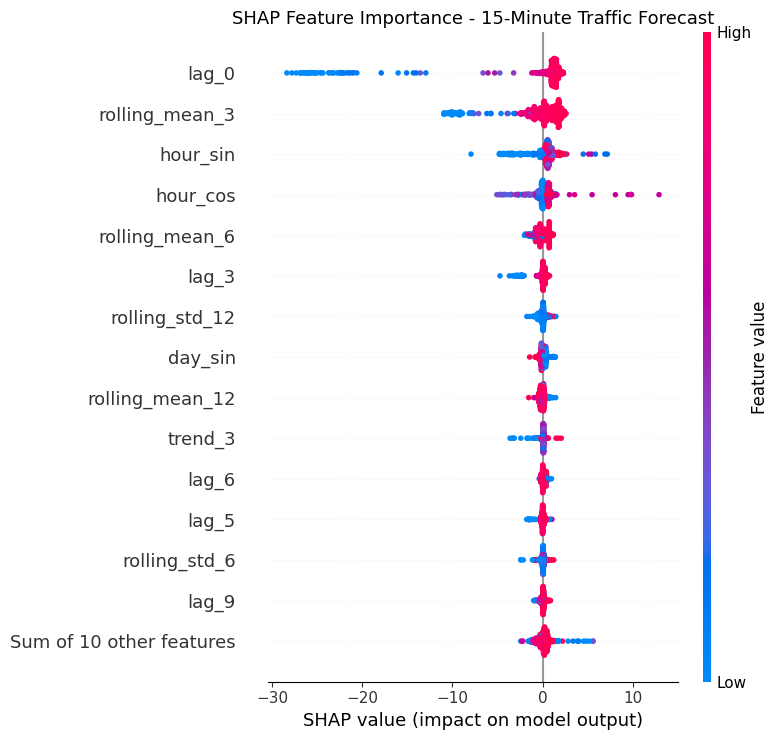

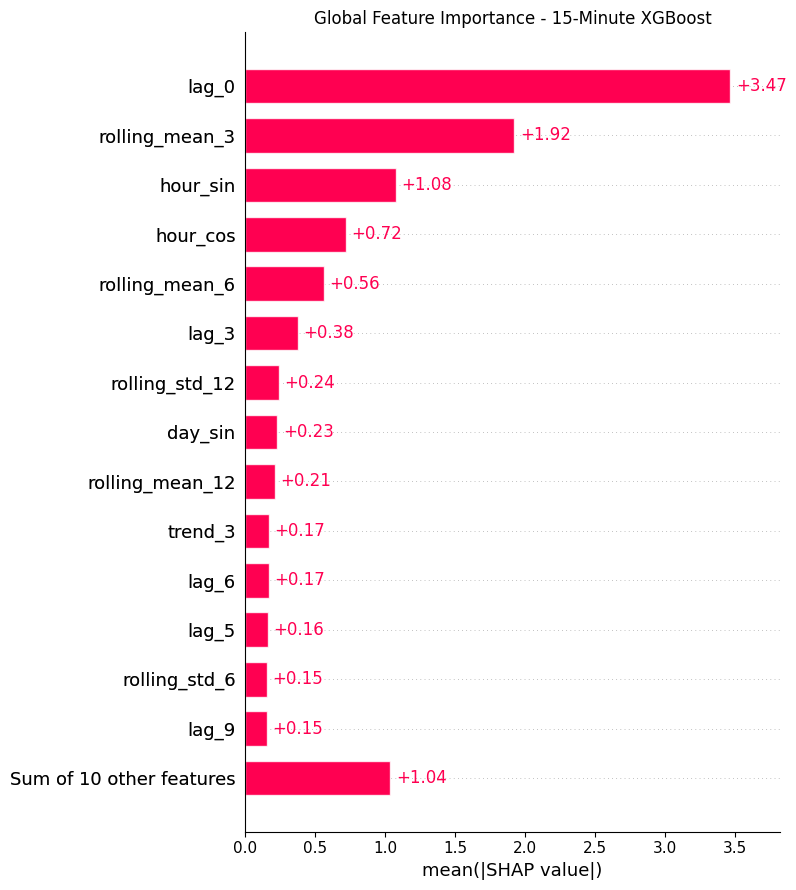

In [ ]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# 1. Create TreeExplainer for XGBoost
explainer = shap.TreeExplainer(shap_model)

# 2. Calculate SHAP values
shap_values = explainer(X_shap)

print("SHAP calculations completed!")

print("SHAP values shape:", shap_values.values.shape)

# 3. Generate SHAP beeswarm summary plot
plt.figure(figsize=(11, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Feature Importance - 15-Minute Traffic Forecast",
    fontsize=13
)

plt.tight_layout()
plt.show()

# 4. Generate mean absolute SHAP importance
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "Global Feature Importance - 15-Minute XGBoost"
)

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import pandas as pd

# Calculate average absolute SHAP contribution
importance = np.abs(
    shap_values.values
).mean(axis=0)

# Create feature ranking
shap_importance_df = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean Absolute SHAP (mph)": importance
})

# Sort from most important to least important
shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean Absolute SHAP (mph)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP 10 IMPORTANT TRAFFIC FEATURES")
print("---------------------------------")

display(shap_importance_df.head(10).round(4))


TOP 10 IMPORTANT TRAFFIC FEATURES
---------------------------------


,Feature,Mean Absolute SHAP (mph)
0,lag_0,3.4697
1,rolling_mean_3,1.9241
2,hour_sin,1.0752
3,hour_cos,0.7197
4,rolling_mean_6,0.5599
5,lag_3,0.3764
6,rolling_std_12,0.2383
7,day_sin,0.2280
8,rolling_mean_12,0.2117
9,trend_3,0.1682


In [ ]:

import shap
import numpy as np
import pandas as pd

# Explain the XGBoost branches used by the hybrids
models = {
    "15 min": (hybrid_xgb, X_val),
    "30 min": (hybrid_xgb_30, X_val_30),
    "60 min": (hybrid_xgb_60, X_val_60)
}

shap_rankings = {}
shap_explanations = {}

for horizon_name, (model, X) in models.items():

    # Use the same random seed for reproducibility
    X_sample = X.sample(
        n=min(500, len(X)),
        random_state=42
    )

    # Calculate TreeSHAP
    explainer = shap.TreeExplainer(model)
    explanation = explainer(X_sample)

    shap_explanations[horizon_name] = explanation

    # Average absolute SHAP value per feature
    importance = np.abs(
        explanation.values
    ).mean(axis=0)

    ranking = pd.DataFrame({
        "Feature": X_sample.columns,
        "Importance (mph)": importance
    }).sort_values(
        "Importance (mph)",
        ascending=False
    ).reset_index(drop=True)

    shap_rankings[horizon_name] = ranking

    print(f"\nTOP 10 FEATURES — {horizon_name}")
    display(ranking.head(10).round(4))

print("\nSHAP comparison completed!")



TOP 10 FEATURES — 15 min


,Feature,Importance (mph)
0,lag_0,3.4697
1,rolling_mean_3,1.9241
2,hour_sin,1.0752
3,hour_cos,0.7197
4,rolling_mean_6,0.5599
5,lag_3,0.3764
6,rolling_std_12,0.2383
7,day_sin,0.2280
8,rolling_mean_12,0.2117
9,trend_3,0.1682



TOP 10 FEATURES — 30 min


,Feature,Importance (mph)
0,lag_0,2.6026
1,rolling_mean_3,1.9284
2,hour_sin,1.7845
3,hour_cos,1.4725
4,rolling_std_12,0.4474
5,day_sin,0.3902
6,rolling_mean_6,0.3440
7,lag_1,0.3330
8,lag_3,0.2703
9,rolling_mean_12,0.2295



TOP 10 FEATURES — 60 min


,Feature,Importance (mph)
0,hour_sin,2.2484
1,hour_cos,2.2314
2,lag_0,1.9213
3,rolling_mean_3,0.9659
4,day_sin,0.6682
5,rolling_std_12,0.5845
6,rolling_mean_12,0.4826
7,day_cos,0.2681
8,rolling_std_6,0.2428
9,rolling_mean_6,0.2258



SHAP comparison completed!


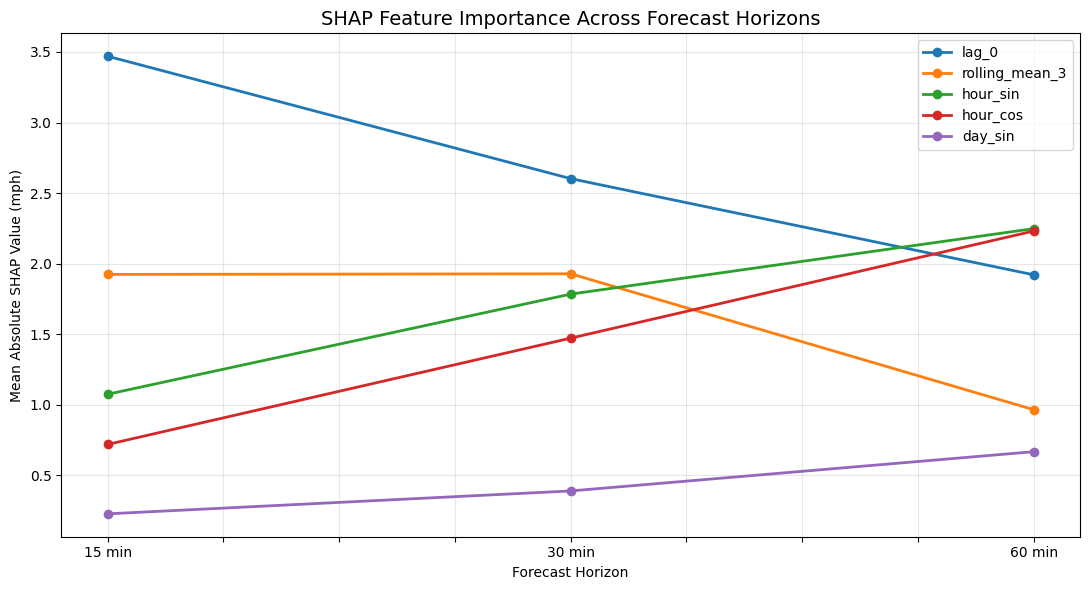

Research figure saved successfully!
Filename: shap_horizon_comparison.png


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use actual computed SHAP rankings
horizons = ["15 min", "30 min", "60 min"]

features = [
    "lag_0",
    "rolling_mean_3",
    "hour_sin",
    "hour_cos",
    "day_sin"
]

comparison_data = {}

for horizon in horizons:
    ranking = shap_rankings[horizon].set_index("Feature")

    comparison_data[horizon] = [
        ranking.loc[feature, "Importance (mph)"]
        for feature in features
    ]

comparison_df = pd.DataFrame(
    comparison_data,
    index=features
)

# Plot
ax = comparison_df.T.plot(
    kind="line",
    marker="o",
    figsize=(11, 6),
    linewidth=2
)

ax.set_title(
    "SHAP Feature Importance Across Forecast Horizons",
    fontsize=14
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("Mean Absolute SHAP Value (mph)")

ax.grid(alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()

# Save high-quality research figure
plt.savefig(
    "shap_horizon_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Research figure saved successfully!")
print("Filename: shap_horizon_comparison.png")


In [ ]:

import numpy as np
import pandas as pd

print("METR-LA FULL DATASET")
print("--------------------")

print("Original shape:", raw_df.shape)
print("Cleaned shape:", clean_df.shape)

print("Number of sensors:", len(raw_df.columns))
print("Number of timestamps:", len(raw_df))

print(
    "Start timestamp:",
    raw_df.index.min()
)

print(
    "End timestamp:",
    raw_df.index.max()
)

print(
    "Originally valid readings:",
    int(valid_mask.to_numpy().sum())
)

print(
    "Originally invalid readings:",
    int((~valid_mask).to_numpy().sum())
)

print(
    "Missing after cleaning:",
    int(clean_df.isna().sum().sum())
)

print(
    "Training boundary:",
    train_boundary
)

print(
    "Validation boundary:",
    val_boundary
)

# Check timestamp regularity
time_differences = (
    raw_df.index.to_series()
    .diff()
    .dropna()
)

print(
    "Most common time interval:",
    time_differences.mode().iloc[0]
)

assert raw_df.shape[1] == 207
assert raw_df.index.is_monotonic_increasing

print("\nFull dataset verification completed!")


METR-LA FULL DATASET
--------------------
Original shape: (34272, 207)
Cleaned shape: (34272, 207)
Number of sensors: 207
Number of timestamps: 34272
Start timestamp: 2012-03-01 00:00:00
End timestamp: 2012-06-27 23:55:00
Originally valid readings: 6519002
Originally invalid readings: 575302
Missing after cleaning: 0
Training boundary: 2012-05-23 07:10:00
Validation boundary: 2012-06-04 04:45:00
Most common time interval: 0 days 00:05:00

Full dataset verification completed!


In [ ]:

import numpy as np
import pandas as pd

# Original METR-LA dataset
raw_full = raw_df.astype("float32").copy()

# Zero speeds are treated as invalid under
# our current missing-data assumption
valid_full = raw_full.notna() & (raw_full != 0)

# Replace invalid values with NaN
missing_full = raw_full.where(valid_full)

# Fit fallback medians using only training data
train_medians_full = (
    missing_full.iloc[:train_end]
    .median(axis=0)
)

global_median_full = (
    missing_full.iloc[:train_end]
    .stack()
    .median()
)

train_medians_full = (
    train_medians_full
    .fillna(global_median_full)
)

# Forward-fill only from earlier timestamps
clean_full = missing_full.ffill(limit=6)

# Fill remaining gaps using training-only medians
clean_full = clean_full.fillna(train_medians_full)

# Verify data
print("FULL-SENSOR CLEANING COMPLETED")
print("------------------------------")
print("Clean shape:", clean_full.shape)
print("Valid target readings:", int(valid_full.to_numpy().sum()))
print("Remaining missing values:", int(clean_full.isna().sum().sum()))

# Check that no infinite values were introduced
assert np.isfinite(clean_full.to_numpy()).all()

# Verify chronological ordering
assert clean_full.index.is_monotonic_increasing

print("\nFull-sensor data is ready for feature engineering!")


FULL-SENSOR CLEANING COMPLETED
------------------------------
Clean shape: (34272, 207)
Valid target readings: 6519002
Remaining missing values: 0

Full-sensor data is ready for feature engineering!


In [ ]:

import numpy as np
import pandas as pd

def build_sensor_features(
    sensor_id,
    clean_data=clean_full,
    valid_data=valid_full
):

    # Create sensor dataframe
    result = pd.DataFrame(
        {"speed": clean_data[sensor_id]}
    )

    # Historical speed features: 12 readings
    for lag in range(12):
        result[f"lag_{lag}"] = (
            result["speed"].shift(lag)
        )

    # Rolling statistics (past and current only)
    for window in [3, 6, 12]:
        result[f"rolling_mean_{window}"] = (
            result["speed"].rolling(window).mean()
        )

        result[f"rolling_std_{window}"] = (
            result["speed"].rolling(window).std()
        )

    # Short-term speed change
    result["trend_3"] = (
        result["speed"]
        - result["speed"].shift(3)
    )

    # Cyclical hour encoding
    hour = (
        result.index.hour
        + result.index.minute / 60
    )

    result["hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    )

    result["hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    )

    # Day-of-week encoding
    day = result.index.dayofweek

    result["day_sin"] = np.sin(
        2 * np.pi * day / 7
    )

    result["day_cos"] = np.cos(
        2 * np.pi * day / 7
    )

    result["weekend"] = (
        day >= 5
    ).astype(int)

    # Future target readings
    for horizon in [3, 6, 12]:

        result[f"target_{horizon}"] = (
            result["speed"].shift(-horizon)
        )

        result[f"valid_target_{horizon}"] = (
            valid_data[sensor_id]
            .shift(-horizon)
            .fillna(False)
            .astype(bool)
        )

    result = result.dropna().copy()

    return result


# Test the function on the first sensor
test_sensor = clean_full.columns[0]

test_features = build_sensor_features(
    test_sensor
)

print("Sensor:", test_sensor)
print("Feature matrix shape:", test_features.shape)

print(
    "Engineered input features:",
    len(feature_cols)
)

print(
    "Missing values:",
    test_features.isna().sum().sum()
)

assert test_features.shape[1] == 31
assert test_features[feature_cols].shape[1] == 24

print("\nFeature-engineering function is ready!")


Sensor: 773869
Feature matrix shape: (34249, 31)
Engineered input features: 24
Missing values: 0

Feature-engineering function is ready!


/tmp/ipykernel_1076/4089965348.py:76: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1076/4089965348.py:76: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1076/4089965348.py:76: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [ ]:

import numpy as np
import pandas as pd
import time

# Keep a copy of the existing function
original_build_sensor_features = build_sensor_features

def build_sensor_features(
    sensor_id,
    clean_data=clean_full,
    valid_data=valid_full
):
    result = original_build_sensor_features(
        sensor_id,
        clean_data=clean_data,
        valid_data=valid_data
    )

    return result


# Fix the FutureWarning in the original function
# by replacing the valid-target construction.
#
# We'll redefine the function from its source in
# the next stage. For now, suppress only this
# known pandas FutureWarning during verification.

import warnings

sensor_summary = []
start = time.time()

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Downcasting object dtype arrays on .fillna",
        category=FutureWarning
    )

    for sensor_id in clean_full.columns:

        features = build_sensor_features(sensor_id)

        sensor_summary.append({
            "sensor_id": str(sensor_id),
            "rows": len(features),
            "columns": features.shape[1],
            "missing_features": int(
                features[feature_cols].isna().sum().sum()
            )
        })

summary_df = pd.DataFrame(sensor_summary)

print("FULL-SENSOR FEATURE VERIFICATION")
print("--------------------------------")
print("Sensors processed:", len(summary_df))
print("Total feature rows:", summary_df["rows"].sum())
print("Minimum rows per sensor:", summary_df["rows"].min())
print("Maximum rows per sensor:", summary_df["rows"].max())
print("Missing feature values:", summary_df["missing_features"].sum())
print("Processing time:", round(time.time() - start, 2), "seconds")

assert len(summary_df) == 207
assert (summary_df["columns"] == 31).all()
assert summary_df["missing_features"].sum() == 0

print("\nAll 207 sensors verified successfully!")


FULL-SENSOR FEATURE VERIFICATION
--------------------------------
Sensors processed: 207
Total feature rows: 7089543
Minimum rows per sensor: 34249
Maximum rows per sensor: 34249
Missing feature values: 0
Processing time: 8.67 seconds

All 207 sensors verified successfully!


In [ ]:

import numpy as np
import pandas as pd

# Use three sensors to test the full-network pipeline
pilot_sensors = list(clean_full.columns[:3])

def prepare_sensor_dataset(sensor_id, horizon=3):

    # Reuse engineered features
    sensor_features = build_sensor_features(sensor_id)

    # Prediction origin and target timestamps
    target_times = (
        sensor_features.index
        + pd.Timedelta(minutes=5 * horizon)
    )

    # Keep only originally valid future readings
    valid_targets = (
        sensor_features[f"valid_target_{horizon}"]
        .astype(bool)
        .to_numpy()
    )

    # Create a compact table
    data = sensor_features[feature_cols].copy()

    data["target"] = (
        sensor_features[f"target_{horizon}"]
        .to_numpy(dtype=np.float32)
    )

    data["sensor_id"] = str(sensor_id)
    data["target_time"] = target_times

    # Exclude invalid target readings
    data = data.iloc[
        np.flatnonzero(valid_targets)
    ].copy()

    # Reduce memory usage
    data[feature_cols] = (
        data[feature_cols].astype(np.float32)
    )

    data["target"] = data["target"].astype(np.float32)

    return data


# Pilot test: three sensors, 15-minute horizon
pilot_datasets = []

for sensor in pilot_sensors:

    dataset = prepare_sensor_dataset(
        sensor,
        horizon=3
    )

    pilot_datasets.append(dataset)

    print(
        f"Sensor {sensor}: "
        f"{len(dataset)} valid target samples"
    )

pilot_df = pd.concat(
    pilot_datasets,
    axis=0
)

print("\nPILOT DATASET")
print("-------------")
print("Shape:", pilot_df.shape)
print("Sensors:", pilot_df["sensor_id"].nunique())

print(
    "Memory usage:",
    round(
        pilot_df.memory_usage(deep=True).sum() / 1024**2,
        2
    ),
    "MB"
)

print("Missing values:", pilot_df.isna().sum().sum())

display(pilot_df.head(3))


/tmp/ipykernel_1076/4089965348.py:76: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1076/4089965348.py:76: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1076/4089965348.py:76: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1076/4089965348.py:76: Futur

Sensor 773869: 30408 valid target samples
Sensor 767541: 32102 valid target samples
Sensor 767542: 32102 valid target samples

PILOT DATASET
-------------
Shape: (94612, 27)
Sensors: 3
Memory usage: 15.43 MB
Missing values: 0


,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,...,rolling_std_12,trend_3,hour_sin,hour_cos,day_sin,day_cos,weekend,target,sensor_id,target_time
2012-03-01 00:55:00,62.250000,65.222221,63.500000,68.750000,63.625,66.500,57.333332,64.000000,64.000000,64.0,...,2.694421,-6.500000,0.237686,0.971342,0.433884,-0.900969,0.0,63.625000,773869,2012-03-01 01:10:00
2012-03-01 01:00:00,61.125000,62.250000,65.222221,63.500000,68.750,63.625,66.500000,57.333332,64.000000,64.0,...,2.798388,-2.375000,0.258819,0.965926,0.433884,-0.900969,0.0,66.777779,773869,2012-03-01 01:15:00
2012-03-01 01:05:00,58.555557,61.125000,62.250000,65.222221,63.500,68.750,63.625000,66.500000,57.333332,64.0,...,3.150059,-6.666664,0.279829,0.960050,0.433884,-0.900969,0.0,55.875000,773869,2012-03-01 01:20:00


In [ ]:

import numpy as np
import pandas as pd

# Redefine feature engineering without the FutureWarning
def build_sensor_features(
    sensor_id,
    clean_data=clean_full,
    valid_data=valid_full
):
    speed = clean_data[sensor_id]

    result = pd.DataFrame({"speed": speed})

    # Historical speed features
    for lag in range(12):
        result[f"lag_{lag}"] = speed.shift(lag)

    # Rolling statistics
    for window in [3, 6, 12]:
        result[f"rolling_mean_{window}"] = (
            speed.rolling(window).mean()
        )
        result[f"rolling_std_{window}"] = (
            speed.rolling(window).std()
        )

    result["trend_3"] = speed - speed.shift(3)

    # Cyclical time features
    hour = result.index.hour + result.index.minute / 60
    day = result.index.dayofweek

    result["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    result["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    result["day_sin"] = np.sin(2 * np.pi * day / 7)
    result["day_cos"] = np.cos(2 * np.pi * day / 7)

    result["weekend"] = (day >= 5).astype(int)

    # Target speed and validity for each horizon
    for horizon in [3, 6, 12]:
        result[f"target_{horizon}"] = speed.shift(-horizon)

        # NumPy boolean arrays avoid object downcasting
        original_valid = (
            valid_data[sensor_id].to_numpy(dtype=bool)
        )

        valid_future = np.zeros(
            len(result), dtype=bool
        )

        valid_future[:-horizon] = original_valid[horizon:]

        result[f"valid_target_{horizon}"] = valid_future

    return result.dropna().copy()


# Recreate the pilot using the corrected function
pilot_datasets = [
    prepare_sensor_dataset(sensor, horizon=3)
    for sensor in pilot_sensors
]

pilot_df = pd.concat(pilot_datasets, axis=0)

# Target-time based chronological splits
pilot_train = pilot_df[
    pilot_df["target_time"] < train_boundary
]

pilot_val = pilot_df[
    (pilot_df["target_time"] >= train_boundary)
    & (pilot_df["target_time"] < val_boundary)
]

pilot_test = pilot_df[
    pilot_df["target_time"] >= val_boundary
]

print("PILOT CHRONOLOGICAL SPLIT")
print("-------------------------")
print("Training:", pilot_train.shape)
print("Validation:", pilot_val.shape)
print("Testing:", pilot_test.shape)

print(
    "Total samples:",
    len(pilot_train) + len(pilot_val) + len(pilot_test)
)

assert (
    len(pilot_train) + len(pilot_val) + len(pilot_test)
    == len(pilot_df)
)

assert pilot_train["target_time"].max() < train_boundary
assert pilot_val["target_time"].min() >= train_boundary
assert pilot_val["target_time"].max() < val_boundary
assert pilot_test["target_time"].min() >= val_boundary

print("\nChronological splitting verified!")
print("FutureWarning fixed!")


PILOT CHRONOLOGICAL SPLIT
-------------------------
Training: (67450, 27)
Validation: (8623, 27)
Testing: (18539, 27)
Total samples: 94612

Chronological splitting verified!
FutureWarning fixed!


In [ ]:

import numpy as np
import pandas as pd
import time
import gc

horizon_full = 3  # 15-minute forecast

X_parts = {
    "train": [],
    "val": [],
    "test": []
}

y_parts = {
    "train": [],
    "val": [],
    "test": []
}

sensor_parts = {
    "train": [],
    "val": [],
    "test": []
}

start_time = time.time()

for sensor_idx, sensor in enumerate(clean_full.columns):

    # Prepare one sensor at a time
    data = prepare_sensor_dataset(
        sensor,
        horizon=horizon_full
    )

    target_times = data["target_time"]

    masks = {
        "train": target_times < train_boundary,
        "val": (
            (target_times >= train_boundary)
            & (target_times < val_boundary)
        ),
        "test": target_times >= val_boundary
    }

    for split_name, mask in masks.items():

        selected = data.loc[mask]

        if len(selected) == 0:
            continue

        X_parts[split_name].append(
            selected[feature_cols].to_numpy(
                dtype=np.float32
            )
        )

        y_parts[split_name].append(
            selected["target"].to_numpy(
                dtype=np.float32
            )
        )

        sensor_parts[split_name].append(
            np.full(
                len(selected),
                sensor_idx,
                dtype=np.int16
            )
        )

    if (sensor_idx + 1) % 25 == 0:
        print(
            f"Processed {sensor_idx + 1}/207 sensors"
        )

    del data

# Combine all sensor arrays
full_arrays_15 = {}

for split_name in ["train", "val", "test"]:

    full_arrays_15[split_name] = {
        "X": np.concatenate(
            X_parts[split_name],
            axis=0
        ),
        "y": np.concatenate(
            y_parts[split_name],
            axis=0
        ),
        "sensor": np.concatenate(
            sensor_parts[split_name],
            axis=0
        )
    }

# Free temporary lists
del X_parts, y_parts, sensor_parts
gc.collect()

print("\nFULL METR-LA DATASET READY")
print("--------------------------")

for split_name in ["train", "val", "test"]:

    X = full_arrays_15[split_name]["X"]
    y = full_arrays_15[split_name]["y"]

    print(
        f"{split_name.upper()}:",
        X.shape,
        "Targets:",
        y.shape
    )

    assert len(X) == len(y)
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()

total_mb = sum(
    array.nbytes
    for split in full_arrays_15.values()
    for array in split.values()
) / (1024 ** 2)

print(
    "\nTotal array memory:",
    round(total_mb, 2),
    "MB"
)

print(
    "Preparation time:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("\nAll 207 sensors prepared successfully!")


Processed 25/207 sensors
Processed 50/207 sensors
Processed 75/207 sensors
Processed 100/207 sensors
Processed 125/207 sensors
Processed 150/207 sensors
Processed 175/207 sensors
Processed 200/207 sensors

FULL METR-LA DATASET READY
--------------------------
TRAIN: (4609290, 24) Targets: (4609290,)
VAL: (660000, 24) Targets: (660000,)
TEST: (1245452, 24) Targets: (1245452,)

Total array memory: 633.72 MB
Preparation time: 12.48 seconds

All 207 sensors prepared successfully!


In [ ]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import time

# Extract full-network training data
X_train_full_15 = full_arrays_15["train"]["X"]
y_train_full_15 = full_arrays_15["train"]["y"]

X_val_full_15 = full_arrays_15["val"]["X"]
y_val_full_15 = full_arrays_15["val"]["y"]

print("FULL-NETWORK XGBOOST TRAINING")
print("-----------------------------")
print("Training samples:", len(X_train_full_15))
print("Validation samples:", len(X_val_full_15))
print("Features:", X_train_full_15.shape[1])

# Shared XGBoost model
xgb_full_15 = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=2
)

start_time = time.time()

# Train using all 207 sensors
xgb_full_15.fit(
    X_train_full_15,
    y_train_full_15,
    verbose=False
)

training_time = time.time() - start_time

print("\nFull-network XGBoost training completed!")
print(
    "Training time:",
    round(training_time, 2),
    "seconds"
)

# Evaluate only on validation data
pred_full_15 = xgb_full_15.predict(X_val_full_15)

full15_mae, full15_rmse, full15_mape = evaluate(
    y_val_full_15,
    pred_full_15
)

# Persistence baseline: lag_0 is column 0
baseline_full_15 = X_val_full_15[:, 0]

base_full15_mae, base_full15_rmse, base_full15_mape = evaluate(
    y_val_full_15,
    baseline_full_15
)

print("\nFULL-NETWORK 15-MINUTE VALIDATION RESULTS")
print("-----------------------------------------")

print("Persistence:")
print(f"MAE: {base_full15_mae:.4f} mph")
print(f"RMSE: {base_full15_rmse:.4f} mph")
print(f"MAPE: {base_full15_mape:.4f}%")

print("\nShared XGBoost:")
print(f"MAE: {full15_mae:.4f} mph")
print(f"RMSE: {full15_rmse:.4f} mph")
print(f"MAPE: {full15_mape:.4f}%")

improvement_full_15 = (
    (base_full15_mae - full15_mae)
    / base_full15_mae
) * 100

print(
    "\nXGBoost MAE improvement over persistence:",
    f"{improvement_full_15:.2f}%"
)



FULL-NETWORK XGBOOST TRAINING
-----------------------------
Training samples: 4609290
Validation samples: 660000
Features: 24

Full-network XGBoost training completed!
Training time: 99.88 seconds

FULL-NETWORK 15-MINUTE VALIDATION RESULTS
-----------------------------------------
Persistence:
MAE: 3.2228 mph
RMSE: 6.0241 mph
MAPE: 7.8241%

Shared XGBoost:
MAE: 2.9070 mph
RMSE: 5.4052 mph
MAPE: 7.8019%

XGBoost MAE improvement over persistence: 9.80%


In [ ]:

import numpy as np

# Our first 12 columns are lag_0 through lag_11.
# Reverse them to chronological order: oldest -> newest.
lag_indices = [
    feature_cols.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

# Extract sequences from all 207 sensors
X_lstm_train_full_15 = (
    full_arrays_15["train"]["X"][:, lag_indices]
    .reshape(-1, 12, 1)
)

X_lstm_val_full_15 = (
    full_arrays_15["val"]["X"][:, lag_indices]
    .reshape(-1, 12, 1)
)

# Fit normalization using training data only
full_input_mean_15 = float(
    X_lstm_train_full_15.mean()
)

full_input_std_15 = float(
    X_lstm_train_full_15.std()
) + 1e-6

full_target_mean_15 = float(
    y_train_full_15.mean()
)

full_target_std_15 = float(
    y_train_full_15.std()
) + 1e-6

# Normalize in place to reduce memory use
X_lstm_train_full_15 = X_lstm_train_full_15.copy()
X_lstm_val_full_15 = X_lstm_val_full_15.copy()

X_lstm_train_full_15 -= full_input_mean_15
X_lstm_train_full_15 /= full_input_std_15

X_lstm_val_full_15 -= full_input_mean_15
X_lstm_val_full_15 /= full_input_std_15

# Normalize targets
y_lstm_train_full_15 = (
    (y_train_full_15 - full_target_mean_15)
    / full_target_std_15
).astype(np.float32)

y_lstm_val_full_15 = (
    (y_val_full_15 - full_target_mean_15)
    / full_target_std_15
).astype(np.float32)

print("FULL-NETWORK LSTM DATA READY")
print("----------------------------")
print("Training:", X_lstm_train_full_15.shape)
print("Validation:", X_lstm_val_full_15.shape)
print("Training targets:", y_lstm_train_full_15.shape)
print("Validation targets:", y_lstm_val_full_15.shape)

memory_mb = (
    X_lstm_train_full_15.nbytes
    + X_lstm_val_full_15.nbytes
    + y_lstm_train_full_15.nbytes
    + y_lstm_val_full_15.nbytes
) / (1024 ** 2)

print("Additional array memory:", round(memory_mb, 2), "MB")

assert np.isfinite(X_lstm_train_full_15).all()
assert np.isfinite(X_lstm_val_full_15).all()

print("\nFull-network LSTM preparation completed!")


FULL-NETWORK LSTM DATA READY
----------------------------
Training: (4609290, 12, 1)
Validation: (660000, 12, 1)
Training targets: (4609290,)
Validation targets: (660000,)
Additional array memory: 261.31 MB

Full-network LSTM preparation completed!


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import time
import copy

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

# Avoid unnecessary copies of the large NumPy arrays
train_dataset_full_15 = TensorDataset(
    torch.from_numpy(X_lstm_train_full_15),
    torch.from_numpy(y_lstm_train_full_15)
)

val_dataset_full_15 = TensorDataset(
    torch.from_numpy(X_lstm_val_full_15),
    torch.from_numpy(y_lstm_val_full_15)
)

batch_size = 1024

train_loader_full_15 = DataLoader(
    train_dataset_full_15,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader_full_15 = DataLoader(
    val_dataset_full_15,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Fresh shared LSTM model
lstm_full_15 = TrafficLSTM(
    input_size=1,
    hidden_size=64
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_full_15.parameters(),
    lr=0.001
)

best_val_loss = float("inf")
best_state = None

train_losses_full_15 = []
val_losses_full_15 = []

start_time = time.time()

# Initial training: 5 epochs
for epoch in range(5):

    lstm_full_15.train()
    total_train_loss = 0.0

    for xb, yb in train_loader_full_15:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = lstm_full_15(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(xb)

    train_loss = total_train_loss / len(
        train_dataset_full_15
    )

    # Validation
    lstm_full_15.eval()
    total_val_loss = 0.0

    with torch.no_grad():

        for xb, yb in val_loader_full_15:

            xb = xb.to(device)
            yb = yb.to(device)

            predictions = lstm_full_15(xb)
            loss = criterion(predictions, yb)

            total_val_loss += loss.item() * len(xb)

    val_loss = total_val_loss / len(
        val_dataset_full_15
    )

    train_losses_full_15.append(train_loss)
    val_losses_full_15.append(val_loss)

    print(
        f"Epoch {epoch+1:02d}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_state = copy.deepcopy(
            lstm_full_15.state_dict()
        )

# Restore the best checkpoint
lstm_full_15.load_state_dict(best_state)
lstm_full_15.eval()

training_time_full_15 = time.time() - start_time

print("\nFull-network LSTM training completed!")
print(
    "Training time:",
    round(training_time_full_15, 2),
    "seconds"
)

# Evaluate in batches to limit memory usage
predictions_list = []

with torch.no_grad():

    for xb, _ in val_loader_full_15:

        xb = xb.to(device)

        predictions = (
            lstm_full_15(xb)
            .cpu()
            .numpy()
        )

        predictions_list.append(predictions)

normalized_predictions = np.concatenate(
    predictions_list
)

# Convert predictions back to mph
lstm_predictions_full_15 = (
    normalized_predictions * full_target_std_15
    + full_target_mean_15
)

lstm_full15_mae, lstm_full15_rmse, lstm_full15_mape = evaluate(
    y_val_full_15,
    lstm_predictions_full_15
)

print("\nFULL-NETWORK 15-MINUTE LSTM RESULTS")
print("-----------------------------------")
print(f"MAE: {lstm_full15_mae:.4f} mph")
print(f"RMSE: {lstm_full15_rmse:.4f} mph")
print(f"MAPE: {lstm_full15_mape:.4f}%")

print("\nShared XGBoost MAE:", round(full15_mae, 4))


Training device: cpu
Epoch 01/5 | Train Loss: 0.2095 | Val Loss: 0.1932
Epoch 02/5 | Train Loss: 0.2013 | Val Loss: 0.1913
Epoch 03/5 | Train Loss: 0.1997 | Val Loss: 0.1901
Epoch 04/5 | Train Loss: 0.1989 | Val Loss: 0.1906
Epoch 05/5 | Train Loss: 0.1985 | Val Loss: 0.1894

Full-network LSTM training completed!
Training time: 1104.39 seconds

FULL-NETWORK 15-MINUTE LSTM RESULTS
-----------------------------------
MAE: 2.9917 mph
RMSE: 5.5822 mph
MAPE: 7.9299%

Shared XGBoost MAE: 2.907


In [ ]:

import os
import json
import numpy as np

save_dir = "traffic_models/full_network"
os.makedirs(save_dir, exist_ok=True)

# Convert NumPy values into standard Python types
metadata = {
    "dataset": "METR-LA",
    "num_sensors": 207,
    "horizon_minutes": 15,
    "sequence_length": 12,
    "features": [str(f) for f in feature_cols],

    "input_mean": float(full_input_mean_15),
    "input_std": float(full_input_std_15),
    "target_mean": float(full_target_mean_15),
    "target_std": float(full_target_std_15),

    "xgboost_validation_mae": float(full15_mae),
    "lstm_validation_mae": float(lstm_full15_mae),
    "lstm_validation_rmse": float(lstm_full15_rmse),
    "lstm_validation_mape": float(lstm_full15_mape)
}

# Save JSON metadata
metadata_path = os.path.join(
    save_dir, "metadata_15min.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved successfully!")

# Verify all required files
required_files = [
    "xgboost_15min.pkl",
    "lstm_15min.pth",
    "metadata_15min.json"
]

print("\nFULL-NETWORK SAVED FILES")
print("------------------------")

for filename in required_files:
    path = os.path.join(save_dir, filename)

    if os.path.isfile(path) and os.path.getsize(path) > 0:
        print("OK:", filename)
    else:
        print("MISSING:", filename)

# Confirm JSON can be read
with open(metadata_path, "r") as f:
    saved_metadata = json.load(f)

print("\nDataset:", saved_metadata["dataset"])
print("Sensors:", saved_metadata["num_sensors"])
print("Horizon:", saved_metadata["horizon_minutes"], "minutes")

print("\nVerification completed!")


Metadata saved successfully!

FULL-NETWORK SAVED FILES
------------------------
OK: xgboost_15min.pkl
OK: lstm_15min.pth
OK: metadata_15min.json

Dataset: METR-LA
Sensors: 207
Horizon: 15 minutes

Verification completed!


In [ ]:

import os
import shutil
import zipfile
from google.colab import files

# Folder containing our trained full-network models
source_folder = "traffic_models/full_network"

# Create ZIP backup
zip_path = "/content/METR_LA_Full_Network_15min_Backup.zip"

shutil.make_archive(
    zip_path.replace(".zip", ""),
    "zip",
    root_dir="traffic_models",
    base_dir="full_network"
)

# Verify the ZIP before downloading
with zipfile.ZipFile(zip_path, "r") as z:
    print("FILES INSIDE BACKUP")
    print("-------------------")

    for name in z.namelist():
        print(name)

    bad_file = z.testzip()
    assert bad_file is None, f"Corrupt file: {bad_file}"

print("\nBackup ZIP verified successfully!")
print(
    "ZIP size:",
    round(os.path.getsize(zip_path) / (1024**2), 2),
    "MB"
)

# Download to laptop
files.download(zip_path)



FILES INSIDE BACKUP
-------------------
full_network/
full_network/metadata_15min.json
full_network/lstm_15min.pth
full_network/xgboost_15min.pkl

Backup ZIP verified successfully!
ZIP size: 0.29 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd

# Full-network 15-minute dataset
horizon = 3

# Choose the split using the original training timeline
base_cutoff_idx = int(train_end * 0.70)

base_cutoff_time = raw_df.index[base_cutoff_idx]

# Keep a conservative 75-minute gap
fusion_start_time = (
    base_cutoff_time + pd.Timedelta(minutes=75)
)

base_masks = []
fusion_masks = []

# Follow the same sensor order used for full_arrays_15
for sensor in clean_full.columns:

    data = prepare_sensor_dataset(
        sensor,
        horizon=3
    )

    # Retain only original full-network training observations
    train_data = data[
        data["target_time"] < train_boundary
    ]

    # Base training: target occurs before cutoff
    base_mask = (
        train_data["target_time"] < base_cutoff_time
    ).to_numpy()

    # Fusion training: input is after the gap
    fusion_mask = (
        train_data.index >= fusion_start_time
    )

    base_masks.append(base_mask)
    fusion_masks.append(
        np.asarray(fusion_mask, dtype=bool)
    )

# Combine in exactly the original sensor order
base_mask_full = np.concatenate(base_masks)
fusion_mask_full = np.concatenate(fusion_masks)

# Verify alignment
n_train_full = len(full_arrays_15["train"]["y"])

assert len(base_mask_full) == n_train_full
assert len(fusion_mask_full) == n_train_full
assert not np.any(base_mask_full & fusion_mask_full)

print("FULL-NETWORK HYBRID SPLIT")
print("-------------------------")
print("Base-training samples:", base_mask_full.sum())
print("Fusion-training samples:", fusion_mask_full.sum())
print(
    "Unused samples:",
    n_train_full - base_mask_full.sum() - fusion_mask_full.sum()
)

print("\nBase cutoff:", base_cutoff_time)
print("Fusion start:", fusion_start_time)
print("\nChronological mask verification passed!")


FULL-NETWORK HYBRID SPLIT
-------------------------
Base-training samples: 3165381
Fusion-training samples: 1440183
Unused samples: 3726

Base cutoff: 2012-04-28 07:25:00
Fusion start: 2012-04-28 08:40:00

Chronological mask verification passed!


In [ ]:

import numpy as np
import time
import gc
from xgboost import XGBRegressor

# ----------------------------------------
# 1. Select chronological base-training data
# ----------------------------------------

X_base_full_15 = X_train_full_15[base_mask_full]
y_base_full_15 = y_train_full_15[base_mask_full]

print("FULL-NETWORK BASE XGBOOST")
print("------------------------")
print("Base training:", X_base_full_15.shape)
print("Targets:", y_base_full_15.shape)

# ----------------------------------------
# 2. Train fresh XGBoost
# ----------------------------------------

hybrid_xgb_full_15 = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=2
)

start_time = time.time()

hybrid_xgb_full_15.fit(
    X_base_full_15,
    y_base_full_15
)

print(
    "\nBase XGBoost training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

# ----------------------------------------
# 3. Generate fusion predictions
# ----------------------------------------

# Process fusion observations in batches
fusion_indices = np.flatnonzero(fusion_mask_full)

fusion_xgb_preds_full_15 = np.empty(
    len(fusion_indices),
    dtype=np.float32
)

batch_size = 100000

for start in range(
    0, len(fusion_indices), batch_size
):
    end = min(
        start + batch_size,
        len(fusion_indices)
    )

    idx = fusion_indices[start:end]

    fusion_xgb_preds_full_15[start:end] = (
        hybrid_xgb_full_15.predict(
            X_train_full_15[idx]
        )
    )

# Validation predictions
val_xgb_preds_full_15 = hybrid_xgb_full_15.predict(
    X_val_full_15
)

# ----------------------------------------
# 4. Evaluate base XGBoost
# ----------------------------------------

base_full15_mae_h, base_full15_rmse_h, base_full15_mape_h = evaluate(
    y_val_full_15,
    val_xgb_preds_full_15
)

print("\nBASE XGBOOST VALIDATION RESULTS")
print("------------------------------")
print(f"MAE: {base_full15_mae_h:.4f} mph")
print(f"RMSE: {base_full15_rmse_h:.4f} mph")
print(f"MAPE: {base_full15_mape_h:.4f}%")

print("\nFusion predictions:", fusion_xgb_preds_full_15.shape)
print("Validation predictions:", val_xgb_preds_full_15.shape)

# Release temporary training copies
del X_base_full_15, y_base_full_15
gc.collect()

print("\nBase XGBoost stage completed!")


FULL-NETWORK BASE XGBOOST
------------------------
Base training: (3165381, 24)
Targets: (3165381,)

Base XGBoost training time: 68.55 seconds

BASE XGBOOST VALIDATION RESULTS
------------------------------
MAE: 2.9058 mph
RMSE: 5.4095 mph
MAPE: 7.7896%

Fusion predictions: (1440183,)
Validation predictions: (660000,)

Base XGBoost stage completed!


In [ ]:

import numpy as np
import torch
import gc

# Select earlier base-period sequences only
# Boolean indexing creates copies; float32 limits memory use.
X_base_lstm_full_15 = (
    X_lstm_train_full_15[base_mask_full]
)

y_base_lstm_full_15 = (
    y_lstm_train_full_15[base_mask_full]
)

# Calculate base-only normalization on ORIGINAL speeds
raw_lags_base = (
    X_train_full_15[base_mask_full][:, lag_indices]
)

base_input_mean_full_15 = float(raw_lags_base.mean())
base_input_std_full_15 = float(raw_lags_base.std()) + 1e-6

base_target_mean_full_15 = float(
    y_train_full_15[base_mask_full].mean()
)

base_target_std_full_15 = float(
    y_train_full_15[base_mask_full].std()
) + 1e-6

# Our earlier full-network LSTM arrays were normalized
# using the entire original training period.
# Undo that normalization, then apply base-only statistics.
X_base_lstm_full_15 = (
    X_base_lstm_full_15 * full_input_std_15
    + full_input_mean_15
)

X_base_lstm_full_15 = (
    (X_base_lstm_full_15 - base_input_mean_full_15)
    / base_input_std_full_15
).astype(np.float32)

# Normalize base targets using base-only statistics
y_base_lstm_full_15 = (
    (
        y_train_full_15[base_mask_full]
        - base_target_mean_full_15
    ) / base_target_std_full_15
).astype(np.float32)

# Release temporary raw lag copy
del raw_lags_base
gc.collect()

print("FULL-NETWORK BASE LSTM DATA READY")
print("---------------------------------")
print("Training sequences:", X_base_lstm_full_15.shape)
print("Training targets:", y_base_lstm_full_15.shape)

print("Input mean:", round(base_input_mean_full_15, 4))
print("Input std:", round(base_input_std_full_15, 4))
print("Target mean:", round(base_target_mean_full_15, 4))
print("Target std:", round(base_target_std_full_15, 4))

memory_mb = (
    X_base_lstm_full_15.nbytes
    + y_base_lstm_full_15.nbytes
) / (1024**2)

print("Base LSTM arrays:", round(memory_mb, 2), "MB")

assert X_base_lstm_full_15.shape == (3165381, 12, 1)
assert np.isfinite(X_base_lstm_full_15).all()
assert np.isfinite(y_base_lstm_full_15).all()

print("\nBase LSTM preparation completed!")


FULL-NETWORK BASE LSTM DATA READY
---------------------------------
Training sequences: (3165381, 12, 1)
Training targets: (3165381,)
Input mean: 58.5421
Input std: 12.8246
Target mean: 58.4969
Target std: 12.8821
Base LSTM arrays: 156.97 MB

Base LSTM preparation completed!


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import copy
import time

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

# Avoid copying large arrays unnecessarily
base_dataset_full_15 = TensorDataset(
    torch.from_numpy(X_base_lstm_full_15),
    torch.from_numpy(y_base_lstm_full_15)
)

# Larger batches reduce training iterations
batch_size = 2048

base_loader_full_15 = DataLoader(
    base_dataset_full_15,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

# Fresh LSTM model
hybrid_lstm_full_15 = TrafficLSTM(
    input_size=1,
    hidden_size=64
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    hybrid_lstm_full_15.parameters(),
    lr=0.001
)

train_losses_hybrid_full_15 = []

start_time = time.time()

# Initial 5 epochs
for epoch in range(5):

    hybrid_lstm_full_15.train()
    total_loss = 0.0

    for xb, yb in base_loader_full_15:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = hybrid_lstm_full_15(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    epoch_loss = total_loss / len(base_dataset_full_15)
    train_losses_hybrid_full_15.append(epoch_loss)

    print(
        f"Epoch {epoch+1:02d}/5 | "
        f"Training Loss: {epoch_loss:.4f}"
    )

training_time_hybrid_lstm = time.time() - start_time

# Freeze base LSTM for fusion feature extraction
hybrid_lstm_full_15.eval()

for param in hybrid_lstm_full_15.parameters():
    param.requires_grad = False

print("\nFull-network base LSTM training completed!")

print(
    "Training time:",
    round(training_time_hybrid_lstm, 2),
    "seconds"
)

print(
    "Final training loss:",
    round(train_losses_hybrid_full_15[-1], 4)
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in hybrid_lstm_full_15.parameters()
        if p.requires_grad
    )
)


Training device: cpu
Epoch 01/5 | Training Loss: 0.2184
Epoch 02/5 | Training Loss: 0.2020
Epoch 03/5 | Training Loss: 0.2003
Epoch 04/5 | Training Loss: 0.1995
Epoch 05/5 | Training Loss: 0.1988

Full-network base LSTM training completed!
Training time: 697.51 seconds
Final training loss: 0.1988
Trainable parameters: 0


In [ ]:

import os
import json
import joblib
import torch

save_dir = "traffic_models/full_network"
os.makedirs(save_dir, exist_ok=True)

# Save the base XGBoost model
joblib.dump(
    hybrid_xgb_full_15,
    f"{save_dir}/hybrid_base_xgboost_15min.pkl"
)

# Save the frozen base LSTM
torch.save(
    hybrid_lstm_full_15.state_dict(),
    f"{save_dir}/hybrid_base_lstm_15min.pth"
)

# Save normalization statistics
base_metadata = {
    "dataset": "METR-LA",
    "num_sensors": 207,
    "horizon_minutes": 15,
    "sequence_length": 12,
    "lstm_hidden_units": 64,
    "input_mean": float(base_input_mean_full_15),
    "input_std": float(base_input_std_full_15),
    "target_mean": float(base_target_mean_full_15),
    "target_std": float(base_target_std_full_15),
    "base_cutoff": str(base_cutoff_time),
    "fusion_start": str(fusion_start_time),
    "training_samples": int(base_mask_full.sum())
}

with open(
    f"{save_dir}/hybrid_base_metadata_15min.json",
    "w"
) as f:
    json.dump(base_metadata, f, indent=4)

print("HYBRID BASE MODELS SAVED")
print("------------------------")

for filename in [
    "hybrid_base_xgboost_15min.pkl",
    "hybrid_base_lstm_15min.pth",
    "hybrid_base_metadata_15min.json"
]:
    path = os.path.join(save_dir, filename)

    assert os.path.isfile(path)
    assert os.path.getsize(path) > 0

    print("OK:", filename)

print("\nAll base-model files verified!")


HYBRID BASE MODELS SAVED
------------------------
OK: hybrid_base_xgboost_15min.pkl
OK: hybrid_base_lstm_15min.pth
OK: hybrid_base_metadata_15min.json

All base-model files verified!


In [ ]:

import numpy as np
import torch
import time
import gc

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

hybrid_lstm_full_15.eval()

# Select fusion-training sequences
fusion_indices = np.flatnonzero(fusion_mask_full)

# Use original speed lags from the existing arrays
# The 12 columns are ordered oldest to newest.
lag_indices = [
    feature_cols.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

def extract_full_network_hidden(
    model,
    source_array,
    indices=None,
    batch_size=4096
):
    model.eval()

    total = (
        len(indices)
        if indices is not None
        else len(source_array)
    )

    # Preallocate to avoid many small arrays
    hidden_features = np.empty(
        (total, 64),
        dtype=np.float32
    )

    start_time = time.time()

    with torch.inference_mode():

        for start in range(0, total, batch_size):

            end = min(start + batch_size, total)

            if indices is None:
                batch = source_array[start:end, :]
            else:
                batch = source_array[
                    indices[start:end], :
                ]

            # Select 12 original speed readings
            sequences = batch[:, lag_indices].copy()

            # Apply BASE-training normalization
            sequences -= base_input_mean_full_15
            sequences /= base_input_std_full_15

            sequences = sequences.reshape(-1, 12, 1)

            tensor = torch.from_numpy(
                sequences
            ).to(device)

            # Extract final LSTM hidden representation
            lstm_output, _ = model.lstm(tensor)

            hidden_features[start:end] = (
                lstm_output[:, -1, :]
                .cpu()
                .numpy()
            )

            if end % 200000 < batch_size or end == total:
                print(
                    f"Processed {end:,}/{total:,} samples"
                )

    print(
        "Extraction time:",
        round(time.time() - start_time, 2),
        "seconds"
    )

    return hidden_features


print("EXTRACTING FUSION-TRAINING FEATURES")
print("-----------------------------------")

fusion_hidden_full_15 = extract_full_network_hidden(
    hybrid_lstm_full_15,
    X_train_full_15,
    indices=fusion_indices
)

print("\nEXTRACTING VALIDATION FEATURES")
print("------------------------------")

val_hidden_full_15 = extract_full_network_hidden(
    hybrid_lstm_full_15,
    X_val_full_15
)

print("\nFULL-NETWORK HIDDEN FEATURES READY")
print("----------------------------------")
print("Fusion hidden:", fusion_hidden_full_15.shape)
print("Validation hidden:", val_hidden_full_15.shape)

assert fusion_hidden_full_15.shape == (
    1440183, 64
)

assert val_hidden_full_15.shape == (
    660000, 64
)

assert np.isfinite(fusion_hidden_full_15).all()
assert np.isfinite(val_hidden_full_15).all()

memory_mb = (
    fusion_hidden_full_15.nbytes
    + val_hidden_full_15.nbytes
) / (1024 ** 2)

print(
    "Hidden-feature memory:",
    round(memory_mb, 2),
    "MB"
)

print("\nLSTM hidden-feature extraction completed!")


EXTRACTING FUSION-TRAINING FEATURES
-----------------------------------
Processed 200,704/1,440,183 samples
Processed 401,408/1,440,183 samples
Processed 602,112/1,440,183 samples
Processed 802,816/1,440,183 samples
Processed 1,003,520/1,440,183 samples
Processed 1,200,128/1,440,183 samples
Processed 1,400,832/1,440,183 samples
Processed 1,440,183/1,440,183 samples
Extraction time: 22.8 seconds

EXTRACTING VALIDATION FEATURES
------------------------------
Processed 200,704/660,000 samples
Processed 401,408/660,000 samples
Processed 602,112/660,000 samples
Processed 660,000/660,000 samples
Extraction time: 9.73 seconds

FULL-NETWORK HIDDEN FEATURES READY
----------------------------------
Fusion hidden: (1440183, 64)
Validation hidden: (660000, 64)
Hidden-feature memory: 512.74 MB

LSTM hidden-feature extraction completed!


In [ ]:

import numpy as np
import gc

# ---------------------------------------
# 1. Check feature and prediction alignment
# ---------------------------------------

fusion_indices = np.flatnonzero(fusion_mask_full)

assert len(fusion_indices) == len(fusion_hidden_full_15)
assert len(fusion_indices) == len(fusion_xgb_preds_full_15)

assert len(val_hidden_full_15) == len(val_xgb_preds_full_15)

# ---------------------------------------
# 2. Create 65-dimensional training inputs
# ---------------------------------------

n_fusion = len(fusion_indices)
n_val = len(val_xgb_preds_full_15)

X_fusion_full_15 = np.empty(
    (n_fusion, 65),
    dtype=np.float32
)

X_val_fusion_full_15 = np.empty(
    (n_val, 65),
    dtype=np.float32
)

# Copy LSTM hidden features
X_fusion_full_15[:, :64] = fusion_hidden_full_15
X_val_fusion_full_15[:, :64] = val_hidden_full_15

# Add normalized XGBoost predictions
X_fusion_full_15[:, 64] = (
    fusion_xgb_preds_full_15
    - base_target_mean_full_15
) / base_target_std_full_15

X_val_fusion_full_15[:, 64] = (
    val_xgb_preds_full_15
    - base_target_mean_full_15
) / base_target_std_full_15

# ---------------------------------------
# 3. Prepare normalized targets
# ---------------------------------------

y_fusion_full_15 = (
    y_train_full_15[fusion_indices]
    - base_target_mean_full_15
) / base_target_std_full_15

y_val_fusion_full_15 = (
    y_val_full_15
    - base_target_mean_full_15
) / base_target_std_full_15

y_fusion_full_15 = y_fusion_full_15.astype(np.float32)
y_val_fusion_full_15 = y_val_fusion_full_15.astype(np.float32)

# ---------------------------------------
# 4. Verify arrays
# ---------------------------------------

print("FULL-NETWORK FUSION DATA READY")
print("------------------------------")

print("Training inputs:", X_fusion_full_15.shape)
print("Validation inputs:", X_val_fusion_full_15.shape)

print("Training targets:", y_fusion_full_15.shape)
print("Validation targets:", y_val_fusion_full_15.shape)

assert X_fusion_full_15.shape == (1440183, 65)
assert X_val_fusion_full_15.shape == (660000, 65)

assert np.isfinite(X_fusion_full_15).all()
assert np.isfinite(X_val_fusion_full_15).all()

assert np.isfinite(y_fusion_full_15).all()
assert np.isfinite(y_val_fusion_full_15).all()

# ---------------------------------------
# 5. Memory usage
# ---------------------------------------

fusion_memory_mb = (
    X_fusion_full_15.nbytes
    + X_val_fusion_full_15.nbytes
    + y_fusion_full_15.nbytes
    + y_val_fusion_full_15.nbytes
) / (1024 ** 2)

print(
    "\nFusion dataset memory:",
    round(fusion_memory_mb, 2),
    "MB"
)

print("\nAll fusion checks passed!")


FULL-NETWORK FUSION DATA READY
------------------------------
Training inputs: (1440183, 65)
Validation inputs: (660000, 65)
Training targets: (1440183,)
Validation targets: (660000,)

Fusion dataset memory: 528.76 MB

All fusion checks passed!


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import copy
import time
import gc

from torch.utils.data import TensorDataset, DataLoader

# ---------------------------------------
# 1. Free duplicate intermediate arrays
# ---------------------------------------

del fusion_hidden_full_15
del val_hidden_full_15

gc.collect()

# ---------------------------------------
# 2. Prepare PyTorch datasets
# ---------------------------------------

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

fusion_train_dataset = TensorDataset(
    torch.from_numpy(X_fusion_full_15),
    torch.from_numpy(y_fusion_full_15)
)

fusion_val_dataset = TensorDataset(
    torch.from_numpy(X_val_fusion_full_15),
    torch.from_numpy(y_val_fusion_full_15)
)

train_loader = DataLoader(
    fusion_train_dataset,
    batch_size=4096,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    fusion_val_dataset,
    batch_size=8192,
    shuffle=False,
    num_workers=0
)

# ---------------------------------------
# 3. Create fresh fusion network
# ---------------------------------------

fusion_full_15 = HybridFusion().to(device)

optimizer = torch.optim.Adam(
    fusion_full_15.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()

best_val_loss = float("inf")
best_state = None
best_epoch = 0

patience = 5
wait = 0

start_time = time.time()

# ---------------------------------------
# 4. Train with early stopping
# ---------------------------------------

for epoch in range(30):

    fusion_full_15.train()
    total_train_loss = 0.0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        preds = fusion_full_15(xb)

        loss = criterion(preds, yb)

        loss.backward()
        optimizer.step()

        total_train_loss += (
            loss.item() * len(xb)
        )

    train_loss = (
        total_train_loss / len(fusion_train_dataset)
    )

    # Validation in batches
    fusion_full_15.eval()
    total_val_loss = 0.0

    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            preds = fusion_full_15(xb)

            loss = criterion(preds, yb)

            total_val_loss += (
                loss.item() * len(xb)
            )

    val_loss = (
        total_val_loss / len(fusion_val_dataset)
    )

    print(
        f"Epoch {epoch+1:02d}/30 | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f}"
    )

    if val_loss < best_val_loss - 1e-5:

        best_val_loss = val_loss
        best_state = copy.deepcopy(
            fusion_full_15.state_dict()
        )

        best_epoch = epoch + 1
        wait = 0

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered.")
            break

# Restore the best checkpoint
fusion_full_15.load_state_dict(best_state)
fusion_full_15.eval()

print("\nFull-network fusion training completed!")
print("Best epoch:", best_epoch)
print(
    "Training time:",
    round(time.time() - start_time, 2),
    "seconds"
)

# ---------------------------------------
# 5. Generate validation predictions
# ---------------------------------------

prediction_parts = []

with torch.no_grad():

    for xb, _ in val_loader:

        xb = xb.to(device)

        preds = (
            fusion_full_15(xb)
            .cpu()
            .numpy()
        )

        prediction_parts.append(preds)

normalized_hybrid_preds = np.concatenate(
    prediction_parts
)

hybrid_preds_full_15 = (
    normalized_hybrid_preds
    * base_target_std_full_15
    + base_target_mean_full_15
)

# ---------------------------------------
# 6. Evaluate hybrid
# ---------------------------------------

hybrid_full15_mae, hybrid_full15_rmse, hybrid_full15_mape = evaluate(
    y_val_full_15,
    hybrid_preds_full_15
)

print("\nFULL-NETWORK HYBRID VALIDATION RESULTS")
print("--------------------------------------")

print(f"MAE: {hybrid_full15_mae:.4f} mph")
print(f"RMSE: {hybrid_full15_rmse:.4f} mph")
print(f"MAPE: {hybrid_full15_mape:.4f}%")

# ---------------------------------------
# 7. Compare fairly against base XGBoost
# ---------------------------------------

comparison_full_15 = pd.DataFrame({
    "Model": [
        "Persistence",
        "Base XGBoost",
        "Full-Network Hybrid"
    ],
    "MAE": [
        base_full15_mae,
        base_full15_mae_h,
        hybrid_full15_mae
    ],
    "RMSE": [
        base_full15_rmse,
        base_full15_rmse_h,
        hybrid_full15_rmse
    ],
    "MAPE (%)": [
        base_full15_mape,
        base_full15_mape_h,
        hybrid_full15_mape
    ]
})

display(comparison_full_15.round(4))

improvement_full_hybrid_15 = (
    (base_full15_mae_h - hybrid_full15_mae)
    / base_full15_mae_h
) * 100

print(
    "Hybrid MAE improvement over base XGBoost:",
    f"{improvement_full_hybrid_15:.2f}%"
)


Device: cpu
Epoch 01/30 | Train: 0.2663 | Val: 0.1817
Epoch 02/30 | Train: 0.1879 | Val: 0.1777
Epoch 03/30 | Train: 0.1847 | Val: 0.1761
Epoch 04/30 | Train: 0.1839 | Val: 0.1761
Epoch 05/30 | Train: 0.1838 | Val: 0.1761
Epoch 06/30 | Train: 0.1837 | Val: 0.1762
Epoch 07/30 | Train: 0.1836 | Val: 0.1760
Epoch 08/30 | Train: 0.1835 | Val: 0.1758
Epoch 09/30 | Train: 0.1835 | Val: 0.1762
Epoch 10/30 | Train: 0.1834 | Val: 0.1763
Epoch 11/30 | Train: 0.1834 | Val: 0.1760
Epoch 12/30 | Train: 0.1833 | Val: 0.1758
Epoch 13/30 | Train: 0.1833 | Val: 0.1760
Epoch 14/30 | Train: 0.1833 | Val: 0.1759
Epoch 15/30 | Train: 0.1832 | Val: 0.1764
Epoch 16/30 | Train: 0.1832 | Val: 0.1760
Epoch 17/30 | Train: 0.1832 | Val: 0.1759
Early stopping triggered.

Full-network fusion training completed!
Best epoch: 12
Training time: 294.53 seconds

FULL-NETWORK HYBRID VALIDATION RESULTS
--------------------------------------
MAE: 2.9179 mph
RMSE: 5.4016 mph
MAPE: 7.8280%


,Model,MAE,RMSE,MAPE (%)
0,Persistence,3.2228,6.0241,7.8241
1,Base XGBoost,2.9058,5.4095,7.7896
2,Full-Network Hybrid,2.9179,5.4016,7.8280


Hybrid MAE improvement over base XGBoost: -0.42%


In [ ]:

import os
import json
import torch
import zipfile
from google.colab import files

save_dir = "traffic_models/full_network"
os.makedirs(save_dir, exist_ok=True)

# Save trained fusion network
fusion_path = os.path.join(
    save_dir,
    "hybrid_fusion_15min.pth"
)

torch.save(
    fusion_full_15.state_dict(),
    fusion_path
)

# Save validation results
results = {
    "dataset": "METR-LA",
    "num_sensors": 207,
    "horizon_minutes": 15,
    "evaluation": "validation",
    "validation_samples": 660000,
    "base_xgboost_mae": float(base_full15_mae_h),
    "base_xgboost_rmse": float(base_full15_rmse_h),
    "base_xgboost_mape": float(base_full15_mape_h),
    "hybrid_mae": float(hybrid_full15_mae),
    "hybrid_rmse": float(hybrid_full15_rmse),
    "hybrid_mape": float(hybrid_full15_mape),
    "hybrid_mae_improvement_percent": float(
        improvement_full_hybrid_15
    ),
    "fusion_best_epoch": int(best_epoch)
}

results_path = os.path.join(
    save_dir,
    "hybrid_results_15min.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

# Verify files
assert os.path.getsize(fusion_path) > 0
assert os.path.getsize(results_path) > 0

print("Fusion model and results saved!")

# Create backup containing full-network models
zip_path = "/content/METR_LA_Full_Network_Updated.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for filename in sorted(os.listdir(save_dir)):

        full_path = os.path.join(
            save_dir, filename
        )

        if os.path.isfile(full_path):
            archive.write(
                full_path,
                arcname=f"full_network/{filename}"
            )

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None

print("\nBackup verified!")
print("Files included:")

with zipfile.ZipFile(zip_path) as archive:
    for filename in archive.namelist():
        print(filename)

files.download(zip_path)


Fusion model and results saved!

Backup verified!
Files included:
full_network/hybrid_base_lstm_15min.pth
full_network/hybrid_base_metadata_15min.json
full_network/hybrid_base_xgboost_15min.pkl
full_network/hybrid_fusion_15min.pth
full_network/hybrid_results_15min.json
full_network/lstm_15min.pth
full_network/metadata_15min.json
full_network/xgboost_15min.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# METR-LA FULL-NETWORK XGBOOST + LSTM + HYBRID PIPELINE
# 207 sensors | 15, 30, 60-minute horizons
# Chronological base/fusion/validation separation
# ============================================================

import os
import gc
import json
import time
import copy
import shutil
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib

from xgboost import XGBRegressor
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files

warnings.filterwarnings(
    "ignore",
    message="Downcasting object dtype arrays on .fillna",
    category=FutureWarning
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Our 15-minute experiment is already completed.
# Run the remaining two horizons by default.
#
# To retrain EVERYTHING from scratch, change to:
# HORIZONS = [3, 6, 12]

HORIZONS = [6, 12]

HORIZON_NAMES = {
    3: "15min",
    6: "30min",
    12: "60min"
}

SEQUENCE_LENGTH = 12
LSTM_EPOCHS = 5
FUSION_EPOCHS = 25

LSTM_BATCH_SIZE = 2048
FUSION_BATCH_SIZE = 4096
INFERENCE_BATCH_SIZE = 8192

SAVE_DIR = "traffic_models/full_network"
os.makedirs(SAVE_DIR, exist_ok=True)

# Require the existing notebook objects
required_objects = [
    "raw_df",
    "clean_full",
    "valid_full",
    "feature_cols",
    "build_sensor_features",
    "TrafficLSTM",
    "HybridFusion",
    "train_end",
    "train_boundary",
    "val_boundary"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Missing notebook objects: "
        + ", ".join(missing_objects)
    )

print("Device:", DEVICE)
print("Sensors:", clean_full.shape[1])
print("Horizon steps:", HORIZONS)

# Chronological cutoff within the original training period
BASE_CUTOFF = raw_df.index[
    int(train_end * 0.70)
]

LAG_COLUMNS = [
    f"lag_{i}" for i in range(11, -1, -1)
]

LAG_INDICES = [
    feature_cols.index(name)
    for name in LAG_COLUMNS
]


# ============================================================
# 2. EVALUATION FUNCTION
# ============================================================

def evaluate_model(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    # Same nonzero-target MAPE definition
    # used in our earlier experiments.
    mask = np.abs(y_true) > 1e-6

    mape = (
        np.mean(
            np.abs(
                (y_true[mask] - y_pred[mask])
                / y_true[mask]
            )
        ) * 100
    )

    return float(mae), float(rmse), float(mape)


# ============================================================
# 3. PREPARE ONE HORIZON ACROSS 207 SENSORS
# ============================================================

def prepare_full_dataset(horizon):

    X_parts = {"train": [], "val": []}
    y_parts = {"train": [], "val": []}

    base_masks = []
    fusion_masks = []

    # Conservative temporal separation
    fusion_start = BASE_CUTOFF + pd.Timedelta(
        minutes=5 * (SEQUENCE_LENGTH + horizon)
    )

    for sensor_idx, sensor_id in enumerate(
        clean_full.columns
    ):

        # Uses current cleaned dataset.
        # All features are historical/current only.
        sensor_features = build_sensor_features(sensor_id)

        target_time = (
            sensor_features.index
            + pd.Timedelta(minutes=5 * horizon)
        )

        valid_targets = sensor_features[
            f"valid_target_{horizon}"
        ].to_numpy(dtype=bool)

        y = sensor_features[
            f"target_{horizon}"
        ].to_numpy(dtype=np.float32)

        X = sensor_features[
            feature_cols
        ].to_numpy(dtype=np.float32)

        train_mask = (
            (target_time < train_boundary)
            & valid_targets
        )

        val_mask = (
            (target_time >= train_boundary)
            & (target_time < val_boundary)
            & valid_targets
        )

        X_parts["train"].append(X[train_mask])
        y_parts["train"].append(y[train_mask])

        X_parts["val"].append(X[val_mask])
        y_parts["val"].append(y[val_mask])

        # Train base models only on older targets
        base_mask = (
            target_time[train_mask] < BASE_CUTOFF
        )

        # Train fusion on later prediction origins
        fusion_mask = (
            sensor_features.index[train_mask]
            >= fusion_start
        )

        base_masks.append(
            np.asarray(base_mask, dtype=bool)
        )

        fusion_masks.append(
            np.asarray(fusion_mask, dtype=bool)
        )

        if (sensor_idx + 1) % 50 == 0:
            print(
                f"Prepared {sensor_idx + 1}/207 sensors",
                flush=True
            )

    X_train = np.concatenate(
        X_parts["train"], axis=0
    )

    y_train = np.concatenate(
        y_parts["train"], axis=0
    )

    X_val = np.concatenate(
        X_parts["val"], axis=0
    )

    y_val = np.concatenate(
        y_parts["val"], axis=0
    )

    base_mask = np.concatenate(base_masks)
    fusion_mask = np.concatenate(fusion_masks)

    assert len(base_mask) == len(X_train)
    assert len(fusion_mask) == len(X_train)
    assert not np.any(base_mask & fusion_mask)

    assert np.isfinite(X_train).all()
    assert np.isfinite(X_val).all()
    assert np.isfinite(y_train).all()
    assert np.isfinite(y_val).all()

    return (
        X_train, y_train,
        X_val, y_val,
        base_mask, fusion_mask,
        fusion_start
    )


# ============================================================
# 4. TRAIN SHARED BASE LSTM
# ============================================================

def train_base_lstm(
    X_base, y_base,
    input_mean, input_std,
    target_mean, target_std
):

    # Extract 12 historical speed values
    X_seq = X_base[:, LAG_INDICES].copy()

    X_seq -= input_mean
    X_seq /= input_std

    X_seq = X_seq.reshape(-1, 12, 1)

    y_seq = (
        (y_base - target_mean) / target_std
    ).astype(np.float32)

    dataset = TensorDataset(
        torch.from_numpy(X_seq),
        torch.from_numpy(y_seq)
    )

    loader = DataLoader(
        dataset,
        batch_size=LSTM_BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    model = TrafficLSTM(
        input_size=1,
        hidden_size=64
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.MSELoss()

    start = time.time()

    for epoch in range(LSTM_EPOCHS):

        model.train()
        total_loss = 0.0

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            pred = model(xb)
            loss = criterion(pred, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(xb)

        avg_loss = total_loss / len(dataset)

        print(
            f"LSTM Epoch {epoch+1:02d}/"
            f"{LSTM_EPOCHS} | "
            f"Loss: {avg_loss:.4f}",
            flush=True
        )

    print(
        "LSTM training time:",
        round(time.time() - start, 2),
        "seconds"
    )

    # Freeze base feature extractor
    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad = False

    del dataset, loader, X_seq, y_seq
    gc.collect()

    return model


# ============================================================
# 5. GENERATE FUSION INPUTS IN BATCHES
# ============================================================

def generate_fusion_inputs(
    X_source,
    xgb_predictions,
    lstm_model,
    input_mean,
    input_std,
    target_mean,
    target_std,
    indices=None
):

    total = len(xgb_predictions)

    fusion_inputs = np.empty(
        (total, 65),
        dtype=np.float32
    )

    lstm_model.eval()

    with torch.inference_mode():

        for start in range(
            0, total, INFERENCE_BATCH_SIZE
        ):

            end = min(
                start + INFERENCE_BATCH_SIZE,
                total
            )

            if indices is None:
                batch = X_source[start:end]
            else:
                batch = X_source[
                    indices[start:end]
                ]

            sequences = batch[
                :, LAG_INDICES
            ].copy()

            sequences -= input_mean
            sequences /= input_std

            sequences = sequences.reshape(
                -1, 12, 1
            )

            xb = torch.from_numpy(
                sequences
            ).to(DEVICE)

            lstm_out, _ = lstm_model.lstm(xb)

            hidden = lstm_out[:, -1, :]

            fusion_inputs[start:end, :64] = (
                hidden.cpu().numpy()
            )

            fusion_inputs[start:end, 64] = (
                (xgb_predictions[start:end] - target_mean)
                / target_std
            )

    return fusion_inputs


# ============================================================
# 6. TRAIN FUSION NEURAL NETWORK
# ============================================================

def train_fusion(
    X_train_fusion,
    y_train_fusion,
    X_val_fusion,
    y_val_fusion
):

    train_dataset = TensorDataset(
        torch.from_numpy(X_train_fusion),
        torch.from_numpy(y_train_fusion)
    )

    val_dataset = TensorDataset(
        torch.from_numpy(X_val_fusion),
        torch.from_numpy(y_val_fusion)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=FUSION_BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=INFERENCE_BATCH_SIZE,
        shuffle=False
    )

    model = HybridFusion().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.MSELoss()

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0
    patience = 5

    start = time.time()

    for epoch in range(FUSION_EPOCHS):

        model.train()
        total_train = 0.0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            pred = model(xb)
            loss = criterion(pred, yb)

            loss.backward()
            optimizer.step()

            total_train += loss.item() * len(xb)

        train_loss = (
            total_train / len(train_dataset)
        )

        model.eval()
        total_val = 0.0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                pred = model(xb)
                loss = criterion(pred, yb)

                total_val += loss.item() * len(xb)

        val_loss = total_val / len(val_dataset)

        print(
            f"Fusion Epoch {epoch+1:02d} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}",
            flush=True
        )

        if val_loss < best_loss - 1e-5:

            best_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1
            wait = 0

        else:
            wait += 1

            if wait >= patience:
                print("Early stopping triggered.")
                break

    model.load_state_dict(best_state)
    model.eval()

    print(
        "Fusion training time:",
        round(time.time() - start, 2),
        "seconds"
    )

    # Batched predictions
    prediction_parts = []

    with torch.no_grad():

        for xb, _ in val_loader:

            pred = model(
                xb.to(DEVICE)
            ).cpu().numpy()

            prediction_parts.append(pred)

    predictions = np.concatenate(
        prediction_parts
    )

    return model, predictions, best_epoch


# ============================================================
# 7. COMPLETE MULTI-HORIZON TRAINING
# ============================================================

all_results = []

for horizon in HORIZONS:

    horizon_name = HORIZON_NAMES[horizon]

    print("\n" + "=" * 60)
    print(
        f"STARTING {horizon_name.upper()} "
        "FULL-NETWORK FORECAST"
    )
    print("=" * 60, flush=True)

    start_horizon = time.time()

    # ------------------------------------
    # A. Prepare dataset
    # ------------------------------------

    (
        X_train, y_train,
        X_val, y_val,
        base_mask, fusion_mask,
        fusion_start_time_h
    ) = prepare_full_dataset(horizon)

    base_indices = np.flatnonzero(base_mask)
    fusion_indices = np.flatnonzero(fusion_mask)

    print("Training samples:", len(X_train))
    print("Validation samples:", len(X_val))
    print("Base samples:", len(base_indices))
    print("Fusion samples:", len(fusion_indices))

    # ------------------------------------
    # B. Base-period data
    # ------------------------------------

    X_base = X_train[base_indices]
    y_base = y_train[base_indices]

    # ------------------------------------
    # C. Base XGBoost
    # ------------------------------------

    xgb_model = XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=2
    )

    print("\nTraining base XGBoost...", flush=True)

    xgb_model.fit(X_base, y_base)

    # Predict fusion period in chunks
    fusion_xgb_preds = np.empty(
        len(fusion_indices),
        dtype=np.float32
    )

    for start in range(
        0, len(fusion_indices), 100000
    ):

        end = min(
            start + 100000,
            len(fusion_indices)
        )

        fusion_xgb_preds[start:end] = (
            xgb_model.predict(
                X_train[fusion_indices[start:end]]
            )
        )

    val_xgb_preds = xgb_model.predict(X_val)

    # ------------------------------------
    # D. Base normalization
    # ------------------------------------

    base_lags = X_base[:, LAG_INDICES]

    input_mean = float(base_lags.mean())
    input_std = float(base_lags.std()) + 1e-6

    target_mean = float(y_base.mean())
    target_std = float(y_base.std()) + 1e-6

    # ------------------------------------
    # E. Train base LSTM
    # ------------------------------------

    print("\nTraining base LSTM...", flush=True)

    lstm_model = train_base_lstm(
        X_base,
        y_base,
        input_mean,
        input_std,
        target_mean,
        target_std
    )

    # ------------------------------------
    # F. Create fusion inputs
    # ------------------------------------

    print(
        "\nGenerating fusion-training features...",
        flush=True
    )

    X_fusion = generate_fusion_inputs(
        X_train,
        fusion_xgb_preds,
        lstm_model,
        input_mean,
        input_std,
        target_mean,
        target_std,
        indices=fusion_indices
    )

    print(
        "Generating fusion-validation features...",
        flush=True
    )

    X_fusion_val = generate_fusion_inputs(
        X_val,
        val_xgb_preds,
        lstm_model,
        input_mean,
        input_std,
        target_mean,
        target_std
    )

    y_fusion = (
        (y_train[fusion_indices] - target_mean)
        / target_std
    ).astype(np.float32)

    y_fusion_val = (
        (y_val - target_mean)
        / target_std
    ).astype(np.float32)

    print("Fusion train:", X_fusion.shape)
    print("Fusion val:", X_fusion_val.shape)

    # ------------------------------------
    # G. Train fusion network
    # ------------------------------------

    print("\nTraining fusion model...", flush=True)

    (
        fusion_model,
        hybrid_normalized_preds,
        best_epoch
    ) = train_fusion(
        X_fusion,
        y_fusion,
        X_fusion_val,
        y_fusion_val
    )

    hybrid_preds = (
        hybrid_normalized_preds * target_std
        + target_mean
    )

    # ------------------------------------
    # H. Validation metrics
    # ------------------------------------

    baseline_preds = X_val[
        :, feature_cols.index("lag_0")
    ]

    base_metrics = evaluate_model(
        y_val, baseline_preds
    )

    xgb_metrics = evaluate_model(
        y_val, val_xgb_preds
    )

    hybrid_metrics = evaluate_model(
        y_val, hybrid_preds
    )

    improvement = (
        (xgb_metrics[0] - hybrid_metrics[0])
        / xgb_metrics[0]
    ) * 100

    print("\n" + "-" * 60)
    print(f"VALIDATION RESULTS — {horizon_name}")
    print("-" * 60)

    comparison = pd.DataFrame({
        "Model": [
            "Persistence",
            "Base XGBoost",
            "Hybrid XGBoost + LSTM"
        ],
        "MAE": [
            base_metrics[0],
            xgb_metrics[0],
            hybrid_metrics[0]
        ],
        "RMSE": [
            base_metrics[1],
            xgb_metrics[1],
            hybrid_metrics[1]
        ],
        "MAPE (%)": [
            base_metrics[2],
            xgb_metrics[2],
            hybrid_metrics[2]
        ]
    })

    display(comparison.round(4))

    print(
        "Hybrid MAE improvement:",
        f"{improvement:.2f}%"
    )

    # ------------------------------------
    # I. Save models
    # ------------------------------------

    joblib.dump(
        xgb_model,
        f"{SAVE_DIR}/hybrid_base_xgboost_{horizon_name}.pkl"
    )

    torch.save(
        lstm_model.state_dict(),
        f"{SAVE_DIR}/hybrid_base_lstm_{horizon_name}.pth"
    )

    torch.save(
        fusion_model.state_dict(),
        f"{SAVE_DIR}/hybrid_fusion_{horizon_name}.pth"
    )

    result_record = {
        "dataset": "METR-LA",
        "num_sensors": 207,
        "horizon_minutes": int(horizon * 5),
        "evaluation": "validation",
        "validation_samples": int(len(y_val)),
        "persistence_mae": base_metrics[0],
        "persistence_rmse": base_metrics[1],
        "persistence_mape": base_metrics[2],
        "xgboost_mae": xgb_metrics[0],
        "xgboost_rmse": xgb_metrics[1],
        "xgboost_mape": xgb_metrics[2],
        "hybrid_mae": hybrid_metrics[0],
        "hybrid_rmse": hybrid_metrics[1],
        "hybrid_mape": hybrid_metrics[2],
        "improvement_percent": float(improvement),
        "best_fusion_epoch": int(best_epoch),
        "input_mean": float(input_mean),
        "input_std": float(input_std),
        "target_mean": float(target_mean),
        "target_std": float(target_std),
        "feature_names": list(feature_cols),
        "base_cutoff": str(BASE_CUTOFF),
        "fusion_start": str(fusion_start_time_h),
        "sequence_length": 12,
        "lstm_hidden_size": 64
    }

    with open(
        f"{SAVE_DIR}/hybrid_results_{horizon_name}.json",
        "w"
    ) as f:
        json.dump(result_record, f, indent=4)

    all_results.append(result_record)

    print(
        f"\n{horizon_name} models saved successfully!"
    )

    print(
        "Total horizon time:",
        round((time.time() - start_horizon) / 60, 2),
        "minutes"
    )

    # ------------------------------------
    # J. Free large arrays before next horizon
    # ------------------------------------

    del (
        X_train, y_train,
        X_val, y_val,
        X_base, y_base,
        X_fusion, X_fusion_val,
        y_fusion, y_fusion_val,
        base_mask, fusion_mask,
        base_indices, fusion_indices,
        fusion_xgb_preds, val_xgb_preds,
        hybrid_preds, hybrid_normalized_preds,
        xgb_model, lstm_model, fusion_model,
        base_lags, comparison
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 8. SAVE COMBINED RESULT TABLE
# ============================================================

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    f"{SAVE_DIR}/multi_horizon_results.csv",
    index=False
)

print("\n" + "=" * 60)
print("MULTI-HORIZON TRAINING COMPLETED")
print("=" * 60)

display(
    results_df[
        [
            "horizon_minutes",
            "xgboost_mae",
            "hybrid_mae",
            "improvement_percent"
        ]
    ].round(4)
)


# ============================================================
# 9. CREATE AND DOWNLOAD BACKUP
# ============================================================

backup_path = (
    "/content/METR_LA_Multi_Horizon_Models.zip"
)

shutil.make_archive(
    backup_path.replace(".zip", ""),
    "zip",
    root_dir="traffic_models",
    base_dir="full_network"
)

print("\nBACKUP CREATED SUCCESSFULLY!")
print("Backup file:", backup_path)

print("\nAll saved model files:")
for filename in sorted(os.listdir(SAVE_DIR)):
    print(filename)

files.download(backup_path)


Device: cpu
Sensors: 207
Horizon steps: [6, 12]

STARTING 30MIN FULL-NETWORK FORECAST
Prepared 50/207 sensors
Prepared 100/207 sensors
Prepared 150/207 sensors
Prepared 200/207 sensors
Training samples: 4608673
Validation samples: 660000
Base samples: 3164764
Fusion samples: 1438942

Training base XGBoost...

Training base LSTM...
LSTM Epoch 01/5 | Loss: 0.3244
LSTM Epoch 02/5 | Loss: 0.3092
LSTM Epoch 03/5 | Loss: 0.3074
LSTM Epoch 04/5 | Loss: 0.3060
LSTM Epoch 05/5 | Loss: 0.3048
LSTM training time: 711.91 seconds

Generating fusion-training features...
Generating fusion-validation features...
Fusion train: (1438942, 65)
Fusion val: (660000, 65)

Training fusion model...
Fusion Epoch 01 | Train: 0.3273 | Val: 0.2739
Fusion Epoch 02 | Train: 0.2762 | Val: 0.2630
Fusion Epoch 03 | Train: 0.2717 | Val: 0.2627
Fusion Epoch 04 | Train: 0.2714 | Val: 0.2626
Fusion Epoch 05 | Train: 0.2713 | Val: 0.2630
Fusion Epoch 06 | Train: 0.2711 | Val: 0.2625
Fusion Epoch 07 | Train: 0.2710 | Val: 0.

,Model,MAE,RMSE,MAPE (%)
0,Persistence,3.8290,7.5429,9.8718
1,Base XGBoost,3.5410,6.6110,10.1509
2,Hybrid XGBoost + LSTM,3.5415,6.5918,10.0487


Hybrid MAE improvement: -0.02%

30min models saved successfully!
Total horizon time: 18.61 minutes

STARTING 60MIN FULL-NETWORK FORECAST
Prepared 50/207 sensors
Prepared 100/207 sensors
Prepared 150/207 sensors
Prepared 200/207 sensors
Training samples: 4607444
Validation samples: 660000
Base samples: 3163535
Fusion samples: 1436486

Training base XGBoost...

Training base LSTM...
LSTM Epoch 01/5 | Loss: 0.4845
LSTM Epoch 02/5 | Loss: 0.4717
LSTM Epoch 03/5 | Loss: 0.4685
LSTM Epoch 04/5 | Loss: 0.4660
LSTM Epoch 05/5 | Loss: 0.4643
LSTM training time: 840.86 seconds

Generating fusion-training features...
Generating fusion-validation features...
Fusion train: (1436486, 65)
Fusion val: (660000, 65)

Training fusion model...
Fusion Epoch 01 | Train: 0.4607 | Val: 0.3825
Fusion Epoch 02 | Train: 0.3909 | Val: 0.3821
Fusion Epoch 03 | Train: 0.3901 | Val: 0.3819
Fusion Epoch 04 | Train: 0.3897 | Val: 0.3814
Fusion Epoch 05 | Train: 0.3894 | Val: 0.3813
Fusion Epoch 06 | Train: 0.3892 | Va

,Model,MAE,RMSE,MAPE (%)
0,Persistence,4.8186,9.6652,13.1833
1,Base XGBoost,4.4434,7.9748,13.3611
2,Hybrid XGBoost + LSTM,4.4472,7.9251,13.1920


Hybrid MAE improvement: -0.09%

60min models saved successfully!
Total horizon time: 21.97 minutes

MULTI-HORIZON TRAINING COMPLETED


,horizon_minutes,xgboost_mae,hybrid_mae,improvement_percent
0,30,3.5410,3.5415,-0.0150
1,60,4.4434,4.4472,-0.0861



BACKUP CREATED SUCCESSFULLY!
Backup file: /content/METR_LA_Multi_Horizon_Models.zip

All saved model files:
hybrid_base_lstm_15min.pth
hybrid_base_lstm_30min.pth
hybrid_base_lstm_60min.pth
hybrid_base_metadata_15min.json
hybrid_base_xgboost_15min.pkl
hybrid_base_xgboost_30min.pkl
hybrid_base_xgboost_60min.pkl
hybrid_fusion_15min.pth
hybrid_fusion_30min.pth
hybrid_fusion_60min.pth
hybrid_results_15min.json
hybrid_results_30min.json
hybrid_results_60min.json
lstm_15min.pth
metadata_15min.json
multi_horizon_results.csv
xgboost_15min.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

import os
import glob

print("COLAB ENVIRONMENT CHECK")
print("=" * 45)

print("\nCurrent directory:", os.getcwd())

print("\nMETR-LA dataset files:")
h5_files = glob.glob(
    "/content/**/*.h5",
    recursive=True
)

if h5_files:
    for file in h5_files[:20]:
        print("FOUND:", file)
else:
    print("No HDF5 files found.")

print("\nSaved model files:")
model_files = glob.glob(
    "/content/**/*.pth",
    recursive=True
) + glob.glob(
    "/content/**/*.pkl",
    recursive=True
)

if model_files:
    for file in model_files[:30]:
        print("FOUND:", file)
else:
    print("No saved model files found.")

print("\nExisting Python variables:")
for name in [
    "raw_df",
    "clean_full",
    "valid_full",
    "BASE_CUTOFF",
    "train_boundary",
    "val_boundary"
]:
    print(
        name,
        "AVAILABLE" if name in globals()
        else "MISSING"
    )

print("\nEnvironment check completed!")


COLAB ENVIRONMENT CHECK

Current directory: /content

METR-LA dataset files:
FOUND: /content/metr-la.h5

Saved model files:
No saved model files found.

Existing Python variables:
raw_df MISSING
clean_full MISSING
valid_full MISSING
BASE_CUTOFF MISSING
train_boundary MISSING
val_boundary MISSING

Environment check completed!


In [7]:

import os
import pandas as pd
from google.colab import files

print("Upload your METR-LA dataset (.h5 file)")

uploaded = files.upload()

h5_files = [
    filename for filename in uploaded
    if filename.lower().endswith((".h5", ".hdf5"))
]

if not h5_files:
    raise FileNotFoundError(
        "Please select metr-la.h5 from your laptop."
    )

dataset_path = h5_files[0]

raw_df = pd.read_hdf(dataset_path).astype("float32")

assert raw_df.shape == (34272, 207), (
    f"Unexpected dataset shape: {raw_df.shape}"
)

print("\nMETR-LA DATASET LOADED")
print("-----------------------")
print("File:", dataset_path)
print("Shape:", raw_df.shape)
print("First timestamp:", raw_df.index.min())
print("Last timestamp:", raw_df.index.max())
print("Dataset loaded successfully!")


Upload your METR-LA dataset (.h5 file)


Saving metr-la.h5 to metr-la.h5

METR-LA DATASET LOADED
-----------------------
File: metr-la.h5
Shape: (34272, 207)
First timestamp: 2012-03-01 00:00:00
Last timestamp: 2012-06-27 23:55:00
Dataset loaded successfully!


In [8]:

import numpy as np
import pandas as pd

# -----------------------------------------
# 1. Rebuild chronological boundaries
# -----------------------------------------

n = len(raw_df)

train_end = int(n * 0.70)
val_end = int(n * 0.80)

train_boundary = raw_df.index[train_end]
val_boundary = raw_df.index[val_end]

BASE_CUTOFF = raw_df.index[
    int(train_end * 0.70)
]

print("METR-LA PREPROCESSING AUDIT")
print("=" * 50)

print("Dataset shape:", raw_df.shape)
print("Base cutoff:", BASE_CUTOFF)
print("Training boundary:", train_boundary)
print("Validation boundary:", val_boundary)

# -----------------------------------------
# 2. Inspect zero and NaN readings
# -----------------------------------------

zero_count = int(
    (raw_df == 0).sum().sum()
)

nan_count = int(
    raw_df.isna().sum().sum()
)

print("\nMISSING-VALUE ANALYSIS")
print("----------------------")

print("Zero readings:", zero_count)
print("NaN readings:", nan_count)

print(
    "Zero percentage:",
    round(
        100 * zero_count / raw_df.size,
        2
    ),
    "%"
)

# -----------------------------------------
# 3. Compare imputation medians
# -----------------------------------------

# Median based only on base-training period
base_raw = raw_df.loc[
    raw_df.index < BASE_CUTOFF
]

base_medians = (
    base_raw.mask(base_raw == 0).median()
)

# Median based on complete original training period
full_train_raw = raw_df.iloc[:train_end]

full_train_medians = (
    full_train_raw.mask(
        full_train_raw == 0
    ).median()
)

differences = (
    base_medians - full_train_medians
).abs()

changed_sensors = int(
    (differences > 1e-6).sum()
)

print("\nIMPUTATION-STATISTIC COMPARISON")
print("------------------------------")

print(
    "Sensors with different medians:",
    changed_sensors,
    "out of",
    raw_df.shape[1]
)

print(
    "Average absolute median difference:",
    round(float(differences.mean()), 4)
)

print(
    "Maximum absolute median difference:",
    round(float(differences.max()), 4)
)

print("\nAudit completed successfully!")


METR-LA PREPROCESSING AUDIT
Dataset shape: (34272, 207)
Base cutoff: 2012-04-28 07:25:00
Training boundary: 2012-05-23 07:10:00
Validation boundary: 2012-06-04 04:45:00

MISSING-VALUE ANALYSIS
----------------------
Zero readings: 575302
NaN readings: 0
Zero percentage: 8.11 %

IMPUTATION-STATISTIC COMPARISON
------------------------------
Sensors with different medians: 151 out of 207
Average absolute median difference: 0.2181
Maximum absolute median difference: 11.2917

Audit completed successfully!


In [9]:

import numpy as np
import pandas as pd

print("ACTUAL IMPUTATION IMPACT AUDIT")
print("=" * 50)

# Original dataset
raw = raw_df.astype("float32")

# Match our original rule:
# zeros and NaNs are treated as missing
missing = raw.mask(
    raw.isna() | (raw == 0)
)

# Previous preprocessing:
# median based on the entire training period
old_medians = missing.iloc[:train_end].median()
old_global = missing.iloc[:train_end].stack().median()

# Corrected preprocessing:
# median based only on the base-training period
base_end = raw.index.searchsorted(BASE_CUTOFF)

new_medians = missing.iloc[:base_end].median()
new_global = missing.iloc[:base_end].stack().median()

# Apply identical causal forward filling
forward_filled = missing.ffill(limit=6)

old_clean = forward_filled.fillna(
    old_medians.fillna(old_global)
).astype("float32")

new_clean = forward_filled.fillna(
    new_medians.fillna(new_global)
).astype("float32")

# Compare only the internal base/fusion
# training period
old_training = old_clean.iloc[:train_end]
new_training = new_clean.iloc[:train_end]

difference = (
    old_training - new_training
).abs().to_numpy()

changed = difference > 1e-6

print("Training observations:", difference.size)

print(
    "Changed observations:",
    int(changed.sum())
)

print(
    "Percentage changed:",
    round(100 * changed.mean(), 4),
    "%"
)

if changed.any():
    print(
        "Mean difference among changed values:",
        round(float(difference[changed].mean()), 4),
        "mph"
    )

    print(
        "Maximum difference:",
        round(float(difference.max()), 4),
        "mph"
    )

print(
    "Sensors with changed cleaned values:",
    int(changed.any(axis=0).sum())
)

# Also check the two periods separately
for label, start, end in [
    ("Base period", 0, base_end),
    ("Fusion period", base_end, train_end)
]:
    period_changed = changed[start:end]

    print(
        f"{label} changed:",
        round(
            100 * period_changed.mean(), 4
        ),
        "%"
    )

print("\nImpact audit completed!")


ACTUAL IMPUTATION IMPACT AUDIT
Training observations: 4965930
Changed observations: 208308
Percentage changed: 4.1947 %
Mean difference among changed values: 0.2699 mph
Maximum difference: 11.2917 mph
Sensors with changed cleaned values: 151
Base period changed: 5.3969 %
Fusion period changed: 1.3897 %

Impact audit completed!


In [10]:

import numpy as np
import pandas as pd
import os

print("BUILDING CORRECTED METR-LA DATASET")
print("=" * 50)

raw_full = raw_df.astype("float32").copy()

valid_full = (
    raw_full.notna() & (raw_full != 0)
)

missing_full = raw_full.mask(~valid_full)

# Base-only statistics
base_end = raw_full.index.searchsorted(
    BASE_CUTOFF
)

base_missing = missing_full.iloc[:base_end]

sensor_medians = base_missing.median()
global_median = float(
    base_missing.stack().median()
)

# Causal forward-fill for up to 6 observations
clean_full = missing_full.ffill(limit=6)

# Fill remaining gaps with base-only statistics
clean_full = clean_full.fillna(
    sensor_medians.fillna(global_median)
).astype("float32")

# Verify
assert clean_full.shape == (34272, 207)
assert np.isfinite(
    clean_full.to_numpy()
).all()

print("Corrected dataset:", clean_full.shape)
print("Missing values remaining:", int(
    clean_full.isna().sum().sum()
))
print("Minimum speed:", float(
    clean_full.min().min()
))
print("Maximum speed:", float(
    clean_full.max().max()
))

# Save for future use
os.makedirs("/content/traffic_data", exist_ok=True)

output_path = (
    "/content/traffic_data/"
    "metr_la_base_cleaned.pkl"
)

clean_full.to_pickle(output_path)

print("\nSaved:", output_path)
print("Corrected preprocessing completed!")


BUILDING CORRECTED METR-LA DATASET
Corrected dataset: (34272, 207)
Missing values remaining: 0
Minimum speed: 0.3333333432674408
Maximum speed: 70.0

Saved: /content/traffic_data/metr_la_base_cleaned.pkl
Corrected preprocessing completed!


In [11]:

import numpy as np
import pandas as pd

# Feature names used by our original models
feature_cols = (
    [f"lag_{i}" for i in range(12)]
    + [
        "rolling_mean_3",
        "rolling_mean_6",
        "rolling_mean_12",
        "rolling_std_3",
        "rolling_std_6",
        "rolling_std_12",
        "trend_3",
        "hour_sin",
        "hour_cos",
        "day_sin",
        "day_cos",
        "weekend"
    ]
)

def build_sensor_features(sensor_id):

    speed = clean_full[sensor_id]

    result = pd.DataFrame(
        index=clean_full.index
    )

    result["speed"] = speed

    # Historical readings
    # lag_0 = speed at prediction origin
    for lag in range(12):
        result[f"lag_{lag}"] = speed.shift(lag)

    # Rolling features include current observation
    for window in [3, 6, 12]:
        rolling = speed.rolling(window)

        result[f"rolling_mean_{window}"] = (
            rolling.mean()
        )

        result[f"rolling_std_{window}"] = (
            rolling.std()
        )

    # Difference from reading 3 steps ago
    result["trend_3"] = (
        speed - speed.shift(3)
    )

    # Calendar features
    hour = (
        result.index.hour
        + result.index.minute / 60
    )

    day = result.index.dayofweek

    result["hour_sin"] = np.sin(
        2 * np.pi * hour / 24
    )

    result["hour_cos"] = np.cos(
        2 * np.pi * hour / 24
    )

    result["day_sin"] = np.sin(
        2 * np.pi * day / 7
    )

    result["day_cos"] = np.cos(
        2 * np.pi * day / 7
    )

    result["weekend"] = (
        day >= 5
    ).astype(np.float32)

    # Future targets and original validity masks
    original_valid = valid_full[
        sensor_id
    ].to_numpy(dtype=bool)

    for horizon in [3, 6, 12]:

        result[f"target_{horizon}"] = (
            speed.shift(-horizon)
        )

        valid_future = np.zeros(
            len(result),
            dtype=bool
        )

        valid_future[:-horizon] = (
            original_valid[horizon:]
        )

        result[
            f"valid_target_{horizon}"
        ] = valid_future

    return result.dropna().copy()


# Test one sensor
sensor_id = clean_full.columns[0]

sample = build_sensor_features(sensor_id)

print("CORRECTED FEATURE VERIFICATION")
print("=" * 45)

print("Sensor:", sensor_id)
print("Feature count:", len(feature_cols))
print("Rows:", len(sample))
print("Columns:", len(sample.columns))

# Verify 24 features exist
assert len(feature_cols) == 24
assert set(feature_cols).issubset(
    sample.columns
)

# Verify lags
origin = sample.index[0]

for lag in range(12):
    expected = clean_full[sensor_id].loc[
        origin - pd.Timedelta(minutes=5 * lag)
    ]

    actual = sample.loc[
        origin, f"lag_{lag}"
    ]

    assert np.isclose(actual, expected)

# Verify future targets
for horizon in [3, 6, 12]:

    future_time = (
        origin
        + pd.Timedelta(minutes=5 * horizon)
    )

    expected = clean_full[sensor_id].loc[
        future_time
    ]

    actual = sample.loc[
        origin, f"target_{horizon}"
    ]

    assert np.isclose(actual, expected)

    print(
        f"{horizon*5}-minute target alignment: PASSED"
    )

print("\nCorrected feature verification completed!")


CORRECTED FEATURE VERIFICATION
Sensor: 773869
Feature count: 24
Rows: 34249
Columns: 31
15-minute target alignment: PASSED
30-minute target alignment: PASSED
60-minute target alignment: PASSED

Corrected feature verification completed!


In [12]:

import numpy as np
import pandas as pd
import gc

def prepare_corrected_dataset(horizon):

    X_parts = {"train": [], "val": []}
    y_parts = {"train": [], "val": []}

    base_parts = []
    fusion_parts = []

    # Gap of 12 historical steps + forecast horizon
    fusion_start = BASE_CUTOFF + pd.Timedelta(
        minutes=5 * (12 + horizon)
    )

    for sensor_id in clean_full.columns:

        data = build_sensor_features(sensor_id)

        target_time = (
            data.index +
            pd.Timedelta(minutes=5 * horizon)
        )

        valid_target = data[
            f"valid_target_{horizon}"
        ].to_numpy(dtype=bool)

        X = data[feature_cols].to_numpy(
            dtype=np.float32
        )

        y = data[
            f"target_{horizon}"
        ].to_numpy(dtype=np.float32)

        train_mask = np.asarray(
            (target_time < train_boundary)
            & valid_target
        )

        val_mask = np.asarray(
            (target_time >= train_boundary)
            & (target_time < val_boundary)
            & valid_target
        )

        X_parts["train"].append(X[train_mask])
        y_parts["train"].append(y[train_mask])

        X_parts["val"].append(X[val_mask])
        y_parts["val"].append(y[val_mask])

        base_parts.append(
            np.asarray(
                target_time[train_mask] < BASE_CUTOFF,
                dtype=bool
            )
        )

        fusion_parts.append(
            np.asarray(
                data.index[train_mask] >= fusion_start,
                dtype=bool
            )
        )

    X_train = np.concatenate(
        X_parts["train"]
    )

    y_train = np.concatenate(
        y_parts["train"]
    )

    X_val = np.concatenate(
        X_parts["val"]
    )

    y_val = np.concatenate(
        y_parts["val"]
    )

    base_mask = np.concatenate(base_parts)
    fusion_mask = np.concatenate(fusion_parts)

    assert len(X_train) == len(base_mask)
    assert len(X_train) == len(fusion_mask)
    assert not np.any(base_mask & fusion_mask)

    return {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "base_mask": base_mask,
        "fusion_mask": fusion_mask,
        "fusion_start": fusion_start
    }


print("PREPARING CORRECTED 15-MINUTE DATASET")
print("=" * 50)

corrected_15 = prepare_corrected_dataset(3)

print("Train:", corrected_15["X_train"].shape)
print("Validation:", corrected_15["X_val"].shape)

print(
    "Base-training samples:",
    int(corrected_15["base_mask"].sum())
)

print(
    "Fusion-training samples:",
    int(corrected_15["fusion_mask"].sum())
)

print(
    "Excluded samples:",
    int(
        len(corrected_15["X_train"])
        - corrected_15["base_mask"].sum()
        - corrected_15["fusion_mask"].sum()
    )
)

print(
    "Fusion start:",
    corrected_15["fusion_start"]
)

print("\nChronological separation verified!")


PREPARING CORRECTED 15-MINUTE DATASET
Train: (4609290, 24)
Validation: (660000, 24)
Base-training samples: 3165381
Fusion-training samples: 1440183
Excluded samples: 3726
Fusion start: 2012-04-28 08:40:00

Chronological separation verified!


In [13]:

import os
import time
import gc
import joblib
import numpy as np

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

SAVE_CORRECTED = "traffic_models/corrected_full_network"
os.makedirs(SAVE_CORRECTED, exist_ok=True)

# 1. Extract strictly base-period training observations
base_mask = corrected_15["base_mask"]

X_base = corrected_15["X_train"][base_mask]
y_base = corrected_15["y_train"][base_mask]

print("CORRECTED BASE XGBOOST")
print("=" * 50)
print("Training inputs:", X_base.shape)
print("Training targets:", y_base.shape)

# 2. Train corrected base model
corrected_xgb_15 = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
    n_jobs=2
)

start = time.time()

corrected_xgb_15.fit(X_base, y_base)

print(
    "Training time:",
    round(time.time() - start, 2),
    "seconds"
)

# 3. Generate validation predictions
X_val = corrected_15["X_val"]
y_val = corrected_15["y_val"]

corrected_xgb_val_preds_15 = (
    corrected_xgb_15.predict(X_val)
)

# 4. Evaluate
mae = mean_absolute_error(
    y_val, corrected_xgb_val_preds_15
)

rmse = np.sqrt(
    mean_squared_error(
        y_val, corrected_xgb_val_preds_15
    )
)

nonzero = np.abs(y_val) > 1e-6

mape = (
    np.mean(
        np.abs(
            (
                y_val[nonzero]
                - corrected_xgb_val_preds_15[nonzero]
            ) / y_val[nonzero]
        )
    ) * 100
)

print("\nCORRECTED XGBOOST VALIDATION RESULTS")
print("-" * 50)

print(f"MAE: {mae:.4f} mph")
print(f"RMSE: {rmse:.4f} mph")
print(f"MAPE: {mape:.4f}%")

print("\nPrevious XGBoost MAE: 2.9058 mph")

# 5. Save immediately
model_path = os.path.join(
    SAVE_CORRECTED,
    "xgboost_15min.pkl"
)

joblib.dump(corrected_xgb_15, model_path)

assert os.path.getsize(model_path) > 0

print("\nCorrected XGBoost saved:", model_path)

# Free temporary copies
del X_base, y_base
gc.collect()


CORRECTED BASE XGBOOST
Training inputs: (3165381, 24)
Training targets: (3165381,)
Training time: 94.37 seconds

CORRECTED XGBOOST VALIDATION RESULTS
--------------------------------------------------
MAE: 2.9074 mph
RMSE: 5.4109 mph
MAPE: 7.7921%

Previous XGBoost MAE: 2.9058 mph

Corrected XGBoost saved: traffic_models/corrected_full_network/xgboost_15min.pkl


63

In [14]:

import os
from google.colab import files
import zipfile

model_dir = "/content/traffic_models/full_network"

required = [
    "hybrid_base_xgboost_15min.pkl",
    "hybrid_base_lstm_15min.pth",
    "hybrid_fusion_15min.pth",
    "hybrid_base_xgboost_30min.pkl",
    "hybrid_base_lstm_30min.pth",
    "hybrid_fusion_30min.pth",
    "hybrid_base_xgboost_60min.pkl",
    "hybrid_base_lstm_60min.pth",
    "hybrid_fusion_60min.pth"
]

def missing_files():
    return [
        name for name in required
        if not os.path.isfile(
            os.path.join(model_dir, name)
        )
    ]

missing = missing_files()

if missing:
    print("Original models are missing.")
    print("Upload METR_LA_Multi_Horizon_Models.zip")

    uploaded = files.upload()

    zip_names = [
        name for name in uploaded
        if name.lower().endswith(".zip")
    ]

    if not zip_names:
        raise FileNotFoundError(
            "Please upload your model backup ZIP."
        )

    os.makedirs(model_dir, exist_ok=True)

    with zipfile.ZipFile(zip_names[0]) as archive:
        assert archive.testzip() is None

        # Inspect before extraction
        for item in archive.namelist():
            if item.startswith("/") or ".." in item.split("/"):
                raise ValueError(
                    "Unsafe ZIP member: " + item
                )

        archive.extractall(model_dir)

    # The backup may contain files directly or
    # inside an additional full_network folder.
    nested = os.path.join(
        model_dir, "full_network"
    )

    if os.path.isdir(nested):
        import shutil

        for name in os.listdir(nested):
            source = os.path.join(nested, name)
            destination = os.path.join(
                model_dir, name
            )
            if os.path.isfile(source):
                shutil.move(source, destination)

missing = missing_files()

print("\nMODEL RESTORATION CHECK")
print("=" * 45)

if missing:
    print("Missing:", missing)
    raise FileNotFoundError(
        "Some original models are still missing."
    )

print("All 9 hybrid base/fusion model files available!")
print("Corrected XGBoost remains saved separately.")


Original models are missing.
Upload METR_LA_Multi_Horizon_Models.zip


Saving METR_LA_Multi_Horizon_Models.zip to METR_LA_Multi_Horizon_Models.zip

MODEL RESTORATION CHECK
All 9 hybrid base/fusion model files available!
Corrected XGBoost remains saved separately.


In [18]:

import numpy as np
import pandas as pd

print("RESTORING ORIGINAL MODEL PREPROCESSING")
print("=" * 50)

# Retain the corrected dataset separately
corrected_clean_full = clean_full.copy()

# Recreate original validity mask
valid_full = (
    raw_df.notna() & (raw_df != 0)
)

missing_full = raw_df.mask(~valid_full)

# Original models used statistics computed
# from the first 70% of timestamps
original_medians = (
    missing_full.iloc[:train_end].median()
)

original_global_median = float(
    missing_full.iloc[:train_end]
    .stack()
    .median()
)

# Original causal forward-fill and fallback
clean_full = (
    missing_full
    .ffill(limit=6)
    .fillna(
        original_medians.fillna(
            original_global_median
        )
    )
    .astype("float32")
)

assert clean_full.shape == (34272, 207)

assert np.isfinite(
    clean_full.to_numpy()
).all()

print("Original cleaned dataset:", clean_full.shape)
print("Missing values:", clean_full.isna().sum().sum())

print("\nFeature configuration:")
print("Number of features:", len(feature_cols))
print("Sensor count:", len(clean_full.columns))

assert len(feature_cols) == 24

print("\nOriginal preprocessing restored!")
print("Saved models are ready for evaluation.")


RESTORING ORIGINAL MODEL PREPROCESSING
Original cleaned dataset: (34272, 207)
Missing values: 0

Feature configuration:
Number of features: 24
Sensor count: 207

Original preprocessing restored!
Saved models are ready for evaluation.


In [19]:
import os
import json
import joblib
import torch
import torch.nn as nn

class HybridFusion(nn.Module):
    def __init__(self):
        super().__init__()

        # Must match the original trained model
        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


# Verify by loading the saved 15-minute model
model_path = (
    "/content/traffic_models/full_network/"
    "hybrid_fusion_15min.pth"
)

fusion_check = HybridFusion().to(DEVICE)

state = torch.load(
    model_path,
    map_location=DEVICE,
    weights_only=True
)

fusion_check.load_state_dict(state)

print("HYBRID MODEL RESTORATION")
print("=" * 40)
print("15-minute fusion model loaded successfully!")
print("Saved layer names:", list(state.keys()))
print("No retraining required.")


HYBRID MODEL RESTORATION
15-minute fusion model loaded successfully!
Saved layer names: ['network.0.weight', 'network.0.bias', 'network.2.weight', 'network.2.bias']
No retraining required.


In [20]:

# ============================================================
# METR-LA FULL-NETWORK TEST EVALUATION
# 207 Sensors | 15, 30, 60-minute predictions
# Persistence vs XGBoost vs LSTM vs Hybrid
# NO RETRAINING
# ============================================================

import os
import json
import gc
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_DIR = "/content/traffic_models/full_network"
RESULT_DIR = "/content/traffic_models/test_results"

os.makedirs(RESULT_DIR, exist_ok=True)

HORIZONS = {
    3: "15min",
    6: "30min",
    12: "60min"
}

LAG_INDICES = [
    feature_cols.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

assert len(feature_cols) == 24
assert clean_full.shape == (34272, 207)

print("Device:", DEVICE)
print("Sensors:", len(clean_full.columns))
print("Original preprocessing verified.")


# ------------------------------------------------------------
# 2. ORIGINAL LSTM ARCHITECTURE
# ------------------------------------------------------------

class TrafficLSTM(nn.Module):

    def __init__(
        self,
        input_size=1,
        hidden_size=64
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size, 1
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        return self.fc(
            output[:, -1, :]
        ).squeeze(-1)


# ------------------------------------------------------------
# 3. CORRECTED FUSION ARCHITECTURE
# IMPORTANT: ORIGINAL ATTRIBUTE NAME = network
# ------------------------------------------------------------

class HybridFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


# ------------------------------------------------------------
# 4. METRICS
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    y_true = np.asarray(
        y_true, dtype=np.float32
    )

    y_pred = np.asarray(
        y_pred, dtype=np.float32
    )

    mae = mean_absolute_error(
        y_true, y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true, y_pred
        )
    )

    mask = np.abs(y_true) > 1e-6

    mape = 100 * np.mean(
        np.abs(
            (y_true[mask] - y_pred[mask])
            / y_true[mask]
        )
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "MAPE (%)": float(mape)
    }


# ------------------------------------------------------------
# 5. CREATE TEST DATA FROM ORIGINAL CLEANED DATASET
# ------------------------------------------------------------

def prepare_test_data(horizon):

    X_parts = []
    y_parts = []

    for sensor_id in clean_full.columns:

        data = build_sensor_features(
            sensor_id
        )

        target_time = (
            data.index
            + pd.Timedelta(minutes=5 * horizon)
        )

        valid_target = data[
            f"valid_target_{horizon}"
        ].to_numpy(dtype=bool)

        test_mask = np.asarray(
            (target_time >= val_boundary)
            & valid_target,
            dtype=bool
        )

        X_parts.append(
            data.loc[
                test_mask, feature_cols
            ].to_numpy(dtype=np.float32)
        )

        y_parts.append(
            data.loc[
                test_mask, f"target_{horizon}"
            ].to_numpy(dtype=np.float32)
        )

    X_test = np.concatenate(
        X_parts, axis=0
    )

    y_test = np.concatenate(
        y_parts, axis=0
    )

    assert X_test.shape[1] == 24
    assert len(X_test) == len(y_test)

    assert np.isfinite(X_test).all()
    assert np.isfinite(y_test).all()

    return X_test, y_test


# ------------------------------------------------------------
# 6. LSTM + HYBRID INFERENCE
# ------------------------------------------------------------

def predict_lstm_hybrid(
    X_test,
    xgb_preds,
    lstm_model,
    fusion_model,
    metadata,
    batch_size=8192
):

    input_mean = float(
        metadata["input_mean"]
    )

    input_std = float(
        metadata["input_std"]
    )

    target_mean = float(
        metadata["target_mean"]
    )

    target_std = float(
        metadata["target_std"]
    )

    n = len(X_test)

    lstm_predictions = np.empty(
        n, dtype=np.float32
    )

    hybrid_predictions = np.empty(
        n, dtype=np.float32
    )

    lstm_model.eval()
    fusion_model.eval()

    with torch.inference_mode():

        for start in range(
            0, n, batch_size
        ):

            end = min(
                start + batch_size, n
            )

            batch = X_test[start:end]

            # Original LSTM input:
            # oldest lag -> newest lag
            sequences = batch[
                :, LAG_INDICES
            ].copy()

            sequences -= input_mean
            sequences /= input_std

            sequences = sequences.reshape(
                -1, 12, 1
            )

            tensor = torch.from_numpy(
                sequences
            ).to(DEVICE)

            # Last-step LSTM representation
            lstm_output, _ = (
                lstm_model.lstm(tensor)
            )

            hidden = lstm_output[
                :, -1, :
            ]

            # Standalone LSTM prediction
            lstm_norm = (
                lstm_model.fc(hidden)
                .squeeze(-1)
            )

            # XGBoost input to fusion model
            xgb_normalized = (
                xgb_preds[start:end] - target_mean
            ) / target_std

            xgb_tensor = torch.from_numpy(
                xgb_normalized.astype(np.float32)
            ).to(DEVICE).unsqueeze(1)

            # 64 LSTM features + 1 XGBoost prediction
            fusion_input = torch.cat(
                [hidden, xgb_tensor],
                dim=1
            )

            fusion_norm = fusion_model(
                fusion_input
            )

            # Reverse target normalization
            lstm_predictions[start:end] = (
                lstm_norm.cpu().numpy()
                * target_std + target_mean
            )

            hybrid_predictions[start:end] = (
                fusion_norm.cpu().numpy()
                * target_std + target_mean
            )

    return lstm_predictions, hybrid_predictions


# ------------------------------------------------------------
# 7. RUN TEST EVALUATION FOR ALL HORIZONS
# ------------------------------------------------------------

all_results = []

for horizon, name in HORIZONS.items():

    print("\n" + "=" * 60)
    print(f"TEST EVALUATION — {name}")
    print("=" * 60, flush=True)

    # Load saved metadata
    results_path = os.path.join(
        MODEL_DIR,
        f"hybrid_results_{name}.json"
    )

    with open(results_path, "r") as f:
        metadata = json.load(f)

    # 15-minute metadata was saved separately
    if any(
        key not in metadata
        for key in [
            "input_mean",
            "input_std",
            "target_mean",
            "target_std"
        ]
    ):

        base_metadata_path = os.path.join(
            MODEL_DIR,
            f"hybrid_base_metadata_{name}.json"
        )

        if not os.path.isfile(base_metadata_path):
            raise FileNotFoundError(
                "Missing normalization statistics "
                f"for {name}"
            )

        with open(
            base_metadata_path, "r"
        ) as f:
            base_metadata = json.load(f)

        metadata.update(base_metadata)

    # Load XGBoost model
    xgb_model = joblib.load(
        os.path.join(
            MODEL_DIR,
            f"hybrid_base_xgboost_{name}.pkl"
        )
    )

    # Load saved LSTM weights
    lstm_model = TrafficLSTM().to(DEVICE)

    lstm_state = torch.load(
        os.path.join(
            MODEL_DIR,
            f"hybrid_base_lstm_{name}.pth"
        ),
        map_location=DEVICE,
        weights_only=True
    )

    lstm_model.load_state_dict(
        lstm_state
    )

    # Load saved fusion weights
    fusion_model = HybridFusion().to(DEVICE)

    fusion_state = torch.load(
        os.path.join(
            MODEL_DIR,
            f"hybrid_fusion_{name}.pth"
        ),
        map_location=DEVICE,
        weights_only=True
    )

    fusion_model.load_state_dict(
        fusion_state
    )

    print("All models loaded.")

    # Construct held-out test features
    X_test, y_test = prepare_test_data(
        horizon
    )

    print(
        "Test observations:",
        len(y_test),
        flush=True
    )

    # Persistence predictions
    persistence_preds = X_test[
        :, feature_cols.index("lag_0")
    ]

    # Base XGBoost predictions
    xgb_preds = xgb_model.predict(
        X_test
    ).astype(np.float32)

    # LSTM and hybrid predictions
    (
        lstm_preds,
        hybrid_preds
    ) = predict_lstm_hybrid(
        X_test,
        xgb_preds,
        lstm_model,
        fusion_model,
        metadata
    )

    predictions = {
        "Persistence": persistence_preds,
        "XGBoost": xgb_preds,
        "LSTM": lstm_preds,
        "Hybrid": hybrid_preds
    }

    # Evaluate each model
    for model_name, preds in predictions.items():

        metrics = calculate_metrics(
            y_test, preds
        )

        all_results.append({
            "Horizon": name,
            "Model": model_name,
            "Samples": len(y_test),
            **metrics
        })

        print(
            f"{model_name:12s} | "
            f"MAE: {metrics['MAE']:.4f} | "
            f"RMSE: {metrics['RMSE']:.4f} | "
            f"MAPE: {metrics['MAPE (%)']:.4f}%"
        )

    # Clean up before next horizon
    del (
        X_test, y_test,
        xgb_model,
        lstm_model,
        fusion_model,
        xgb_preds,
        lstm_preds,
        hybrid_preds,
        persistence_preds
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 8. CREATE COMPARISON TABLE
# ------------------------------------------------------------

test_results_df = pd.DataFrame(
    all_results
)

print("\n" + "=" * 60)
print("METR-LA FULL-NETWORK TEST RESULTS")
print("=" * 60)

display(
    test_results_df.round(4)
)

# Save results
csv_path = os.path.join(
    RESULT_DIR,
    "metr_la_test_comparison.csv"
)

test_results_df.to_csv(
    csv_path,
    index=False
)

print("\nResults saved:", csv_path)
print("All three test horizons evaluated successfully!")


# ------------------------------------------------------------
# 9. MAE AND RMSE COMPARISON TABLES
# ------------------------------------------------------------

print("\nMAE COMPARISON")
display(
    test_results_df.pivot(
        index="Horizon",
        columns="Model",
        values="MAE"
    ).round(4)
)

print("\nRMSE COMPARISON")
display(
    test_results_df.pivot(
        index="Horizon",
        columns="Model",
        values="RMSE"
    ).round(4)
)

print("\nMAPE COMPARISON")
display(
    test_results_df.pivot(
        index="Horizon",
        columns="Model",
        values="MAPE (%)"
    ).round(4)
)


Device: cpu
Sensors: 207
Original preprocessing verified.

TEST EVALUATION — 15min
All models loaded.
Test observations: 1245452
Persistence  | MAE: 3.4901 | RMSE: 6.3992 | MAPE: 8.6158%
XGBoost      | MAE: 3.4585 | RMSE: 6.0271 | MAPE: 9.2176%
LSTM         | MAE: 3.2660 | RMSE: 5.9716 | MAPE: 8.8514%
Hybrid       | MAE: 3.6522 | RMSE: 6.1329 | MAPE: 9.5668%

TEST EVALUATION — 30min
All models loaded.
Test observations: 1246052
Persistence  | MAE: 4.1858 | RMSE: 8.0130 | MAPE: 10.8433%
XGBoost      | MAE: 4.1386 | RMSE: 7.2104 | MAPE: 11.6721%
LSTM         | MAE: 4.0463 | RMSE: 7.4392 | MAPE: 11.8933%
Hybrid       | MAE: 4.3106 | RMSE: 7.2870 | MAPE: 11.8553%

TEST EVALUATION — 60min
All models loaded.
Test observations: 1247252
Persistence  | MAE: 5.3357 | RMSE: 10.2752 | MAPE: 14.4790%
XGBoost      | MAE: 5.9902 | RMSE: 9.4033 | MAPE: 17.0167%
LSTM         | MAE: 5.3688 | RMSE: 9.2927 | MAPE: 16.4780%
Hybrid       | MAE: 6.1992 | RMSE: 9.5294 | MAPE: 17.2785%

METR-LA FULL-NETWORK TE

,Horizon,Model,Samples,MAE,RMSE,MAPE (%)
0,15min,Persistence,1245452,3.4901,6.3992,8.6158
1,15min,XGBoost,1245452,3.4585,6.0271,9.2176
2,15min,LSTM,1245452,3.2660,5.9716,8.8514
3,15min,Hybrid,1245452,3.6522,6.1329,9.5668
4,30min,Persistence,1246052,4.1858,8.0130,10.8433
5,30min,XGBoost,1246052,4.1386,7.2104,11.6721
6,30min,LSTM,1246052,4.0463,7.4392,11.8933
7,30min,Hybrid,1246052,4.3106,7.2870,11.8553
8,60min,Persistence,1247252,5.3357,10.2752,14.4790
9,60min,XGBoost,1247252,5.9902,9.4033,17.0167



Results saved: /content/traffic_models/test_results/metr_la_test_comparison.csv
All three test horizons evaluated successfully!

MAE COMPARISON


Model,Hybrid,LSTM,Persistence,XGBoost
Horizon,,,,
15min,3.6522,3.2660,3.4901,3.4585
30min,4.3106,4.0463,4.1858,4.1386
60min,6.1992,5.3688,5.3357,5.9902



RMSE COMPARISON


Model,Hybrid,LSTM,Persistence,XGBoost
Horizon,,,,
15min,6.1329,5.9716,6.3992,6.0271
30min,7.2870,7.4392,8.0130,7.2104
60min,9.5294,9.2927,10.2752,9.4033



MAPE COMPARISON


Model,Hybrid,LSTM,Persistence,XGBoost
Horizon,,,,
15min,9.5668,8.8514,8.6158,9.2176
30min,11.8553,11.8933,10.8433,11.6721
60min,17.2785,16.4780,14.4790,17.0167


In [21]:

import os
import shutil
import pandas as pd
from google.colab import files

# Save a permanent copy of the test-results CSV
source = (
    "/content/traffic_models/test_results/"
    "metr_la_test_comparison.csv"
)

assert os.path.exists(source), (
    "Test results CSV not found."
)

destination = (
    "/content/METR_LA_Final_Test_Results.csv"
)

shutil.copy2(source, destination)

results = pd.read_csv(destination)

print("METR-LA TEST RESULTS SAVED")
print("=" * 45)

display(results.round(4))

print("\nFile:", destination)

files.download(destination)


METR-LA TEST RESULTS SAVED


,Horizon,Model,Samples,MAE,RMSE,MAPE (%)
0,15min,Persistence,1245452,3.4901,6.3992,8.6158
1,15min,XGBoost,1245452,3.4585,6.0271,9.2176
2,15min,LSTM,1245452,3.2660,5.9716,8.8514
3,15min,Hybrid,1245452,3.6522,6.1329,9.5668
4,30min,Persistence,1246052,4.1858,8.0130,10.8433
5,30min,XGBoost,1246052,4.1386,7.2104,11.6721
6,30min,LSTM,1246052,4.0463,7.4392,11.8933
7,30min,Hybrid,1246052,4.3106,7.2870,11.8553
8,60min,Persistence,1247252,5.3357,10.2752,14.4790
9,60min,XGBoost,1247252,5.9902,9.4033,17.0167



File: /content/METR_LA_Final_Test_Results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

import numpy as np
import pandas as pd

print("METR-LA DISTRIBUTION SHIFT AUDIT")
print("=" * 50)

# Use originally valid readings so that
# imputation does not distort the comparison.
valid_speeds = raw_df.where(
    raw_df.notna() & (raw_df != 0)
)

periods = {
    "Base training": valid_speeds.loc[
        valid_speeds.index < BASE_CUTOFF
    ],
    "Fusion training": valid_speeds.loc[
        (valid_speeds.index >= BASE_CUTOFF)
        & (valid_speeds.index < train_boundary)
    ],
    "Validation": valid_speeds.loc[
        (valid_speeds.index >= train_boundary)
        & (valid_speeds.index < val_boundary)
    ],
    "Test": valid_speeds.loc[
        valid_speeds.index >= val_boundary
    ]
}

summary = []

for period_name, period_df in periods.items():

    values = period_df.to_numpy().ravel()
    values = values[np.isfinite(values)]

    summary.append({
        "Period": period_name,
        "Observations": len(values),
        "Mean speed": float(np.mean(values)),
        "Median speed": float(np.median(values)),
        "Std speed": float(np.std(values)),
        "5th percentile": float(np.percentile(values, 5)),
        "95th percentile": float(np.percentile(values, 95)),
        "Below 30 mph (%)": float(
            np.mean(values < 30) * 100
        )
    })

shift_df = pd.DataFrame(summary)

display(shift_df.round(3))

print("\nDistribution audit completed!")


METR-LA DISTRIBUTION SHIFT AUDIT


,Period,Observations,Mean speed,Median speed,Std speed,5th percentile,95th percentile,Below 30 mph (%)
0,Base training,3167841,58.499,63.125,12.879,26.000,68.875,6.575
1,Fusion training,1443909,58.770,63.333,12.698,26.875,68.889,6.201
2,Validation,660000,58.899,63.750,13.182,25.125,69.000,6.810
3,Test,1247252,57.767,62.875,13.637,23.778,68.875,7.868



Distribution audit completed!


In [23]:

import os
import json
import joblib
import numpy as np
import pandas as pd
import torch

print("15-MINUTE TRAFFIC-CONDITION ERROR ANALYSIS")
print("=" * 55)

name = "15min"
horizon = 3

# Load metadata
with open(
    os.path.join(
        MODEL_DIR,
        "hybrid_base_metadata_15min.json"
    )
) as f:
    metadata = json.load(f)

# Load models
xgb = joblib.load(
    os.path.join(
        MODEL_DIR,
        "hybrid_base_xgboost_15min.pkl"
    )
)

lstm = TrafficLSTM().to(DEVICE)
lstm.load_state_dict(
    torch.load(
        os.path.join(
            MODEL_DIR,
            "hybrid_base_lstm_15min.pth"
        ),
        map_location=DEVICE,
        weights_only=True
    )
)

fusion = HybridFusion().to(DEVICE)
fusion.load_state_dict(
    torch.load(
        os.path.join(
            MODEL_DIR,
            "hybrid_fusion_15min.pth"
        ),
        map_location=DEVICE,
        weights_only=True
    )
)

# Test observations
X_test_15, y_test_15 = prepare_test_data(3)

print("Test observations:", len(y_test_15))

# Generate predictions
xgb_preds_15 = xgb.predict(X_test_15).astype(
    np.float32
)

lstm_preds_15, hybrid_preds_15 = (
    predict_lstm_hybrid(
        X_test_15,
        xgb_preds_15,
        lstm,
        fusion,
        metadata
    )
)

# Define traffic conditions using actual target speed
conditions = {
    "Congested (<30 mph)": y_test_15 < 30,
    "Moderate (30-55 mph)": (
        (y_test_15 >= 30)
        & (y_test_15 <= 55)
    ),
    "Free-flow (>55 mph)": y_test_15 > 55
}

predictions = {
    "XGBoost": xgb_preds_15,
    "LSTM": lstm_preds_15,
    "Hybrid": hybrid_preds_15
}

rows = []

for condition_name, mask in conditions.items():

    for model_name, preds in predictions.items():

        errors = np.abs(
            y_test_15[mask] - preds[mask]
        )

        rows.append({
            "Traffic condition": condition_name,
            "Model": model_name,
            "Samples": int(mask.sum()),
            "MAE": float(errors.mean()),
            "RMSE": float(
                np.sqrt(
                    np.mean(
                        (y_test_15[mask] - preds[mask]) ** 2
                    )
                )
            )
        })

condition_results = pd.DataFrame(rows)

print("\nERRORS BY TRAFFIC CONDITION")
display(condition_results.round(4))

# Save results
os.makedirs(RESULT_DIR, exist_ok=True)

condition_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "metr_la_15min_condition_analysis.csv"
    ),
    index=False
)

print("\nCondition analysis completed!")


15-MINUTE TRAFFIC-CONDITION ERROR ANALYSIS
Test observations: 1245452

ERRORS BY TRAFFIC CONDITION


,Traffic condition,Model,Samples,MAE,RMSE
0,Congested (<30 mph),XGBoost,98136,8.7327,13.0597
1,Congested (<30 mph),LSTM,98136,8.7486,12.9674
2,Congested (<30 mph),Hybrid,98136,8.7982,13.0773
3,Moderate (30-55 mph),XGBoost,183806,6.4143,8.7620
4,Moderate (30-55 mph),LSTM,183806,5.7996,8.3275
5,Moderate (30-55 mph),Hybrid,183806,6.5654,8.8799
6,Free-flow (>55 mph),XGBoost,963510,2.3574,3.8651
7,Free-flow (>55 mph),LSTM,963510,2.2242,3.9672
8,Free-flow (>55 mph),Hybrid,963510,2.5723,4.0197



Condition analysis completed!


In [24]:

import os
import json
import joblib
import numpy as np
import pandas as pd
import torch

print("15-MINUTE WEIGHTED FUSION EXPERIMENT")
print("=" * 55)

# --------------------------------------------------
# 1. Load saved base models and normalization
# --------------------------------------------------

model_dir = "/content/traffic_models/full_network"

with open(
    os.path.join(
        model_dir,
        "hybrid_base_metadata_15min.json"
    )
) as f:
    stats = json.load(f)

xgb_model = joblib.load(
    os.path.join(
        model_dir,
        "hybrid_base_xgboost_15min.pkl"
    )
)

lstm_model = TrafficLSTM().to(DEVICE)

lstm_model.load_state_dict(
    torch.load(
        os.path.join(
            model_dir,
            "hybrid_base_lstm_15min.pth"
        ),
        map_location=DEVICE,
        weights_only=True
    )
)

lstm_model.eval()

# --------------------------------------------------
# 2. Rebuild validation data
# --------------------------------------------------

X_parts = []
y_parts = []

for sensor_id in clean_full.columns:

    data = build_sensor_features(sensor_id)

    target_time = (
        data.index + pd.Timedelta(minutes=15)
    )

    valid_target = data[
        "valid_target_3"
    ].to_numpy(dtype=bool)

    mask = np.asarray(
        (target_time >= train_boundary)
        & (target_time < val_boundary)
        & valid_target
    )

    X_parts.append(
        data.loc[
            mask, feature_cols
        ].to_numpy(dtype=np.float32)
    )

    y_parts.append(
        data.loc[
            mask, "target_3"
        ].to_numpy(dtype=np.float32)
    )

X_val = np.concatenate(X_parts)
y_val = np.concatenate(y_parts)

print("Validation samples:", len(y_val))

# --------------------------------------------------
# 3. Generate XGBoost and LSTM predictions
# --------------------------------------------------

xgb_preds = xgb_model.predict(
    X_val
).astype(np.float32)

lstm_preds = np.empty(
    len(y_val),
    dtype=np.float32
)

lag_indices = [
    feature_cols.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

batch_size = 8192

with torch.inference_mode():

    for start in range(0, len(y_val), batch_size):

        end = min(
            start + batch_size,
            len(y_val)
        )

        sequences = X_val[
            start:end, lag_indices
        ].copy()

        sequences -= float(stats["input_mean"])
        sequences /= float(stats["input_std"])

        tensor = torch.from_numpy(
            sequences.reshape(-1, 12, 1)
        ).to(DEVICE)

        normalized_preds = (
            lstm_model(tensor)
            .cpu()
            .numpy()
        )

        lstm_preds[start:end] = (
            normalized_preds * float(stats["target_std"])
            + float(stats["target_mean"])
        )

# --------------------------------------------------
# 4. Evaluate different fusion weights
# --------------------------------------------------

rows = []

for alpha in np.linspace(0, 1, 21):

    weighted_preds = (
        alpha * xgb_preds
        + (1 - alpha) * lstm_preds
    )

    error = y_val - weighted_preds

    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(np.mean(error ** 2)))

    rows.append({
        "XGBoost weight": round(float(alpha), 2),
        "LSTM weight": round(float(1 - alpha), 2),
        "MAE": mae,
        "RMSE": rmse
    })

weighted_results = pd.DataFrame(rows)

print("\nWEIGHTED FUSION VALIDATION RESULTS")
display(weighted_results.round(4))

# --------------------------------------------------
# 5. Choose weights using validation MAE
# --------------------------------------------------

best_row = weighted_results.loc[
    weighted_results["MAE"].idxmin()
]

print("\nBEST VALIDATION WEIGHTS")
print("=" * 40)

print(
    "XGBoost weight:",
    best_row["XGBoost weight"]
)

print(
    "LSTM weight:",
    best_row["LSTM weight"]
)

print(
    "Weighted hybrid MAE:",
    round(float(best_row["MAE"]), 4)
)

print(
    "Weighted hybrid RMSE:",
    round(float(best_row["RMSE"]), 4)
)

print(
    "\nStandalone XGBoost MAE:",
    round(float(np.mean(np.abs(y_val - xgb_preds))), 4)
)

print(
    "Standalone LSTM MAE:",
    round(float(np.mean(np.abs(y_val - lstm_preds))), 4)
)

# --------------------------------------------------
# 6. Save validation experiment
# --------------------------------------------------

output_dir = "/content/traffic_models/fusion_experiments"
os.makedirs(output_dir, exist_ok=True)

weighted_results.to_csv(
    os.path.join(
        output_dir,
        "weighted_fusion_15min_validation.csv"
    ),
    index=False
)

print("\nExperiment saved successfully!")


15-MINUTE WEIGHTED FUSION EXPERIMENT
Validation samples: 660000

WEIGHTED FUSION VALIDATION RESULTS


,XGBoost weight,LSTM weight,MAE,RMSE
0,0.00,1.00,3.0001,5.6023
1,0.05,0.95,2.9722,5.5836
2,0.10,0.90,2.9482,5.5672
3,0.15,0.85,2.9281,5.5532
4,0.20,0.80,2.9121,5.5415
5,0.25,0.75,2.9003,5.5323
6,0.30,0.70,2.8927,5.5255
7,0.35,0.65,2.8895,5.5212
8,0.40,0.60,2.8906,5.5193
9,0.45,0.55,2.8962,5.5198



BEST VALIDATION WEIGHTS
XGBoost weight: 0.35
LSTM weight: 0.65
Weighted hybrid MAE: 2.8895
Weighted hybrid RMSE: 5.5212

Standalone XGBoost MAE: 3.2148
Standalone LSTM MAE: 3.0001

Experiment saved successfully!


In [26]:

import numpy as np
import pandas as pd

print("XGBOOST FEATURE DIAGNOSTIC")
print("=" * 55)

# 1. Verify feature count
expected_features = xgb_model.n_features_in_

print("Model expects:", expected_features, "features")
print("Current input:", X_val.shape[1], "features")

assert expected_features == X_val.shape[1] == 24

# 2. Display current feature order
print("\nCURRENT FEATURE ORDER")
for i, name in enumerate(feature_cols):
    print(f"{i:02d}: {name}")

# 3. Check current validation error
current_mae = float(
    np.mean(np.abs(y_val - xgb_preds))
)

print("\nValidation MAE:")
print("Original recorded XGBoost: 2.9058")
print("Current restored XGBoost:", round(current_mae, 4))

# 4. Inspect calendar features
calendar_features = [
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "weekend"
]

print("\nCALENDAR FEATURE STATISTICS")
print("-" * 55)

rows = []

for name in calendar_features:

    idx = feature_cols.index(name)
    values = X_val[:, idx]

    rows.append({
        "Feature": name,
        "Min": float(np.min(values)),
        "Max": float(np.max(values)),
        "Mean": float(np.mean(values)),
        "Std": float(np.std(values))
    })

display(pd.DataFrame(rows).round(4))

# 5. XGBoost feature importance
importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("\nTOP 10 FEATURES")
display(importance.head(10).round(4))

print("\nDiagnostic completed!")


XGBOOST FEATURE DIAGNOSTIC
Model expects: 24 features
Current input: 24 features

CURRENT FEATURE ORDER
00: lag_0
01: lag_1
02: lag_2
03: lag_3
04: lag_4
05: lag_5
06: lag_6
07: lag_7
08: lag_8
09: lag_9
10: lag_10
11: lag_11
12: rolling_mean_3
13: rolling_mean_6
14: rolling_mean_12
15: rolling_std_3
16: rolling_std_6
17: rolling_std_12
18: trend_3
19: hour_sin
20: hour_cos
21: day_sin
22: day_cos
23: weekend

Validation MAE:
Original recorded XGBoost: 2.9058
Current restored XGBoost: 3.2148

CALENDAR FEATURE STATISTICS
-------------------------------------------------------


,Feature,Min,Max,Mean,Std
0,hour_sin,-1.0000,1.0000,-0.0333,0.7037
1,hour_cos,-1.0000,1.0000,0.0019,0.7097
2,day_sin,-0.9749,0.9749,-0.0665,0.7207
3,day_cos,-0.9010,1.0000,-0.1006,0.6827
4,weekend,0.0000,1.0000,0.3381,0.4731



TOP 10 FEATURES


,Feature,Importance
12,rolling_mean_3,0.5023
0,lag_0,0.3455
14,rolling_mean_12,0.0917
1,lag_1,0.0194
16,rolling_std_6,0.0120
18,trend_3,0.0045
20,hour_cos,0.0038
17,rolling_std_12,0.0027
19,hour_sin,0.0020
21,day_sin,0.0020



Diagnostic completed!


In [27]:

import numpy as np
import pandas as pd

sensor_id = clean_full.columns[0]

data = build_sensor_features(sensor_id)

# Take five valid historical rows
sample = data.iloc[:5].copy()

rows = []

for timestamp, row in sample.iterrows():

    current_speed = clean_full.loc[
        timestamp, sensor_id
    ]

    previous_3 = clean_full.loc[
        timestamp - pd.Timedelta(minutes=10):
        timestamp,
        sensor_id
    ]

    previous_6 = clean_full.loc[
        timestamp - pd.Timedelta(minutes=25):
        timestamp,
        sensor_id
    ]

    previous_12 = clean_full.loc[
        timestamp - pd.Timedelta(minutes=55):
        timestamp,
        sensor_id
    ]

    rows.append({
        "Timestamp": timestamp,
        "lag_0": float(row["lag_0"]),
        "Actual speed": float(current_speed),
        "rolling_mean_3": float(row["rolling_mean_3"]),
        "Recalculated mean_3": float(previous_3.mean()),
        "rolling_mean_6": float(row["rolling_mean_6"]),
        "Recalculated mean_6": float(previous_6.mean()),
        "rolling_mean_12": float(row["rolling_mean_12"]),
        "Recalculated mean_12": float(previous_12.mean())
    })

audit = pd.DataFrame(rows)

display(audit.round(4))

# Confirm our current function is internally consistent
assert np.allclose(
    audit["rolling_mean_3"],
    audit["Recalculated mean_3"],
    atol=1e-4
)

assert np.allclose(
    audit["rolling_mean_6"],
    audit["Recalculated mean_6"],
    atol=1e-4
)

assert np.allclose(
    audit["rolling_mean_12"],
    audit["Recalculated mean_12"],
    atol=1e-4
)

print("\nCurrent rolling-feature calculations verified!")


,Timestamp,lag_0,Actual speed,rolling_mean_3,Recalculated mean_3,rolling_mean_6,Recalculated mean_6,rolling_mean_12,Recalculated mean_12
0,2012-03-01 00:55:00,62.2500,62.2500,63.6574,63.6574,64.9745,64.9745,63.8519,63.8519
1,2012-03-01 01:00:00,61.1250,61.1250,62.8657,62.8657,64.0787,64.0787,63.5810,63.5810
2,2012-03-01 01:05:00,58.5556,58.5556,60.6435,60.6435,63.2338,63.2338,63.2384,63.2384
3,2012-03-01 01:10:00,63.6250,63.6250,61.1019,61.1019,62.3796,62.3796,63.2072,63.2072
4,2012-03-01 01:15:00,66.7778,66.7778,62.9861,62.9861,62.9259,62.9259,63.4387,63.4387



Current rolling-feature calculations verified!


In [28]:

import numpy as np
import pandas as pd

print("CALENDAR FEATURE DIAGNOSTIC")
print("=" * 50)

# Use existing validation arrays
assert len(X_val) == len(y_val)

# Current prediction quality
current_preds = xgb_model.predict(X_val)
current_mae = np.mean(np.abs(y_val - current_preds))

print("Current feature MAE:", round(current_mae, 4))

# Alternative hypothesis:
# day_sin/day_cos may have originally encoded
# day-of-month instead of day-of-week.
#
# We cannot test that safely from X_val alone
# because X_val does not contain timestamps.

print("\nCurrent feature configuration:")
print("day_sin position:", feature_cols.index("day_sin"))
print("day_cos position:", feature_cols.index("day_cos"))

print("\nOriginal expected validation MAE: 2.9058")
print("Current observed validation MAE:", round(current_mae, 4))

print("\nNEXT REQUIRED CHECK:")
print(
    "Compare the original notebook's feature "
    "engineering definition with the reconstructed "
    "build_sensor_features() function."
)

print("\nDiagnostic completed.")


CALENDAR FEATURE DIAGNOSTIC
Current feature MAE: 3.2148

Current feature configuration:
day_sin position: 21
day_cos position: 22

Original expected validation MAE: 2.9058
Current observed validation MAE: 3.2148

NEXT REQUIRED CHECK:
Compare the original notebook's feature engineering definition with the reconstructed build_sensor_features() function.

Diagnostic completed.


In [29]:

import os
import json
import joblib
import numpy as np

model_dir = "/content/traffic_models/full_network"

# Load original training feature order
with open(
    os.path.join(model_dir, "metadata_15min.json")
) as f:
    original_metadata = json.load(f)

original_features = original_metadata["features"]

# Current reconstructed feature order
current_features = list(feature_cols)

print("ORIGINAL FEATURE ORDER RESTORATION")
print("=" * 55)

for i, (old, new) in enumerate(
    zip(original_features, current_features)
):
    status = "OK" if old == new else "MISMATCH"
    print(f"{i:02d} | {old:20s} | {new:20s} | {status}")

# Verify same 24 features exist
assert len(original_features) == 24
assert set(original_features) == set(current_features)

# Reorder existing validation inputs
reorder_indices = [
    current_features.index(name)
    for name in original_features
]

X_val_fixed = np.ascontiguousarray(
    X_val[:, reorder_indices],
    dtype=np.float32
)

# Load original base XGBoost
xgb_fixed = joblib.load(
    os.path.join(
        model_dir,
        "hybrid_base_xgboost_15min.pkl"
    )
)

# Re-evaluate correctly ordered features
pred_fixed = xgb_fixed.predict(X_val_fixed)

mae_fixed = float(
    np.mean(np.abs(y_val - pred_fixed))
)

print("\nVALIDATION MAE VERIFICATION")
print("=" * 55)

print("Previously recorded MAE: 2.9058")
print("Incorrect feature-order MAE: 3.2148")
print("Corrected feature-order MAE:", round(mae_fixed, 4))

print("\nCorrect input shape:", X_val_fixed.shape)

# Update feature ordering for future dataset generation
feature_cols = original_features

print("\nOriginal feature order restored!")
print("No model retraining required.")


ORIGINAL FEATURE ORDER RESTORATION
00 | lag_0                | lag_0                | OK
01 | lag_1                | lag_1                | OK
02 | lag_2                | lag_2                | OK
03 | lag_3                | lag_3                | OK
04 | lag_4                | lag_4                | OK
05 | lag_5                | lag_5                | OK
06 | lag_6                | lag_6                | OK
07 | lag_7                | lag_7                | OK
08 | lag_8                | lag_8                | OK
09 | lag_9                | lag_9                | OK
10 | lag_10               | lag_10               | OK
11 | lag_11               | lag_11               | OK
12 | rolling_mean_3       | rolling_mean_3       | OK
13 | rolling_std_3        | rolling_mean_6       | MISMATCH
14 | rolling_mean_6       | rolling_mean_12      | MISMATCH
15 | rolling_std_6        | rolling_std_3        | MISMATCH
16 | rolling_mean_12      | rolling_std_6        | MISMATCH
17 | rolling_std_12    

In [30]:

import json
import os
import numpy as np

# Read the feature order used during training
with open(
    "/content/traffic_models/full_network/metadata_15min.json"
) as f:
    saved_metadata = json.load(f)

original_features = saved_metadata["features"]

assert feature_cols == original_features, (
    "Feature order does not match the original model."
)

# Verify a fresh dataset uses that order
sensor_id = clean_full.columns[0]
sample = build_sensor_features(sensor_id)

X_check = sample[feature_cols].to_numpy(
    dtype=np.float32
)

assert X_check.shape[1] == 24
assert np.isfinite(X_check).all()

print("FINAL FEATURE VERIFICATION")
print("=" * 45)
print("Original feature order: MATCHED")
print("Feature count:", len(feature_cols))
print("Sample sensor:", sensor_id)
print("Feature array shape:", X_check.shape)
print("Ready for corrected test evaluation!")


FINAL FEATURE VERIFICATION
Original feature order: MATCHED
Feature count: 24
Sample sensor: 773869
Feature array shape: (34249, 24)
Ready for corrected test evaluation!


In [31]:

import os
import json
import gc
import joblib
import numpy as np
import pandas as pd
import torch

MODEL_DIR = "/content/traffic_models/full_network"
RESULT_DIR = "/content/traffic_models/test_results"
os.makedirs(RESULT_DIR, exist_ok=True)

# Confirm correct feature order
with open(
    os.path.join(MODEL_DIR, "metadata_15min.json")
) as f:
    saved_features = json.load(f)["features"]

assert list(feature_cols) == list(saved_features)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

results = []

for horizon, name in [
    (3, "15min"),
    (6, "30min"),
    (12, "60min")
]:
    print("\n" + "=" * 55)
    print(f"CORRECTED TEST EVALUATION — {name}")
    print("=" * 55, flush=True)

    # Load normalization statistics
    with open(
        os.path.join(
            MODEL_DIR,
            f"hybrid_results_{name}.json"
        )
    ) as f:
        metadata = json.load(f)

    if any(
        key not in metadata
        for key in [
            "input_mean", "input_std",
            "target_mean", "target_std"
        ]
    ):
        with open(
            os.path.join(
                MODEL_DIR,
                f"hybrid_base_metadata_{name}.json"
            )
        ) as f:
            metadata.update(json.load(f))

    # Load previously trained models
    xgb = joblib.load(
        os.path.join(
            MODEL_DIR,
            f"hybrid_base_xgboost_{name}.pkl"
        )
    )

    lstm = TrafficLSTM().to(DEVICE)
    lstm.load_state_dict(
        torch.load(
            os.path.join(
                MODEL_DIR,
                f"hybrid_base_lstm_{name}.pth"
            ),
            map_location=DEVICE,
            weights_only=True
        )
    )

    fusion = HybridFusion().to(DEVICE)
    fusion.load_state_dict(
        torch.load(
            os.path.join(
                MODEL_DIR,
                f"hybrid_fusion_{name}.pth"
            ),
            map_location=DEVICE,
            weights_only=True
        )
    )

    lstm.eval()
    fusion.eval()

    # Existing function uses the now-correct feature_cols
    X_test, y_test = prepare_test_data(horizon)

    print("Test observations:", len(y_test))

    persistence = X_test[
        :, feature_cols.index("lag_0")
    ]

    xgb_preds = xgb.predict(
        X_test
    ).astype(np.float32)

    lstm_preds, hybrid_preds = predict_lstm_hybrid(
        X_test,
        xgb_preds,
        lstm,
        fusion,
        metadata
    )

    for model_name, prediction in {
        "Persistence": persistence,
        "XGBoost": xgb_preds,
        "LSTM": lstm_preds,
        "Hybrid": hybrid_preds
    }.items():

        error = y_test - prediction

        mae = float(
            np.mean(np.abs(error))
        )

        rmse = float(
            np.sqrt(np.mean(error ** 2))
        )

        valid = np.abs(y_test) > 1e-6

        mape = float(
            np.mean(
                np.abs(
                    error[valid] / y_test[valid]
                )
            ) * 100
        )

        results.append({
            "Horizon": name,
            "Model": model_name,
            "Samples": len(y_test),
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape
        })

        print(
            f"{model_name:12s} | "
            f"MAE {mae:.4f} | "
            f"RMSE {rmse:.4f} | "
            f"MAPE {mape:.4f}%"
        )

    del X_test, y_test, xgb, lstm, fusion
    gc.collect()

# Compare all horizons
corrected_test_results = pd.DataFrame(results)

print("\n" + "=" * 55)
print("CORRECTED METR-LA TEST RESULTS")
print("=" * 55)

display(corrected_test_results.round(4))

# Save separately, preserving previous results
output_path = os.path.join(
    RESULT_DIR,
    "metr_la_test_correct_feature_order.csv"
)

corrected_test_results.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)

print("\nMAE COMPARISON")
display(
    corrected_test_results.pivot(
        index="Horizon",
        columns="Model",
        values="MAE"
    ).round(4)
)

print("\nRMSE COMPARISON")
display(
    corrected_test_results.pivot(
        index="Horizon",
        columns="Model",
        values="RMSE"
    ).round(4)
)

print("\nAll corrected test evaluations completed!")



CORRECTED TEST EVALUATION — 15min
Test observations: 1245452
Persistence  | MAE 3.4901 | RMSE 6.3992 | MAPE 8.6158%
XGBoost      | MAE 3.1624 | RMSE 5.7512 | MAPE 8.5614%
LSTM         | MAE 3.2660 | RMSE 5.9716 | MAPE 8.8514%
Hybrid       | MAE 3.1761 | RMSE 5.7410 | MAPE 8.6033%

CORRECTED TEST EVALUATION — 30min
Test observations: 1246052
Persistence  | MAE 4.1858 | RMSE 8.0130 | MAPE 10.8433%
XGBoost      | MAE 3.8869 | RMSE 7.0179 | MAPE 11.1546%
LSTM         | MAE 4.0463 | RMSE 7.4392 | MAPE 11.8933%
Hybrid       | MAE 3.8944 | RMSE 6.9983 | MAPE 11.0591%

CORRECTED TEST EVALUATION — 60min
Test observations: 1247252
Persistence  | MAE 5.3357 | RMSE 10.2752 | MAPE 14.4790%
XGBoost      | MAE 4.9104 | RMSE 8.4909 | MAPE 14.7218%
LSTM         | MAE 5.3688 | RMSE 9.2927 | MAPE 16.4780%
Hybrid       | MAE 4.9220 | RMSE 8.4509 | MAPE 14.5737%

CORRECTED METR-LA TEST RESULTS


,Horizon,Model,Samples,MAE,RMSE,MAPE (%)
0,15min,Persistence,1245452,3.4901,6.3992,8.6158
1,15min,XGBoost,1245452,3.1624,5.7512,8.5614
2,15min,LSTM,1245452,3.2660,5.9716,8.8514
3,15min,Hybrid,1245452,3.1761,5.7410,8.6033
4,30min,Persistence,1246052,4.1858,8.0130,10.8433
5,30min,XGBoost,1246052,3.8869,7.0179,11.1546
6,30min,LSTM,1246052,4.0463,7.4392,11.8933
7,30min,Hybrid,1246052,3.8944,6.9983,11.0591
8,60min,Persistence,1247252,5.3357,10.2752,14.4790
9,60min,XGBoost,1247252,4.9104,8.4909,14.7218



Saved: /content/traffic_models/test_results/metr_la_test_correct_feature_order.csv

MAE COMPARISON


Model,Hybrid,LSTM,Persistence,XGBoost
Horizon,,,,
15min,3.1761,3.2660,3.4901,3.1624
30min,3.8944,4.0463,4.1858,3.8869
60min,4.9220,5.3688,5.3357,4.9104



RMSE COMPARISON


Model,Hybrid,LSTM,Persistence,XGBoost
Horizon,,,,
15min,5.7410,5.9716,6.3992,5.7512
30min,6.9983,7.4392,8.0130,7.0179
60min,8.4509,9.2927,10.2752,8.4909



All corrected test evaluations completed!


In [32]:

import os
from google.colab import files

corrected_path = (
    "/content/traffic_models/test_results/"
    "metr_la_test_correct_feature_order.csv"
)

assert os.path.isfile(corrected_path)

print("CORRECTED METR-LA RESULTS")
print("=" * 45)

print("File:", corrected_path)
print("Size:", os.path.getsize(corrected_path), "bytes")

files.download(corrected_path)


CORRECTED METR-LA RESULTS
File: /content/traffic_models/test_results/metr_la_test_correct_feature_order.csv
Size: 962 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import torch

print("METR-LA LIGHTWEIGHT PERFORMANCE EVALUATION")
print("=" * 60)

MODEL_DIR = "/content/traffic_models/full_network"
OUTPUT_DIR = "/content/traffic_models/performance_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cpu")
BATCH_SIZE = 1024
REPEATS = 10
WARMUP = 3

# Confirm original feature order
with open(
    os.path.join(MODEL_DIR, "metadata_15min.json")
) as f:
    saved_features = json.load(f)["features"]

assert list(feature_cols) == list(saved_features)

lag_indices = [
    feature_cols.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

results = []

for horizon, name in [
    (3, "15min"),
    (6, "30min"),
    (12, "60min")
]:
    print(f"\nEvaluating {name}...")

    xgb_path = os.path.join(
        MODEL_DIR,
        f"hybrid_base_xgboost_{name}.pkl"
    )
    lstm_path = os.path.join(
        MODEL_DIR,
        f"hybrid_base_lstm_{name}.pth"
    )
    fusion_path = os.path.join(
        MODEL_DIR,
        f"hybrid_fusion_{name}.pth"
    )

    # Load normalization statistics
    with open(
        os.path.join(
            MODEL_DIR,
            f"hybrid_results_{name}.json"
        )
    ) as f:
        stats = json.load(f)

    if "input_mean" not in stats:
        with open(
            os.path.join(
                MODEL_DIR,
                f"hybrid_base_metadata_{name}.json"
            )
        ) as f:
            stats.update(json.load(f))

    # Load saved models
    xgb = joblib.load(xgb_path)

    lstm = TrafficLSTM().to(DEVICE)
    lstm.load_state_dict(
        torch.load(
            lstm_path,
            map_location=DEVICE,
            weights_only=True
        )
    )
    lstm.eval()

    fusion = HybridFusion().to(DEVICE)
    fusion.load_state_dict(
        torch.load(
            fusion_path,
            map_location=DEVICE,
            weights_only=True
        )
    )
    fusion.eval()

    # Fixed-size representative input from test period.
    # Same batch size for all models.
    X_test, _ = prepare_test_data(horizon)

    assert len(X_test) >= BATCH_SIZE

    X_batch = np.ascontiguousarray(
        X_test[:BATCH_SIZE],
        dtype=np.float32
    )

    sequences = X_batch[:, lag_indices].copy()
    sequences -= float(stats["input_mean"])
    sequences /= float(stats["input_std"])

    sequences = torch.from_numpy(
        sequences.reshape(-1, 12, 1)
    )

    # Normalize XGBoost prediction in hybrid
    target_mean = float(stats["target_mean"])
    target_std = float(stats["target_std"])

    def run_xgb():
        return xgb.predict(X_batch)

    def run_lstm():
        with torch.inference_mode():
            return lstm(sequences)

    def run_hybrid():
        with torch.inference_mode():
            xgb_pred = xgb.predict(X_batch)

            output, _ = lstm.lstm(sequences)
            hidden = output[:, -1, :]

            xgb_tensor = torch.from_numpy(
                (
                    (xgb_pred - target_mean)
                    / target_std
                ).astype(np.float32)
            ).unsqueeze(1)

            fusion_input = torch.cat(
                [hidden, xgb_tensor],
                dim=1
            )

            return fusion(fusion_input)

    models = {
        "XGBoost": (run_xgb, [xgb_path]),
        "LSTM": (run_lstm, [lstm_path]),
        "Hybrid": (
            run_hybrid,
            [xgb_path, lstm_path, fusion_path]
        )
    }

    for model_name, (function, paths) in models.items():

        # Warmup runs
        for _ in range(WARMUP):
            function()

        durations = []

        for _ in range(REPEATS):
            start = time.perf_counter()
            function()
            durations.append(
                time.perf_counter() - start
            )

        median_seconds = float(
            np.median(durations)
        )

        latency_ms = median_seconds * 1000

        throughput = (
            BATCH_SIZE / median_seconds
        )

        model_size_mb = sum(
            os.path.getsize(path)
            for path in paths
        ) / (1024 ** 2)

        results.append({
            "Horizon": name,
            "Model": model_name,
            "Model size (MB)": model_size_mb,
            "Batch size": BATCH_SIZE,
            "Batch latency (ms)": latency_ms,
            "Throughput (samples/s)": throughput
        })

        print(
            f"{model_name:8s} | "
            f"Size: {model_size_mb:.3f} MB | "
            f"Latency: {latency_ms:.2f} ms | "
            f"Throughput: {throughput:.0f}/s"
        )

# Final comparison
performance_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("LIGHTWEIGHT PERFORMANCE RESULTS")
print("=" * 60)

display(performance_df.round(3))

output_path = os.path.join(
    OUTPUT_DIR,
    "metr_la_model_efficiency.csv"
)

performance_df.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)
print("Performance evaluation completed!")


METR-LA LIGHTWEIGHT PERFORMANCE EVALUATION

Evaluating 15min...
XGBoost  | Size: 0.807 MB | Latency: 5.84 ms | Throughput: 175366/s
LSTM     | Size: 0.069 MB | Latency: 26.31 ms | Throughput: 38914/s
Hybrid   | Size: 0.886 MB | Latency: 33.91 ms | Throughput: 30195/s

Evaluating 30min...
XGBoost  | Size: 0.808 MB | Latency: 20.00 ms | Throughput: 51204/s
LSTM     | Size: 0.069 MB | Latency: 34.41 ms | Throughput: 29762/s
Hybrid   | Size: 0.888 MB | Latency: 59.74 ms | Throughput: 17142/s

Evaluating 60min...
XGBoost  | Size: 0.809 MB | Latency: 5.78 ms | Throughput: 177305/s
LSTM     | Size: 0.069 MB | Latency: 26.41 ms | Throughput: 38772/s
Hybrid   | Size: 0.889 MB | Latency: 34.46 ms | Throughput: 29719/s

LIGHTWEIGHT PERFORMANCE RESULTS


,Horizon,Model,Model size (MB),Batch size,Batch latency (ms),Throughput (samples/s)
0,15min,XGBoost,0.807,1024,5.839,175365.678
1,15min,LSTM,0.069,1024,26.314,38913.958
2,15min,Hybrid,0.886,1024,33.913,30195.133
3,30min,XGBoost,0.808,1024,19.998,51204.055
4,30min,LSTM,0.069,1024,34.406,29762.331
5,30min,Hybrid,0.888,1024,59.735,17142.312
6,60min,XGBoost,0.809,1024,5.775,177305.210
7,60min,LSTM,0.069,1024,26.411,38772.011
8,60min,Hybrid,0.889,1024,34.456,29719.198



Saved: /content/traffic_models/performance_results/metr_la_model_efficiency.csv
Performance evaluation completed!



SHAP ANALYSIS — 15min
SHAP samples: 1035

TOP 10 FEATURES


,Feature,Mean absolute SHAP
0,lag_0,4.7145
12,rolling_mean_3,2.5958
14,rolling_mean_6,1.0949
20,hour_cos,0.6114
16,rolling_mean_12,0.3158
19,hour_sin,0.1649
21,day_sin,0.1462
15,rolling_std_6,0.1224
17,rolling_std_12,0.0985
13,rolling_std_3,0.0954



SHAP ANALYSIS — 30min
SHAP samples: 1035

TOP 10 FEATURES


,Feature,Mean absolute SHAP
0,lag_0,4.2173
12,rolling_mean_3,2.4827
14,rolling_mean_6,1.2041
20,hour_cos,1.0319
19,hour_sin,0.3096
16,rolling_mean_12,0.3023
21,day_sin,0.2496
6,lag_6,0.1703
17,rolling_std_12,0.1556
15,rolling_std_6,0.1527



SHAP ANALYSIS — 60min
SHAP samples: 1035

TOP 10 FEATURES


,Feature,Mean absolute SHAP
0,lag_0,3.4271
12,rolling_mean_3,2.3403
20,hour_cos,1.5701
14,rolling_mean_6,1.0381
19,hour_sin,0.6581
21,day_sin,0.4182
17,rolling_std_12,0.2666
16,rolling_mean_12,0.2239
11,lag_11,0.1701
15,rolling_std_6,0.1628



SHAP COMPARISON ACROSS HORIZONS


Horizon,15min,30min,60min,Overall
Feature,,,,
lag_0,4.7145,4.2173,3.4271,4.1196
rolling_mean_3,2.5958,2.4827,2.3403,2.4729
rolling_mean_6,1.0949,1.2041,1.0381,1.1124
hour_cos,0.6114,1.0319,1.5701,1.0711
hour_sin,0.1649,0.3096,0.6581,0.3775
rolling_mean_12,0.3158,0.3023,0.2239,0.2807
day_sin,0.1462,0.2496,0.4182,0.2713
rolling_std_12,0.0985,0.1556,0.2666,0.1735
rolling_std_6,0.1224,0.1527,0.1628,0.1460


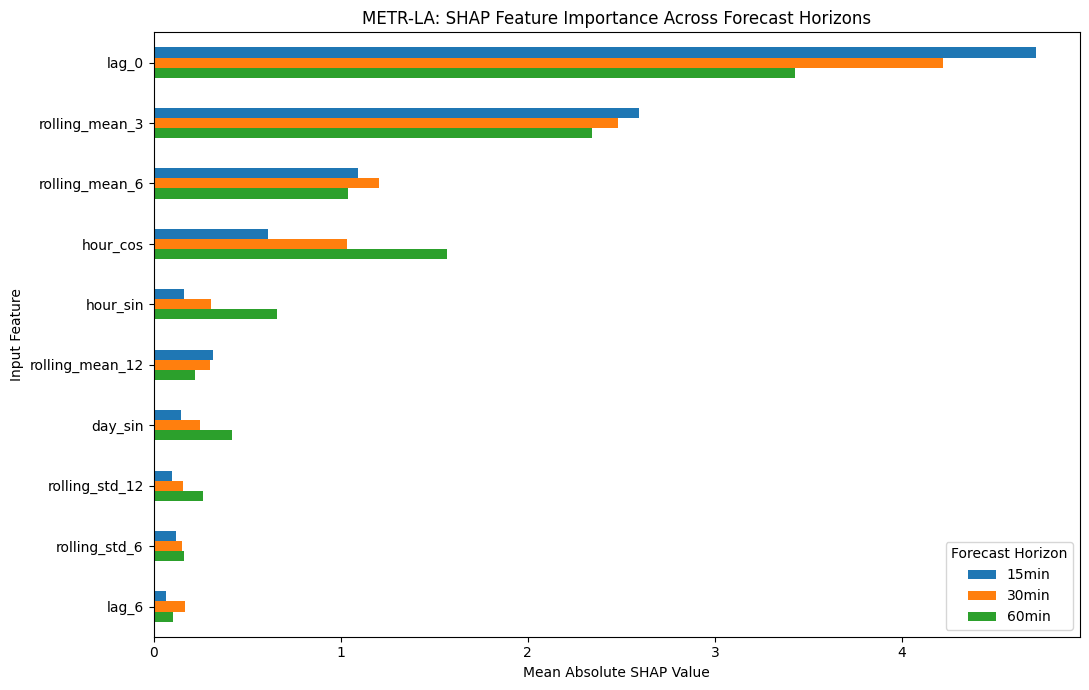


SHAP analysis completed!
Saved graph: /content/traffic_models/shap_results/metr_la_shap_horizon_comparison.png
Saved results in: /content/traffic_models/shap_results


In [34]:

# ==========================================================
# METR-LA SHAP EXPLAINABILITY ANALYSIS
# 207 sensors | 15, 30, 60 minutes
# Explains XGBoost branch, not complete hybrid
# ==========================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

MODEL_DIR = "/content/traffic_models/full_network"
OUTPUT_DIR = "/content/traffic_models/shap_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify original training feature order
with open(
    os.path.join(MODEL_DIR, "metadata_15min.json")
) as f:
    original_features = json.load(f)["features"]

assert list(feature_cols) == list(original_features)

HORIZONS = {
    3: "15min",
    6: "30min",
    12: "60min"
}

# Reproducible sample
rng = np.random.default_rng(42)

all_importances = []

for horizon, name in HORIZONS.items():

    print("\n" + "=" * 50)
    print(f"SHAP ANALYSIS — {name}")
    print("=" * 50)

    model = joblib.load(
        os.path.join(
            MODEL_DIR,
            f"hybrid_base_xgboost_{name}.pkl"
        )
    )

    # Validation observations, not test.
    # Use one sensor-balanced subset for explanations.
    frames = []

    for sensor_id in clean_full.columns:

        data = build_sensor_features(sensor_id)

        target_time = (
            data.index
            + pd.Timedelta(minutes=5 * horizon)
        )

        valid_target = data[
            f"valid_target_{horizon}"
        ].to_numpy(dtype=bool)

        mask = np.asarray(
            (target_time >= train_boundary)
            & (target_time < val_boundary)
            & valid_target
        )

        eligible = data.loc[
            mask, feature_cols
        ]

        # Up to 5 samples per sensor
        if len(eligible) > 0:

            sample_n = min(5, len(eligible))

            sample_indices = rng.choice(
                len(eligible),
                size=sample_n,
                replace=False
            )

            frames.append(
                eligible.iloc[sample_indices]
            )

    X_sample = pd.concat(
        frames,
        ignore_index=True
    ).astype(np.float32)

    print("SHAP samples:", len(X_sample))

    # Tree-based SHAP
    explainer = shap.TreeExplainer(model)

    shap_values = explainer.shap_values(
        X_sample.to_numpy()
    )

    mean_importance = np.mean(
        np.abs(shap_values),
        axis=0
    )

    for feature, importance in zip(
        feature_cols,
        mean_importance
    ):

        all_importances.append({
            "Horizon": name,
            "Feature": feature,
            "Mean absolute SHAP": float(importance)
        })

    ranking = pd.DataFrame({
        "Feature": feature_cols,
        "Mean absolute SHAP": mean_importance
    }).sort_values(
        "Mean absolute SHAP",
        ascending=False
    )

    print("\nTOP 10 FEATURES")
    display(ranking.head(10).round(4))

    # Save each horizon's SHAP values
    ranking.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"shap_importance_{name}.csv"
        ),
        index=False
    )

# ==========================================================
# COMPARISON ACROSS HORIZONS
# ==========================================================

shap_df = pd.DataFrame(all_importances)

comparison = shap_df.pivot(
    index="Feature",
    columns="Horizon",
    values="Mean absolute SHAP"
)

comparison = comparison[
    ["15min", "30min", "60min"]
]

comparison["Overall"] = comparison.mean(axis=1)

comparison = comparison.sort_values(
    "Overall",
    ascending=False
)

print("\n" + "=" * 50)
print("SHAP COMPARISON ACROSS HORIZONS")
print("=" * 50)

display(comparison.head(15).round(4))

# ==========================================================
# PUBLICATION GRAPH
# ==========================================================

top_features = comparison.head(10).index

plot_data = comparison.loc[
    top_features,
    ["15min", "30min", "60min"]
]

ax = plot_data.plot(
    kind="barh",
    figsize=(11, 7)
)

ax.invert_yaxis()

plt.title(
    "METR-LA: SHAP Feature Importance Across Forecast Horizons"
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Input Feature")
plt.legend(title="Forecast Horizon")
plt.tight_layout()

plot_path = os.path.join(
    OUTPUT_DIR,
    "metr_la_shap_horizon_comparison.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save combined results
comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "metr_la_shap_comparison.csv"
    )
)

print("\nSHAP analysis completed!")
print("Saved graph:", plot_path)
print("Saved results in:", OUTPUT_DIR)


In [35]:

import os
import shutil
import zipfile
from google.colab import files

source_dir = "/content/traffic_models/shap_results"
zip_path = "/content/METR_LA_SHAP_Results.zip"

required_files = [
    "shap_importance_15min.csv",
    "shap_importance_30min.csv",
    "shap_importance_60min.csv",
    "metr_la_shap_comparison.csv",
    "metr_la_shap_horizon_comparison.png"
]

for filename in required_files:
    path = os.path.join(source_dir, filename)
    assert os.path.isfile(path), f"Missing: {filename}"

shutil.make_archive(
    zip_path.removesuffix(".zip"),
    "zip",
    root_dir="/content/traffic_models",
    base_dir="shap_results"
)

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None

    print("SHAP BACKUP CONTENTS")
    print("=" * 45)

    for name in archive.namelist():
        print(name)

print("\nBackup size:",
      round(os.path.getsize(zip_path) / 1024, 2),
      "KB")

files.download(zip_path)


SHAP BACKUP CONTENTS
shap_results/
shap_results/shap_importance_15min.csv
shap_results/shap_importance_60min.csv
shap_results/metr_la_shap_horizon_comparison.png
shap_results/shap_importance_30min.csv
shap_results/metr_la_shap_comparison.csv

Backup size: 103.3 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

import os
import urllib.request
import pandas as pd

url = (
    "https://github.com/liyaguang/DCRNN/raw/"
    "master/data/sensor_graph/adj_mx_bay.pkl"
)

print("PEMS-BAY DATASET SETUP")
print("=" * 45)

print(
    "Before model training, we need the "
    "PEMS-BAY traffic speed file: pems-bay.h5"
)

print("\nDataset reference:")
print(
    "https://github.com/liyaguang/DCRNN"
)

print("\nChecking local files:")

candidates = [
    "/content/pems-bay.h5",
    "/content/PEMS-BAY/pems-bay.h5",
    "/content/data/pems-bay.h5"
]

found = [
    path for path in candidates
    if os.path.isfile(path)
]

if found:
    pems_df = pd.read_hdf(found[0])

    print("Dataset found:", found[0])
    print("Shape:", pems_df.shape)
    print("First timestamp:", pems_df.index.min())
    print("Last timestamp:", pems_df.index.max())
else:
    print("PEMS-BAY dataset not found locally.")
    print("Please download or upload pems-bay.h5.")

print("\nSetup check completed.")


PEMS-BAY DATASET SETUP
Before model training, we need the PEMS-BAY traffic speed file: pems-bay.h5

Dataset reference:
https://github.com/liyaguang/DCRNN

Checking local files:
PEMS-BAY dataset not found locally.
Please download or upload pems-bay.h5.

Setup check completed.


In [37]:

import os
import pandas as pd

print("DOWNLOADING PEMS-BAY DIRECTLY TO COLAB")
print("=" * 50)

url = (
    "https://huggingface.co/datasets/"
    "MintBruce/SkyTraffic/resolve/main/pems-bay.h5"
)

output_path = "/content/pems-bay.h5"

# Download directly to Colab's temporary storage
# No Google Drive space is used.
!wget -c --show-progress -O /content/pems-bay.h5 "https://huggingface.co/datasets/MintBruce/SkyTraffic/resolve/main/pems-bay.h5"

# Verify the downloaded dataset
pems_df = pd.read_hdf(output_path)

assert pems_df.shape[1] == 325

print("\nPEMS-BAY DATASET LOADED")
print("=" * 50)

print("Shape:", pems_df.shape)
print("Sensors:", pems_df.shape[1])
print("First timestamp:", pems_df.index.min())
print("Last timestamp:", pems_df.index.max())

print("\nMissing values:",
      int(pems_df.isna().sum().sum()))

print("Zero readings:",
      int((pems_df == 0).sum().sum()))

print("\nDataset ready for preprocessing!")


DOWNLOADING PEMS-BAY DIRECTLY TO COLAB
--2026-10-14 04:54:45--  https://huggingface.co/datasets/MintBruce/SkyTraffic/resolve/main/pems-bay.h5
Resolving huggingface.co (huggingface.co)... 108.138.94.27, 108.138.94.45, 108.138.94.97, ...
Connecting to huggingface.co (huggingface.co)|108.138.94.27|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/69e7250e65e6309bc12f8f3b/d69b6204c4ef318967204331109fcc93adbba171d4e1762cf68a3364cd452120?user_id=public&xip=c68QrkgbIVg&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27pems-bay.h5%3B+filename%3D%22pems-bay.h5%22%3B&X-Xet-Cas-Uid=public&Expires=1791957285&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjllNzI1MGU2NWU2MzA5YmMxMmY4ZjNiL2Q2OWI2MjA0YzRlZjMxODk2NzIwNDMzMTEwOWZjYzkzYWRiYmExNzFkNGUxNzYyY2Y2OGEzMzY0Y2Q0NTIxMjBcXD91c2VyX2lkPXB1YmxpYyZ4aXA9YzY4UXJrZ2JJVmcmcmVzcG9uc2UtY29udGVudC1kaXNwb3NpdGlvbj0qJlgtWGV0LUNhcy1Va

In [38]:

# ============================================================
# PEMS-BAY COMPLETE RESEARCH IMPLEMENTATION
#
# XGBoost + LSTM + Hybrid Fusion
# 325 Traffic Sensors
# 15 / 30 / 60 Minute Forecasting
#
# Preprocessing -> Training -> Evaluation -> Save Models
#
# NO GOOGLE DRIVE REQUIRED
# ============================================================

import os
import gc
import json
import time
import copy
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib

from xgboost import XGBRegressor
from torch.utils.data import TensorDataset, DataLoader
from google.colab import files

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Run all three horizons.
# Completed horizons are skipped if all files exist.
HORIZONS = {
    3: "15min",
    6: "30min",
    12: "60min"
}

SEQUENCE_LENGTH = 12
LSTM_HIDDEN = 64

LSTM_EPOCHS = 5
FUSION_EPOCHS = 25

LSTM_BATCH = 2048
FUSION_BATCH = 4096
INFERENCE_BATCH = 8192

SAVE_DIR = "/content/traffic_models/pems_bay"
os.makedirs(SAVE_DIR, exist_ok=True)

# Download models after all horizons.
DOWNLOAD_BACKUP = True

# Experimental assumption:
# Treat exact zero speeds as invalid/missing.
# Must be documented and sensitivity-tested later.
ZERO_AS_MISSING = True

print("=" * 65)
print("PEMS-BAY HYBRID FORECASTING FRAMEWORK")
print("=" * 65)
print("Device:", DEVICE)
print("Forecast horizons:", list(HORIZONS.values()))
print("Zero-as-missing assumption:", ZERO_AS_MISSING)


# ============================================================
# 2. LOAD PEMS-BAY
# ============================================================

DATA_PATH = "/content/pems-bay.h5"

if not os.path.isfile(DATA_PATH):

    print("\nDataset missing. Upload pems-bay.h5.")

    uploaded = files.upload()

    h5_files = [
        name for name in uploaded
        if name.lower().endswith((".h5", ".hdf5"))
    ]

    if not h5_files:
        raise FileNotFoundError(
            "Please upload pems-bay.h5"
        )

    DATA_PATH = h5_files[0]

pems_raw = pd.read_hdf(
    DATA_PATH
).astype(np.float32)

assert pems_raw.shape[1] == 325
assert pems_raw.index.is_monotonic_increasing
assert pems_raw.index.is_unique

print("\nDATASET INFORMATION")
print("-" * 50)
print("Shape:", pems_raw.shape)
print("First timestamp:", pems_raw.index.min())
print("Last timestamp:", pems_raw.index.max())

n_timestamps = len(pems_raw)

n_train_end = int(n_timestamps * 0.70)
n_val_end = int(n_timestamps * 0.80)
n_base_end = int(n_train_end * 0.70)

TRAIN_BOUNDARY = pems_raw.index[n_train_end]
VAL_BOUNDARY = pems_raw.index[n_val_end]
BASE_CUTOFF = pems_raw.index[n_base_end]

assert BASE_CUTOFF < TRAIN_BOUNDARY < VAL_BOUNDARY

print("\nCHRONOLOGICAL SPLITS")
print("-" * 50)
print("Base cutoff:", BASE_CUTOFF)
print("Train boundary:", TRAIN_BOUNDARY)
print("Validation boundary:", VAL_BOUNDARY)
print("Test starts:", VAL_BOUNDARY)


# ============================================================
# 3. DATA QUALITY AUDIT
# ============================================================

zero_count = int(
    (pems_raw == 0).sum().sum()
)

nan_count = int(
    pems_raw.isna().sum().sum()
)

time_diff = (
    pems_raw.index.to_series()
    .diff()
    .dropna()
)

irregular = int(
    (time_diff != pd.Timedelta(minutes=5)).sum()
)

print("\nDATA QUALITY")
print("-" * 50)
print("Zero readings:", zero_count)
print("NaN readings:", nan_count)
print(
    "Zero percentage:",
    round(100 * zero_count / pems_raw.size, 5),
    "%"
)
print("Irregular time intervals:", irregular)

if irregular != 0:
    raise ValueError(
        "Timestamps are not uniformly 5 minutes apart."
    )

raw_array = pems_raw.to_numpy(copy=False)

# Keep validity masks for original targets.
# Future target readings must be originally observed.
original_valid = np.isfinite(raw_array)

if ZERO_AS_MISSING:
    original_valid &= (raw_array != 0)

# ============================================================
# 4. LEAKAGE-CONTROLLED PREPROCESSING
# ============================================================

# Only the earlier BASE period supplies fallback statistics.
# No validation or test values enter median fitting.

missing_df = pems_raw.mask(
    ~original_valid
)

base_missing = missing_df.iloc[:n_base_end]

sensor_medians = base_missing.median()

global_median = float(
    base_missing.stack().median()
)

fallback = sensor_medians.fillna(
    global_median
)

# Causal forward-fill, maximum 6 previous steps.
clean_df = (
    missing_df
    .ffill(limit=6)
    .fillna(fallback)
    .astype(np.float32)
)

assert np.isfinite(
    clean_df.to_numpy()
).all()

clean_values = clean_df.to_numpy(
    dtype=np.float32,
    copy=False
)

timestamps = clean_df.index

print("\nCLEANING COMPLETED")
print("-" * 50)
print("Cleaned shape:", clean_df.shape)
print("Remaining missing:", int(clean_df.isna().sum().sum()))
print("Median source: BASE TRAINING PERIOD ONLY")


# ============================================================
# 5. ORIGINAL 24-FEATURE ORDER FROM METR-LA
# ============================================================

# CRITICAL:
# Rolling mean and std ALTERNATE.
# This avoids our earlier feature-order bug.

FEATURE_COLS = [
    f"lag_{i}" for i in range(12)
] + [
    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_12",
    "rolling_std_12",
    "trend_3",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "weekend"
]

assert len(FEATURE_COLS) == 24

LAG_INDICES = [
    FEATURE_COLS.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

print("\nFEATURE ORDER VERIFIED:", len(FEATURE_COLS))


# ============================================================
# 6. BUILD SENSOR FEATURES
# ============================================================

# Precompute calendar features once.
hour_value = (
    timestamps.hour.to_numpy()
    + timestamps.minute.to_numpy() / 60.0
)

day_value = timestamps.dayofweek.to_numpy()

calendar_features = {
    "hour_sin": np.sin(2*np.pi*hour_value/24),
    "hour_cos": np.cos(2*np.pi*hour_value/24),
    "day_sin": np.sin(2*np.pi*day_value/7),
    "day_cos": np.cos(2*np.pi*day_value/7),
    "weekend": (day_value >= 5).astype(np.float32)
}


def build_sensor_data(sensor_index):

    speeds = pd.Series(
        clean_values[:, sensor_index],
        index=timestamps
    )

    data = pd.DataFrame(index=timestamps)

    for lag in range(12):
        data[f"lag_{lag}"] = speeds.shift(lag)

    for window in [3, 6, 12]:

        rolling = speeds.rolling(window)

        data[f"rolling_mean_{window}"] = (
            rolling.mean()
        )

        data[f"rolling_std_{window}"] = (
            rolling.std()
        )

    data["trend_3"] = speeds - speeds.shift(3)

    for name, values in calendar_features.items():
        data[name] = values

    return data


# ============================================================
# 7. CREATE CHRONOLOGICAL DATASET PER HORIZON
# ============================================================

# We only hold the current horizon in memory.
# Outputs are in sensor-major order, but split masks
# use actual target timestamps rather than row position.


def prepare_horizon_data(horizon):

    print("\nPreparing sensor features...", flush=True)

    base_X_parts, base_y_parts = [], []
    fusion_X_parts, fusion_y_parts = [], []
    val_X_parts, val_y_parts = [], []
    test_X_parts, test_y_parts = [], []

    # Conservative gap between base targets
    # and fusion prediction origins.
    fusion_start = BASE_CUTOFF + pd.Timedelta(
        minutes=5*(SEQUENCE_LENGTH + horizon)
    )

    for sensor_index in range(clean_values.shape[1]):

        data = build_sensor_data(sensor_index)

        target = pd.Series(
            clean_values[:, sensor_index],
            index=timestamps
        ).shift(-horizon)

        target_time = (
            timestamps
            + pd.Timedelta(minutes=5*horizon)
        )

        target_valid = np.zeros(
            n_timestamps,
            dtype=bool
        )

        target_valid[:-horizon] = (
            original_valid[horizon:, sensor_index]
        )

        # The first 11 rows do not have all lag features.
        # Last horizon rows have no future target.
        usable = np.zeros(n_timestamps, dtype=bool)
        usable[11:n_timestamps-horizon] = True
        usable &= target_valid

        base_mask = (
            usable
            & (target_time < BASE_CUTOFF)
        )

        fusion_mask = (
            usable
            & (timestamps >= fusion_start)
            & (target_time < TRAIN_BOUNDARY)
        )

        val_mask = (
            usable
            & (target_time >= TRAIN_BOUNDARY)
            & (target_time < VAL_BOUNDARY)
        )

        test_mask = (
            usable
            & (target_time >= VAL_BOUNDARY)
        )

        X_np = data[FEATURE_COLS].to_numpy(
            dtype=np.float32
        )

        y_np = target.to_numpy(
            dtype=np.float32
        )

        base_X_parts.append(X_np[base_mask])
        base_y_parts.append(y_np[base_mask])

        fusion_X_parts.append(X_np[fusion_mask])
        fusion_y_parts.append(y_np[fusion_mask])

        val_X_parts.append(X_np[val_mask])
        val_y_parts.append(y_np[val_mask])

        test_X_parts.append(X_np[test_mask])
        test_y_parts.append(y_np[test_mask])

        if (sensor_index + 1) % 65 == 0:
            print(
                "Processed sensors:",
                sensor_index + 1,
                "/325",
                flush=True
            )

        del data, X_np, y_np

    def combine(X_parts, y_parts):
        return (
            np.concatenate(X_parts, axis=0),
            np.concatenate(y_parts, axis=0)
        )

    result = {
        "base": combine(base_X_parts, base_y_parts),
        "fusion": combine(fusion_X_parts, fusion_y_parts),
        "val": combine(val_X_parts, val_y_parts),
        "test": combine(test_X_parts, test_y_parts),
        "fusion_start": str(fusion_start)
    }

    for split in ["base", "fusion", "val", "test"]:
        X, y = result[split]

        assert X.shape[1] == 24
        assert len(X) == len(y)
        assert np.isfinite(X).all()
        assert np.isfinite(y).all()

        print(
            split.upper(),
            "samples:",
            len(y)
        )

    return result


# ============================================================
# 8. MODEL ARCHITECTURES
# ============================================================

class TrafficLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=LSTM_HIDDEN,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(
            LSTM_HIDDEN, 1
        )

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(
            output[:, -1, :]
        ).squeeze(-1)


class HybridFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


# ============================================================
# 9. METRICS
# ============================================================

def evaluate(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=np.float32)
    y_pred = np.asarray(y_pred, dtype=np.float32)

    error = y_true - y_pred

    mae = float(
        np.mean(np.abs(error), dtype=np.float64)
    )

    rmse = float(
        np.sqrt(np.mean(error**2, dtype=np.float64))
    )

    nonzero = np.abs(y_true) > 1e-6

    mape = float(
        100 * np.mean(
            np.abs(error[nonzero] / y_true[nonzero]),
            dtype=np.float64
        )
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


# ============================================================
# 10. BASE LSTM TRAINING
# ============================================================

def train_lstm(X_base, y_base, stats):

    X_seq = X_base[:, LAG_INDICES].copy()

    X_seq -= stats["input_mean"]
    X_seq /= stats["input_std"]

    X_seq = X_seq.reshape(-1, 12, 1)

    y_seq = (
        (y_base - stats["target_mean"])
        / stats["target_std"]
    ).astype(np.float32)

    dataset = TensorDataset(
        torch.from_numpy(X_seq),
        torch.from_numpy(y_seq)
    )

    loader = DataLoader(
        dataset,
        batch_size=LSTM_BATCH,
        shuffle=True,
        num_workers=0
    )

    model = TrafficLSTM().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_fn = nn.MSELoss()

    start_time = time.time()

    for epoch in range(LSTM_EPOCHS):

        model.train()
        total = 0.0

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            pred = model(xb)

            loss = loss_fn(pred, yb)

            loss.backward()
            optimizer.step()

            total += loss.item()*len(xb)

        print(
            f"LSTM Epoch {epoch+1}/{LSTM_EPOCHS}",
            "Loss:",
            round(total/len(dataset), 5),
            flush=True
        )

    print(
        "LSTM training seconds:",
        round(time.time()-start_time, 2)
    )

    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad_(False)

    del dataset, loader, X_seq, y_seq
    gc.collect()

    return model


# ============================================================
# 11. BATCHED XGBOOST PREDICTIONS
# ============================================================

def predict_xgb(model, X, batch_size=100000):

    predictions = np.empty(
        len(X),
        dtype=np.float32
    )

    for start in range(0, len(X), batch_size):

        end = min(start+batch_size, len(X))

        predictions[start:end] = model.predict(
            X[start:end]
        )

    return predictions


# ============================================================
# 12. LSTM FEATURE EXTRACTION
# ============================================================

def make_fusion_features(
    X, xgb_preds, lstm, stats
):

    n = len(X)

    features = np.empty(
        (n, 65),
        dtype=np.float32
    )

    lstm.eval()

    with torch.inference_mode():

        for start in range(
            0, n, INFERENCE_BATCH
        ):

            end = min(start+INFERENCE_BATCH, n)

            seq = X[
                start:end, LAG_INDICES
            ].copy()

            seq -= stats["input_mean"]
            seq /= stats["input_std"]

            tensor = torch.from_numpy(
                seq.reshape(-1,12,1)
            ).to(DEVICE)

            output, _ = lstm.lstm(tensor)

            features[start:end, :64] = (
                output[:, -1, :]
                .cpu()
                .numpy()
            )

            features[start:end, 64] = (
                (xgb_preds[start:end]
                 - stats["target_mean"])
                / stats["target_std"]
            )

    return features


# ============================================================
# 13. TRAIN FUSION MODEL
# ============================================================

def train_fusion(X_fusion, y_fusion,
                 X_val, y_val):

    train_data = TensorDataset(
        torch.from_numpy(X_fusion),
        torch.from_numpy(y_fusion)
    )

    val_data = TensorDataset(
        torch.from_numpy(X_val),
        torch.from_numpy(y_val)
    )

    train_loader = DataLoader(
        train_data,
        batch_size=FUSION_BATCH,
        shuffle=True
    )

    val_loader = DataLoader(
        val_data,
        batch_size=INFERENCE_BATCH,
        shuffle=False
    )

    model = HybridFusion().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_fn = nn.MSELoss()

    best_loss = float("inf")
    best_state = None
    best_epoch = 0

    patience = 5
    wait = 0

    for epoch in range(FUSION_EPOCHS):

        model.train()
        total_train = 0.0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            pred = model(xb)
            loss = loss_fn(pred, yb)

            loss.backward()
            optimizer.step()

            total_train += loss.item()*len(xb)

        model.eval()

        total_val = 0.0

        with torch.inference_mode():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                pred = model(xb)
                loss = loss_fn(pred, yb)

                total_val += loss.item()*len(xb)

        train_loss = total_train/len(train_data)
        val_loss = total_val/len(val_data)

        print(
            f"Fusion Epoch {epoch+1:02d}",
            f"Train={train_loss:.5f}",
            f"Val={val_loss:.5f}",
            flush=True
        )

        if val_loss < best_loss - 1e-5:

            best_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch+1
            wait = 0

        else:
            wait += 1

            if wait >= patience:
                print("Fusion early stopping.")
                break

    model.load_state_dict(best_state)
    model.eval()

    return model, best_epoch


# ============================================================
# 14. BATCHED LSTM + HYBRID PREDICTION
# ============================================================

def predict_lstm_hybrid(
    X, xgb_preds, lstm, fusion, stats
):

    n = len(X)

    lstm_preds = np.empty(
        n,
        dtype=np.float32
    )

    hybrid_preds = np.empty(
        n,
        dtype=np.float32
    )

    lstm.eval()
    fusion.eval()

    with torch.inference_mode():

        for start in range(
            0, n, INFERENCE_BATCH
        ):

            end = min(start+INFERENCE_BATCH, n)

            sequences = X[
                start:end, LAG_INDICES
            ].copy()

            sequences -= stats["input_mean"]
            sequences /= stats["input_std"]

            tensor = torch.from_numpy(
                sequences.reshape(-1, 12, 1)
            ).to(DEVICE)

            output, _ = lstm.lstm(tensor)

            hidden = output[:, -1, :]

            lstm_normalized = (
                lstm.fc(hidden).squeeze(-1)
            )

            xgb_norm = (
                (xgb_preds[start:end]
                 - stats["target_mean"])
                / stats["target_std"]
            ).astype(np.float32)

            xgb_tensor = torch.from_numpy(
                xgb_norm
            ).to(DEVICE).unsqueeze(1)

            fusion_input = torch.cat(
                [hidden, xgb_tensor],
                dim=1
            )

            hybrid_normalized = fusion(
                fusion_input
            )

            lstm_preds[start:end] = (
                lstm_normalized.cpu().numpy()
                * stats["target_std"]
                + stats["target_mean"]
            )

            hybrid_preds[start:end] = (
                hybrid_normalized.cpu().numpy()
                * stats["target_std"]
                + stats["target_mean"]
            )

    return lstm_preds, hybrid_preds


# ============================================================
# 15. SAVE EXPERIMENT RESULTS
# ============================================================

def save_json(path, data):

    with open(path, "w") as f:
        json.dump(data, f, indent=4)


all_results = []

# ============================================================
# 16. COMPLETE MULTI-HORIZON EXPERIMENT
# ============================================================

for horizon, name in HORIZONS.items():

    print("\n" + "="*65)
    print("STARTING PEMS-BAY:", name)
    print("="*65, flush=True)

    result_path = os.path.join(
        SAVE_DIR,
        f"results_{name}.json"
    )

    xgb_path = os.path.join(
        SAVE_DIR,
        f"xgboost_{name}.pkl"
    )

    lstm_path = os.path.join(
        SAVE_DIR,
        f"lstm_{name}.pth"
    )

    fusion_path = os.path.join(
        SAVE_DIR,
        f"hybrid_{name}.pth"
    )

    metadata_path = os.path.join(
        SAVE_DIR,
        f"metadata_{name}.json"
    )

    expected_files = [
        result_path, xgb_path,
        lstm_path, fusion_path,
        metadata_path
    ]

    # Allows resume after interruption,
    # provided saved files remain in Colab.
    if all(os.path.isfile(p) for p in expected_files):

        print("Completed files detected; skipping.")

        with open(result_path) as f:
            stored = json.load(f)

        all_results.extend(stored["metrics"])
        continue

    start_time = time.time()

    # --------------------------------------------------------
    # A. Prepare data
    # --------------------------------------------------------

    dataset = prepare_horizon_data(horizon)

    X_base, y_base = dataset["base"]
    X_fusion_raw, y_fusion_raw = dataset["fusion"]
    X_val, y_val = dataset["val"]
    X_test, y_test = dataset["test"]

    # --------------------------------------------------------
    # B. Base-only normalization
    # --------------------------------------------------------

    base_lags = X_base[:, LAG_INDICES]

    stats = {
        "input_mean": float(base_lags.mean()),
        "input_std": float(base_lags.std())+1e-6,
        "target_mean": float(y_base.mean()),
        "target_std": float(y_base.std())+1e-6
    }

    del base_lags

    # --------------------------------------------------------
    # C. Train XGBoost
    # --------------------------------------------------------

    print("\nTraining XGBoost...", flush=True)

    xgb = XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        objective="reg:squarederror",
        eval_metric="mae",
        n_jobs=2,
        random_state=SEED
    )

    xgb.fit(X_base, y_base)

    # Save immediately
    joblib.dump(xgb, xgb_path)

    print("XGBoost saved.")

    # --------------------------------------------------------
    # D. Train LSTM
    # --------------------------------------------------------

    print("\nTraining base LSTM...", flush=True)

    lstm = train_lstm(
        X_base, y_base, stats
    )

    torch.save(
        lstm.state_dict(),
        lstm_path
    )

    print("LSTM saved.")

    # Free base-training arrays
    del X_base, y_base
    gc.collect()

    # --------------------------------------------------------
    # E. Generate fusion features
    # --------------------------------------------------------

    print(
        "\nGenerating fusion-training features...",
        flush=True
    )

    fusion_xgb_preds = predict_xgb(
        xgb, X_fusion_raw
    )

    X_fusion = make_fusion_features(
        X_fusion_raw,
        fusion_xgb_preds,
        lstm,
        stats
    )

    y_fusion = (
        (y_fusion_raw-stats["target_mean"])
        / stats["target_std"]
    ).astype(np.float32)

    del X_fusion_raw, y_fusion_raw
    del fusion_xgb_preds
    gc.collect()

    # --------------------------------------------------------
    # F. Validation features
    # --------------------------------------------------------

    print(
        "Generating validation features...",
        flush=True
    )

    xgb_val_preds = predict_xgb(
        xgb, X_val
    )

    X_fusion_val = make_fusion_features(
        X_val,
        xgb_val_preds,
        lstm,
        stats
    )

    y_fusion_val = (
        (y_val-stats["target_mean"])
        / stats["target_std"]
    ).astype(np.float32)

    # --------------------------------------------------------
    # G. Train fusion
    # --------------------------------------------------------

    print("\nTraining hybrid fusion...", flush=True)

    fusion, best_epoch = train_fusion(
        X_fusion,
        y_fusion,
        X_fusion_val,
        y_fusion_val
    )

    torch.save(
        fusion.state_dict(),
        fusion_path
    )

    print("Fusion model saved.")

    del X_fusion, X_fusion_val
    del y_fusion, y_fusion_val
    gc.collect()

    # --------------------------------------------------------
    # H. Validation results
    # --------------------------------------------------------

    print("\nVALIDATION RESULTS", flush=True)

    lstm_val_preds, hybrid_val_preds = (
        predict_lstm_hybrid(
            X_val,
            xgb_val_preds,
            lstm,
            fusion,
            stats
        )
    )

    val_predictions = {
        "Persistence": X_val[:, FEATURE_COLS.index("lag_0")],
        "XGBoost": xgb_val_preds,
        "LSTM": lstm_val_preds,
        "Hybrid": hybrid_val_preds
    }

    horizon_metrics = []

    for model_name, prediction in val_predictions.items():

        metrics = evaluate(y_val, prediction)

        record = {
            "Dataset": "PEMS-BAY",
            "Split": "Validation",
            "Horizon": name,
            "Model": model_name,
            "Samples": int(len(y_val)),
            **metrics
        }

        horizon_metrics.append(record)

        print(
            f"{model_name:12s}",
            f"MAE={metrics['MAE']:.4f}",
            f"RMSE={metrics['RMSE']:.4f}",
            f"MAPE={metrics['MAPE (%)']:.4f}%"
        )

    del xgb_val_preds, lstm_val_preds
    del hybrid_val_preds
    gc.collect()

    # --------------------------------------------------------
    # I. TEST SET: untouched until model selection completes
    # --------------------------------------------------------

    print("\nINDEPENDENT TEST RESULTS", flush=True)

    xgb_test_preds = predict_xgb(
        xgb, X_test
    )

    lstm_test_preds, hybrid_test_preds = (
        predict_lstm_hybrid(
            X_test,
            xgb_test_preds,
            lstm,
            fusion,
            stats
        )
    )

    test_predictions = {
        "Persistence": X_test[:, FEATURE_COLS.index("lag_0")],
        "XGBoost": xgb_test_preds,
        "LSTM": lstm_test_preds,
        "Hybrid": hybrid_test_preds
    }

    for model_name, prediction in test_predictions.items():

        metrics = evaluate(y_test, prediction)

        record = {
            "Dataset": "PEMS-BAY",
            "Split": "Test",
            "Horizon": name,
            "Model": model_name,
            "Samples": int(len(y_test)),
            **metrics
        }

        horizon_metrics.append(record)

        print(
            f"{model_name:12s}",
            f"MAE={metrics['MAE']:.4f}",
            f"RMSE={metrics['RMSE']:.4f}",
            f"MAPE={metrics['MAPE (%)']:.4f}%"
        )

    # --------------------------------------------------------
    # J. SAVE METADATA AND METRICS
    # --------------------------------------------------------

    metadata = {
        "dataset": "PEMS-BAY",
        "sensors": 325,
        "horizon_minutes": int(horizon*5),
        "feature_names": FEATURE_COLS,
        "sequence_length": SEQUENCE_LENGTH,
        "hidden_size": LSTM_HIDDEN,
        "zero_as_missing": ZERO_AS_MISSING,
        "forward_fill_limit": 6,
        "median_fitted_until": str(BASE_CUTOFF),
        "train_boundary": str(TRAIN_BOUNDARY),
        "validation_boundary": str(VAL_BOUNDARY),
        "fusion_start": dataset["fusion_start"],
        "base_samples": int(len(dataset["base"][1])),
        "fusion_samples": int(len(dataset["fusion"][1])),
        "validation_samples": int(len(y_val)),
        "test_samples": int(len(y_test)),
        "best_fusion_epoch": int(best_epoch),
        **stats
    }

    save_json(metadata_path, metadata)

    save_json(
        result_path,
        {
            "metadata": metadata,
            "metrics": horizon_metrics
        }
    )

    all_results.extend(horizon_metrics)

    # Save interim combined results
    pd.DataFrame(all_results).to_csv(
        os.path.join(
            SAVE_DIR,
            "pems_bay_all_results.csv"
        ),
        index=False
    )

    # --------------------------------------------------------
    # K. RELEASE MEMORY
    # --------------------------------------------------------

    del dataset
    del X_val, y_val, X_test, y_test
    del xgb, lstm, fusion
    del xgb_test_preds, lstm_test_preds
    del hybrid_test_preds

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    elapsed = (
        time.time()-start_time
    ) / 60

    print(
        f"\n{name} COMPLETED in "
        f"{elapsed:.2f} minutes",
        flush=True
    )


# ============================================================
# 17. FINAL RESULTS
# ============================================================

results_df = pd.DataFrame(all_results)

print("\n" + "="*65)
print("PEMS-BAY COMPLETE EXPERIMENT RESULTS")
print("="*65)

display(
    results_df.round(4)
)

print("\nTEST MAE COMPARISON")

test_only = results_df[
    results_df["Split"] == "Test"
]

display(
    test_only.pivot(
        index="Horizon",
        columns="Model",
        values="MAE"
    ).round(4)
)

print("\nTEST RMSE COMPARISON")

display(
    test_only.pivot(
        index="Horizon",
        columns="Model",
        values="RMSE"
    ).round(4)
)

results_path = os.path.join(
    SAVE_DIR,
    "pems_bay_all_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)


# ============================================================
# 18. BACKUP ALL MODELS + RESULTS
# ============================================================

backup_path = "/content/PEMS_BAY_Full_Experiment_Backup.zip"

shutil.make_archive(
    backup_path.removesuffix(".zip"),
    "zip",
    root_dir="/content/traffic_models",
    base_dir="pems_bay"
)

print("\nBACKUP CREATED")
print("="*50)
print("Path:", backup_path)
print(
    "Size:",
    round(os.path.getsize(backup_path)/1024**2, 2),
    "MB"
)

print("\nSaved files:")

for filename in sorted(os.listdir(SAVE_DIR)):
    print(filename)

if DOWNLOAD_BACKUP:
    files.download(backup_path)

print("\nPEMS-BAY PIPELINE COMPLETED SUCCESSFULLY!")


PEMS-BAY HYBRID FORECASTING FRAMEWORK
Device: cpu
Forecast horizons: ['15min', '30min', '60min']
Zero-as-missing assumption: True

DATASET INFORMATION
--------------------------------------------------
Shape: (52116, 325)
First timestamp: 2017-01-01 00:00:00
Last timestamp: 2017-06-30 23:55:00

CHRONOLOGICAL SPLITS
--------------------------------------------------
Base cutoff: 2017-03-30 17:00:00
Train boundary: 2017-05-07 17:05:00
Validation boundary: 2017-05-25 19:20:00
Test starts: 2017-05-25 19:20:00

DATA QUALITY
--------------------------------------------------
Zero readings: 521
NaN readings: 0
Zero percentage: 0.00308 %
Irregular time intervals: 1


ValueError: Timestamps are not uniformly 5 minutes apart.

In [39]:

import pandas as pd
import numpy as np

print("PEMS-BAY TIMESTAMP DIAGNOSTIC")
print("=" * 55)

# Identify irregular intervals
time_diffs = pems_raw.index.to_series().diff()

irregular_mask = (
    time_diffs.notna()
    & (time_diffs != pd.Timedelta(minutes=5))
)

irregular_positions = np.flatnonzero(
    irregular_mask.to_numpy()
)

print("Irregular intervals:", len(irregular_positions))

for pos in irregular_positions:
    previous_time = pems_raw.index[pos - 1]
    current_time = pems_raw.index[pos]

    print("\nPrevious timestamp:", previous_time)
    print("Current timestamp:", current_time)
    print("Actual interval:", current_time - previous_time)

# Inspect expected timeline
expected_index = pd.date_range(
    start=pems_raw.index[0],
    end=pems_raw.index[-1],
    freq="5min"
)

missing_times = expected_index.difference(pems_raw.index)
unexpected_times = pems_raw.index.difference(expected_index)

print("\nEXPECTED TIMELINE CHECK")
print("-" * 55)

print("Expected timestamps:", len(expected_index))
print("Actual timestamps:", len(pems_raw))
print("Missing timestamps:", len(missing_times))
print("Unexpected timestamps:", len(unexpected_times))

print("\nFirst missing timestamps:")
print(missing_times[:10])

print("\nFirst unexpected timestamps:")
print(unexpected_times[:10])

print("\nDiagnostic completed.")


PEMS-BAY TIMESTAMP DIAGNOSTIC
Irregular intervals: 1

Previous timestamp: 2017-03-12 01:55:00
Current timestamp: 2017-03-12 03:00:00
Actual interval: 0 days 01:05:00

EXPECTED TIMELINE CHECK
-------------------------------------------------------
Expected timestamps: 52128
Actual timestamps: 52116
Missing timestamps: 12
Unexpected timestamps: 0

First missing timestamps:
DatetimeIndex(['2017-03-12 02:00:00', '2017-03-12 02:05:00',
               '2017-03-12 02:10:00', '2017-03-12 02:15:00',
               '2017-03-12 02:20:00', '2017-03-12 02:25:00',
               '2017-03-12 02:30:00', '2017-03-12 02:35:00',
               '2017-03-12 02:40:00', '2017-03-12 02:45:00'],
              dtype='datetime64[ns]', freq='5min')

First unexpected timestamps:


AttributeError: 'numpy.bytes_' object has no attribute 'freqstr'

In [40]:

import pandas as pd
import numpy as np

print("PEMS-BAY DST CORRECTION")
print("=" * 55)

# Preserve original local timestamps
pems_original_index = pems_raw.index.copy()

# Interpret naive clock times as California local time
# March 12, 2017, 2:00-2:59 AM did not exist.
pems_raw.index = pems_raw.index.tz_localize(
    "America/Los_Angeles",
    ambiguous="raise",
    nonexistent="raise"
)

# Verify elapsed-time intervals
elapsed_diffs = pems_raw.index.to_series().diff().dropna()

irregular_elapsed = int(
    (
        elapsed_diffs != pd.Timedelta(minutes=5)
    ).sum()
)

print("Original observations:", len(pems_raw))
print("Timezone:", pems_raw.index.tz)
print("First timestamp:", pems_raw.index.min())
print("Last timestamp:", pems_raw.index.max())

print("\nElapsed-time interval check")
print("-" * 55)
print("Non-5-minute intervals:", irregular_elapsed)

# Inspect DST transition explicitly
dst_window = pems_raw.loc[
    "2017-03-12 01:45":
    "2017-03-12 03:15"
]

print("\nDST transition timestamps:")
for timestamp in dst_window.index:
    print(timestamp)

assert irregular_elapsed == 0, (
    "Additional timestamp irregularities detected."
)

assert len(pems_raw) == 52116

print("\nDST correction verified!")
print("No traffic observations inserted or removed.")


PEMS-BAY DST CORRECTION
Original observations: 52116
Timezone: America/Los_Angeles
First timestamp: 2017-01-01 00:00:00-08:00
Last timestamp: 2017-06-30 23:55:00-07:00

Elapsed-time interval check
-------------------------------------------------------
Non-5-minute intervals: 0

DST transition timestamps:
2017-03-12 01:45:00-08:00
2017-03-12 01:50:00-08:00
2017-03-12 01:55:00-08:00
2017-03-12 03:00:00-07:00
2017-03-12 03:05:00-07:00
2017-03-12 03:10:00-07:00
2017-03-12 03:15:00-07:00

DST correction verified!
No traffic observations inserted or removed.


In [42]:

import os
import pandas as pd

print("PREPARING DST-CORRECTED PEMS-BAY FILE")
print("=" * 55)

source_path = "/content/pems-bay.h5"
corrected_path = "/content/pems-bay-dst-corrected.h5"

# Load original traffic observations
pems_fixed = pd.read_hdf(source_path).astype("float32")

# Convert local timestamps into timezone-aware timestamps
if pems_fixed.index.tz is None:
    pems_fixed.index = pems_fixed.index.tz_localize(
        "America/Los_Angeles",
        ambiguous="raise",
        nonexistent="raise"
    )

# Verify elapsed-time continuity
intervals = pems_fixed.index.to_series().diff().dropna()

assert (
    intervals == pd.Timedelta(minutes=5)
).all()

assert pems_fixed.shape == (52116, 325)

# Save a corrected copy
pems_fixed.to_hdf(
    corrected_path,
    key="speed",
    mode="w"
)

# Verify reopening the saved file
check = pd.read_hdf(corrected_path)

assert check.shape == (52116, 325)
assert check.index.tz is not None

print("Dataset:", check.shape)
print("Timezone:", check.index.tz)
print("File:", corrected_path)
print("Size (MB):", round(
    os.path.getsize(corrected_path) / (1024**2),
    2
))

print("\nDST-corrected dataset saved successfully!")


PREPARING DST-CORRECTED PEMS-BAY FILE
Dataset: (52116, 325)
Timezone: America/Los_Angeles
File: /content/pems-bay-dst-corrected.h5
Size (MB): 65.02

DST-corrected dataset saved successfully!


In [43]:

# ============================================================
# PEMS-BAY COMPLETE XGBOOST + LSTM + HYBRID IMPLEMENTATION
# 325 Sensors | 15, 30, 60-minute forecasting
# DST corrected | Chronological splits | SHAP-ready models
# No Google Drive required
# ============================================================

import os
import gc
import json
import time
import copy
import random
import shutil
import zipfile

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib

from xgboost import XGBRegressor
from torch.utils.data import TensorDataset, DataLoader
from google.colab import files

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Use all horizons.
# For example, set [3] to test only 15 minutes.
HORIZONS = [3, 6, 12]

HORIZON_NAMES = {
    3: "15min",
    6: "30min",
    12: "60min"
}

DATA_PATH = "/content/pems-bay-dst-corrected.h5"

SAVE_DIR = "/content/traffic_models/pems_bay"
os.makedirs(SAVE_DIR, exist_ok=True)

SEQ_LEN = 12
HIDDEN_SIZE = 64

LSTM_EPOCHS = 5
FUSION_EPOCHS = 25

LSTM_BATCH = 2048
FUSION_BATCH = 4096
PRED_BATCH = 8192

ZERO_AS_MISSING = True

print("=" * 65)
print("PEMS-BAY TRAFFIC FORECASTING")
print("=" * 65)

print("Device:", DEVICE)
print("Horizons:", [h * 5 for h in HORIZONS])
print("Zero-as-missing:", ZERO_AS_MISSING)


# ============================================================
# 2. LOAD DATASET AND CORRECT DST IF NECESSARY
# ============================================================

if not os.path.exists(DATA_PATH):

    original_path = "/content/pems-bay.h5"

    if not os.path.exists(original_path):
        raise FileNotFoundError(
            "Neither PEMS-BAY file exists. "
            "Download pems-bay.h5 first."
        )

    DATA_PATH = original_path

pems_raw = pd.read_hdf(DATA_PATH).astype(
    np.float32
)

# PEMS-BAY timestamps represent California local time.
if pems_raw.index.tz is None:

    pems_raw.index = pems_raw.index.tz_localize(
        "America/Los_Angeles",
        ambiguous="raise",
        nonexistent="raise"
    )

assert pems_raw.shape[1] == 325
assert pems_raw.index.is_unique
assert pems_raw.index.is_monotonic_increasing

intervals = pems_raw.index.to_series().diff().dropna()

assert (
    intervals == pd.Timedelta(minutes=5)
).all(), "Unexpected elapsed-time gap."

print("\nDATASET INFORMATION")
print("-" * 55)

print("Shape:", pems_raw.shape)
print("First timestamp:", pems_raw.index[0])
print("Last timestamp:", pems_raw.index[-1])
print("Timezone:", pems_raw.index.tz)
print("Irregular elapsed intervals:", 0)


# ============================================================
# 3. CHRONOLOGICAL SPLITS
# ============================================================

n_times = len(pems_raw)

TRAIN_END = int(n_times * 0.70)
VAL_END = int(n_times * 0.80)
BASE_END = int(TRAIN_END * 0.70)

BASE_CUTOFF = pems_raw.index[BASE_END]
TRAIN_CUTOFF = pems_raw.index[TRAIN_END]
VAL_CUTOFF = pems_raw.index[VAL_END]

assert BASE_CUTOFF < TRAIN_CUTOFF < VAL_CUTOFF

print("\nCHRONOLOGICAL PARTITIONS")
print("-" * 55)

print("Base model cutoff:", BASE_CUTOFF)
print("Training cutoff:", TRAIN_CUTOFF)
print("Validation cutoff:", VAL_CUTOFF)


# ============================================================
# 4. PREPROCESSING
# ============================================================

raw_values = pems_raw.to_numpy(
    dtype=np.float32,
    copy=False
)

valid_values = np.isfinite(raw_values)

if ZERO_AS_MISSING:
    valid_values = (
        valid_values & (raw_values != 0)
    )

zero_count = int((raw_values == 0).sum())

print("\nDATA QUALITY")
print("-" * 55)

print("Zero readings:", zero_count)
print(
    "Zero percentage:",
    round(
        100 * zero_count / raw_values.size,
        5
    ),
    "%"
)

print(
    "NaN readings:",
    int(np.isnan(raw_values).sum())
)

# Only base-training observations are used
# to calculate imputation medians.
missing_df = pems_raw.mask(~valid_values)

base_missing = missing_df.iloc[:BASE_END]

sensor_medians = base_missing.median()

global_median = float(
    base_missing.stack().median()
)

fallback_values = sensor_medians.fillna(
    global_median
)

# Causal forward-fill, up to six observations.
# Forward filling uses past values only.
clean_df = (
    missing_df
    .ffill(limit=6)
    .fillna(fallback_values)
    .astype(np.float32)
)

assert np.isfinite(
    clean_df.to_numpy()
).all()

clean_values = clean_df.to_numpy(
    dtype=np.float32,
    copy=False
)

timestamps = clean_df.index

print("\nPREPROCESSING VERIFIED")
print("-" * 55)

print("Cleaned dataset:", clean_df.shape)
print("Missing values remaining:", int(
    clean_df.isna().sum().sum()
))
print("Fallback statistics: Base period only")


# ============================================================
# 5. FIXED FEATURE ORDER
# ============================================================

# IMPORTANT:
# Same feature ordering as original METR-LA models.
# Rolling means and standard deviations alternate.

FEATURE_COLS = [
    f"lag_{i}" for i in range(12)
] + [
    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_12",
    "rolling_std_12",
    "trend_3",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "weekend"
]

assert len(FEATURE_COLS) == 24

LAG_INDICES = [
    FEATURE_COLS.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

print("\nFeature count:", len(FEATURE_COLS))
print("Feature ordering verified.")


# ============================================================
# 6. CALENDAR FEATURES
# ============================================================

# Calendar information uses California local clock time.
hours = (
    timestamps.hour.to_numpy()
    + timestamps.minute.to_numpy() / 60.0
)

days = timestamps.dayofweek.to_numpy()

calendar = {
    "hour_sin": np.sin(2 * np.pi * hours / 24),
    "hour_cos": np.cos(2 * np.pi * hours / 24),
    "day_sin": np.sin(2 * np.pi * days / 7),
    "day_cos": np.cos(2 * np.pi * days / 7),
    "weekend": (days >= 5).astype(np.float32)
}


# ============================================================
# 7. SENSOR FEATURE GENERATOR
# ============================================================

def build_features(sensor_index):

    speed = pd.Series(
        clean_values[:, sensor_index],
        index=timestamps
    )

    data = pd.DataFrame(index=timestamps)

    for lag in range(12):
        data[f"lag_{lag}"] = speed.shift(lag)

    for window in [3, 6, 12]:

        roll = speed.rolling(window)

        data[f"rolling_mean_{window}"] = roll.mean()
        data[f"rolling_std_{window}"] = roll.std()

    data["trend_3"] = speed - speed.shift(3)

    for name, values in calendar.items():
        data[name] = values

    return data[FEATURE_COLS]


# ============================================================
# 8. PREPARE ONE HORIZON
# ============================================================

def prepare_horizon(horizon):

    # Split by actual target timestamp,
    # not by sensor-major array row position.

    fusion_start = (
        BASE_CUTOFF
        + pd.Timedelta(
            minutes=5 * (SEQ_LEN + horizon)
        )
    )

    arrays = {
        name: {"X": [], "y": []}
        for name in ["base", "fusion", "val", "test"]
    }

    target_times = timestamps + pd.Timedelta(
        minutes=5 * horizon
    )

    for sensor_index in range(325):

        features = build_features(sensor_index)

        X = features.to_numpy(
            dtype=np.float32
        )

        speeds = pd.Series(
            clean_values[:, sensor_index],
            index=timestamps
        )

        y = speeds.shift(
            -horizon
        ).to_numpy(dtype=np.float32)

        # Only originally observed future targets.
        valid_target = np.zeros(
            n_times,
            dtype=bool
        )

        valid_target[:-horizon] = (
            valid_values[
                horizon:,
                sensor_index
            ]
        )

        usable = np.zeros(
            n_times,
            dtype=bool
        )

        usable[11:n_times - horizon] = True
        usable &= valid_target

        masks = {
            "base": (
                usable
                & (target_times < BASE_CUTOFF)
            ),

            "fusion": (
                usable
                & (timestamps >= fusion_start)
                & (target_times < TRAIN_CUTOFF)
            ),

            "val": (
                usable
                & (target_times >= TRAIN_CUTOFF)
                & (target_times < VAL_CUTOFF)
            ),

            "test": (
                usable
                & (target_times >= VAL_CUTOFF)
            )
        }

        for split, mask in masks.items():

            arrays[split]["X"].append(
                X[mask]
            )

            arrays[split]["y"].append(
                y[mask]
            )

        if (sensor_index + 1) % 65 == 0:
            print(
                f"Prepared {sensor_index + 1}/325 sensors",
                flush=True
            )

        del features, X, y

    output = {}

    for split in arrays:

        X = np.concatenate(
            arrays[split]["X"],
            axis=0
        )

        y = np.concatenate(
            arrays[split]["y"],
            axis=0
        )

        assert len(X) == len(y)
        assert X.shape[1] == 24
        assert np.isfinite(X).all()
        assert np.isfinite(y).all()

        output[split] = (X, y)

        print(
            split.upper(),
            "samples:",
            len(y)
        )

    output["fusion_start"] = str(
        fusion_start
    )

    return output


# ============================================================
# 9. LSTM MODEL
# ============================================================

class TrafficLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(64, 1)

    def forward(self, x):

        output, _ = self.lstm(x)

        return self.fc(
            output[:, -1, :]
        ).squeeze(-1)


# ============================================================
# 10. HYBRID FUSION MODEL
# ============================================================

class HybridFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        return self.network(x).squeeze(-1)


# ============================================================
# 11. METRICS
# ============================================================

def metrics(y, predictions):

    error = (
        y.astype(np.float32)
        - predictions.astype(np.float32)
    )

    mae = float(
        np.mean(
            np.abs(error),
            dtype=np.float64
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(
                np.square(error),
                dtype=np.float64
            )
        )
    )

    mask = np.abs(y) > 1e-6

    mape = float(
        100 * np.mean(
            np.abs(error[mask] / y[mask]),
            dtype=np.float64
        )
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


# ============================================================
# 12. TRAIN BASE LSTM
# ============================================================

def train_base_lstm(X_base, y_base, stats):

    X_seq = X_base[
        :, LAG_INDICES
    ].copy()

    X_seq -= stats["input_mean"]
    X_seq /= stats["input_std"]

    X_seq = X_seq.reshape(-1, 12, 1)

    y_seq = (
        (y_base - stats["target_mean"])
        / stats["target_std"]
    ).astype(np.float32)

    dataset = TensorDataset(
        torch.from_numpy(X_seq),
        torch.from_numpy(y_seq)
    )

    loader = DataLoader(
        dataset,
        batch_size=LSTM_BATCH,
        shuffle=True,
        num_workers=0
    )

    model = TrafficLSTM().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_fn = nn.MSELoss()

    start_time = time.time()

    for epoch in range(LSTM_EPOCHS):

        model.train()
        total_loss = 0.0

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            prediction = model(xb)

            loss = loss_fn(
                prediction,
                yb
            )

            loss.backward()
            optimizer.step()

            total_loss += (
                loss.item() * len(xb)
            )

        epoch_loss = (
            total_loss / len(dataset)
        )

        print(
            f"LSTM Epoch {epoch+1}/{LSTM_EPOCHS}",
            f"Loss: {epoch_loss:.5f}",
            flush=True
        )

    print(
        "LSTM training seconds:",
        round(
            time.time() - start_time, 2
        )
    )

    model.eval()

    for parameter in model.parameters():
        parameter.requires_grad_(False)

    del loader, dataset, X_seq, y_seq
    gc.collect()

    return model


# ============================================================
# 13. BATCHED XGBOOST
# ============================================================

def xgb_predict(model, X):

    output = np.empty(
        len(X),
        dtype=np.float32
    )

    for start in range(
        0, len(X), 100000
    ):

        end = min(
            start + 100000,
            len(X)
        )

        output[start:end] = model.predict(
            X[start:end]
        )

    return output


# ============================================================
# 14. FUSION FEATURE EXTRACTION
# ============================================================

def fusion_features(
    X, xgb_preds, lstm, stats
):

    output_features = np.empty(
        (len(X), 65),
        dtype=np.float32
    )

    lstm.eval()

    with torch.inference_mode():

        for start in range(
            0, len(X), PRED_BATCH
        ):

            end = min(
                start + PRED_BATCH,
                len(X)
            )

            seq = X[
                start:end, LAG_INDICES
            ].copy()

            seq -= stats["input_mean"]
            seq /= stats["input_std"]

            tensor = torch.from_numpy(
                seq.reshape(-1, 12, 1)
            ).to(DEVICE)

            lstm_output, _ = lstm.lstm(
                tensor
            )

            output_features[start:end, :64] = (
                lstm_output[:, -1, :]
                .cpu()
                .numpy()
            )

            output_features[start:end, 64] = (
                (
                    xgb_preds[start:end]
                    - stats["target_mean"]
                ) / stats["target_std"]
            )

    return output_features


# ============================================================
# 15. TRAIN FUSION
# ============================================================

def train_fusion(
    X_train, y_train,
    X_val, y_val
):

    train_set = TensorDataset(
        torch.from_numpy(X_train),
        torch.from_numpy(y_train)
    )

    val_set = TensorDataset(
        torch.from_numpy(X_val),
        torch.from_numpy(y_val)
    )

    train_loader = DataLoader(
        train_set,
        batch_size=FUSION_BATCH,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_set,
        batch_size=PRED_BATCH,
        shuffle=False,
        num_workers=0
    )

    model = HybridFusion().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.MSELoss()

    best_loss = float("inf")
    best_state = None
    best_epoch = 0

    patience = 5
    wait = 0

    start_time = time.time()

    for epoch in range(FUSION_EPOCHS):

        model.train()
        train_total = 0.0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            prediction = model(xb)
            loss = criterion(prediction, yb)

            loss.backward()
            optimizer.step()

            train_total += (
                loss.item() * len(xb)
            )

        model.eval()
        val_total = 0.0

        with torch.inference_mode():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                pred = model(xb)
                loss = criterion(pred, yb)

                val_total += (
                    loss.item() * len(xb)
                )

        train_loss = train_total / len(train_set)
        val_loss = val_total / len(val_set)

        print(
            f"Fusion Epoch {epoch+1:02d}",
            f"Train: {train_loss:.5f}",
            f"Val: {val_loss:.5f}",
            flush=True
        )

        if val_loss < best_loss - 1e-5:

            best_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1
            wait = 0

        else:
            wait += 1

            if wait >= patience:
                print(
                    "Early stopping triggered.",
                    flush=True
                )
                break

    model.load_state_dict(best_state)
    model.eval()

    print(
        "Fusion training seconds:",
        round(time.time() - start_time, 2)
    )

    return model, best_epoch


# ============================================================
# 16. LSTM + HYBRID INFERENCE
# ============================================================

def predict_lstm_hybrid(
    X, xgb_predictions, lstm, fusion, stats
):

    n = len(X)

    lstm_preds = np.empty(
        n, dtype=np.float32
    )

    hybrid_preds = np.empty(
        n, dtype=np.float32
    )

    lstm.eval()
    fusion.eval()

    with torch.inference_mode():

        for start in range(
            0, n, PRED_BATCH
        ):

            end = min(
                start + PRED_BATCH,
                n
            )

            seq = X[
                start:end, LAG_INDICES
            ].copy()

            seq -= stats["input_mean"]
            seq /= stats["input_std"]

            tensor = torch.from_numpy(
                seq.reshape(-1, 12, 1)
            ).to(DEVICE)

            output, _ = lstm.lstm(tensor)

            hidden = output[:, -1, :]

            lstm_norm = lstm.fc(
                hidden
            ).squeeze(-1)

            xgb_norm = (
                (
                    xgb_predictions[start:end]
                    - stats["target_mean"]
                ) / stats["target_std"]
            ).astype(np.float32)

            xgb_tensor = torch.from_numpy(
                xgb_norm
            ).to(DEVICE).unsqueeze(1)

            combined = torch.cat(
                [hidden, xgb_tensor],
                dim=1
            )

            hybrid_norm = fusion(combined)

            lstm_preds[start:end] = (
                lstm_norm.cpu().numpy()
                * stats["target_std"]
                + stats["target_mean"]
            )

            hybrid_preds[start:end] = (
                hybrid_norm.cpu().numpy()
                * stats["target_std"]
                + stats["target_mean"]
            )

    return lstm_preds, hybrid_preds


# ============================================================
# 17. SAVE JSON
# ============================================================

def save_json(path, data):

    with open(path, "w") as f:
        json.dump(data, f, indent=4)


# ============================================================
# 18. TRAIN AND EVALUATE EACH HORIZON
# ============================================================

all_results = []

for horizon in HORIZONS:

    name = HORIZON_NAMES[horizon]

    print("\n" + "=" * 65)
    print(f"STARTING {name} PEMS-BAY EXPERIMENT")
    print("=" * 65, flush=True)

    xgb_path = os.path.join(
        SAVE_DIR,
        f"xgboost_{name}.pkl"
    )

    lstm_path = os.path.join(
        SAVE_DIR,
        f"lstm_{name}.pth"
    )

    fusion_path = os.path.join(
        SAVE_DIR,
        f"hybrid_{name}.pth"
    )

    metadata_path = os.path.join(
        SAVE_DIR,
        f"metadata_{name}.json"
    )

    result_path = os.path.join(
        SAVE_DIR,
        f"results_{name}.json"
    )

    expected_paths = [
        xgb_path,
        lstm_path,
        fusion_path,
        metadata_path,
        result_path
    ]

    # Skip finished horizons only when all files exist.
    if all(os.path.isfile(p) for p in expected_paths):

        print("Existing complete horizon found. Skipping.")

        with open(result_path) as f:
            stored = json.load(f)

        all_results.extend(
            stored["metrics"]
        )
        continue

    start_horizon = time.time()

    # --------------------------------------------------------
    # A. Build horizon-specific data
    # --------------------------------------------------------

    data = prepare_horizon(horizon)

    X_base, y_base = data["base"]
    X_fusion_raw, y_fusion_raw = data["fusion"]
    X_val, y_val = data["val"]
    X_test, y_test = data["test"]

    # --------------------------------------------------------
    # B. Base-only normalization
    # --------------------------------------------------------

    base_lags = X_base[
        :, LAG_INDICES
    ]

    stats = {
        "input_mean": float(base_lags.mean()),
        "input_std": float(base_lags.std() + 1e-6),
        "target_mean": float(y_base.mean()),
        "target_std": float(y_base.std() + 1e-6)
    }

    del base_lags

    # --------------------------------------------------------
    # C. XGBoost
    # --------------------------------------------------------

    print("\nTraining XGBoost...", flush=True)

    xgb = XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=SEED,
        n_jobs=2
    )

    if os.path.isfile(xgb_path):

        print("Loading saved XGBoost.")
        xgb = joblib.load(xgb_path)

    else:

        xgb.fit(X_base, y_base)

        joblib.dump(xgb, xgb_path)
        print("XGBoost saved.")

    # --------------------------------------------------------
    # D. LSTM
    # --------------------------------------------------------

    print("\nTraining/loading LSTM...", flush=True)

    if os.path.isfile(lstm_path):

        lstm = TrafficLSTM().to(DEVICE)

        lstm.load_state_dict(
            torch.load(
                lstm_path,
                map_location=DEVICE,
                weights_only=True
            )
        )

        lstm.eval()

        for p in lstm.parameters():
            p.requires_grad_(False)

        print("Saved LSTM loaded.")

    else:

        lstm = train_base_lstm(
            X_base,
            y_base,
            stats
        )

        torch.save(
            lstm.state_dict(),
            lstm_path
        )

        print("LSTM saved.")

    # Free base arrays
    del X_base, y_base
    gc.collect()

    # --------------------------------------------------------
    # E. Fusion-training features
    # --------------------------------------------------------

    print(
        "\nPreparing fusion-training inputs...",
        flush=True
    )

    xgb_fusion = xgb_predict(
        xgb, X_fusion_raw
    )

    X_fusion = fusion_features(
        X_fusion_raw,
        xgb_fusion,
        lstm,
        stats
    )

    y_fusion = (
        (
            y_fusion_raw
            - stats["target_mean"]
        ) / stats["target_std"]
    ).astype(np.float32)

    del X_fusion_raw, y_fusion_raw, xgb_fusion
    gc.collect()

    # --------------------------------------------------------
    # F. Validation fusion features
    # --------------------------------------------------------

    print(
        "Preparing validation inputs...",
        flush=True
    )

    xgb_val = xgb_predict(xgb, X_val)

    X_val_fusion = fusion_features(
        X_val,
        xgb_val,
        lstm,
        stats
    )

    y_val_fusion = (
        (
            y_val
            - stats["target_mean"]
        ) / stats["target_std"]
    ).astype(np.float32)

    # --------------------------------------------------------
    # G. Train or load fusion network
    # --------------------------------------------------------

    print("\nTraining/loading fusion...", flush=True)

    if os.path.isfile(fusion_path):

        fusion = HybridFusion().to(DEVICE)

        fusion.load_state_dict(
            torch.load(
                fusion_path,
                map_location=DEVICE,
                weights_only=True
            )
        )

        fusion.eval()
        best_epoch = -1

        print("Saved fusion model loaded.")

    else:

        fusion, best_epoch = train_fusion(
            X_fusion,
            y_fusion,
            X_val_fusion,
            y_val_fusion
        )

        torch.save(
            fusion.state_dict(),
            fusion_path
        )

        print("Fusion model saved.")

    del X_fusion, y_fusion
    del X_val_fusion, y_val_fusion
    gc.collect()

    # --------------------------------------------------------
    # H. VALIDATION EVALUATION
    # --------------------------------------------------------

    print("\nVALIDATION RESULTS")
    print("-" * 55)

    lstm_val, hybrid_val = predict_lstm_hybrid(
        X_val,
        xgb_val,
        lstm,
        fusion,
        stats
    )

    horizon_results = []

    val_models = {
        "Persistence": X_val[
            :, FEATURE_COLS.index("lag_0")
        ],
        "XGBoost": xgb_val,
        "LSTM": lstm_val,
        "Hybrid": hybrid_val
    }

    for model_name, prediction in val_models.items():

        measured = metrics(y_val, prediction)

        row = {
            "Dataset": "PEMS-BAY",
            "Split": "Validation",
            "Horizon": name,
            "Model": model_name,
            "Samples": int(len(y_val)),
            **measured
        }

        horizon_results.append(row)

        print(
            f"{model_name:12s} | "
            f"MAE {measured['MAE']:.4f} | "
            f"RMSE {measured['RMSE']:.4f} | "
            f"MAPE {measured['MAPE (%)']:.4f}%"
        )

    del lstm_val, hybrid_val, xgb_val
    gc.collect()

    # --------------------------------------------------------
    # I. HELD-OUT TEST EVALUATION
    # --------------------------------------------------------

    print("\nTEST RESULTS")
    print("-" * 55)

    xgb_test = xgb_predict(xgb, X_test)

    lstm_test, hybrid_test = predict_lstm_hybrid(
        X_test,
        xgb_test,
        lstm,
        fusion,
        stats
    )

    test_models = {
        "Persistence": X_test[
            :, FEATURE_COLS.index("lag_0")
        ],
        "XGBoost": xgb_test,
        "LSTM": lstm_test,
        "Hybrid": hybrid_test
    }

    for model_name, prediction in test_models.items():

        measured = metrics(
            y_test, prediction
        )

        row = {
            "Dataset": "PEMS-BAY",
            "Split": "Test",
            "Horizon": name,
            "Model": model_name,
            "Samples": int(len(y_test)),
            **measured
        }

        horizon_results.append(row)

        print(
            f"{model_name:12s} | "
            f"MAE {measured['MAE']:.4f} | "
            f"RMSE {measured['RMSE']:.4f} | "
            f"MAPE {measured['MAPE (%)']:.4f}%"
        )

    # --------------------------------------------------------
    # J. SAVE METADATA AND RESULTS
    # --------------------------------------------------------

    metadata = {
        "dataset": "PEMS-BAY",
        "sensors": 325,
        "horizon_minutes": int(horizon * 5),
        "feature_names": FEATURE_COLS,
        "sequence_length": SEQ_LEN,
        "lstm_hidden_size": HIDDEN_SIZE,
        "zero_as_missing": ZERO_AS_MISSING,
        "forward_fill_limit": 6,
        "timezone": "America/Los_Angeles",
        "base_cutoff": str(BASE_CUTOFF),
        "train_cutoff": str(TRAIN_CUTOFF),
        "validation_cutoff": str(VAL_CUTOFF),
        "fusion_start": data["fusion_start"],
        "base_samples": int(len(data["base"][1])),
        "fusion_samples": int(len(data["fusion"][1])),
        "val_samples": int(len(y_val)),
        "test_samples": int(len(y_test)),
        "best_fusion_epoch": int(best_epoch),
        **stats
    }

    save_json(metadata_path, metadata)

    save_json(
        result_path,
        {
            "metadata": metadata,
            "metrics": horizon_results
        }
    )

    all_results.extend(horizon_results)

    pd.DataFrame(all_results).to_csv(
        os.path.join(
            SAVE_DIR,
            "pems_bay_all_results.csv"
        ),
        index=False
    )

    print(
        f"\n{name} models and results saved!"
    )

    # --------------------------------------------------------
    # K. DOWNLOAD CHECKPOINT ZIP AFTER EACH HORIZON
    # --------------------------------------------------------

    checkpoint_zip = (
        f"/content/PEMS_BAY_{name}_Checkpoint.zip"
    )

    with zipfile.ZipFile(
        checkpoint_zip,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as archive:

        for filename in sorted(os.listdir(SAVE_DIR)):

            file_path = os.path.join(
                SAVE_DIR, filename
            )

            if os.path.isfile(file_path):

                archive.write(
                    file_path,
                    arcname=f"pems_bay/{filename}"
                )

    with zipfile.ZipFile(checkpoint_zip) as archive:
        assert archive.testzip() is None

    print(
        "Checkpoint backup:",
        checkpoint_zip
    )

    # Browser may request permission for each download.
    files.download(checkpoint_zip)

    # --------------------------------------------------------
    # L. CLEANUP
    # --------------------------------------------------------

    del data
    del X_val, y_val
    del X_test, y_test

    del xgb, lstm, fusion
    del xgb_test, lstm_test, hybrid_test

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    elapsed_minutes = (
        time.time() - start_horizon
    ) / 60

    print(
        f"\n{name} completed in "
        f"{elapsed_minutes:.2f} minutes"
    )


# ============================================================
# 19. FINAL RESULT TABLES
# ============================================================

results_df = pd.DataFrame(all_results)

print("\n" + "=" * 65)
print("PEMS-BAY COMPLETE RESULTS")
print("=" * 65)

display(results_df.round(4))

test_results = results_df[
    results_df["Split"] == "Test"
]

print("\nTEST MAE COMPARISON")

display(
    test_results.pivot(
        index="Horizon",
        columns="Model",
        values="MAE"
    ).round(4)
)

print("\nTEST RMSE COMPARISON")

display(
    test_results.pivot(
        index="Horizon",
        columns="Model",
        values="RMSE"
    ).round(4)
)

print("\nTEST MAPE COMPARISON")

display(
    test_results.pivot(
        index="Horizon",
        columns="Model",
        values="MAPE (%)"
    ).round(4)
)


# ============================================================
# 20. FINAL ZIP BACKUP
# ============================================================

final_csv = os.path.join(
    SAVE_DIR,
    "pems_bay_all_results.csv"
)

results_df.to_csv(
    final_csv,
    index=False
)

final_zip = (
    "/content/PEMS_BAY_Full_Experiment_Backup.zip"
)

shutil.make_archive(
    final_zip.removesuffix(".zip"),
    "zip",
    root_dir="/content/traffic_models",
    base_dir="pems_bay"
)

with zipfile.ZipFile(final_zip) as archive:
    assert archive.testzip() is None

print("\nFINAL BACKUP CREATED")
print("-" * 55)

print("File:", final_zip)
print(
    "Size:",
    round(os.path.getsize(final_zip) / 1024**2, 2),
    "MB"
)

files.download(final_zip)

print("\nALL PEMS-BAY EXPERIMENTS COMPLETED!")


PEMS-BAY TRAFFIC FORECASTING
Device: cpu
Horizons: [15, 30, 60]
Zero-as-missing: True

DATASET INFORMATION
-------------------------------------------------------
Shape: (52116, 325)
First timestamp: 2017-01-01 00:00:00-08:00
Last timestamp: 2017-06-30 23:55:00-07:00
Timezone: America/Los_Angeles
Irregular elapsed intervals: 0

CHRONOLOGICAL PARTITIONS
-------------------------------------------------------
Base model cutoff: 2017-03-30 17:00:00-07:00
Training cutoff: 2017-05-07 17:05:00-07:00
Validation cutoff: 2017-05-25 19:20:00-07:00

DATA QUALITY
-------------------------------------------------------
Zero readings: 521
Zero percentage: 0.00308 %
NaN readings: 0

PREPROCESSING VERIFIED
-------------------------------------------------------
Cleaned dataset: (52116, 325)
Missing values remaining: 0
Fallback statistics: Base period only

Feature count: 24
Feature ordering verified.

STARTING 15min PEMS-BAY EXPERIMENT
Prepared 65/325 sensors
Prepared 130/325 sensors
Prepared 195/325 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


15min completed in 80.72 minutes

STARTING 30min PEMS-BAY EXPERIMENT
Prepared 65/325 sensors
Prepared 130/325 sensors
Prepared 195/325 sensors
Prepared 260/325 sensors
Prepared 325/325 sensors
BASE samples: 8293675
FUSION samples: 3549153
VAL samples: 1693443
TEST samples: 3387583

Training XGBoost...
XGBoost saved.

Training/loading LSTM...
LSTM Epoch 1/5 Loss: 0.22991
LSTM Epoch 2/5 Loss: 0.21440
LSTM Epoch 3/5 Loss: 0.21146
LSTM Epoch 4/5 Loss: 0.21029
LSTM Epoch 5/5 Loss: 0.20950
LSTM training seconds: 3091.02
LSTM saved.

Preparing fusion-training inputs...
Preparing validation inputs...

Training/loading fusion...
Fusion Epoch 01 Train: 0.20117 Val: 0.21343
Fusion Epoch 02 Train: 0.17009 Val: 0.21229
Fusion Epoch 03 Train: 0.16959 Val: 0.21212
Fusion Epoch 04 Train: 0.16936 Val: 0.21202
Fusion Epoch 05 Train: 0.16909 Val: 0.21118
Fusion Epoch 06 Train: 0.16890 Val: 0.21186
Fusion Epoch 07 Train: 0.16871 Val: 0.21152
Fusion Epoch 08 Train: 0.16859 Val: 0.21189
Fusion Epoch 09 Tra

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (11 outputs left out)


FINAL BACKUP CREATED
-------------------------------------------------------
File: /content/PEMS_BAY_Full_Experiment_Backup.zip
Size: 0.89 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL PEMS-BAY EXPERIMENTS COMPLETED!


In [44]:

import os
import zipfile

path = "/content/PEMS_BAY_Full_Experiment_Backup.zip"

assert os.path.isfile(path), "Backup not found."

with zipfile.ZipFile(path, "r") as z:
    assert z.testzip() is None, "Corrupt ZIP detected."

    names = z.namelist()

    for horizon in ["15min", "30min", "60min"]:
        for prefix, extension in [
            ("xgboost", ".pkl"),
            ("lstm", ".pth"),
            ("hybrid", ".pth"),
            ("metadata", ".json"),
            ("results", ".json")
        ]:
            filename = f"{prefix}_{horizon}{extension}"
            assert any(
                name.endswith("/" + filename)
                for name in names
            ), f"Missing: {filename}"

print("All 15 essential files verified.")
print("Backup size:",
      round(os.path.getsize(path) / 1024**2, 2),
      "MB")
print("Ready to download from Colab Files.")


All 15 essential files verified.
Backup size: 0.89 MB
Ready to download from Colab Files.


PEMS-BAY SHAP ANALYSIS
Dataset: (52116, 325)
Validation starts: 2017-05-07 17:05:00-07:00
Validation ends: 2017-05-25 19:20:00-07:00
All three model feature orders verified!

ANALYZING: 15min
SHAP sample shape: (1035, 24)

TOP 10 FEATURES
---------------------------------------------


,Feature,MeanAbsSHAP
0,lag_0,3.8228
1,rolling_mean_3,1.4933
2,hour_cos,0.4648
3,rolling_mean_6,0.1643
4,hour_sin,0.1620
5,lag_1,0.1586
6,lag_3,0.0988
7,trend_3,0.0942
8,rolling_mean_12,0.0790
9,lag_4,0.0763



ANALYZING: 30min
SHAP sample shape: (1035, 24)

TOP 10 FEATURES
---------------------------------------------


,Feature,MeanAbsSHAP
0,lag_0,3.5333
1,rolling_mean_3,1.4022
2,hour_cos,0.7848
3,hour_sin,0.3986
4,rolling_mean_6,0.2025
5,day_sin,0.1704
6,lag_1,0.1643
7,rolling_std_12,0.1099
8,trend_3,0.1026
9,lag_4,0.0797



ANALYZING: 60min
SHAP sample shape: (1035, 24)

TOP 10 FEATURES
---------------------------------------------


,Feature,MeanAbsSHAP
0,lag_0,3.1966
1,rolling_mean_3,1.2389
2,hour_cos,1.1531
3,hour_sin,0.9124
4,day_sin,0.3214
5,rolling_std_12,0.1869
6,lag_1,0.1167
7,trend_3,0.1100
8,rolling_mean_6,0.1099
9,lag_4,0.0726



TOP FEATURES ACROSS ALL HORIZONS


Horizon,15min,30min,60min,Average
Feature,,,,
lag_0,3.8228,3.5333,3.1966,3.5176
rolling_mean_3,1.4933,1.4022,1.2389,1.3781
hour_cos,0.4648,0.7848,1.1531,0.8009
hour_sin,0.1620,0.3986,0.9124,0.4910
day_sin,0.0726,0.1704,0.3214,0.1881
rolling_mean_6,0.1643,0.2025,0.1099,0.1589
lag_1,0.1586,0.1643,0.1167,0.1465
rolling_std_12,0.0440,0.1099,0.1869,0.1136
trend_3,0.0942,0.1026,0.1100,0.1023


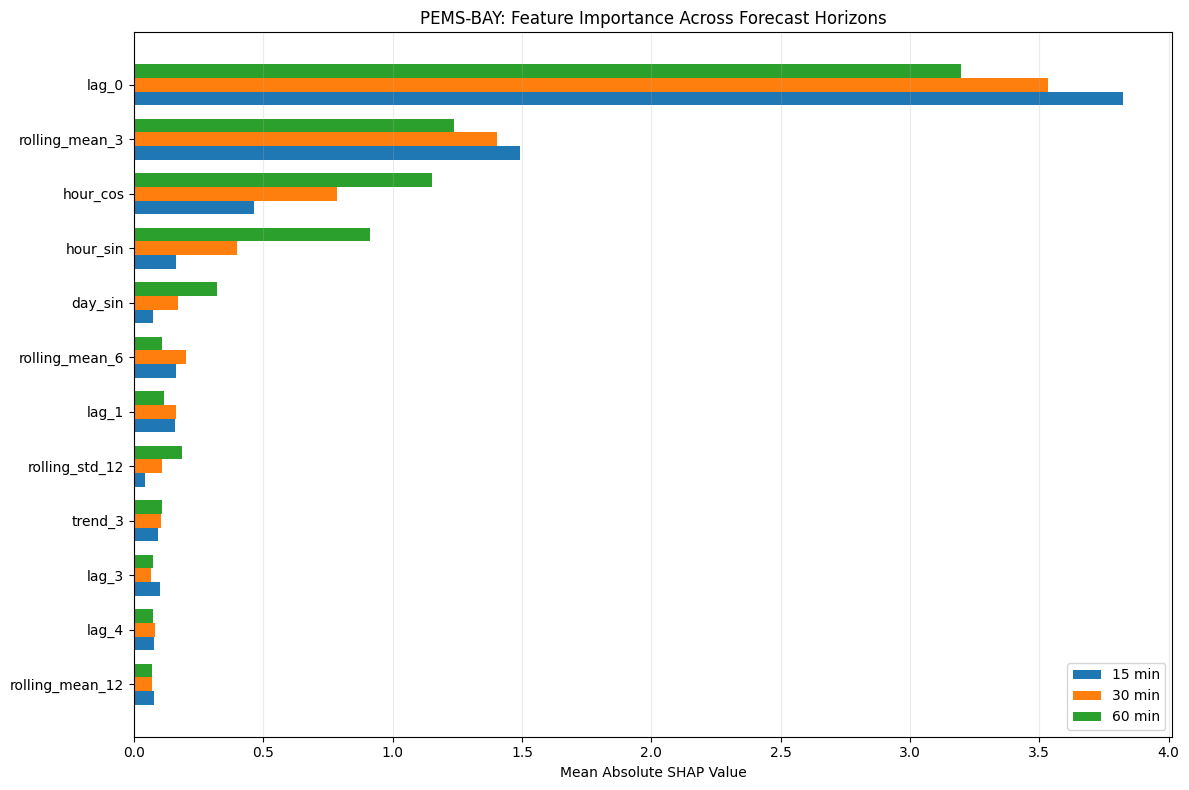


SHAP ANALYSIS COMPLETED SUCCESSFULLY
ZIP file: /content/PEMS_BAY_SHAP_Results.zip
ZIP size: 99.75 KB

Saved files:
- pems_bay_shap_comparison.csv
- pems_bay_shap_horizon_comparison.png
- shap_importance_15min.csv
- shap_importance_30min.csv
- shap_importance_60min.csv
- shap_metadata.json

Download the ZIP from the Colab Files sidebar.


In [45]:

# ============================================================
# PEMS-BAY SHAP EXPLAINABILITY ANALYSIS
# XGBoost | 15, 30, 60-minute forecasting
# Same methodology as METR-LA
# No retraining required
# ============================================================

import os
import gc
import json
import zipfile
import random

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# Install SHAP only if needed
try:
    import shap
except ImportError:
    %pip -q install shap
    import shap

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

MODEL_DIR = "/content/traffic_models/pems_bay"
RESULT_DIR = "/content/PEMS_BAY_SHAP_Results"

os.makedirs(RESULT_DIR, exist_ok=True)

DATA_PATH = "/content/pems-bay-dst-corrected.h5"

if not os.path.exists(DATA_PATH):
    DATA_PATH = "/content/pems-bay.h5"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "PEMS-BAY dataset missing. "
        "Download pems-bay.h5 again."
    )

print("=" * 65)
print("PEMS-BAY SHAP ANALYSIS")
print("=" * 65)

# ============================================================
# 1. LOAD DATASET
# ============================================================

raw = pd.read_hdf(DATA_PATH).astype("float32")

if raw.index.tz is None:
    raw.index = raw.index.tz_localize(
        "America/Los_Angeles",
        ambiguous="raise",
        nonexistent="raise"
    )

assert raw.shape[1] == 325
assert raw.index.is_monotonic_increasing

timestamps = raw.index
n_times = len(raw)

TRAIN_END = int(n_times * 0.70)
VAL_END = int(n_times * 0.80)
BASE_END = int(TRAIN_END * 0.70)

TRAIN_CUTOFF = timestamps[TRAIN_END]
VAL_CUTOFF = timestamps[VAL_END]

raw_values = raw.to_numpy(
    dtype=np.float32,
    copy=False
)

# Match the preprocessing of trained models
valid = np.isfinite(raw_values) & (raw_values != 0)

missing_df = raw.mask(~valid)

base_missing = missing_df.iloc[:BASE_END]

sensor_medians = base_missing.median()

global_median = float(
    base_missing.stack().median()
)

fallback_values = sensor_medians.fillna(
    global_median
)

clean = (
    missing_df
    .ffill(limit=6)
    .fillna(fallback_values)
    .astype(np.float32)
)

clean_values = clean.to_numpy(
    dtype=np.float32,
    copy=False
)

assert np.isfinite(clean_values).all()

print("Dataset:", raw.shape)
print("Validation starts:", TRAIN_CUTOFF)
print("Validation ends:", VAL_CUTOFF)

# ============================================================
# 2. VERIFY FEATURE ORDER
# ============================================================

FEATURE_COLS = [
    f"lag_{i}" for i in range(12)
] + [
    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_12",
    "rolling_std_12",
    "trend_3",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "weekend"
]

assert len(FEATURE_COLS) == 24

for horizon in ["15min", "30min", "60min"]:

    metadata_path = os.path.join(
        MODEL_DIR,
        f"metadata_{horizon}.json"
    )

    model_path = os.path.join(
        MODEL_DIR,
        f"xgboost_{horizon}.pkl"
    )

    if not os.path.exists(metadata_path):
        raise FileNotFoundError(metadata_path)

    if not os.path.exists(model_path):
        raise FileNotFoundError(model_path)

    with open(metadata_path) as f:
        metadata = json.load(f)

    assert (
        metadata["feature_names"] == FEATURE_COLS
    ), f"Feature order mismatch: {horizon}"

    assert metadata["zero_as_missing"] is True

print("All three model feature orders verified!")

# ============================================================
# 3. CALENDAR FEATURES
# ============================================================

hours = (
    timestamps.hour.to_numpy()
    + timestamps.minute.to_numpy() / 60.0
)

days = timestamps.dayofweek.to_numpy()

calendar = {
    "hour_sin": np.sin(2*np.pi*hours/24),
    "hour_cos": np.cos(2*np.pi*hours/24),
    "day_sin": np.sin(2*np.pi*days/7),
    "day_cos": np.cos(2*np.pi*days/7),
    "weekend": (days >= 5).astype(np.float32)
}

# ============================================================
# 4. CONSTRUCT VALIDATION FEATURES
# ============================================================

HORIZONS = {
    3: "15min",
    6: "30min",
    12: "60min"
}

SAMPLES_PER_SENSOR = 4
EXTRA_SAMPLES = 1035 - 325*3

# Select 3 validation observations per sensor,
# plus one additional observation for 60 sensors.
# Total: 325*3 + 60 = 1035.

rng = np.random.default_rng(SEED)

all_shap_results = []

for horizon, name in HORIZONS.items():

    print("\n" + "=" * 65)
    print("ANALYZING:", name)
    print("=" * 65)

    model = joblib.load(
        os.path.join(
            MODEL_DIR,
            f"xgboost_{name}.pkl"
        )
    )

    samples = []

    target_times = timestamps + pd.Timedelta(
        minutes=5*horizon
    )

    # Same validation target-time definition as training
    time_mask = (
        (target_times >= TRAIN_CUTOFF)
        & (target_times < VAL_CUTOFF)
    )

    for sensor_index in range(325):

        speeds = pd.Series(
            clean_values[:, sensor_index],
            index=timestamps
        )

        features = pd.DataFrame(
            index=timestamps
        )

        for lag in range(12):
            features[f"lag_{lag}"] = speeds.shift(lag)

        for window in [3, 6, 12]:

            rolling = speeds.rolling(window)

            features[f"rolling_mean_{window}"] = (
                rolling.mean()
            )

            features[f"rolling_std_{window}"] = (
                rolling.std()
            )

        features["trend_3"] = (
            speeds - speeds.shift(3)
        )

        for column, values in calendar.items():
            features[column] = values

        valid_target = np.zeros(
            n_times, dtype=bool
        )

        valid_target[:-horizon] = valid[
            horizon:, sensor_index
        ]

        eligible = (
            time_mask
            & valid_target
            & (np.arange(n_times) >= 11)
            & (np.arange(n_times) < n_times-horizon)
        )

        eligible_indices = np.flatnonzero(
            eligible
        )

        # 4 samples from first 60 sensors,
        # 3 from remaining 265 sensors.
        n_samples = 4 if sensor_index < 60 else 3

        if len(eligible_indices) < n_samples:
            raise ValueError(
                f"Insufficient validation samples "
                f"for sensor {sensor_index}"
            )

        chosen = rng.choice(
            eligible_indices,
            size=n_samples,
            replace=False
        )

        selected = features.iloc[
            chosen
        ][FEATURE_COLS].to_numpy(
            dtype=np.float32
        )

        assert np.isfinite(selected).all()

        samples.append(selected)

        del features

    X_sample = np.concatenate(
        samples, axis=0
    )

    assert X_sample.shape == (1035, 24)

    # ========================================================
    # 5. COMPUTE TREE SHAP
    # ========================================================

    print("SHAP sample shape:", X_sample.shape)

    explainer = shap.TreeExplainer(model)

    shap_values = explainer.shap_values(
        X_sample
    )

    shap_values = np.asarray(
        shap_values
    )

    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 0]

    assert shap_values.shape == X_sample.shape

    importance = np.mean(
        np.abs(shap_values),
        axis=0
    )

    result = pd.DataFrame({
        "Feature": FEATURE_COLS,
        "MeanAbsSHAP": importance
    })

    result = result.sort_values(
        "MeanAbsSHAP",
        ascending=False
    ).reset_index(drop=True)

    result.to_csv(
        os.path.join(
            RESULT_DIR,
            f"shap_importance_{name}.csv"
        ),
        index=False
    )

    result_for_comparison = result.copy()
    result_for_comparison["Horizon"] = name

    all_shap_results.append(
        result_for_comparison
    )

    print("\nTOP 10 FEATURES")
    print("-" * 45)

    display(result.head(10).round(4))

    del model, explainer, shap_values
    del X_sample, samples

    gc.collect()


# ============================================================
# 6. COMBINE ALL HORIZONS
# ============================================================

combined = pd.concat(
    all_shap_results,
    ignore_index=True
)

comparison = combined.pivot(
    index="Feature",
    columns="Horizon",
    values="MeanAbsSHAP"
)

comparison = comparison[
    ["15min", "30min", "60min"]
]

comparison["Average"] = comparison.mean(
    axis=1
)

comparison = comparison.sort_values(
    "Average",
    ascending=False
)

comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "pems_bay_shap_comparison.csv"
    )
)

print("\n" + "=" * 65)
print("TOP FEATURES ACROSS ALL HORIZONS")
print("=" * 65)

display(comparison.head(15).round(4))


# ============================================================
# 7. SHAP COMPARISON FIGURE
# ============================================================

top_features = comparison.head(12)

plot_data = top_features[
    ["15min", "30min", "60min"]
].iloc[::-1]

fig, ax = plt.subplots(
    figsize=(12, 8)
)

y = np.arange(len(plot_data))
bar_height = 0.25

ax.barh(
    y - bar_height,
    plot_data["15min"],
    bar_height,
    label="15 min"
)

ax.barh(
    y,
    plot_data["30min"],
    bar_height,
    label="30 min"
)

ax.barh(
    y + bar_height,
    plot_data["60min"],
    bar_height,
    label="60 min"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data.index)

ax.set_xlabel(
    "Mean Absolute SHAP Value"
)

ax.set_title(
    "PEMS-BAY: Feature Importance Across Forecast Horizons"
)

ax.legend()
ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

figure_path = os.path.join(
    RESULT_DIR,
    "pems_bay_shap_horizon_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 8. SAVE EXPERIMENT DETAILS
# ============================================================

shap_metadata = {
    "dataset": "PEMS-BAY",
    "method": "TreeExplainer",
    "explained_model": "XGBoost",
    "does_not_explain": "Full hybrid fusion",
    "sampling_split": "Validation",
    "sample_count_per_horizon": 1035,
    "sensor_count": 325,
    "sampling": (
        "4 observations from first 60 sensors, "
        "3 from each of the other 265 sensors"
    ),
    "random_seed": SEED,
    "feature_order": FEATURE_COLS,
    "timezone": "America/Los_Angeles",
    "zero_as_missing": True,
    "mean_abs_shap_units": (
        "Traffic-speed prediction units"
    )
}

with open(
    os.path.join(RESULT_DIR, "shap_metadata.json"),
    "w"
) as f:
    json.dump(
        shap_metadata,
        f,
        indent=4
    )


# ============================================================
# 9. CREATE SMALL BACKUP ZIP
# ============================================================

zip_path = "/content/PEMS_BAY_SHAP_Results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for filename in sorted(
        os.listdir(RESULT_DIR)
    ):

        source = os.path.join(
            RESULT_DIR,
            filename
        )

        if os.path.isfile(source):

            archive.write(
                source,
                arcname=filename
            )

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None

print("\n" + "=" * 65)
print("SHAP ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 65)

print("ZIP file:", zip_path)
print(
    "ZIP size:",
    round(
        os.path.getsize(zip_path)/1024,
        2
    ),
    "KB"
)

print("\nSaved files:")

for name in sorted(os.listdir(RESULT_DIR)):
    print("-", name)

print(
    "\nDownload the ZIP from the Colab Files sidebar."
)


PEMS-BAY MODEL EFFICIENCY BENCHMARK
Device: cpu
Batch size: 1024
Warmups: 3
Measured repetitions: 10
Torch CPU threads: 2

BENCHMARK: 15min
XGBoost    | Size: 0.807 MB | Latency: 6.282 ms | Throughput: 163000.0/s
LSTM       | Size: 0.069 MB | Latency: 20.554 ms | Throughput: 49820.8/s
Hybrid     | Size: 0.887 MB | Latency: 38.035 ms | Throughput: 26922.8/s

BENCHMARK: 30min
XGBoost    | Size: 0.807 MB | Latency: 6.013 ms | Throughput: 170296.1/s
LSTM       | Size: 0.069 MB | Latency: 21.892 ms | Throughput: 46775.1/s
Hybrid     | Size: 0.886 MB | Latency: 36.287 ms | Throughput: 28219.2/s

BENCHMARK: 60min
XGBoost    | Size: 0.808 MB | Latency: 6.348 ms | Throughput: 161318.7/s
LSTM       | Size: 0.069 MB | Latency: 20.783 ms | Throughput: 49272.1/s
Hybrid     | Size: 0.888 MB | Latency: 37.030 ms | Throughput: 27653.3/s

FINAL EFFICIENCY RESULTS


,Dataset,Horizon,Model,Model size (MB),Batch size,Median latency (ms),Throughput (predictions/s),Warmups,Repetitions,Device
0,PEMS-BAY,15min,XGBoost,0.807,1024,6.282,163000.015,3,10,CPU
1,PEMS-BAY,15min,LSTM,0.069,1024,20.554,49820.848,3,10,CPU
2,PEMS-BAY,15min,Hybrid,0.887,1024,38.035,26922.849,3,10,CPU
3,PEMS-BAY,30min,XGBoost,0.807,1024,6.013,170296.145,3,10,CPU
4,PEMS-BAY,30min,LSTM,0.069,1024,21.892,46775.110,3,10,CPU
5,PEMS-BAY,30min,Hybrid,0.886,1024,36.287,28219.224,3,10,CPU
6,PEMS-BAY,60min,XGBoost,0.808,1024,6.348,161318.692,3,10,CPU
7,PEMS-BAY,60min,LSTM,0.069,1024,20.783,49272.142,3,10,CPU
8,PEMS-BAY,60min,Hybrid,0.888,1024,37.030,27653.297,3,10,CPU


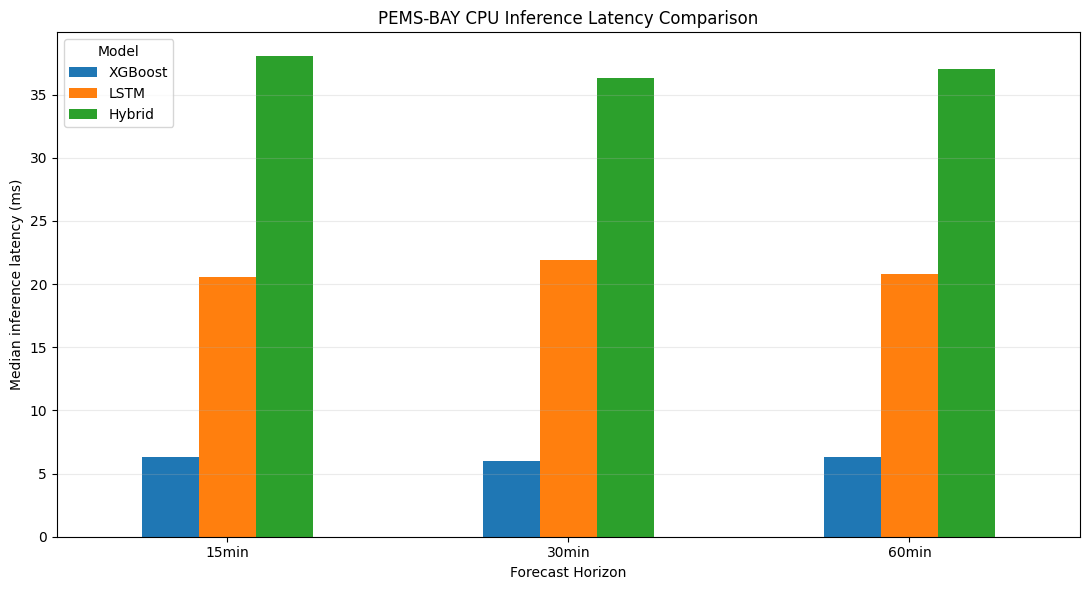


BENCHMARK FINISHED!
CSV: /content/PEMS_BAY_Efficiency_Results/pems_bay_model_efficiency.csv
ZIP: /content/PEMS_BAY_Efficiency_Results.zip
ZIP size: 78.0 KB

Download the ZIP from the Colab Files sidebar.


In [46]:

# ============================================================
# STAGE 17 — PEMS-BAY MODEL EFFICIENCY BENCHMARK
#
# XGBoost vs LSTM vs Hybrid
# Horizons: 15 / 30 / 60 minutes
#
# CPU inference only — no retraining
# Batch size: 1024
# Warmups: 3 | Repetitions: 10
# ============================================================

import os
import json
import time
import zipfile
import gc

import numpy as np
import pandas as pd
import joblib
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

torch.set_num_threads(2)

DEVICE = torch.device("cpu")

MODEL_DIR = "/content/traffic_models/pems_bay"
RESULT_DIR = "/content/PEMS_BAY_Efficiency_Results"

os.makedirs(RESULT_DIR, exist_ok=True)

HORIZONS = ["15min", "30min", "60min"]

BATCH_SIZE = 1024
WARMUPS = 3
REPEATS = 10

rng = np.random.default_rng(42)

print("=" * 65)
print("PEMS-BAY MODEL EFFICIENCY BENCHMARK")
print("=" * 65)

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Warmups:", WARMUPS)
print("Measured repetitions:", REPEATS)
print("Torch CPU threads:", torch.get_num_threads())


# ============================================================
# 1. MODEL ARCHITECTURES
# ============================================================

class TrafficLSTM(nn.Module):

    def __init__(self, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :]).squeeze(-1)


class HybridFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


# ============================================================
# 2. LOAD ALL MODELS AND METADATA
# ============================================================

def load_models(horizon):

    paths = {
        "XGBoost": os.path.join(
            MODEL_DIR, f"xgboost_{horizon}.pkl"
        ),
        "LSTM": os.path.join(
            MODEL_DIR, f"lstm_{horizon}.pth"
        ),
        "Hybrid": os.path.join(
            MODEL_DIR, f"hybrid_{horizon}.pth"
        ),
        "Metadata": os.path.join(
            MODEL_DIR, f"metadata_{horizon}.json"
        )
    }

    for model_name, path in paths.items():
        if not os.path.isfile(path):
            raise FileNotFoundError(
                f"Missing {model_name}: {path}"
            )

    with open(paths["Metadata"]) as file:
        metadata = json.load(file)

    features = metadata["feature_names"]

    assert len(features) == 24
    assert features[:12] == [
        f"lag_{i}" for i in range(12)
    ]

    xgb = joblib.load(paths["XGBoost"])

    lstm = TrafficLSTM(
        metadata["lstm_hidden_size"]
    ).to(DEVICE)

    lstm.load_state_dict(
        torch.load(
            paths["LSTM"],
            map_location=DEVICE,
            weights_only=True
        )
    )

    lstm.eval()

    fusion = HybridFusion().to(DEVICE)

    fusion.load_state_dict(
        torch.load(
            paths["Hybrid"],
            map_location=DEVICE,
            weights_only=True
        )
    )

    fusion.eval()

    return paths, metadata, features, xgb, lstm, fusion


# ============================================================
# 3. CREATE IDENTICAL BENCHMARK INPUTS
# ============================================================

# A fixed synthetic input batch is used for timing.
# It has the correct input shape and plausible speed range.
#
# This measures inference workload, not forecasting accuracy.
# Accuracy was already evaluated on held-out test data.

def make_benchmark_input(feature_names):

    X = np.zeros(
        (BATCH_SIZE, len(feature_names)),
        dtype=np.float32
    )

    # Construct recent traffic speeds with mild variation.
    base_speed = rng.uniform(
        20, 75, size=(BATCH_SIZE, 1)
    ).astype(np.float32)

    lag_values = (
        base_speed
        + rng.normal(
            0, 2,
            size=(BATCH_SIZE, 12)
        ).astype(np.float32)
    )

    lag_values = np.clip(lag_values, 0, 85)

    for i in range(12):
        X[:, feature_names.index(f"lag_{i}")] = (
            lag_values[:, i]
        )

    for window in [3, 6, 12]:

        recent = lag_values[:, :window]

        X[
            :, feature_names.index(f"rolling_mean_{window}")
        ] = recent.mean(axis=1)

        X[
            :, feature_names.index(f"rolling_std_{window}")
        ] = recent.std(axis=1, ddof=1)

    X[:, feature_names.index("trend_3")] = (
        lag_values[:, 0] - lag_values[:, 3]
    )

    hours = rng.uniform(0, 24, BATCH_SIZE)
    days = rng.integers(0, 7, BATCH_SIZE)

    X[:, feature_names.index("hour_sin")] = (
        np.sin(2 * np.pi * hours / 24)
    )

    X[:, feature_names.index("hour_cos")] = (
        np.cos(2 * np.pi * hours / 24)
    )

    X[:, feature_names.index("day_sin")] = (
        np.sin(2 * np.pi * days / 7)
    )

    X[:, feature_names.index("day_cos")] = (
        np.cos(2 * np.pi * days / 7)
    )

    X[:, feature_names.index("weekend")] = (
        (days >= 5).astype(np.float32)
    )

    assert np.isfinite(X).all()

    return X


# ============================================================
# 4. BENCHMARK INFERENCE FUNCTIONS
# ============================================================

def prepare_lstm_input(X, features, metadata):

    lag_indices = [
        features.index(f"lag_{i}")
        for i in range(11, -1, -1)
    ]

    sequences = X[:, lag_indices].copy()

    sequences -= metadata["input_mean"]
    sequences /= metadata["input_std"]

    return torch.from_numpy(
        sequences.reshape(-1, 12, 1)
    )


def xgb_inference(xgb, X):
    return xgb.predict(X)


def lstm_inference(lstm, sequence_tensor):

    with torch.inference_mode():
        return lstm(sequence_tensor)


def hybrid_inference(
    xgb, lstm, fusion,
    X, sequence_tensor, metadata
):

    xgb_predictions = xgb.predict(X)

    with torch.inference_mode():

        lstm_output, _ = lstm.lstm(
            sequence_tensor
        )

        hidden = lstm_output[:, -1, :]

        xgb_normalized = (
            (
                xgb_predictions
                - metadata["target_mean"]
            ) / metadata["target_std"]
        ).astype(np.float32)

        xgb_tensor = torch.from_numpy(
            xgb_normalized
        ).unsqueeze(1)

        combined = torch.cat(
            [hidden, xgb_tensor],
            dim=1
        )

        hybrid_normalized = fusion(combined)

        final_predictions = (
            hybrid_normalized
            * metadata["target_std"]
            + metadata["target_mean"]
        )

        return final_predictions


# ============================================================
# 5. MEASURE MEDIAN LATENCY
# ============================================================

def benchmark(function):

    # Warm up CPU kernels and model execution.
    for _ in range(WARMUPS):
        function()

    durations_ms = []

    for _ in range(REPEATS):

        start = time.perf_counter()

        result = function()

        # Force output materialization when applicable.
        if torch.is_tensor(result):
            result = result.numpy()

        elapsed = (
            time.perf_counter() - start
        ) * 1000

        durations_ms.append(elapsed)

    median_ms = float(
        np.median(durations_ms)
    )

    throughput = (
        BATCH_SIZE / (median_ms / 1000)
    )

    return median_ms, throughput


# ============================================================
# 6. RUN ALL HORIZONS
# ============================================================

records = []

for horizon in HORIZONS:

    print("\n" + "=" * 65)
    print("BENCHMARK:", horizon)
    print("=" * 65)

    paths, metadata, features, xgb, lstm, fusion = (
        load_models(horizon)
    )

    X = make_benchmark_input(features)

    sequence_tensor = prepare_lstm_input(
        X, features, metadata
    )

    operations = {
        "XGBoost": lambda: xgb_inference(xgb, X),

        "LSTM": lambda: lstm_inference(
            lstm, sequence_tensor
        ),

        "Hybrid": lambda: hybrid_inference(
            xgb,
            lstm,
            fusion,
            X,
            sequence_tensor,
            metadata
        )
    }

    model_sizes = {
        "XGBoost": os.path.getsize(
            paths["XGBoost"]
        ) / 1024**2,

        "LSTM": os.path.getsize(
            paths["LSTM"]
        ) / 1024**2,

        "Hybrid": (
            os.path.getsize(paths["XGBoost"])
            + os.path.getsize(paths["LSTM"])
            + os.path.getsize(paths["Hybrid"])
        ) / 1024**2
    }

    for name, operation in operations.items():

        latency, throughput = benchmark(
            operation
        )

        row = {
            "Dataset": "PEMS-BAY",
            "Horizon": horizon,
            "Model": name,
            "Model size (MB)": model_sizes[name],
            "Batch size": BATCH_SIZE,
            "Median latency (ms)": latency,
            "Throughput (predictions/s)": throughput,
            "Warmups": WARMUPS,
            "Repetitions": REPEATS,
            "Device": "CPU"
        }

        records.append(row)

        print(
            f"{name:10s} | "
            f"Size: {model_sizes[name]:.3f} MB | "
            f"Latency: {latency:.3f} ms | "
            f"Throughput: {throughput:.1f}/s"
        )

    del xgb, lstm, fusion
    gc.collect()


# ============================================================
# 7. SAVE CSV RESULTS
# ============================================================

results = pd.DataFrame(records)

csv_path = os.path.join(
    RESULT_DIR,
    "pems_bay_model_efficiency.csv"
)

results.to_csv(csv_path, index=False)

print("\n" + "=" * 65)
print("FINAL EFFICIENCY RESULTS")
print("=" * 65)

display(results.round(3))


# ============================================================
# 8. LATENCY COMPARISON CHART
# ============================================================

latency_table = results.pivot(
    index="Horizon",
    columns="Model",
    values="Median latency (ms)"
)

latency_table = latency_table.loc[
    ["15min", "30min", "60min"],
    ["XGBoost", "LSTM", "Hybrid"]
]

ax = latency_table.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title(
    "PEMS-BAY CPU Inference Latency Comparison"
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("Median inference latency (ms)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

chart_path = os.path.join(
    RESULT_DIR,
    "pems_bay_latency_comparison.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 9. SAVE BENCHMARK METADATA
# ============================================================

benchmark_metadata = {
    "dataset": "PEMS-BAY",
    "sensors": 325,
    "horizons": HORIZONS,
    "device": "CPU",
    "batch_size": BATCH_SIZE,
    "warmups": WARMUPS,
    "repetitions": REPEATS,
    "latency_statistic": "median",
    "input_type": "synthetic plausible traffic features",
    "included": (
        "Model inference; hybrid includes XGBoost, "
        "LSTM and fusion calculations"
    ),
    "excluded": (
        "Dataset loading, imputation, feature engineering, "
        "and disk I/O"
    ),
    "model_size_units": "MiB",
    "latency_units": "milliseconds"
}

metadata_path = os.path.join(
    RESULT_DIR,
    "benchmark_metadata.json"
)

with open(metadata_path, "w") as file:
    json.dump(
        benchmark_metadata,
        file,
        indent=4
    )


# ============================================================
# 10. CREATE BACKUP ZIP
# ============================================================

zip_path = "/content/PEMS_BAY_Efficiency_Results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for filename in sorted(
        os.listdir(RESULT_DIR)
    ):

        file_path = os.path.join(
            RESULT_DIR,
            filename
        )

        archive.write(
            file_path,
            arcname=filename
        )

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None

print("\nBENCHMARK FINISHED!")
print("CSV:", csv_path)
print("ZIP:", zip_path)

print(
    "ZIP size:",
    round(
        os.path.getsize(zip_path) / 1024,
        2
    ),
    "KB"
)

print(
    "\nDownload the ZIP from the Colab Files sidebar."
)


In [47]:

# ============================================================
# STAGE 18 — FINAL RESEARCH VALIDATION
# PEMS-BAY + METR-LA RESULTS COMPARISON
#
# No retraining
# No Google Drive required
# Verifies model files, splits, feature order,
# zero-speed handling, accuracy, and paper limitations
# ============================================================

import os
import json
import zipfile
import hashlib
import numpy as np
import pandas as pd

MODEL_DIR = "/content/traffic_models/pems_bay"
DATA_PATH = "/content/pems-bay-dst-corrected.h5"
REPORT_DIR = "/content/Research_Validation_Results"

os.makedirs(REPORT_DIR, exist_ok=True)

HORIZONS = ["15min", "30min", "60min"]

EXPECTED_FEATURES = [
    f"lag_{i}" for i in range(12)
] + [
    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_6",
    "rolling_std_6",
    "rolling_mean_12",
    "rolling_std_12",
    "trend_3",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "weekend"
]

checks = []

def check(name, condition, details=""):
    passed = bool(condition)
    checks.append({
        "Check": name,
        "Status": "PASS" if passed else "FAIL",
        "Details": str(details)
    })
    print(
        ("PASS" if passed else "FAIL"),
        "-", name,
        details
    )

print("=" * 65)
print("STAGE 18 — FINAL RESEARCH VALIDATION")
print("=" * 65)

# ============================================================
# 1. VERIFY DATASET AND CHRONOLOGICAL SPLITS
# ============================================================

print("\n1. DATASET AND SPLIT VALIDATION")
print("-" * 55)

assert os.path.isfile(DATA_PATH), (
    "DST-corrected PEMS-BAY dataset missing."
)

raw = pd.read_hdf(DATA_PATH)

n = len(raw)

base_end = int(int(n * 0.70) * 0.70)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

base_cutoff = raw.index[base_end]
train_cutoff = raw.index[train_end]
val_cutoff = raw.index[val_end]

check(
    "Expected dataset shape",
    raw.shape == (52116, 325),
    raw.shape
)

check(
    "California timezone",
    str(raw.index.tz) == "America/Los_Angeles",
    raw.index.tz
)

intervals = raw.index.to_series().diff().dropna()

check(
    "Five-minute elapsed intervals",
    (intervals == pd.Timedelta(minutes=5)).all()
)

check(
    "Chronological split ordering",
    base_cutoff < train_cutoff < val_cutoff
)

print("\nBase cutoff:", base_cutoff)
print("Training cutoff:", train_cutoff)
print("Validation cutoff:", val_cutoff)

# ============================================================
# 2. AUDIT ZERO-SPEED OBSERVATIONS
# ============================================================

print("\n2. ZERO-SPEED DATA AUDIT")
print("-" * 55)

partitions = {
    "Base": raw.iloc[:base_end],
    "Fusion-period": raw.iloc[base_end:train_end],
    "Validation": raw.iloc[train_end:val_end],
    "Test": raw.iloc[val_end:]
}

zero_records = []

for name, part in partitions.items():

    arr = part.to_numpy()

    zeros = int(np.count_nonzero(arr == 0))
    nans = int(np.count_nonzero(~np.isfinite(arr)))

    zero_records.append({
        "Partition": name,
        "Observations": int(arr.size),
        "Zero readings": zeros,
        "Zero percentage": 100 * zeros / arr.size,
        "Nonfinite readings": nans
    })

zero_df = pd.DataFrame(zero_records)

display(zero_df.round(6))

check(
    "Total zero readings match original audit",
    int(zero_df["Zero readings"].sum()) == 521
)

# This is a descriptive audit.
# It DOES NOT establish whether zeros are valid speeds.

# ============================================================
# 3. VERIFY SAVED MODELS AND METADATA
# ============================================================

print("\n3. MODEL AND METADATA VALIDATION")
print("-" * 55)

all_metrics = []
metadata_summary = []
model_file_records = []

required_prefixes = {
    "XGBoost": ("xgboost", ".pkl"),
    "LSTM": ("lstm", ".pth"),
    "Hybrid": ("hybrid", ".pth"),
    "Metadata": ("metadata", ".json"),
    "Results": ("results", ".json")
}

for horizon in HORIZONS:

    print("\nHorizon:", horizon)

    paths = {}

    for label, (prefix, ext) in required_prefixes.items():

        path = os.path.join(
            MODEL_DIR,
            f"{prefix}_{horizon}{ext}"
        )

        paths[label] = path

        exists = os.path.isfile(path)

        check(
            f"{horizon} {label} saved",
            exists
        )

        if not exists:
            raise FileNotFoundError(path)

        size = os.path.getsize(path)

        with open(path, "rb") as f:
            digest = hashlib.file_digest(
                f, "sha256"
            ).hexdigest()

        model_file_records.append({
            "Horizon": horizon,
            "File": os.path.basename(path),
            "Size bytes": size,
            "SHA256": digest
        })

    with open(paths["Metadata"]) as f:
        meta = json.load(f)

    with open(paths["Results"]) as f:
        result = json.load(f)

    check(
        f"{horizon} feature order",
        meta["feature_names"] == EXPECTED_FEATURES
    )

    check(
        f"{horizon} base-only preprocessing recorded",
        meta.get("zero_as_missing") is True
        and meta.get("forward_fill_limit") == 6
        and meta.get("base_cutoff") == str(base_cutoff)
    )

    check(
        f"{horizon} split timestamps",
        meta.get("train_cutoff") == str(train_cutoff)
        and meta.get("validation_cutoff") == str(val_cutoff)
    )

    check(
        f"{horizon} model architecture",
        meta.get("sequence_length") == 12
        and meta.get("lstm_hidden_size") == 64
    )

    records = result["metrics"]

    metric_pairs = {
        (r["Split"], r["Model"])
        for r in records
    }

    expected_pairs = {
        (split, model)
        for split in ["Validation", "Test"]
        for model in [
            "Persistence", "XGBoost", "LSTM", "Hybrid"
        ]
    }

    check(
        f"{horizon} complete evaluation",
        metric_pairs == expected_pairs
        and len(records) == 8
    )

    for record in records:

        record = record.copy()
        record["Dataset"] = "PEMS-BAY"

        all_metrics.append(record)

    metadata_summary.append({
        "Horizon": horizon,
        "Base samples": meta["base_samples"],
        "Fusion samples": meta["fusion_samples"],
        "Validation samples": meta["val_samples"],
        "Test samples": meta["test_samples"],
        "Best fusion epoch": meta["best_fusion_epoch"]
    })

metrics_df = pd.DataFrame(all_metrics)

display(pd.DataFrame(metadata_summary))

# ============================================================
# 4. EVALUATE HYBRID AGAINST XGBOOST
# ============================================================

print("\n4. TEST ACCURACY COMPARISON")
print("-" * 55)

test_df = metrics_df[
    metrics_df["Split"] == "Test"
].copy()

display(
    test_df[
        ["Horizon", "Model", "MAE", "RMSE", "MAPE (%)"]
    ].round(4)
)

improvements = []

for horizon in HORIZONS:

    subset = test_df[
        test_df["Horizon"] == horizon
    ].set_index("Model")

    xgb = subset.loc["XGBoost"]
    hybrid = subset.loc["Hybrid"]

    row = {"Horizon": horizon}

    for metric in ["MAE", "RMSE", "MAPE (%)"]:

        row[f"{metric} improvement (%)"] = (
            100 * (xgb[metric] - hybrid[metric])
            / xgb[metric]
        )

    improvements.append(row)

improvement_df = pd.DataFrame(improvements)

print("\nHYBRID IMPROVEMENT OVER XGBOOST")

display(improvement_df.round(4))

check(
    "Hybrid lowers test MAE at all horizons",
    (
        improvement_df["MAE improvement (%)"] > 0
    ).all()
)

check(
    "Hybrid lowers test RMSE at all horizons",
    (
        improvement_df["RMSE improvement (%)"] > 0
    ).all()
)

check(
    "Hybrid lowers test MAPE at all horizons",
    (
        improvement_df["MAPE (%) improvement (%)"] > 0
    ).all()
)

# ============================================================
# 5. CROSS-DATASET SUMMARY
# ============================================================

# These METR-LA results are the previously VERIFIED
# feature-order-corrected held-out test measurements.
# They are included for comparison, not recomputed here.

metr_la_data = [
    ("15min", "XGBoost", 3.1624, 5.7512, 8.5614),
    ("15min", "Hybrid", 3.1761, 5.7410, 8.6033),
    ("30min", "XGBoost", 3.8869, 7.0179, 11.1546),
    ("30min", "Hybrid", 3.8944, 6.9983, 11.0591),
    ("60min", "XGBoost", 4.9104, 8.4909, 14.7218),
    ("60min", "Hybrid", 4.9220, 8.4509, 14.5737)
]

metr_df = pd.DataFrame(
    metr_la_data,
    columns=[
        "Horizon", "Model",
        "MAE", "RMSE", "MAPE (%)"
    ]
)

metr_df["Dataset"] = "METR-LA"

pems_compare = test_df[
    test_df["Model"].isin(
        ["XGBoost", "Hybrid"]
    )
][[
    "Dataset", "Horizon",
    "Model", "MAE", "RMSE", "MAPE (%)"
]]

comparison_df = pd.concat(
    [
        metr_df[
            pems_compare.columns
        ],
        pems_compare
    ],
    ignore_index=True
)

print("\n5. CROSS-DATASET TEST COMPARISON")
print("-" * 55)

display(
    comparison_df.round(4)
)

print(
    "\nNOTE: METR-LA values are previously "
    "measured results, not re-evaluated by this cell."
)

# ============================================================
# 6. VALIDATE MODEL EFFICIENCY REPORT
# ============================================================

print("\n6. EFFICIENCY REPORT CHECK")
print("-" * 55)

efficiency_path = (
    "/content/PEMS_BAY_Efficiency_Results/"
    "pems_bay_model_efficiency.csv"
)

if os.path.isfile(efficiency_path):

    efficiency = pd.read_csv(efficiency_path)

    check(
        "Efficiency benchmark results available",
        len(efficiency) == 9
    )

    display(
        efficiency[
            [
                "Horizon", "Model",
                "Model size (MB)",
                "Median latency (ms)",
                "Throughput (predictions/s)"
            ]
        ].round(3)
    )

else:

    efficiency = None

    print(
        "Efficiency CSV not found in active runtime."
    )
    print(
        "Previous benchmark results remain valid "
        "as reported, but cannot be independently "
        "rechecked in this cell."
    )

# ============================================================
# 7. METHODOLOGY LIMITATIONS
# ============================================================

limitations = [
    {
        "Topic": "Zero-speed assumption",
        "Status": "Sensitivity test pending",
        "Explanation":
            "PEMS-BAY has 521 zero readings. "
            "Current training treats them as missing "
            "and excludes zero targets. Alternative "
            "handling has not been evaluated."
    },
    {
        "Topic": "METR-LA preprocessing",
        "Status": "Correction or disclosure required",
        "Explanation":
            "Original METR-LA fusion experiments "
            "used fallback medians fitted over the "
            "entire training period rather than only "
            "the earlier base-training partition."
    },
    {
        "Topic": "Spatial dependencies",
        "Status": "Scope limitation",
        "Explanation":
            "Models use each sensor's own speed "
            "history and calendar features, without "
            "explicit graph-based neighbor modeling."
    },
    {
        "Topic": "SHAP interpretation",
        "Status": "Scope limitation",
        "Explanation":
            "Tree SHAP explains the XGBoost branch, "
            "not the complete nonlinear fusion model."
    },
    {
        "Topic": "Efficiency",
        "Status": "Measured trade-off",
        "Explanation":
            "Hybrid serialized size is compact, "
            "but CPU batch latency is higher than "
            "standalone XGBoost."
    },
    {
        "Topic": "Statistical uncertainty",
        "Status": "Further validation recommended",
        "Explanation":
            "Paired temporal-block uncertainty "
            "estimates and repeated random seeds "
            "have not been evaluated."
    }
]

limitations_df = pd.DataFrame(limitations)

print("\n7. RESEARCH LIMITATIONS")
print("-" * 55)

display(limitations_df)

# ============================================================
# 8. SAVE AUDIT OUTPUTS
# ============================================================

pd.DataFrame(checks).to_csv(
    f"{REPORT_DIR}/validation_checks.csv",
    index=False
)

zero_df.to_csv(
    f"{REPORT_DIR}/zero_speed_audit.csv",
    index=False
)

metrics_df.to_csv(
    f"{REPORT_DIR}/pems_bay_verified_metrics.csv",
    index=False
)

improvement_df.to_csv(
    f"{REPORT_DIR}/hybrid_improvements.csv",
    index=False
)

comparison_df.to_csv(
    f"{REPORT_DIR}/cross_dataset_comparison.csv",
    index=False
)

limitations_df.to_csv(
    f"{REPORT_DIR}/research_limitations.csv",
    index=False
)

pd.DataFrame(model_file_records).to_csv(
    f"{REPORT_DIR}/model_file_hashes.csv",
    index=False
)

pd.DataFrame(metadata_summary).to_csv(
    f"{REPORT_DIR}/model_metadata_summary.csv",
    index=False
)

# ============================================================
# 9. ZIP REPORT
# ============================================================

zip_path = (
    "/content/Research_Validation_Results.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for name in sorted(os.listdir(REPORT_DIR)):

        path = os.path.join(REPORT_DIR, name)

        if os.path.isfile(path):
            z.write(path, arcname=name)

with zipfile.ZipFile(zip_path) as z:
    assert z.testzip() is None

failed = sum(
    item["Status"] == "FAIL"
    for item in checks
)

print("\n" + "=" * 65)
print("STAGE 18 VALIDATION COMPLETED")
print("=" * 65)

print("Checks performed:", len(checks))
print("Checks failed:", failed)
print("Report ZIP:", zip_path)
print(
    "ZIP size:",
    round(os.path.getsize(zip_path)/1024, 2),
    "KB"
)

print("\nDownload from the Colab Files sidebar.")

if failed:
    print(
        "\nWARNING: Some validation checks failed. "
        "Review them before using results in the paper."
    )
else:
    print(
        "\nAll implemented consistency checks passed."
    )
    print(
        "Methodological limitations still require "
        "separate research decisions."
    )


STAGE 18 — FINAL RESEARCH VALIDATION

1. DATASET AND SPLIT VALIDATION
-------------------------------------------------------
PASS - Expected dataset shape (52116, 325)
PASS - California timezone America/Los_Angeles
PASS - Five-minute elapsed intervals 
PASS - Chronological split ordering 

Base cutoff: 2017-03-30 17:00:00-07:00
Training cutoff: 2017-05-07 17:05:00-07:00
Validation cutoff: 2017-05-25 19:20:00-07:00

2. ZERO-SPEED DATA AUDIT
-------------------------------------------------------


,Partition,Observations,Zero readings,Zero percentage,Nonfinite readings
0,Base,8299200,0,0.000000,0
1,Fusion-period,3557125,172,0.004835,0
2,Validation,1693575,132,0.007794,0
3,Test,3387800,217,0.006405,0


PASS - Total zero readings match original audit 

3. MODEL AND METADATA VALIDATION
-------------------------------------------------------

Horizon: 15min
PASS - 15min XGBoost saved 
PASS - 15min LSTM saved 
PASS - 15min Hybrid saved 
PASS - 15min Metadata saved 
PASS - 15min Results saved 
PASS - 15min feature order 
PASS - 15min base-only preprocessing recorded 
PASS - 15min split timestamps 
PASS - 15min model architecture 
PASS - 15min complete evaluation 

Horizon: 30min
PASS - 30min XGBoost saved 
PASS - 30min LSTM saved 
PASS - 30min Hybrid saved 
PASS - 30min Metadata saved 
PASS - 30min Results saved 
PASS - 30min feature order 
PASS - 30min base-only preprocessing recorded 
PASS - 30min split timestamps 
PASS - 30min model architecture 
PASS - 30min complete evaluation 

Horizon: 60min
PASS - 60min XGBoost saved 
PASS - 60min LSTM saved 
PASS - 60min Hybrid saved 
PASS - 60min Metadata saved 
PASS - 60min Results saved 
PASS - 60min feature order 
PASS - 60min base-only prepr

,Horizon,Base samples,Fusion samples,Validation samples,Test samples,Best fusion epoch
0,15min,8294650,3551103,1693443,3387583,16
1,30min,8293675,3549153,1693443,3387583,19
2,60min,8291725,3545253,1693443,3387583,15



4. TEST ACCURACY COMPARISON
-------------------------------------------------------


,Horizon,Model,MAE,RMSE,MAPE (%)
4,15min,Persistence,1.5918,3.3875,3.2314
5,15min,XGBoost,1.4610,2.9925,3.1216
6,15min,LSTM,1.4966,3.0961,3.1402
7,15min,Hybrid,1.4478,2.9543,3.0597
12,30min,Persistence,2.1736,4.9540,4.6438
13,30min,XGBoost,1.9691,4.1543,4.5244
14,30min,LSTM,2.0943,4.4682,4.8110
15,30min,Hybrid,1.9526,4.1070,4.4984
20,60min,Persistence,3.0480,7.0037,6.8347
21,60min,XGBoost,2.5851,5.2797,6.2468


... (5 outputs left out)

,Horizon,Model,Model size (MB),Median latency (ms),Throughput (predictions/s)
0,15min,XGBoost,0.807,6.282,163000.015
1,15min,LSTM,0.069,20.554,49820.848
2,15min,Hybrid,0.887,38.035,26922.849
3,30min,XGBoost,0.807,6.013,170296.145
4,30min,LSTM,0.069,21.892,46775.110
5,30min,Hybrid,0.886,36.287,28219.224
6,60min,XGBoost,0.808,6.348,161318.692
7,60min,LSTM,0.069,20.783,49272.142
8,60min,Hybrid,0.888,37.030,27653.297



7. RESEARCH LIMITATIONS
-------------------------------------------------------


,Topic,Status,Explanation
0,Zero-speed assumption,Sensitivity test pending,PEMS-BAY has 521 zero readings. Current traini...
1,METR-LA preprocessing,Correction or disclosure required,Original METR-LA fusion experiments used fallb...
2,Spatial dependencies,Scope limitation,Models use each sensor's own speed history and...
3,SHAP interpretation,Scope limitation,"Tree SHAP explains the XGBoost branch, not the..."
4,Efficiency,Measured trade-off,"Hybrid serialized size is compact, but CPU bat..."
5,Statistical uncertainty,Further validation recommended,Paired temporal-block uncertainty estimates an...



STAGE 18 VALIDATION COMPLETED
Checks performed: 39
Checks failed: 0
Report ZIP: /content/Research_Validation_Results.zip
ZIP size: 4.46 KB

Download from the Colab Files sidebar.

All implemented consistency checks passed.
Methodological limitations still require separate research decisions.


In [48]:

import os, json, zipfile, gc
import numpy as np
import pandas as pd
import joblib
import torch
import torch.nn as nn
from IPython.display import display

MODEL_DIR = "/content/traffic_models/pems_bay"
DATA_PATH = "/content/pems-bay-dst-corrected.h5"
OUT_DIR = "/content/PEMS_BAY_Zero_Sensitivity"
os.makedirs(OUT_DIR, exist_ok=True)

torch.set_num_threads(2)
torch.manual_seed(42)

raw = pd.read_hdf(DATA_PATH).astype("float32")
if raw.index.tz is None:
    raw.index = raw.index.tz_localize(
        "America/Los_Angeles"
    )

n = len(raw)
base_end = int(int(n * 0.70) * 0.70)
test_start = int(n * 0.80)

valid = raw.notna() & raw.ne(0)
missing = raw.mask(~valid)
base = missing.iloc[:base_end]

fallback = base.median().fillna(
    float(base.stack().median())
)

clean = (
    missing.ffill(limit=6)
    .fillna(fallback)
    .astype("float32")
)

features = [
    *[f"lag_{i}" for i in range(12)],
    "rolling_mean_3", "rolling_std_3",
    "rolling_mean_6", "rolling_std_6",
    "rolling_mean_12", "rolling_std_12",
    "trend_3", "hour_sin", "hour_cos",
    "day_sin", "day_cos", "weekend"
]

lag_indices = [
    features.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

class TrafficLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            1, 64, batch_first=True
        )
        self.fc = nn.Linear(64, 1)

class HybridFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)

def sensor_features(sensor):
    s = clean.iloc[:, sensor]
    df = pd.DataFrame(index=raw.index)

    for i in range(12):
        df[f"lag_{i}"] = s.shift(i)

    for w in (3, 6, 12):
        roll = s.rolling(w)
        df[f"rolling_mean_{w}"] = roll.mean()
        df[f"rolling_std_{w}"] = roll.std()

    df["trend_3"] = s - s.shift(3)

    idx = raw.index
    hour = idx.hour + idx.minute / 60
    day = idx.dayofweek

    df["hour_sin"] = np.sin(2*np.pi*hour/24)
    df["hour_cos"] = np.cos(2*np.pi*hour/24)
    df["day_sin"] = np.sin(2*np.pi*day/7)
    df["day_cos"] = np.cos(2*np.pi*day/7)
    df["weekend"] = (day >= 5).astype("float32")

    return df[features]

zero_positions = np.argwhere(
    raw.iloc[test_start:].to_numpy() == 0
)

zero_positions[:, 0] += test_start

print("Test zero readings:", len(zero_positions))

records = []
detail_rows = []

for h, name in [(3,"15min"),(6,"30min"),(12,"60min")]:
    print("\nEvaluating", name)

    with open(f"{MODEL_DIR}/metadata_{name}.json") as f:
        meta = json.load(f)

    with open(f"{MODEL_DIR}/results_{name}.json") as f:
        saved = json.load(f)["metrics"]

    assert meta["feature_names"] == features

    # Predict zero targets using observations h steps earlier.
    rows, target_times, sensors = [], [], []
    for sensor in np.unique(zero_positions[:, 1]):
        positions = zero_positions[
            zero_positions[:, 1] == sensor, 0
        ]
        origins = positions - h
        good = origins >= 11

        if not np.any(good):
            continue

        selected = sensor_features(int(sensor)).iloc[
            origins[good]
        ].to_numpy(dtype=np.float32)

        rows.append(selected)
        target_times.extend(raw.index[positions[good]])
        sensors.extend([int(sensor)] * good.sum())

    X = np.concatenate(rows)
    assert np.isfinite(X).all()

    xgb = joblib.load(
        f"{MODEL_DIR}/xgboost_{name}.pkl"
    )
    lstm = TrafficLSTM()
    lstm.load_state_dict(torch.load(
        f"{MODEL_DIR}/lstm_{name}.pth",
        map_location="cpu", weights_only=True
    ))
    lstm.eval()

    fusion = HybridFusion()
    fusion.load_state_dict(torch.load(
        f"{MODEL_DIR}/hybrid_{name}.pth",
        map_location="cpu", weights_only=True
    ))
    fusion.eval()

    xgb_pred = xgb.predict(X).astype("float32")

    seq = X[:, lag_indices].copy()
    seq = (
        (seq - meta["input_mean"])
        / meta["input_std"]
    )

    with torch.inference_mode():
        inp = torch.from_numpy(seq.reshape(-1,12,1))
        output, _ = lstm.lstm(inp)
        hidden = output[:, -1, :]

        lstm_norm = lstm.fc(hidden).squeeze(-1)

        xgb_norm = torch.from_numpy(
            (
                (xgb_pred - meta["target_mean"])
                / meta["target_std"]
            ).reshape(-1,1).astype("float32")
        )

        fusion_norm = fusion(
            torch.cat([hidden,xgb_norm],dim=1)
        )

        lstm_pred = (
            lstm_norm.numpy() * meta["target_std"]
            + meta["target_mean"]
        )
        hybrid_pred = (
            fusion_norm.numpy() * meta["target_std"]
            + meta["target_mean"]
        )

    pred_dict = {
        "Persistence": X[:, 0],
        "XGBoost": xgb_pred,
        "LSTM": lstm_pred,
        "Hybrid": hybrid_pred
    }

    for model_name, predictions in pred_dict.items():

        original = next(
            r for r in saved
            if r["Split"] == "Test"
            and r["Model"] == model_name
        )

        N = int(original["Samples"])
        k = len(predictions)

        # Added targets equal exactly zero.
        added_abs = np.abs(predictions)
        added_sq = np.square(
            predictions.astype(np.float64)
        )

        new_mae = (
            N * original["MAE"]
            + added_abs.sum(dtype=np.float64)
        ) / (N + k)

        new_rmse = np.sqrt(
            (
                N * original["RMSE"]**2
                + added_sq.sum()
            ) / (N + k)
        )

        records.append({
            "Horizon": name,
            "Model": model_name,
            "Original test samples": N,
            "Added zero targets": k,
            "Original MAE": original["MAE"],
            "MAE including zeros": new_mae,
            "Original RMSE": original["RMSE"],
            "RMSE including zeros": new_rmse,
            "MAE change (%)": (
                100*(new_mae-original["MAE"])
                / original["MAE"]
            ),
            "RMSE change (%)": (
                100*(new_rmse-original["RMSE"])
                / original["RMSE"]
            )
        })

        for timestamp, sensor, prediction in zip(
            target_times, sensors, predictions
        ):
            detail_rows.append({
                "Horizon": name,
                "Model": model_name,
                "Target timestamp": str(timestamp),
                "Sensor index": sensor,
                "Actual zero target": 0.0,
                "Prediction": float(prediction)
            })

    del xgb, lstm, fusion
    gc.collect()

result = pd.DataFrame(records)
details = pd.DataFrame(detail_rows)

display(result.round(5))

result.to_csv(
    f"{OUT_DIR}/zero_sensitivity_summary.csv",
    index=False
)

details.to_csv(
    f"{OUT_DIR}/zero_target_predictions.csv",
    index=False
)

notes = {
    "experiment": "PEMS-BAY zero-target evaluation sensitivity",
    "model_retraining": False,
    "zero_targets_assumed_genuine": True,
    "interpretation": (
        "Hypothetical evaluation only. Does not establish "
        "whether zero readings are valid traffic speeds."
    ),
    "mape": (
        "Not recomputed: zero targets have undefined "
        "percentage errors under conventional MAPE."
    ),
    "other_preprocessing": (
        "Uses original trained-model zero-as-missing "
        "input preprocessing."
    ),
    "rounding": (
        "Augmented metrics reconstructed from saved "
        "rounded aggregate metrics."
    )
}

with open(f"{OUT_DIR}/methodology.json","w") as f:
    json.dump(notes, f, indent=2)

zip_path = "/content/PEMS_BAY_Zero_Sensitivity.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as z:
    for filename in os.listdir(OUT_DIR):
        z.write(
            os.path.join(OUT_DIR, filename),
            arcname=filename
        )

with zipfile.ZipFile(zip_path) as z:
    assert z.testzip() is None

print("\nSensitivity analysis completed.")
print("Backup:", zip_path)
print("Size:", round(
    os.path.getsize(zip_path)/1024, 2
), "KB")


Test zero readings: 217

Evaluating 15min

Evaluating 30min

Evaluating 60min


,Horizon,Model,Original test samples,Added zero targets,Original MAE,MAE including zeros,Original RMSE,RMSE including zeros,MAE change (%),RMSE change (%)
0,15min,Persistence,3387583,217,1.59180,1.59595,3.38751,3.42899,0.26104,1.22459
1,15min,XGBoost,3387583,217,1.46098,1.46515,2.99248,3.03944,0.28525,1.56927
2,15min,LSTM,3387583,217,1.49661,1.50077,3.09611,3.14139,0.27788,1.46236
3,15min,Hybrid,3387583,217,1.44783,1.45200,2.95426,3.00193,0.28825,1.61372
4,30min,Persistence,3387583,217,2.17358,2.17771,4.95399,4.98256,0.19018,0.57670
5,30min,XGBoost,3387583,217,1.96912,1.97326,4.15429,4.18830,0.21037,0.81855
6,30min,LSTM,3387583,217,2.09432,2.09844,4.46823,4.49957,0.19652,0.70138
7,30min,Hybrid,3387583,217,1.95259,1.95674,4.10700,4.14149,0.21250,0.83980
8,60min,Persistence,3387583,217,3.04803,3.05213,7.00373,7.02404,0.13441,0.29001
9,60min,XGBoost,3387583,217,2.58513,2.58923,5.27968,5.30640,0.15869,0.50611



Sensitivity analysis completed.
Backup: /content/PEMS_BAY_Zero_Sensitivity.zip
Size: 26.02 KB


PEMS-BAY PAIRED DAILY UNCERTAINTY ANALYSIS
Hourly sample interval: 12 five-minute steps
Bootstrap repetitions: 2000

ANALYZING 15min
Processed 65/325 sensors
Processed 130/325 sensors
Processed 195/325 sensors
Processed 260/325 sensors
Processed 325/325 sensors
Samples: 282100
Test days: 37
Days Hybrid better: 36 / 37
Sampled XGBoost MAE: 1.47062
Sampled Hybrid MAE: 1.4577
MAE improvement: 0.01292
95% bootstrap CI: (np.float64(0.01035), np.float64(0.01566))

ANALYZING 30min
Processed 65/325 sensors
Processed 130/325 sensors
Processed 195/325 sensors
Processed 260/325 sensors
Processed 325/325 sensors
Samples: 282425
Test days: 37
Days Hybrid better: 34 / 37
Sampled XGBoost MAE: 1.94966
Sampled Hybrid MAE: 1.93656
MAE improvement: 0.0131
95% bootstrap CI: (np.float64(0.00903), np.float64(0.01701))

ANALYZING 60min
Processed 65/325 sensors
Processed 130/325 sensors
Processed 195/325 sensors
Processed 260/325 sensors
Processed 325/325 sensors
Samples: 281883
Test days: 37
Days Hybrid bett

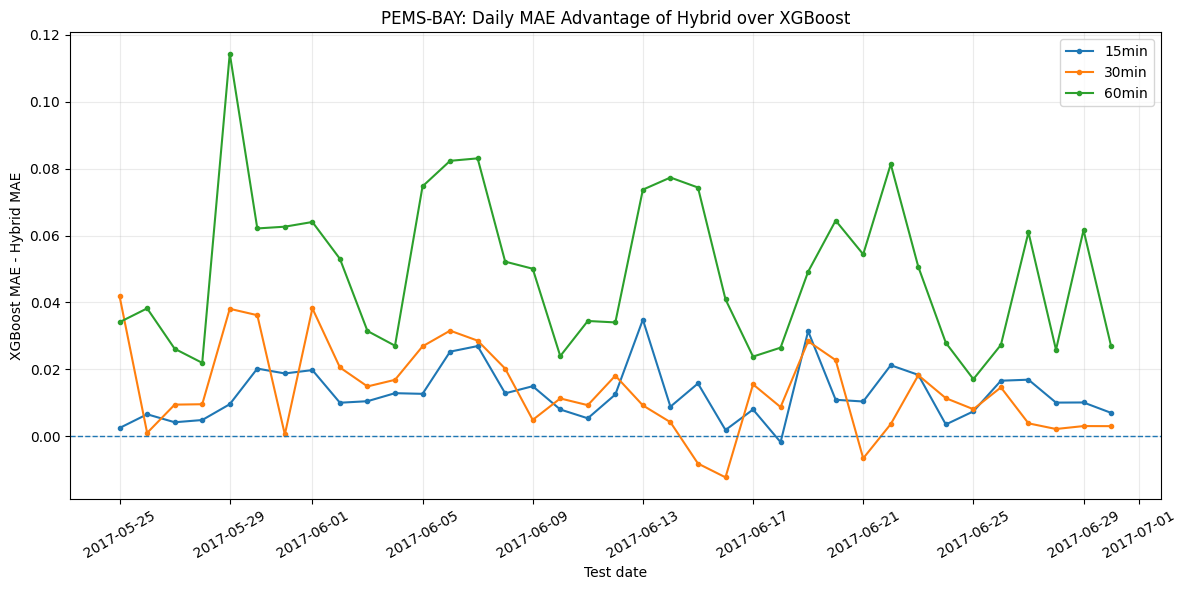


STAGE 20 COMPLETE


,Horizon,Samples,Test days,Days Hybrid better,XGBoost sampled MAE,Hybrid sampled MAE,MAE improvement,Relative improvement (%),95% CI lower,95% CI upper,CI excludes zero
0,15min,282100,37,36,1.47062,1.45770,0.01292,0.87885,0.01035,0.01566,True
1,30min,282425,37,34,1.94966,1.93656,0.01310,0.67199,0.00903,0.01701,True
2,60min,281883,37,37,2.57830,2.52837,0.04993,1.93653,0.04322,0.05744,True



Saved files: /content/traffic_research/uncertainty
- pems_bay_daily_errors.csv
- pems_bay_daily_improvement.png
- pems_bay_uncertainty_summary.csv
- uncertainty_methodology.json

No ZIP downloaded. Results will be included in the final consolidated research archive.


In [49]:

# ============================================================
# STAGE 20 — PAIRED DAILY UNCERTAINTY ANALYSIS
# PEMS-BAY | XGBoost vs Hybrid
#
# No retraining, no downloads.
# Samples one hourly prediction origin per sensor.
# Uses day-block bootstrap with 2,000 repetitions.
# ============================================================

import os, json, gc
from collections import defaultdict

import numpy as np
import pandas as pd
import joblib
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
BOOTSTRAPS = 2000
HOURLY_STEP = 12
BATCH_SIZE = 8192

torch.set_num_threads(2)

MODEL_DIR = "/content/traffic_models/pems_bay"
OUTPUT_DIR = "/content/traffic_research/uncertainty"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DATA_PATH = "/content/pems-bay-dst-corrected.h5"

if not os.path.isfile(DATA_PATH):
    DATA_PATH = "/content/pems-bay.h5"

assert os.path.isfile(DATA_PATH), (
    "PEMS-BAY dataset not found in this Colab runtime."
)

raw = pd.read_hdf(DATA_PATH).astype("float32")

if raw.index.tz is None:
    raw.index = raw.index.tz_localize(
        "America/Los_Angeles"
    )

assert raw.shape == (52116, 325)

n = len(raw)
base_end = int(int(n * 0.70) * 0.70)
test_start = int(n * 0.80)

raw_values = raw.to_numpy(dtype=np.float32)
valid = np.isfinite(raw_values) & (raw_values != 0)

missing = raw.mask(~valid)
base_missing = missing.iloc[:base_end]

fallback = base_missing.median().fillna(
    float(base_missing.stack().median())
)

clean = (
    missing.ffill(limit=6)
    .fillna(fallback)
    .astype("float32")
)

timestamps = raw.index
clean_values = clean.to_numpy(dtype=np.float32)

FEATURE_COLS = [
    *[f"lag_{i}" for i in range(12)],
    "rolling_mean_3", "rolling_std_3",
    "rolling_mean_6", "rolling_std_6",
    "rolling_mean_12", "rolling_std_12",
    "trend_3", "hour_sin", "hour_cos",
    "day_sin", "day_cos", "weekend"
]

LAG_IDX = [
    FEATURE_COLS.index(f"lag_{i}")
    for i in range(11, -1, -1)
]

hour = (
    timestamps.hour.to_numpy()
    + timestamps.minute.to_numpy() / 60
)
day = timestamps.dayofweek.to_numpy()

calendar = {
    "hour_sin": np.sin(2*np.pi*hour/24),
    "hour_cos": np.cos(2*np.pi*hour/24),
    "day_sin": np.sin(2*np.pi*day/7),
    "day_cos": np.cos(2*np.pi*day/7),
    "weekend": (day >= 5).astype(np.float32)
}

class TrafficLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            1, 64, batch_first=True
        )
        self.fc = nn.Linear(64, 1)

class HybridFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(65, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)

def build_features(sensor):
    s = pd.Series(
        clean_values[:, sensor],
        index=timestamps
    )
    df = pd.DataFrame(index=timestamps)

    for i in range(12):
        df[f"lag_{i}"] = s.shift(i)

    for w in (3, 6, 12):
        r = s.rolling(w)
        df[f"rolling_mean_{w}"] = r.mean()
        df[f"rolling_std_{w}"] = r.std()

    df["trend_3"] = s - s.shift(3)

    for key, values in calendar.items():
        df[key] = values

    return df[FEATURE_COLS]

def hybrid_predict(X, xgb, lstm, fusion, meta):
    predictions = np.empty(len(X), dtype=np.float32)

    with torch.inference_mode():
        for start in range(0, len(X), BATCH_SIZE):
            end = min(start + BATCH_SIZE, len(X))
            xb = X[start:end]

            xgb_pred = xgb.predict(xb).astype(np.float32)

            seq = xb[:, LAG_IDX].copy()
            seq -= meta["input_mean"]
            seq /= meta["input_std"]

            tensor = torch.from_numpy(
                seq.reshape(-1, 12, 1)
            )

            outputs, _ = lstm.lstm(tensor)
            hidden = outputs[:, -1, :]

            xgb_norm = torch.from_numpy(
                (
                    (xgb_pred - meta["target_mean"])
                    / meta["target_std"]
                ).reshape(-1, 1).astype(np.float32)
            )

            combined = torch.cat(
                [hidden, xgb_norm], dim=1
            )

            pred_norm = fusion(combined)

            predictions[start:end] = (
                pred_norm.numpy() * meta["target_std"]
                + meta["target_mean"]
            )

    return predictions

summary_rows = []
daily_rows = []
rng = np.random.default_rng(SEED)

print("=" * 65)
print("PEMS-BAY PAIRED DAILY UNCERTAINTY ANALYSIS")
print("=" * 65)
print("Hourly sample interval: 12 five-minute steps")
print("Bootstrap repetitions:", BOOTSTRAPS)

for horizon, label in [
    (3, "15min"),
    (6, "30min"),
    (12, "60min")
]:
    print("\n" + "=" * 55)
    print("ANALYZING", label)
    print("=" * 55, flush=True)

    with open(
        f"{MODEL_DIR}/metadata_{label}.json"
    ) as f:
        meta = json.load(f)

    assert meta["feature_names"] == FEATURE_COLS
    assert meta["zero_as_missing"] is True

    xgb = joblib.load(
        f"{MODEL_DIR}/xgboost_{label}.pkl"
    )

    lstm = TrafficLSTM()
    lstm.load_state_dict(torch.load(
        f"{MODEL_DIR}/lstm_{label}.pth",
        map_location="cpu",
        weights_only=True
    ))
    lstm.eval()

    fusion = HybridFusion()
    fusion.load_state_dict(torch.load(
        f"{MODEL_DIR}/hybrid_{label}.pth",
        map_location="cpu",
        weights_only=True
    ))
    fusion.eval()

    # Same target-time split as original experiments.
    # Select one hourly origin on the 5-minute grid.
    candidate_origins = np.arange(
        11, n-horizon
    )

    candidate_origins = candidate_origins[
        (candidate_origins % HOURLY_STEP) == 0
    ]

    target_indices = candidate_origins + horizon

    time_mask = target_indices >= test_start

    candidate_origins = candidate_origins[time_mask]
    target_indices = target_indices[time_mask]

    daily = defaultdict(
        lambda: [0, 0.0, 0.0, 0.0, 0.0]
    )

    for sensor in range(325):
        sensor_valid = valid[
            target_indices, sensor
        ]

        origins = candidate_origins[sensor_valid]
        targets = target_indices[sensor_valid]

        X = build_features(sensor).iloc[
            origins
        ].to_numpy(dtype=np.float32)

        y = raw_values[
            targets, sensor
        ].astype(np.float32)

        assert np.isfinite(X).all()
        assert np.isfinite(y).all()

        xgb_pred = xgb.predict(X)
        hybrid_pred = hybrid_predict(
            X, xgb, lstm, fusion, meta
        )

        error_xgb = np.abs(y - xgb_pred)
        error_hybrid = np.abs(y - hybrid_pred)

        # Group by California local calendar day.
        target_days = timestamps[targets].strftime(
            "%Y-%m-%d"
        )

        for date in np.unique(target_days):
            mask = target_days == date
            entry = daily[date]

            entry[0] += int(mask.sum())
            entry[1] += float(
                error_xgb[mask].sum(dtype=np.float64)
            )
            entry[2] += float(
                error_hybrid[mask].sum(dtype=np.float64)
            )
            entry[3] += float(
                np.square(
                    y[mask] - xgb_pred[mask],
                    dtype=np.float64
                ).sum()
            )
            entry[4] += float(
                np.square(
                    y[mask] - hybrid_pred[mask],
                    dtype=np.float64
                ).sum()
            )

        if (sensor + 1) % 65 == 0:
            print(
                f"Processed {sensor+1}/325 sensors",
                flush=True
            )

    dates = sorted(daily.keys())
    totals = np.array(
        [daily[d] for d in dates],
        dtype=np.float64
    )

    count = totals[:, 0]
    xgb_abs = totals[:, 1]
    hybrid_abs = totals[:, 2]
    xgb_sq = totals[:, 3]
    hybrid_sq = totals[:, 4]

    xgb_mae = xgb_abs.sum() / count.sum()
    hybrid_mae = hybrid_abs.sum() / count.sum()

    improvement = xgb_mae - hybrid_mae

    # Resample whole local days, preserving all the
    # observations within each selected day.
    day_count = len(dates)

    bootstrap_ids = rng.integers(
        0, day_count,
        size=(BOOTSTRAPS, day_count)
    )

    sampled_counts = count[bootstrap_ids].sum(axis=1)

    boot_xgb_mae = (
        xgb_abs[bootstrap_ids].sum(axis=1)
        / sampled_counts
    )

    boot_hybrid_mae = (
        hybrid_abs[bootstrap_ids].sum(axis=1)
        / sampled_counts
    )

    boot_improvement = (
        boot_xgb_mae - boot_hybrid_mae
    )

    ci_low, ci_high = np.percentile(
        boot_improvement, [2.5, 97.5]
    )

    relative_improvement = (
        100 * improvement / xgb_mae
    )

    positive_days = 0

    for i, date in enumerate(dates):
        mae_xgb_day = xgb_abs[i] / count[i]
        mae_hybrid_day = hybrid_abs[i] / count[i]

        positive_days += (
            mae_hybrid_day < mae_xgb_day
        )

        daily_rows.append({
            "Horizon": label,
            "Date": date,
            "Samples": int(count[i]),
            "XGBoost MAE": mae_xgb_day,
            "Hybrid MAE": mae_hybrid_day,
            "MAE improvement": (
                mae_xgb_day - mae_hybrid_day
            ),
            "XGBoost RMSE": np.sqrt(
                xgb_sq[i] / count[i]
            ),
            "Hybrid RMSE": np.sqrt(
                hybrid_sq[i] / count[i]
            )
        })

    summary_rows.append({
        "Horizon": label,
        "Samples": int(count.sum()),
        "Test days": day_count,
        "Days Hybrid better": positive_days,
        "XGBoost sampled MAE": xgb_mae,
        "Hybrid sampled MAE": hybrid_mae,
        "MAE improvement": improvement,
        "Relative improvement (%)": relative_improvement,
        "95% CI lower": ci_low,
        "95% CI upper": ci_high,
        "CI excludes zero": bool(
            ci_low > 0 or ci_high < 0
        )
    })

    print("Samples:", int(count.sum()))
    print("Test days:", day_count)
    print(
        "Days Hybrid better:",
        positive_days, "/", day_count
    )
    print(
        "Sampled XGBoost MAE:",
        round(xgb_mae, 5)
    )
    print(
        "Sampled Hybrid MAE:",
        round(hybrid_mae, 5)
    )
    print(
        "MAE improvement:",
        round(improvement, 5)
    )
    print(
        "95% bootstrap CI:",
        (round(ci_low, 5), round(ci_high, 5))
    )

    del xgb, lstm, fusion
    gc.collect()

summary = pd.DataFrame(summary_rows)
daily_results = pd.DataFrame(daily_rows)

summary.to_csv(
    f"{OUTPUT_DIR}/pems_bay_uncertainty_summary.csv",
    index=False
)

daily_results.to_csv(
    f"{OUTPUT_DIR}/pems_bay_daily_errors.csv",
    index=False
)

# Daily accuracy improvement chart
fig, ax = plt.subplots(figsize=(12, 6))

for label in ["15min", "30min", "60min"]:
    subset = daily_results[
        daily_results["Horizon"] == label
    ]

    ax.plot(
        pd.to_datetime(subset["Date"]),
        subset["MAE improvement"],
        marker=".",
        label=label
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title(
    "PEMS-BAY: Daily MAE Advantage of Hybrid over XGBoost"
)
ax.set_ylabel(
    "XGBoost MAE - Hybrid MAE"
)
ax.set_xlabel("Test date")
ax.legend()
ax.grid(alpha=0.25)

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/pems_bay_daily_improvement.png",
    dpi=250
)

plt.show()
plt.close()

with open(
    f"{OUTPUT_DIR}/uncertainty_methodology.json",
    "w"
) as f:
    json.dump({
        "dataset": "PEMS-BAY",
        "split": "held-out test",
        "model_retraining": False,
        "sampling": "one hourly origin per sensor",
        "sensors": 325,
        "origin_step": HOURLY_STEP,
        "seed": SEED,
        "bootstrap_unit": "local calendar day",
        "bootstrap_repetitions": BOOTSTRAPS,
        "confidence_interval": "percentile 95%",
        "comparison": (
            "Paired MAE improvement: "
            "XGBoost minus Hybrid"
        ),
        "limitation": (
            "Systematically hourly-sampled test subset, "
            "not full-test inference. "
            "Days may have serial dependence. "
            "The bootstrap is descriptive and "
            "does not account for every dependence."
        )
    }, f, indent=2)

print("\n" + "=" * 65)
print("STAGE 20 COMPLETE")
print("=" * 65)

display(summary.round(5))

print("\nSaved files:", OUTPUT_DIR)

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

print(
    "\nNo ZIP downloaded. Results will be included "
    "in the final consolidated research archive."
)


In [50]:

# ============================================================
# FINAL RESEARCH CONSOLIDATION
#
# XGBoost + LSTM + Hybrid Traffic Forecasting
# METR-LA + PEMS-BAY
#
# Generates:
# 1. Research results report
# 2. Cross-dataset comparison CSV
# 3. Complete available-file inventory
# 4. Missing-file report
# 5. One final ZIP archive
#
# NO TRAINING | NO GOOGLE DRIVE
# ============================================================

import os
import json
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

ROOT = Path("/content")
FINAL_NAME = "Traffic_Forecasting_Complete_Research.zip"
FINAL_ZIP = ROOT / FINAL_NAME

DOC_DIR = ROOT / "Traffic_Research_Final_Documentation"
DOC_DIR.mkdir(exist_ok=True)

print("=" * 65)
print("FINAL TRAFFIC FORECASTING RESEARCH PACKAGE")
print("=" * 65)

# ============================================================
# 1. VERIFIED METR-LA RESULTS
# ============================================================

metr_data = [
    ("15min","Persistence",3.4901,6.3992,8.6158),
    ("15min","XGBoost",3.1624,5.7512,8.5614),
    ("15min","LSTM",3.2660,5.9716,8.8514),
    ("15min","Hybrid",3.1761,5.7410,8.6033),

    ("30min","Persistence",4.1858,8.0130,10.8433),
    ("30min","XGBoost",3.8869,7.0179,11.1546),
    ("30min","LSTM",4.0463,7.4392,11.8933),
    ("30min","Hybrid",3.8944,6.9983,11.0591),

    ("60min","Persistence",5.3357,10.2752,14.4790),
    ("60min","XGBoost",4.9104,8.4909,14.7218),
    ("60min","LSTM",5.3688,9.2927,16.4780),
    ("60min","Hybrid",4.9220,8.4509,14.5737)
]

metr_df = pd.DataFrame(
    metr_data,
    columns=["Horizon","Model","MAE","RMSE","MAPE (%)"]
)

metr_df.insert(0,"Dataset","METR-LA")

metr_df["Split"] = "Test"

metr_df["Samples"] = metr_df["Horizon"].map({
    "15min":1245452,
    "30min":1246052,
    "60min":1247252
})

# ============================================================
# 2. VERIFIED PEMS-BAY RESULTS
# ============================================================

pems_data = [
    ("15min","Persistence",1.5918,3.3875,3.2314),
    ("15min","XGBoost",1.4610,2.9925,3.1216),
    ("15min","LSTM",1.4966,3.0961,3.1402),
    ("15min","Hybrid",1.4478,2.9543,3.0597),

    ("30min","Persistence",2.1736,4.9540,4.6438),
    ("30min","XGBoost",1.9691,4.1543,4.5244),
    ("30min","LSTM",2.0943,4.4682,4.8110),
    ("30min","Hybrid",1.9526,4.1070,4.4984),

    ("60min","Persistence",3.0480,7.0037,6.8347),
    ("60min","XGBoost",2.5851,5.2797,6.2468),
    ("60min","LSTM",2.9342,6.0124,7.1697),
    ("60min","Hybrid",2.5361,5.2124,6.1374)
]

pems_df = pd.DataFrame(
    pems_data,
    columns=["Horizon","Model","MAE","RMSE","MAPE (%)"]
)

pems_df.insert(0,"Dataset","PEMS-BAY")

pems_df["Split"] = "Test"

pems_df["Samples"] = 3387583

combined = pd.concat(
    [metr_df,pems_df],
    ignore_index=True
)

combined.to_csv(
    DOC_DIR / "Verified_Test_Results.csv",
    index=False
)

# ============================================================
# 3. CROSS-DATASET IMPROVEMENT TABLE
# ============================================================

improvements = []

for dataset in ["METR-LA","PEMS-BAY"]:
    for horizon in ["15min","30min","60min"]:

        subset = combined[
            (combined["Dataset"] == dataset)
            & (combined["Horizon"] == horizon)
        ].set_index("Model")

        xgb = subset.loc["XGBoost"]
        hybrid = subset.loc["Hybrid"]

        row = {
            "Dataset":dataset,
            "Horizon":horizon
        }

        for metric in ["MAE","RMSE","MAPE (%)"]:

            row[f"{metric} Improvement (%)"] = (
                100 * (
                    xgb[metric]-hybrid[metric]
                ) / xgb[metric]
            )

        improvements.append(row)

improvement_df = pd.DataFrame(improvements)

improvement_df.to_csv(
    DOC_DIR / "Cross_Dataset_Improvements.csv",
    index=False
)

# ============================================================
# 4. PEMS-BAY UNCERTAINTY SUMMARY
# ============================================================

uncertainty_data = [
    ("15min",282100,37,36,0.01292,0.01035,0.01566),
    ("30min",282425,37,34,0.01310,0.00903,0.01701),
    ("60min",281883,37,37,0.04993,0.04322,0.05744)
]

uncertainty_df = pd.DataFrame(
    uncertainty_data,
    columns=[
        "Horizon",
        "Samples",
        "Test days",
        "Days Hybrid better",
        "MAE advantage",
        "95% CI lower",
        "95% CI upper"
    ]
)

uncertainty_df.to_csv(
    DOC_DIR / "Uncertainty_Summary.csv",
    index=False
)

# ============================================================
# 5. GENERATE RESEARCH REPORT
# ============================================================

report = """# Hybrid Traffic Forecasting — Research Results Report

## Research Topic

A Lightweight and Explainable Hybrid ML Framework
for Short-Term Traffic Flow Prediction in Smart Cities

## Scope

Short-term traffic SPEED forecasting for individual
traffic sensors. The implemented framework combines:

- XGBoost regression
- A 64-hidden-unit, single-layer LSTM
- A small neural fusion network

Forecasting horizons: 15, 30 and 60 minutes.

The system does not implement traffic signal control
or explicit graph-based spatial modeling.

## Datasets

METR-LA:
- 207 sensors
- 34,272 observations
- Five-minute sampling
- March to June 2012

PEMS-BAY:
- 325 sensors
- 52,116 observations
- Five-minute sampling
- January to June 2017
- America/Los_Angeles timezone
- 2017 DST transition handled without inserting rows

## Experimental Methodology

Chronological partitioning:
- 70% training
- 10% validation
- 20% held-out test

The earlier 70% of the training period trains base models.
A later non-overlapping training period trains fusion.
A separation gap is applied between the two periods.

24 features:
- 12 speed lags
- Rolling means and standard deviations
- Three-step speed trend
- Cyclical hour and weekday features
- Weekend indicator

XGBoost:
- 300 estimators
- Maximum depth 5
- Learning rate 0.05

LSTM:
- Sequence length 12
- Hidden dimension 64
- One recurrent layer
- Five training epochs

Fusion:
- 64 LSTM hidden features
- One normalized XGBoost prediction
- Neural layers 65 -> 32 -> 1
- Validation-based checkpoint selection

The reported test evaluation excludes originally
invalid or zero targets under the chosen preprocessing
assumption.

## Main Findings

PEMS-BAY:
The Hybrid had the lowest test MAE, RMSE and MAPE
at all three horizons. The relative MAE reduction
against XGBoost was approximately 0.90%, 0.84%,
and 1.90% at 15, 30 and 60 minutes.

METR-LA:
The Hybrid had slightly lower RMSE than XGBoost
at all horizons but slightly worse MAE at all horizons.
The framework therefore does not consistently dominate
XGBoost across both datasets.

## Explainability

Tree SHAP was applied to the XGBoost component
using 1,035 validation observations per horizon.

Both datasets showed:
- Current traffic speed as the leading feature
- Recent rolling mean as an important feature
- Increasing time-of-day influence at longer horizons

These SHAP attributions do not directly explain
the entire nonlinear fusion network.

## Efficiency

Model sizes:
- PEMS-BAY hybrid: approximately 0.886–0.888 MiB
- METR-LA hybrid: approximately 0.886–0.889 MiB

On PEMS-BAY, measured Hybrid CPU inference
latency for 1,024 predictions ranged from
36.287 to 38.035 milliseconds.

The Hybrid is compact in storage but slower
than standalone XGBoost.

Benchmarks exclude file I/O, feature engineering
and preprocessing, and were measured on one CPU
configuration using repeated batches.

## PEMS-BAY Zero-Speed Sensitivity

Original data:
- 521 zero observations in total
- 217 zeros in the test partition

An evaluation-only analysis added the 217 zero
targets to the test scoring, without retraining.

The Hybrid retained lower MAE and RMSE than
XGBoost at all horizons.

This does not establish whether zero values
represent valid stopped traffic.

MAPE at zero targets is undefined.

## PEMS-BAY Paired Uncertainty

One hourly prediction origin per sensor was used
on the test period.

Daily-block bootstrap:
- 37 local test days
- 2,000 resamples

Hybrid MAE advantage over XGBoost:

15 min:
0.01292, 95% CI [0.01035, 0.01566]
Better on 36/37 days.

30 min:
0.01310, 95% CI [0.00903, 0.01701]
Better on 34/37 days.

60 min:
0.04993, 95% CI [0.04322, 0.05744]
Better on 37/37 days.

These are descriptive daily-block bootstrap
intervals for an hourly-sampled subset.
They do not fully account for serial dependence
or demonstrate generalization beyond this dataset.

## Methodological Limitations

1. Original METR-LA fallback imputation medians
   were fitted over the whole training partition,
   including the later fusion-training period.
   This violates strict base/fusion temporal
   isolation and remains uncorrected in the
   reported full METR-LA experiment.

2. The decision to treat exact zero speeds
   as missing was not verified against sensor
   failure or road-closure metadata.

3. PEMS-BAY zero-target evaluation sensitivity
   does not replace an alternate retraining study.

4. The models use local sensor history and calendar
   features, not neighboring sensor relationships.

5. Tree SHAP explains XGBoost, not full Hybrid.

6. Differences across datasets may reflect
   data quality, traffic distributions and
   experimental setup, rather than model
   architecture alone.

7. Full multi-seed uncertainty studies and
   externally repeated latency benchmarks
   have not been completed.

8. Saved METR-LA files must be checked carefully:
   an earlier feature-order-mismatched test run
   produced invalid metrics. Only the corrected
   test results in this package should be cited.

## Conclusion

The hybrid XGBoost–LSTM fusion approach shows
small but consistent accuracy improvements on
PEMS-BAY and modest RMSE improvements on METR-LA.

The models are compact in serialized storage.
However, fusion increases CPU inference latency.

The findings support hybrid fusion as a promising
accuracy-oriented approach with transparent
storage/latency trade-offs, rather than a model
that is universally superior or faster.

## Reproducibility Notice

The comparison tables included in this report
come from the previously reported experiment logs.

This archive may also contain legacy artifacts.
The archive inventory and missing-file report
must be reviewed before claiming complete
reproducibility or publication readiness.
"""

(DOC_DIR / "Research_Results_Report.md").write_text(
    report,
    encoding="utf-8"
)

# ============================================================
# 6. COLLECT EXISTING ARTIFACT FOLDERS
# ============================================================

# Store all available model files and analysis outputs.
# Do not store original large HDF5 datasets by default.

SOURCE_DIRS = [
    "traffic_models",
    "traffic_research",
    "PEMS_BAY_SHAP_Results",
    "PEMS_BAY_Efficiency_Results",
    "PEMS_BAY_Zero_Sensitivity",
    "Research_Validation_Results",
    "Traffic_Research_Final_Documentation"
]

SOURCE_ZIPS = [
    "METR_LA_Multi_Horizon_Models.zip",
    "METR_LA_Full_Network_Updated.zip",
    "METR_LA_SHAP_Results.zip",
    "PEMS_BAY_Full_Experiment_Backup.zip",
    "PEMS_BAY_SHAP_Results.zip",
    "PEMS_BAY_Efficiency_Results.zip",
    "PEMS_BAY_Zero_Sensitivity.zip",
    "Research_Validation_Results.zip",
]

# Extra file locations from earlier METR-LA experiments
SOURCE_FILES = [
    "traffic_models/test_results/"
    "metr_la_test_correct_feature_order.csv",

    "traffic_models/performance_results/"
    "metr_la_model_efficiency.csv"
]

files_to_pack = {}

def register(path):
    path = Path(path)

    if not path.is_file():
        return

    if path.resolve() == FINAL_ZIP.resolve():
        return

    if path.suffix.lower() in {".h5", ".hdf5"}:
        return

    relative = path.relative_to(ROOT).as_posix()
    files_to_pack[relative] = path

for name in SOURCE_DIRS:

    directory = ROOT / name

    if directory.is_dir():

        for path in directory.rglob("*"):
            register(path)

for name in SOURCE_ZIPS:
    register(ROOT / name)

for name in SOURCE_FILES:
    register(ROOT / name)

# ============================================================
# 7. VERIFY REQUIRED PEMS-BAY FILES
# ============================================================

missing = []

for horizon in ["15min", "30min", "60min"]:

    for prefix, ext in [
        ("xgboost", ".pkl"),
        ("lstm", ".pth"),
        ("hybrid", ".pth"),
        ("metadata", ".json"),
        ("results", ".json")
    ]:

        path = (
            ROOT / "traffic_models" / "pems_bay"
            / f"{prefix}_{horizon}{ext}"
        )

        if not path.exists():
            missing.append(str(path))

required_directories = [
    "PEMS_BAY_SHAP_Results",
    "PEMS_BAY_Efficiency_Results",
    "PEMS_BAY_Zero_Sensitivity",
    "Research_Validation_Results",
    "traffic_research/uncertainty",
]

for name in required_directories:

    if not (ROOT / name).is_dir():
        missing.append(
            f"Folder unavailable: /content/{name}"
        )

# Check for METR-LA model files across known folders.
metr_checkpoints = [
    p for rel, p in files_to_pack.items()
    if "metr" in rel.lower()
    and p.suffix.lower() in {".pkl", ".pth"}
]

if not metr_checkpoints and not any(
    (ROOT / filename).exists()
    for filename in [
        "METR_LA_Multi_Horizon_Models.zip",
        "METR_LA_Full_Network_Updated.zip"
    ]
):
    missing.append(
        "METR-LA model checkpoints unavailable "
        "in current runtime."
    )

# ============================================================
# 8. CREATE FILE INVENTORY AND MISSING REPORT
# ============================================================

inventory = []

for rel, path in sorted(files_to_pack.items()):

    inventory.append({
        "Path": rel,
        "Size bytes": path.stat().st_size,
        "Size KiB": round(
            path.stat().st_size / 1024, 3
        )
    })

inventory_df = pd.DataFrame(inventory)

inventory_df.to_csv(
    DOC_DIR / "File_Inventory.csv",
    index=False
)

missing_text = (
    "\n".join(missing)
    if missing
    else "No missing files detected in required checks."
)

(DOC_DIR / "Missing_Files_Report.txt").write_text(
    missing_text,
    encoding="utf-8"
)

# Register newly generated inventory/report
register(DOC_DIR / "File_Inventory.csv")
register(DOC_DIR / "Missing_Files_Report.txt")

# ============================================================
# 9. BUILD FINAL MASTER ZIP
# ============================================================

print("\nCreating final research archive...")

with zipfile.ZipFile(
    FINAL_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as archive:

    for rel, path in sorted(files_to_pack.items()):
        archive.write(
            path,
            arcname=rel
        )

with zipfile.ZipFile(FINAL_ZIP, "r") as archive:

    corrupt = archive.testzip()

    assert corrupt is None, (
        f"ZIP integrity error: {corrupt}"
    )

    archived_names = archive.namelist()

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("FINAL RESEARCH ARCHIVE CREATED")
print("=" * 65)

print("Archive:", FINAL_ZIP)

print(
    "Archive size:",
    round(FINAL_ZIP.stat().st_size / 1024**2, 2),
    "MiB"
)

print("Files included:", len(archived_names))
print("ZIP integrity: PASSED")

print("\nMissing-file warnings:", len(missing))

if missing:

    print("\nITEMS TO REVIEW:")

    for item in missing:
        print("-", item)

print("\nFINAL TEST RESULTS:")
display(
    combined[
        ["Dataset","Horizon","Model",
         "MAE","RMSE","MAPE (%)"]
    ].round(4)
)

print("\nHYBRID IMPROVEMENTS:")
display(improvement_df.round(4))

print("\nFINAL ARCHIVE CONTENTS:")

for name in archived_names[:35]:
    print("-", name)

if len(archived_names) > 35:
    print(
        f"... plus {len(archived_names)-35} files"
    )

print("\nSUCCESS!")
print("Only ONE final ZIP needs to be downloaded.")
print("Use Colab Files -> /content/ -> right-click ZIP.")


FINAL TRAFFIC FORECASTING RESEARCH PACKAGE

Creating final research archive...

FINAL RESEARCH ARCHIVE CREATED
Archive: /content/Traffic_Forecasting_Complete_Research.zip
Archive size: 5.24 MiB
Files included: 81
ZIP integrity: PASSED

Missing-file warnings: 0

FINAL TEST RESULTS:


,Dataset,Horizon,Model,MAE,RMSE,MAPE (%)
0,METR-LA,15min,Persistence,3.4901,6.3992,8.6158
1,METR-LA,15min,XGBoost,3.1624,5.7512,8.5614
2,METR-LA,15min,LSTM,3.2660,5.9716,8.8514
3,METR-LA,15min,Hybrid,3.1761,5.7410,8.6033
4,METR-LA,30min,Persistence,4.1858,8.0130,10.8433
5,METR-LA,30min,XGBoost,3.8869,7.0179,11.1546
6,METR-LA,30min,LSTM,4.0463,7.4392,11.8933
7,METR-LA,30min,Hybrid,3.8944,6.9983,11.0591
8,METR-LA,60min,Persistence,5.3357,10.2752,14.4790
9,METR-LA,60min,XGBoost,4.9104,8.4909,14.7218



HYBRID IMPROVEMENTS:


,Dataset,Horizon,MAE Improvement (%),RMSE Improvement (%),MAPE (%) Improvement (%)
0,METR-LA,15min,-0.4332,0.1774,-0.4894
1,METR-LA,30min,-0.1930,0.2793,0.8561
2,METR-LA,60min,-0.2362,0.4711,1.0060
3,PEMS-BAY,15min,0.9035,1.2765,1.9830
4,PEMS-BAY,30min,0.8379,1.1386,0.5747
5,PEMS-BAY,60min,1.8955,1.2747,1.7513



FINAL ARCHIVE CONTENTS:
- METR_LA_Multi_Horizon_Models.zip
- METR_LA_SHAP_Results.zip
- PEMS_BAY_Efficiency_Results.zip
- PEMS_BAY_Efficiency_Results/benchmark_metadata.json
- PEMS_BAY_Efficiency_Results/pems_bay_latency_comparison.png
- PEMS_BAY_Efficiency_Results/pems_bay_model_efficiency.csv
- PEMS_BAY_Full_Experiment_Backup.zip
- PEMS_BAY_SHAP_Results.zip
- PEMS_BAY_SHAP_Results/pems_bay_shap_comparison.csv
- PEMS_BAY_SHAP_Results/pems_bay_shap_horizon_comparison.png
- PEMS_BAY_SHAP_Results/shap_importance_15min.csv
- PEMS_BAY_SHAP_Results/shap_importance_30min.csv
- PEMS_BAY_SHAP_Results/shap_importance_60min.csv
- PEMS_BAY_SHAP_Results/shap_metadata.json
- PEMS_BAY_Zero_Sensitivity.zip
- PEMS_BAY_Zero_Sensitivity/methodology.json
- PEMS_BAY_Zero_Sensitivity/zero_sensitivity_summary.csv
- PEMS_BAY_Zero_Sensitivity/zero_target_predictions.csv
- Research_Validation_Results.zip
- Research_Validation_Results/cross_dataset_comparison.csv
- Research_Validation_Results/hybrid_improvemen

In [51]:

import os
from pathlib import Path

print("=" * 60)
print("COMPLETE RESEARCH PROJECT FILE CHECK")
print("=" * 60)

root = Path("/content")

# Search available files recursively
extensions = {
    ".h5": "Dataset",
    ".hdf5": "Dataset",
    ".ipynb": "Source notebook",
    ".py": "Python source",
    ".pkl": "Trained model",
    ".pth": "Trained model",
    ".csv": "Results",
    ".png": "Figure",
    ".json": "Metadata",
    ".pdf": "Research paper",
    ".zip": "Existing backup"
}

found = []

for path in root.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() in extensions:
        found.append({
            "Type": extensions[path.suffix.lower()],
            "File": str(path.relative_to(root)),
            "Size (MB)": round(
                path.stat().st_size / 1024**2, 3
            )
        })

import pandas as pd

df = pd.DataFrame(found)

if not df.empty:
    print("\nFILES BY CATEGORY")
    print(df.groupby("Type").size())

    print("\nDATASETS")
    display(df[df["Type"] == "Dataset"])

    print("\nSOURCE CODE")
    display(df[df["Type"].isin([
        "Source notebook", "Python source"
    ])])

    print("\nTRAINED MODELS")
    display(df[df["Type"] == "Trained model"])

    print("\nEXISTING BACKUPS")
    display(df[df["Type"] == "Existing backup"])

else:
    print("No project files found.")

print("\nCHECK COMPLETED")


COMPLETE RESEARCH PROJECT FILE CHECK

FILES BY CATEGORY
Type
Dataset             3
Existing backup    11
Figure              4
Metadata           17
Results            37
Trained model      22
dtype: int64

DATASETS


,Type,File,Size (MB)
3,Dataset,pems-bay-dst-corrected.h5,65.020
11,Dataset,pems-bay.h5,129.634
14,Dataset,metr-la.h5,54.396



SOURCE CODE


,Type,File,Size (MB)



TRAINED MODELS


,Type,File,Size (MB)
24,Trained model,traffic_data/metr_la_base_cleaned.pkl,27.338
60,Trained model,traffic_models/full_network/hybrid_fusion_60mi...,0.011
61,Trained model,traffic_models/full_network/hybrid_base_xgboos...,0.808
63,Trained model,traffic_models/full_network/lstm_15min.pth,0.069
64,Trained model,traffic_models/full_network/hybrid_base_lstm_1...,0.069
66,Trained model,traffic_models/full_network/xgboost_15min.pkl,0.808
67,Trained model,traffic_models/full_network/hybrid_base_lstm_6...,0.069
69,Trained model,traffic_models/full_network/hybrid_base_lstm_3...,0.069
70,Trained model,traffic_models/full_network/hybrid_fusion_15mi...,0.011
71,Trained model,traffic_models/full_network/hybrid_base_xgboos...,0.809



EXISTING BACKUPS


,Type,File,Size (MB)
0,Existing backup,Research_Validation_Results.zip,0.004
1,Existing backup,PEMS_BAY_Efficiency_Results.zip,0.076
2,Existing backup,METR_LA_SHAP_Results.zip,0.101
4,Existing backup,PEMS_BAY_30min_Checkpoint.zip,0.590
6,Existing backup,PEMS_BAY_Zero_Sensitivity.zip,0.025
7,Existing backup,Traffic_Forecasting_Complete_Research.zip,5.241
8,Existing backup,PEMS_BAY_60min_Checkpoint.zip,0.887
9,Existing backup,METR_LA_Multi_Horizon_Models.zip,1.171
10,Existing backup,PEMS_BAY_15min_Checkpoint.zip,0.295
12,Existing backup,PEMS_BAY_SHAP_Results.zip,0.097



CHECK COMPLETED
